# Global-workspace experiments: LLaDA vs Llama-3.1

Переносит одиннадцать экспериментов из [`jacobian-lens/data/experiments`](https://github.com/anthropics/jacobian-lens/tree/main/data/experiments)
(companion data к статье *"Verbalizable Representations Form a Global Workspace in Language Models"*)
на диффузионную модель **LLaDA-8B-Instruct** в сравнении с авторегрессионной **Llama-3.1-8B-Instruct**.

**Важно, что это НЕ воспроизведение оригинального кода статьи.** В `data/experiments/` опубликованы
только JSON-промпты и текстовое описание протокола (`README.md`) — сам код, которым авторы считали
метрики и делали swap/steering-интервенции, не выложен. Всё ниже — самостоятельная реализация по
описанию из README, поверх открытых примитивов `jlens` (`JacobianLens.apply`, `ActivationRecorder`).
Там, где формула не специфицирована однозначно (например точная формула steering-направления в
`verbal-introspection`, или как именно обучался линейный пробинг в `probe-swap`), это явно
прокомментировано в коде — считайте эти места стартовой точкой, а не гарантированно точной
репликацией статьи.

**Что переиспользуется без изменений**, чтобы результаты были методологически согласованы с
`evaluation_baselines.ipynb`: загрузка моделей (`WrappedLLaDA`/`Layout`), загрузка линз (`JacobianLens.load`),
единственный forward pass на позицию/диапазон позиций (генерация НЕ нужна ни для одного из 11
экспериментов — везде читается либо готовый teacher-forced текст, либо next-token логиты после
одного forward pass).

**Упрощение по workspace band**: точный band для каждой модели в статье определяется эмпирически
(по кривой top-k accuracy лоджит-предсказания по слоям). Здесь ниже он параметризован константой —
подставьте свой диапазон, если уже промерили его отдельно.

Ноутбук требует GPU с загруженными весами `GSAI-ML/LLaDA-8B-Instruct` и `meta-llama/Llama-3.1-8B-Instruct`,
плюс файлы линз: `llama_jacobian_lens_1000.pt` (`fit_lens_0.ipynb`), `new_llada_diffusion_lens1000_bin{0..3}.pt` и `new_llada_diffusion_lens_merged_1000.pt` (`fit_lens_diffusion.ipynb`), `llada_single_mask_lens_1000.pt` (`fit_lens_single_mask_1.ipynb`).

**Baseline'ы (во всех 11 экспериментах).** Рядом с J-линзой (`single` у Llama; `0..3`, `merged`, `single_mask` у LLaDA) в каждом эксперименте читаются и две baseline-линзы из `evaluation_baselines.ipynb`: **`logit-lens`** (без transport, `unembed(h)`) и **`tuned-lens`** (`h + T_l(h)`, веса из `TUNED_LENS_PATHS`). Они называются так же в колонках `variant` / `lens_variant` и во всех CSV; сводка J vs baseline -- в ячейке после итоговой тепловой карты (`baseline_comparison.csv`). Отключить: `BASELINE_LENSES = ()` в ячейке конфигурации.

**Мульти-GPU (1–5 карт).** В ячейке конфигурации задайте `GPU_IDS = [0]` / `[0, 1]` / ... / `[0, 1, 2, 3, 4]`. На каждой карте загружаются свои копии обеих моделей, а независимые испытания **каждого** из 11 экспериментов раздаются картам из общей очереди (`pmap`). Нужно ~40 ГБ свободной памяти на карту. При `GPU_IDS = [0]` прогон последовательный, как раньше. HF-токен в ноутбуке больше не хранится: `HF_TOKEN` из окружения или `huggingface-cli login`.


In [1]:
import copy
import json
import os
import queue
import random
import threading
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer
from tqdm import tqdm
from IPython.display import display

import jlens
from jlens import Layout
from jlens.hooks import ActivationRecorder
from jlens.lens import JacobianLens

jlens.configure_logging()

In [2]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
import os
ASHIROV_ROOT = next((p for p in (".", "./ashirov/ashirov", "./ashirov") if os.path.isdir(p + "/tuned-lens")), ".")
_AR = f"{ASHIROV_ROOT}/tuned-lens/ar-tuned_lens-repo"
_DF = f"{ASHIROV_ROOT}/tuned-lens/diffusion-tuned_lens"
os.environ["TUNED_LENS_AR_CODE"] = _AR
os.environ["TUNED_LENS_DIFF_CODE"] = _DF
os.environ["TUNED_LENS_LLAMA"] = f"{_AR}/train_lenses/meta-llama/Llama-3.1-8B-Instruct"
os.environ["TUNED_LENS_LLADA"] = f"{_DF}/train_lenses/GSAI-ML/LLaDA-8B-Instruct"
print("ASHIROV_ROOT =", ASHIROV_ROOT)
for _k in ("TUNED_LENS_AR_CODE", "TUNED_LENS_DIFF_CODE", "TUNED_LENS_LLAMA", "TUNED_LENS_LLADA"):
    print(f"{_k}: {'OK ' if os.path.exists(os.environ[_k]) else 'НЕТ'} {os.environ[_k]}")
print("пакет tuned_lens:", os.path.isdir(_AR + "/tuned_lens"), "| пакет tuned_lens_diffusion:", os.path.isdir(_DF + "/tuned_lens_diffusion"))

ASHIROV_ROOT = ./ashirov/ashirov
TUNED_LENS_AR_CODE: OK  ./ashirov/ashirov/tuned-lens/ar-tuned_lens-repo
TUNED_LENS_DIFF_CODE: OK  ./ashirov/ashirov/tuned-lens/diffusion-tuned_lens
TUNED_LENS_LLAMA: OK  ./ashirov/ashirov/tuned-lens/ar-tuned_lens-repo/train_lenses/meta-llama/Llama-3.1-8B-Instruct
TUNED_LENS_LLADA: OK  ./ashirov/ashirov/tuned-lens/diffusion-tuned_lens/train_lenses/GSAI-ML/LLaDA-8B-Instruct
пакет tuned_lens: True | пакет tuned_lens_diffusion: True


In [4]:
GPU_IDS = [0]
JACOBIAN_GPU_CACHE = True
device = "cuda"
EXPERIMENTS_DIR = Path("./jacobian-lens/data/experiments")
N_ITEMS_LIMIT = None

DEBUG_MODE = False

CAPACITY_STEP = 10 if DEBUG_MODE else 1
IGNITION_N_PAIRS = 20 if DEBUG_MODE else 66
SWAP_ABLATION_MODES = ("transfer",)
SWAP_ABLATION_LENSES = ("single", "merged")
SELECTIVITY_LANGUAGE_BAND = list(range(31))
SELECTIVITY_LANGUAGE_CAUSAL = False

PROMPT_FORMAT = "plain"

BASELINE_LENSES = ("logit-lens", "tuned-lens")
TUNED_LENS_CODE_DIRS = [
    os.environ.get("TUNED_LENS_AR_CODE", "./train_tuned_lens/tuned-lens"),
    os.environ.get("TUNED_LENS_DIFF_CODE", "./train_tuned_lens/tuned-lens4diffusion"),
]
TUNED_LENS_PATHS = {
    "Llama-3.1-8B-Instruct": os.environ.get("TUNED_LENS_LLAMA", "./train_tuned_lens/train_lenses/meta-llama/Llama-3.1-8B-Instruct"),
    "LLaDA-8B-Instruct": os.environ.get("TUNED_LENS_LLADA", "./train_tuned_lens/tuned-lens4diffusion/tuned_lens_llada/GSAI-ML/LLaDA-8B-Instruct"),
}

## Мульти-GPU (1–5 карт)

`GPU_IDS` в ячейке выше -- единственная настройка. Для каждой карты загружается своя копия Llama и LLaDA (линзы остаются на CPU и общие);
дальше **каждый эксперимент** раздаёт свои независимые испытания карточным потокам через `pmap` (динамическая очередь: быстрая карта берёт больше заданий).
Потоки делят одно Python-процесс (GIL), но почти всё время уходит в CUDA-ядра, так что ускорение близко к числу карт, если память и PCIe не узкое место.
Случайные выборки в экспериментах 7–9 теперь привязаны к номеру испытания (а не к общему генератору), поэтому результат не зависит от числа карт.

In [5]:
assert 1 <= len(GPU_IDS) <= 5 and len(set(GPU_IDS)) == len(GPU_IDS), "GPU_IDS: от 1 до 5 разных индексов, например [0, 1, 2]"
if not torch.cuda.is_available():
    raise RuntimeError("CUDA недоступна")
assert max(GPU_IDS) < torch.cuda.device_count(), f"в системе {torch.cuda.device_count()} GPU, а GPU_IDS={GPU_IDS}"
N_GPU = len(GPU_IDS)
torch.cuda.set_device(GPU_IDS[0])
print(f"[multi-gpu] карты: {GPU_IDS} ({N_GPU} шт.)  " + ", ".join(torch.cuda.get_device_name(g) for g in GPU_IDS))

_TL = threading.local()

def _cur_idx():
    return getattr(_TL, "k", 0)

def load_on_gpus(builder):
    """builder(gpu_id) -> dict с репликой (hf / model / tokenizer ...). Грузим по очереди: оперативной памяти хватает на одну копию."""
    out = []
    for k, g in enumerate(GPU_IDS):
        print(f"[multi-gpu] загрузка реплики {k + 1}/{N_GPU} на cuda:{g}")
        with torch.cuda.device(g):
            out.append(builder(g))
    torch.cuda.set_device(GPU_IDS[0])
    return out

class ReplicaEntry(dict):
    """Запись из MODELS: ключи model / hf / tokenizer отдают реплику ТЕКУЩЕГО потока (на её карте), остальное -- общее.
    Основной поток видит реплику 0, поэтому при GPU_IDS=[0] всё работает как раньше."""
    _REPL = ("model", "hf", "tokenizer")

    def __init__(self, base, replicas):
        super().__init__(base)
        self._rep = replicas

    def __getitem__(self, key):
        if key in self._REPL and key in self._rep:
            reps = self._rep[key]
            return reps[_cur_idx() % len(reps)]
        return super().__getitem__(key)

    def get(self, key, default=None):
        try:
            return self[key]
        except KeyError:
            return default

import functools

def _cur_dev():
    return torch.device("cuda", torch.cuda.current_device())

def _to_cur(x):
    """Перенос тензора (и тензоров внутри обычных dict / list / tuple) на карту текущего потока; для остального -- как есть."""
    if torch.is_tensor(x):
        return x if x.device == _cur_dev() else x.to(_cur_dev())
    if type(x) is dict:
        return {k: _to_cur(v) for k, v in x.items()}
    if type(x) in (list, tuple):
        return type(x)(_to_cur(v) for v in x)
    return x

def follow_gpu(fn):
    """Декоратор: тензорные аргументы (подготовленные заранее в основном потоке, то есть на карте 0) переезжают на карту
    того потока, который вызывает функцию. При одной карте ничего не меняет."""
    @functools.wraps(fn)
    def wrapper(*a, **kw):
        if N_GPU > 1:
            a = tuple(_to_cur(x) for x in a)
            kw = {k: _to_cur(v) for k, v in kw.items()}
        return fn(*a, **kw)
    return wrapper

class _PerDev:
    """Обёртка над словарём тензоров (dirs и т.п.): dirs[key] отдаёт копию на карте текущего потока (кэш по карте)."""
    def __init__(self, base):
        self._b, self._c, self._lk = base, {}, threading.Lock()

    def __getitem__(self, k):
        if N_GPU == 1:
            return self._b[k]
        key = (k, torch.cuda.current_device())
        with self._lk:
            if key not in self._c:
                self._c[key] = _to_cur(self._b[k])
        return self._c[key]

    def __getattr__(self, n):
        return getattr(self._b, n)

    def __iter__(self):
        return iter(self._b)

    def __len__(self):
        return len(self._b)

    def __contains__(self, k):
        return k in self._b

def pmap(fn, jobs, desc=None):
    """Параллельный аналог `for job in jobs: fn(job)`: независимые задания раздаются картам из общей очереди
    (по потоку на карту, каждый поток закреплён за своей картой и своей репликой модели). Результаты -- в порядке jobs.
    При одной карте (или вложенном вызове из воркера) -- обычный последовательный цикл с tqdm."""
    jobs = list(jobs)
    n = len(jobs)
    K = min(N_GPU, n)
    if K <= 1 or getattr(_TL, "in_pool", False):
        return [fn(j) for j in tqdm(jobs, desc=desc, disable=getattr(_TL, "in_pool", False))]
    grad_on, inf_on = torch.is_grad_enabled(), torch.is_inference_mode_enabled()
    q = queue.Queue()
    for i, j in enumerate(jobs):
        q.put((i, j))
    results, errors, stop = [None] * n, [], threading.Event()
    bar = tqdm(total=n, desc=f"{desc} [x{K} GPU]")
    lock = threading.Lock()

    def worker(k):
        _TL.k, _TL.in_pool = k, True
        torch.cuda.set_device(GPU_IDS[k])
        try:
            with torch.set_grad_enabled(grad_on), torch.inference_mode(inf_on):
                while not stop.is_set():
                    try:
                        i, j = q.get_nowait()
                    except queue.Empty:
                        return
                    results[i] = fn(j)
                    with lock:
                        bar.update(1)
        except BaseException as e:
            import traceback
            errors.append((k, e, traceback.format_exc()))
            stop.set()

    threads = [threading.Thread(target=worker, args=(k,), daemon=True) for k in range(K)]
    for t in threads:
        t.start()
    try:
        for t in threads:
            while t.is_alive():
                t.join(0.5)
    except BaseException:
        stop.set()
        raise
    finally:
        bar.close()
    if errors:
        k, e, tb = errors[0]
        print(f"[pmap] ошибка в воркере на cuda:{GPU_IDS[k]}:\n{tb}")
        raise e
    return results

[multi-gpu] карты: [0, 1, 4] (3 шт.)  NVIDIA H100 80GB HBM3, NVIDIA H100 80GB HBM3, NVIDIA H100 80GB HBM3


## Загрузка моделей и линз

In [6]:
llama_name = "meta-llama/Llama-3.1-8B-Instruct"
llama_tokenizer = AutoTokenizer.from_pretrained(llama_name)

def _build_llama(gid):
    hf = AutoModelForCausalLM.from_pretrained(
        llama_name, trust_remote_code=True, dtype=torch.bfloat16,
    ).to(f"cuda:{gid}")
    tok = copy.deepcopy(llama_tokenizer)
    return {"hf": hf, "tokenizer": tok, "model": jlens.from_hf(hf, tok)}

llama_replicas = load_on_gpus(_build_llama)
llama_hf, llama_model = llama_replicas[0]["hf"], llama_replicas[0]["model"]
llama_lens = JacobianLens.load("./llama_jacobian_lens_1000.pt")
print(llama_model)

[multi-gpu] загрузка реплики 1/3 на cuda:0


Loading checkpoint shards: 100%|██████████| 4/4 [00:00<00:00, 147.52it/s]


[multi-gpu] загрузка реплики 2/3 на cuda:1


Loading checkpoint shards: 100%|██████████| 4/4 [00:00<00:00, 153.67it/s]


[multi-gpu] загрузка реплики 3/3 на cuda:4


Loading checkpoint shards: 100%|██████████| 4/4 [00:00<00:00, 153.79it/s]


HFLensModel(LlamaForCausalLM, n_layers=32, d_model=4096)


In [7]:
llada_name = "GSAI-ML/LLaDA-8B-Instruct"
llada_tokenizer = AutoTokenizer.from_pretrained(llada_name, trust_remote_code=True)

class WrappedLLaDA:
    def __init__(self, model):
        self.model = model
        self.blocks = model.transformer.blocks
        self.ln_f = model.transformer.ln_f
        self.wte = model.transformer.wte

    def forward(self, input_ids, **kwargs):
        return self.model(input_ids, **kwargs)

    def __call__(self, input_ids, **kwargs):
        return self.forward(input_ids, **kwargs)

llada_layout = Layout(path="text_module", layers="blocks", norm="ln_f", embed="wte", lm_head="lm_head")

def _build_llada(gid):
    hf = AutoModelForCausalLM.from_pretrained(
        llada_name, trust_remote_code=True, dtype=torch.bfloat16, use_cache=False,
    ).to(f"cuda:{gid}")
    hf.text_module = WrappedLLaDA(hf.model)
    hf.lm_head = hf.model.transformer.ff_out
    tok = copy.deepcopy(llada_tokenizer)
    return {"hf": hf, "tokenizer": tok, "model": jlens.from_hf(hf, tok, layout=llada_layout)}

llada_replicas = load_on_gpus(_build_llada)
llada_hf, llada_model = llada_replicas[0]["hf"], llada_replicas[0]["model"]

llada_single_mask_lens = JacobianLens.load("./llada_single_mask_lens_1000.pt")
llada_bin_lenses = {
    b: JacobianLens.load(f"./new_llada_diffusion_lens1000_bin{b}.pt") for b in range(4)
}
llada_merged_lens = JacobianLens.load("./new_llada_diffusion_lens_merged_1000.pt")

from jlens.diffusion_corpus import get_mask_token_id, MASK_ID, collect_teacher_forced_trajectory, bin_for_frac_masked
llada_mask_id = get_mask_token_id(llada_hf, fallback=MASK_ID)
print(f"llada_mask_id = {llada_mask_id}")
print(llada_model)

[multi-gpu] загрузка реплики 1/3 на cuda:0


Loading checkpoint shards: 100%|██████████| 6/6 [00:00<00:00, 199.00it/s]


[multi-gpu] загрузка реплики 2/3 на cuda:1


Loading checkpoint shards: 100%|██████████| 6/6 [00:00<00:00, 206.38it/s]


[multi-gpu] загрузка реплики 3/3 на cuda:4


Loading checkpoint shards: 100%|██████████| 6/6 [00:00<00:00, 207.41it/s]


llada_mask_id = 126336
HFLensModel(LLaDAModelLM, n_layers=32, d_model=4096)


In [8]:
MODELS = [
    ReplicaEntry({
        "name": "Llama-3.1-8B-Instruct",
        "model": llama_model,
        "hf": llama_hf,
        "lens": llama_lens,
        "lens_span": llama_lens,
        "bin_lenses": None,
        "mask_id": None,
        "tokenizer": llama_tokenizer,
        "band": list(range(8, 28)),
    }, {k: [r[k] for r in llama_replicas] for k in ("model", "hf", "tokenizer")}),
    ReplicaEntry({
        "name": "LLaDA-8B-Instruct",
        "model": llada_model,
        "hf": llada_hf,
        "lens": llada_single_mask_lens,
        "lens_span": llada_bin_lenses[3],
        "bin_lenses": {**llada_bin_lenses, "merged": llada_merged_lens},
        "mask_id": llada_mask_id,
        "tokenizer": llada_tokenizer,
        "band": list(range(8, 28)),
    }, {k: [r[k] for r in llada_replicas] for k in ("model", "hf", "tokenizer")}),
]

In [9]:
results = []

## Базовые утилиты

Всё построено на одном forward pass: собрать `input_ids` (промпт, промпт+teacher-forced ответ,
или промпт с подставленным embedding), записать residual stream в band-слоях через
`ActivationRecorder` (как в `JacobianLens.apply`, но с доступом к произвольным позициям),
и читать ранги нужных токенов через `lens.transport` + `model.unembed`.

Генерация (`generate()` / диффузионный семплер из `diffusion_corpus.py`) не нужна нигде: во всех
11 протоколах либо читают logits сразу после одного forward pass (greedy next-token check), либо
читают линзу поверх уже данного (teacher-forced) текста.

In [10]:
def single_token_id(tokenizer, word):
    """id токена, если word -- ровно один токен без спецсимволов, иначе None."""
    ids = tokenizer(word, add_special_tokens=False)["input_ids"]
    return ids[0] if len(ids) == 1 else None

def first_token_id(tokenizer, text):
    """Первый токен text, каким бы ни было итоговое число токенов (в отличие от
    single_token_id, не требует однотокенности). Нужен там, где строгий однотокенный фильтр
    отсеивает почти всё -- например многозначные числа у Llama-3-токенизатора почти никогда не
    однотокенные, из-за чего single_token_id(str(число)) возвращает None почти всегда. Замер
    reachability по первому токену числа -- более мягкая, но всё ещё содержательная проверка:
    "виден ли в линзе хотя бы первый различающий число токен", а не точный полный ответ."""
    ids = tokenizer(text, add_special_tokens=False)["input_ids"]
    return ids[0] if ids else None

def chat_ids(tokenizer, user, assistant_prefill=None, system=None, device=device):
    """Собирает chat-промпт через шаблон токенизатора; если assistant_prefill задан --
    teacher-forcing этого ответа (continue_final_message=True), иначе genration-prompt."""
    messages = []
    if system:
        messages.append({"role": "system", "content": system})
    messages.append({"role": "user", "content": user})
    if assistant_prefill is not None:
        messages.append({"role": "assistant", "content": assistant_prefill})
        text = tokenizer.apply_chat_template(messages, tokenize=False, continue_final_message=True)
    else:
        text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return tokenizer(text, return_tensors="pt").input_ids.to(device)

def text_ids(tokenizer, text, device=device):
    return tokenizer(text, return_tensors="pt").input_ids.to(device)

def common_prefix_len(tokenizer, full_ids, prefix_text, **prefix_kwargs):
    """Сколько первых токенов full_ids совпадает с токенизацией prefix_text отдельно.

    НЕ равно len(tokenize(prefix_text)) в общем случае -- BPE-токенизация не композициональна:
    последний токен prefix_text может слиться с первым символом того, что идёт следом, в один
    другой токен при токенизации полной строки (типичный случай -- prefix заканчивается
    пробелом перед вставляемым словом). Дословно тот же провал случается и при сравнении двух
    версий chat-шаблона (`add_generation_prompt=True` vs `continue_final_message=True`) -- они
    совпадают токен-в-токен только до места, где реально начинается разница, а не по длине.
    Поэтому здесь считаем длину НАИБОЛЬШЕГО ОБЩЕГО ПРЕФИКСА последовательностей id, а не длину
    отдельно токенизированного prefix_text.

    full_ids: Tensor[1, seq_len] -- полная последовательность (то, что реально пойдёт в модель).
    prefix_text: строка, которую ожидаем найти в начале full_ids (например текст промпта без
        ответа, или chat-текст без ответа).
    """
    prefix_ids = tokenizer(prefix_text, return_tensors="pt", **prefix_kwargs).input_ids[0]
    max_common = min(prefix_ids.shape[0], full_ids.shape[1])
    common = 0
    for i in range(max_common):
        if int(prefix_ids[i].item()) == int(full_ids[0, i].item()):
            common += 1
        else:
            break
    return common

def common_chat_prefix_len(tokenizer, full_ids, user, system=None):
    """То же самое, но для chat-режима: находит длину общего префикса между full_ids (обычно
    получен через chat_ids(..., assistant_prefill=X)) и версией без assistant_prefill
    (add_generation_prompt=True) -- то есть находит, где в full_ids реально начинается
    teacher-forced ответ."""
    no_prefill_ids = chat_ids(tokenizer, user, assistant_prefill=None, system=system)[0]
    max_common = min(no_prefill_ids.shape[0], full_ids.shape[1])
    common = 0
    for i in range(max_common):
        if int(no_prefill_ids[i].item()) == int(full_ids[0, i].item()):
            common += 1
        else:
            break
    return common

@torch.no_grad()
@follow_gpu
def record_residuals(model, input_ids, band):
    """Один forward pass; возвращает {layer: Tensor[seq_len, d_model]} для band + финального слоя,
    и сам финальный слой (для baseline-логитов без линзы)."""
    final_layer = model.n_layers - 1
    record_at = sorted(set(band) | {final_layer})
    with ActivationRecorder(model.layers, at=record_at) as rec:
        model.forward(input_ids)
        acts = {i: rec.activations[i].detach()[0].float() for i in record_at}
    return acts, final_layer

@follow_gpu
def patchable_positions(entry, ids):
    mask_id = entry.get("mask_id")
    if mask_id is None:
        return None
    seq_len = ids.shape[1] + 1
    mask_positions = set((ids[0] == mask_id).nonzero(as_tuple=True)[0].tolist())
    mask_positions.add(seq_len - 1)
    return [p for p in range(seq_len) if p not in mask_positions]

@follow_gpu
def record_residuals_masked(entry, ids, band):
    mask_id = entry.get("mask_id")
    model = entry["model"]
    if mask_id is None:
        acts, final_layer = record_residuals(model, ids, band)
        return acts, final_layer, -1
    mask_col = torch.full((1, 1), mask_id, dtype=torch.long, device=ids.device)
    augmented = torch.cat([ids, mask_col], dim=1)
    acts, final_layer = record_residuals(model, augmented, band)
    return acts, final_layer, augmented.shape[1] - 1

@follow_gpu
def lens_rank(model, lens, acts, layer, position, token_id):
    """Ранг token_id в readout линзы на (layer, position); 1 = топ-1."""
    h = acts[layer][position].unsqueeze(0)
    logits = model.unembed(lens.transport(h, layer))[0]
    return int((logits > logits[token_id]).sum().item()) + 1

@follow_gpu
def ranks_over_band(model, lens, acts, band, positions, token_ids):
    """Минимальный ранг каждого из token_ids по (layer in band) x (position in positions).

    OPTIMIZED: раньше best_rank_over_band звал lens_rank в тройном цикле
    (layer x position x token), и КАЖДЫЙ вызов делал полный unembed (матмул на 126k
    словарь) плюс argsort по нему же. При 19 целях x 20 слоях x 6 линзах это десятки
    тысяч сортировок на одну позицию -- отсюда прогоны в 1-2 часа, притом что самих
    forward pass'ов единицы.

    Теперь: на каждый слой -- ОДИН unembed сразу по всем позициям ([n_pos, vocab]),
    а ранги всех целевых токенов считаются элементвайз-сравнением, без сортировки.
    Результат идентичен прежнему (тот же минимум по тем же парам), меняется только
    порядок вычислений.
    """
    if not token_ids:
        return {}
    best = {t: None for t in token_ids}
    pos_list = list(positions)
    if not pos_list:
        return best
    for layer in band:
        h = acts[layer][pos_list]
        logits = model.unembed(lens.transport(h, layer)).float()
        for t in token_ids:
            r = int((logits > logits[:, t : t + 1]).sum(dim=1).min().item()) + 1
            if best[t] is None or r < best[t]:
                best[t] = r
    return best

@follow_gpu
def best_rank_over_band(model, lens, acts, band, positions, token_id):
    """min по (layer in band) x (position in positions) -- см. конвенцию 'Hit' в README
    датасетов. Тонкая обёртка над ranks_over_band для обратной совместимости; если нужно
    несколько токенов сразу, зовите ranks_over_band напрямую (заметно дешевле)."""
    return ranks_over_band(model, lens, acts, band, positions, [token_id]).get(token_id)

@follow_gpu
def hit_rate(model, lens, acts, band, positions, token_ids, k):
    """Доля token_ids, чей минимальный ранг по band x positions <= k."""
    if not token_ids:
        return None
    ranks = ranks_over_band(model, lens, acts, band, positions, list(token_ids))
    return sum(1 for t in token_ids if (ranks.get(t) or 10_000) <= k) / len(token_ids)

@follow_gpu
def final_logits_at(model, acts, final_layer, position):
    h = acts[final_layer][position].unsqueeze(0)
    return model.unembed(h)[0]

def diagnose_readout_alignment(entry, text=None, band=None, n_positions=60):
    """Что предсказывает линза на РЕАЛЬНОЙ (не замаскированной) позиции p -- токен p ("self")
    или токен p+1 ("next")?

    Зачем. Режим "revealed" (selectivity-language, directed-modulation, dual-task,
    top-down-summoning) и ignition читают линзу на реальных позициях у ОБЕИХ моделей. Для
    Llama семантика известна: активация в p предсказывает токен p+1. Для LLaDA она НЕ задана
    обучением -- диффузионный лосс считается только на замаскированных позициях. Если у LLaDA
    readout реконструирует ТЕКУЩИЙ токен, а у Llama предсказывает СЛЕДУЮЩИЙ, все сравнения в
    revealed-режиме сдвинуты на токен -- та же ошибка, что нашлась в selectivity-linecount и
    capacity.

    FIXED по итогам первого запуска:
      * текст по умолчанию -- простая АНГЛИЙСКАЯ фраза. Раньше бралось passages[0]["text"],
        то есть ФРАНЦУЗСКИЙ пассаж -- на нём top-1 закономерно не совпадал ни с чем
        (self=0.000, next=0.000 у Llama, что для языковой модели неправдоподобно);
      * проверяются ВСЕ слои band'а, а не только средний: J-lens на середине сети часто ещё
        не сходится к выходному распределению, и один слой ничего не показывает;
      * имена линз у LLaDA -- целые числа, поэтому форматирование через str().
    """
    tok = entry["tokenizer"]
    model = entry["model"]
    band = band or entry["band"]
    text = text or ("The capital of France is Paris. The capital of Germany is Berlin. "
                    "The capital of Italy is Rome. The capital of Spain is Madrid.")
    ids = text_ids(tok, text)
    L = ids.shape[1]
    if L < 4:
        return None
    acts, _ = record_residuals(model, ids, band)
    positions = list(range(1, min(L - 1, n_positions)))
    out = {}
    for name, lens in all_llada_lenses(entry).items():
        best = {"self": 0.0, "next": 0.0, "self_layer": None, "next_layer": None}
        for layer in band:
            h = acts[layer][positions]
            logits = model.unembed(lens.transport(h, layer)).float()
            top1 = logits.argmax(dim=-1)
            cur = ids[0, positions]
            nxt = ids[0, [p + 1 for p in positions]]
            s_frac = (top1 == cur).float().mean().item()
            n_frac = (top1 == nxt).float().mean().item()
            if s_frac > best["self"]:
                best["self"], best["self_layer"] = s_frac, layer
            if n_frac > best["next"]:
                best["next"], best["next_layer"] = n_frac, layer
        out[name] = best
    return out

class _GpuJLens:
    """Обёртка J-линзы: J_l лежит на карте (по копии на каждую карту), а не копируется с CPU на каждое чтение.
    Интерфейс тот же: .transport(h, layer) = h @ J_l^T и .jacobians[layer]; остальное -- от исходной линзы."""

    def __init__(self, lens):
        self._lens, self._cache, self._lock = lens, {}, threading.Lock()
        outer = self

        class _Bank:
            def __getitem__(self, layer):
                return outer._J(layer, torch.device("cuda", torch.cuda.current_device()))
            def __contains__(self, layer):
                return layer in outer._lens.jacobians
            def __iter__(self):
                return iter(outer._lens.jacobians)
            def __len__(self):
                return len(outer._lens.jacobians)
            def keys(self):
                return outer._lens.jacobians.keys()
        self.jacobians = _Bank()

    def _J(self, layer, dev):
        key = (layer, str(dev))
        J = self._cache.get(key)
        if J is None:
            with self._lock:
                J = self._cache.get(key)
                if J is None:
                    J = self._lens.jacobians[layer].to(dev)
                    self._cache[key] = J
        return J

    def transport(self, residual, layer):
        return residual @ self._J(layer, residual.device).T

    def __getattr__(self, name):
        return getattr(self._lens, name)

_GPU_LENS = {}

def _gpu_cached(lens):
    """J-линза -> обёртка с кэшем на картах (одна на линзу); baseline'ы и прочее -- как есть."""
    if not JACOBIAN_GPU_CACHE or not isinstance(lens, JacobianLens):
        return lens
    w = _GPU_LENS.get(id(lens))
    if w is None or w[0] is not lens:
        w = (lens, _GpuJLens(lens))
        _GPU_LENS[id(lens)] = w
    return w[1]

def all_llada_lenses(entry):
    """Все линзы модели: J-линзы (Llama -- "single"; LLaDA -- 0..3, merged, single_mask) + baseline'ы
    ("logit-lens", "tuned-lens"; см. load_baselines), если они включены в BASELINE_LENSES и загрузились."""
    if entry.get("mask_id") is None:
        base = {"single": entry["lens"]}
    else:
        base = {**entry["bin_lenses"], "single_mask": entry["lens"]}
    for _n, _l in (entry.get("baselines") or {}).items():
        if _n in BASELINE_LENSES:
            base[_n] = _l
    return {k: _gpu_cached(v) for k, v in base.items()}

@follow_gpu
def _probe_mask_ranks(entry, full_ids, positions, band, target_token_ids, step=1):
    """Для LLaDA: на КАЖДОЙ позиции спана маскируем ТОЛЬКО ЕЁ, остальной текст оставляем
    реальным, и читаем линзу на этой маске. Возвращает {lens_name: {token_id: min_rank}}.

    Зачем именно так (по итогам диагностики diagnose_readout_alignment):
      Llama:  next=0.407 > self=0.222  -- readout сообщает о СЛЕДУЮЩЕМ токене;
      LLaDA:  self=0.46..0.65, next~0  -- readout ВОСПРОИЗВОДИТ ТЕКУЩИЙ токен.
    То есть в режиме "revealed" вопрос "есть ли French в топ-k на позиции p" для LLaDA
    вырождался в "похож ли сам токен на позиции p на French" -- измерялось эхо входа, а не
    содержимое рабочего пространства. Причина в режиме обучения: диффузионный лосс считается
    только на ЗАМАСКИРОВАННЫХ позициях, на раскрытой выход ничем не задан.

    Режим "trajectory" от эха свободен, но там LLaDA не видела содержимого спана вовсе
    (позиция выходила из чтения, как только её токен раскрывался) -- отсюда selectivity ~ 0.

    probe_mask снимает обе проблемы: модель видит ВЕСЬ текст спана (кроме одной пробной
    позиции), эхо невозможно (на позиции нет токена), и это ровно та роль, на которой линза
    обучалась (target = замаскированная позиция).

    Цена -- один forward pass на позицию; step прореживает позиции, как в
    selectivity-linecount/capacity.
    """
    mask_id = entry["mask_id"]
    model = entry["model"]
    lenses = all_llada_lenses(entry)
    best = {name: {t: None for t in target_token_ids} for name in lenses}
    probe_positions = list(positions)[::step] if step > 1 else list(positions)
    for p in probe_positions:
        x = full_ids.clone()
        x[0, p] = mask_id
        acts, _ = record_residuals(model, x, band)
        for name, lens in lenses.items():
            r = ranks_over_band(model, lens, acts, band, [p], list(target_token_ids))
            for t in target_token_ids:
                rt = r.get(t)
                if rt is not None and (best[name][t] is None or rt < best[name][t]):
                    best[name][t] = rt
    return best

@follow_gpu
def span_hit_rates(entry, prompt_ids, target_ids, band, target_token_ids, k,
                   sequential_order=False, mode="probe_mask", step=1):
    """mode="probe_mask" (по умолчанию): для LLaDA маскируем по одной позиции спана за раз --
    см. _probe_mask_ranks. "revealed": читаем раскрытый текст (быстро, но у LLaDA эхо входа).
    "trajectory": прежнее teacher-forced раскрытие (LLaDA не видит содержимого спана)."""
    mask_id = entry.get("mask_id")
    model = entry["model"]
    lenses = all_llada_lenses(entry)
    full_ids = torch.cat([prompt_ids, target_ids], dim=1)
    positions = list(range(prompt_ids.shape[1], full_ids.shape[1]))

    if mask_id is None:
        acts, _ = record_residuals(model, full_ids, band)
        return [{"variant": name, "hit": hit_rate(model, ln, acts, band, positions, target_token_ids, k) or 0.0}
                for name, ln in lenses.items()]

    if mode == "probe_mask":
        best = _probe_mask_ranks(entry, full_ids, positions, band, target_token_ids, step=step)
        return [
            {"variant": name,
             "hit": sum(1 for t in target_token_ids if (ranks[t] or 10_000) <= k) / len(target_token_ids)
             if target_token_ids else None}
            for name, ranks in best.items()
        ]

    if mode == "revealed":
        acts, _ = record_residuals(model, full_ids, band)
        return [
            {"variant": name, "hit": hit_rate(model, lens, acts, band, positions, target_token_ids, k) or 0.0}
            for name, lens in lenses.items()
        ]

    hf_model = entry["hf"]
    trajectory = collect_teacher_forced_trajectory(
        hf_model, prompt_ids, target_ids,
        steps=target_ids.shape[1], mask_id=mask_id, device=prompt_ids.device,
        sequential_order=sequential_order,
    )
    per_lens = {name: [] for name in lenses}
    for snap in trajectory:
        pos = snap["still_masked_positions"]
        if not pos:
            continue
        acts, _ = record_residuals(model, snap["input_ids"], band)
        for name, lens in lenses.items():
            r = hit_rate(model, lens, acts, band, pos, target_token_ids, k)
            if r is not None:
                per_lens[name].append(r)
    return [{"variant": name, "hit": (sum(v) / len(v)) if v else None} for name, v in per_lens.items()]

@follow_gpu
def span_reach(entry, prompt_ids, target_ids, band, target_token_ids, k,
               sequential_order=False, mode="probe_mask", step=1):
    """Булева версия span_hit_rates (достижимо ли ХОТЬ ОДНО из target_token_ids)."""
    mask_id = entry.get("mask_id")
    model = entry["model"]
    lenses = all_llada_lenses(entry)
    full_ids = torch.cat([prompt_ids, target_ids], dim=1)
    positions = list(range(prompt_ids.shape[1], full_ids.shape[1]))

    if mask_id is None:
        acts, _ = record_residuals(model, full_ids, band)
        out = []
        for name, ln in lenses.items():
            _r = ranks_over_band(model, ln, acts, band, positions, list(target_token_ids))
            out.append({"variant": name, "reach": any((_r.get(t) or 10_000) <= k for t in target_token_ids)})
        return out

    if mode == "probe_mask":
        best = _probe_mask_ranks(entry, full_ids, positions, band, target_token_ids, step=step)
        return [
            {"variant": name, "reach": any((ranks[t] or 10_000) <= k for t in target_token_ids)}
            for name, ranks in best.items()
        ]

    acts, _ = record_residuals(model, full_ids, band)
    out = []
    for name, lens in lenses.items():
        _r = ranks_over_band(model, lens, acts, band, positions, list(target_token_ids))
        out.append({"variant": name, "reach": any((_r.get(t) or 10_000) <= k for t in target_token_ids)})
    return out

@follow_gpu
def stim_frac_hit(entry, prompt_ids, target_ids, band, target_token_ids, k,
                  sequential_order=False, mode="probe_mask", step=1):
    """По-ПОЗИЦИОННАЯ версия: доля позиций спана, где хоть один target достижим."""
    mask_id = entry.get("mask_id")
    model = entry["model"]
    lenses = all_llada_lenses(entry)
    full_ids = torch.cat([prompt_ids, target_ids], dim=1)
    positions = list(range(prompt_ids.shape[1], full_ids.shape[1]))

    def _frac(acts, pos, lens):
        if not pos:
            return None
        r = ranks_over_band(model, lens, acts, band, pos, list(target_token_ids))
        return r

    if mask_id is None:
        acts, _ = record_residuals(model, full_ids, band)
        out = []
        for name, lens_here in lenses.items():
            hits = sum(
                1 for p in positions
                if any((lens_rank(model, lens_here, acts, l, p, t) or 10_000) <= k
                       for l in band for t in target_token_ids)
            )
            out.append({"variant": name, "frac_hit": hits / len(positions) if positions else None})
        return out

    if mode == "probe_mask":
        probe_positions = positions[::step] if step > 1 else positions
        hits = {name: 0 for name in lenses}
        for p in probe_positions:
            x = full_ids.clone()
            x[0, p] = mask_id
            acts, _ = record_residuals(model, x, band)
            for name, lens in lenses.items():
                r = ranks_over_band(model, lens, acts, band, [p], list(target_token_ids))
                if any((r.get(t) or 10_000) <= k for t in target_token_ids):
                    hits[name] += 1
        n = len(probe_positions)
        return [{"variant": name, "frac_hit": (hits[name] / n) if n else None} for name in lenses]

    acts, _ = record_residuals(model, full_ids, band)
    out = []
    for name, lens in lenses.items():
        h = sum(
            1 for p in positions
            if any((lens_rank(model, lens, acts, l, p, t) or 10_000) <= k
                   for l in band for t in target_token_ids)
        )
        out.append({"variant": name, "frac_hit": h / len(positions) if positions else None})
    return out

@follow_gpu
def sliding_mask_hit_rate(entry, ids, start_n, target_token_ids, k, step=1):
    if not target_token_ids:
        return {name: None for name in all_llada_lenses(entry)}
    mask_id = entry.get("mask_id")
    model, band = entry["model"], entry["band"]
    lenses = all_llada_lenses(entry)

    if mask_id is None:
        acts, _ = record_residuals(model, ids, band)
        positions = sorted(set(range(start_n, ids.shape[1], step)) | {ids.shape[1] - 1})
        _rs = {name: ranks_over_band(model, ln, acts, band, positions, list(target_token_ids)) for name, ln in lenses.items()}
        _hits = {name: sum(1 for tid in target_token_ids if (_r.get(tid) or 10_000) <= k) for name, _r in _rs.items()}
        return {
            **{name: h / len(target_token_ids) for name, h in _hits.items()},
            "__best_rank__": {name: min((r for r in _r.values() if r is not None), default=None) for name, _r in _rs.items()},
            "__ranks__": {name: dict(_r) for name, _r in _rs.items()},
        }

    best_rank = {name: {tid: None for tid in target_token_ids} for name in lenses}
    for n in sorted(set(range(start_n + 1, ids.shape[1] + 1, step)) | {ids.shape[1]}):
        prefix_ids = ids[:, :n]
        mask_col = torch.full((1, 1), mask_id, dtype=torch.long, device=ids.device)
        augmented = torch.cat([prefix_ids, mask_col], dim=1)
        acts, _ = record_residuals(model, augmented, band)
        mask_pos = augmented.shape[1] - 1
        for name, lens in lenses.items():
            _r = ranks_over_band(model, lens, acts, band, [mask_pos], list(target_token_ids))
            for tid in target_token_ids:
                r = _r.get(tid)
                if r is not None and (best_rank[name][tid] is None or r < best_rank[name][tid]):
                    best_rank[name][tid] = r

    out = {
        name: sum(1 for tid in target_token_ids if (ranks[tid] or 10_000) <= k) / len(target_token_ids)
        for name, ranks in best_rank.items()
    }
    out["__best_rank__"] = {
        name: min((r for r in ranks.values() if r is not None), default=None)
        for name, ranks in best_rank.items()
    }
    out["__ranks__"] = {name: dict(ranks) for name, ranks in best_rank.items()}
    return out

@follow_gpu
def sliding_mask_frac_hit(entry, ids, start_n, target_token_ids, k):
    mask_id = entry.get("mask_id")
    model, band = entry["model"], entry["band"]
    lenses = all_llada_lenses(entry)

    if mask_id is None:
        acts, _ = record_residuals(model, ids, band)
        positions = list(range(start_n, ids.shape[1]))
        return {
            name: sum(
                1 for p in positions
                if any((lens_rank(model, ln, acts, l, p, tid) or 10_000) <= k for l in band for tid in target_token_ids)
            ) / len(positions)
            for name, ln in lenses.items()
        }

    per_lens_hits = {name: 0 for name in lenses}
    total = 0
    for n in range(start_n, ids.shape[1]):
        prefix_ids = ids[:, :n]
        mask_col = torch.full((1, 1), mask_id, dtype=torch.long, device=ids.device)
        augmented = torch.cat([prefix_ids, mask_col], dim=1)
        acts, _ = record_residuals(model, augmented, band)
        mask_pos = augmented.shape[1] - 1
        total += 1
        for name, lens in lenses.items():
            if any((lens_rank(model, lens, acts, l, mask_pos, tid) or 10_000) <= k for l in band for tid in target_token_ids):
                per_lens_hits[name] += 1

    return {name: (per_lens_hits[name] / total if total else None) for name in lenses}

@torch.no_grad()
@follow_gpu
def generate_tokens(entry, ids, band, n=5):
    mask_id = entry.get("mask_id")
    model = entry["model"]

    if mask_id is None:
        cur = ids
        generated_ids = []
        for _ in range(n):
            acts, final_layer, read_pos = record_residuals_masked(entry, cur, band)
            next_id = final_logits_at(model, acts, final_layer, read_pos).argmax().item()
            generated_ids.append(next_id)
            next_tensor = torch.tensor([[next_id]], device=cur.device, dtype=torch.long)
            cur = torch.cat([cur, next_tensor], dim=1)
        return generated_ids, cur

    prompt_len = ids.shape[1]
    mask_col = torch.full((1, n), mask_id, dtype=torch.long, device=ids.device)
    x = torch.cat([ids, mask_col], dim=1)
    final_layer = model.n_layers - 1

    for _ in range(n):
        mask_positions = (x[0] == mask_id).nonzero(as_tuple=True)[0].tolist()
        if not mask_positions:
            break
        acts, _ = record_residuals(model, x, band)
        best_pos, best_conf, best_token = None, -1.0, None
        for p in mask_positions:
            logits_p = final_logits_at(model, acts, final_layer, p)
            probs_p = torch.softmax(logits_p.float(), dim=-1)
            tok_p = logits_p.argmax().item()
            conf_p = probs_p[tok_p].item()
            if conf_p > best_conf:
                best_conf, best_pos, best_token = conf_p, p, tok_p
        x[0, best_pos] = best_token

    generated_ids = x[0, prompt_len:].tolist()
    return generated_ids, x

In [11]:
class ResidualPatcher:
    """Write-хук поверх тех же блоков, что использует ActivationRecorder, но МЕНЯЕТ output,
    а не только читает его. jlens сам такого не предоставляет -- ActivationRecorder специально
    read-only (см. hooks.py), так что это новый код, а не обёртка над существующим.

    patches: список словарей, ключи зависят от mode:
      -- mode='add'/'replace': {layer, positions, direction (Tensor[d_model]), alpha, mode}
      -- mode='transfer': {layer, positions, direction_s, direction_t, alpha, mode} -- h + alpha*(h.dA)(dB-dA)
      -- mode='lens_clamp': как lens_swap + clean_h (Tensor[seq, d_model] чистого прохода на этом слое)
      -- mode='lens_swap': {layer, positions, direction_s (Tensor[d_model]), direction_t
         (Tensor[d_model]), alpha, mode} -- ТОЧНАЯ формула §2.5 статьи (h + V(sigma(c)-c)),
         используется для probe-swap ("Internal reasoning"), а НЕ простое add -- статья явно
         резервирует add-режим для verbal-report/introspection, lens_swap -- для swap-типа
         экспериментов ("exchanges one concept for another while leaving the rest fixed").
    """

    def __init__(self, blocks, patches):
        self.blocks = blocks
        self.by_layer = {}
        for p in patches:
            self.by_layer.setdefault(p["layer"], []).append(p)
        self.handles = []

    def _hook(self, layer):
        specs = self.by_layer[layer]

        def hook(module, inputs, output):
            tensor = output if torch.is_tensor(output) else output[0]
            for spec in specs:
                positions = spec.get("positions")
                idx = slice(None) if positions is None else positions
                alpha = spec["alpha"]
                mode = spec.get("mode", "add")
                if mode == "add":
                    d = spec["direction"].to(tensor.dtype).to(tensor.device)
                    tensor[:, idx, :] = tensor[:, idx, :] + alpha * d
                elif mode == "replace":
                    d = spec["direction"].to(tensor.dtype).to(tensor.device)
                    tensor[:, idx, :] = alpha * d + (1 - alpha) * tensor[:, idx, :]
                elif mode == "lens_swap":
                    v_s = spec["direction_s"].to(torch.float32).to(tensor.device)
                    v_t = spec["direction_t"].to(torch.float32).to(tensor.device)
                    V = torch.stack([v_s, v_t], dim=1)
                    V_pinv = torch.linalg.pinv(V)
                    h = tensor[:, idx, :].to(torch.float32)
                    c = torch.einsum("kd,bpd->bpk", V_pinv, h)
                    c_swapped = c.flip(-1)
                    delta = torch.einsum("dk,bpk->bpd", V, alpha * (c_swapped - c))
                    tensor[:, idx, :] = (h + delta).to(tensor.dtype)
                elif mode == "lens_clamp":
                    v_s = spec["direction_s"].to(torch.float32).to(tensor.device)
                    v_t = spec["direction_t"].to(torch.float32).to(tensor.device)
                    V = torch.stack([v_s, v_t], dim=1)
                    V_pinv = torch.linalg.pinv(V)
                    h = tensor[:, idx, :].to(torch.float32)
                    c = torch.einsum("kd,bpd->bpk", V_pinv, h)
                    h_clean = spec["clean_h"][idx].to(torch.float32).to(tensor.device)
                    cc = torch.einsum("kd,pd->pk", V_pinv, h_clean).unsqueeze(0)
                    c_target = cc + alpha * (cc.flip(-1) - cc)
                    delta = torch.einsum("dk,bpk->bpd", V, c_target - c)
                    tensor[:, idx, :] = (h + delta).to(tensor.dtype)
                elif mode == "transfer":
                    da = spec["direction_s"].to(torch.float32).to(tensor.device)
                    db = spec["direction_t"].to(torch.float32).to(tensor.device)
                    h = tensor[:, idx, :].to(torch.float32)
                    coeff = (h * da).sum(-1, keepdim=True)
                    tensor[:, idx, :] = (h + alpha * coeff * (db - da)).to(tensor.dtype)
                else:
                    raise ValueError(f"unknown mode: {mode!r}")
            return output

        return hook

    def __enter__(self):
        for layer in self.by_layer:
            self.handles.append(self.blocks[layer].register_forward_hook(self._hook(layer)))
        return self

    def __exit__(self, *exc):
        for h in self.handles:
            h.remove()
        self.handles = []

def token_direction(model, lens, layer, token_id):
    """Направление в пространстве слоя layer, максимизирующее логит token_id после
    transport+unembed. Реконструкция формулировки verbal-introspection ('unit-normalized
    transpose row for that token') -- у нас нет доступа к точной формуле из статьи, поэтому это
    наша интерпретация: direction ~ J_l @ W_U[token_id], нормализовано на единичную длину.
    Обращение к model._lm_head -- не публичный API jlens.hf.HFLensModel, но самый прямой путь
    добраться до матрицы разэмбеддинга."""
    W_U = model._lm_head.weight
    row = W_U[token_id].float().to(device)
    J = lens.jacobians[layer].to(device)
    d = J.T @ row
    return d / d.norm()

def mean_residual_norm(acts, layer):
    return acts[layer].norm(dim=-1).mean().item()

STEER_SCALE = 1

def swap_mode_plan(lenses, ablation_modes=None, ablation_lenses=None):
    """[(линза, режим swap, тег)] для probe-swap / flexible-generalization.
    Основной режим lens_clamp (статья, тег "") -- для ВСЕХ линз; абляции (по умолчанию "transfer", тег "transfer:") --
    только для линз из ablation_lenses (по умолчанию SWAP_ABLATION_LENSES): variant = "<тег><линза>@alpha=..."."""
    modes = tuple(SWAP_ABLATION_MODES if ablation_modes is None else ablation_modes)
    names = {str(x) for x in (SWAP_ABLATION_LENSES if ablation_lenses is None else ablation_lenses)}
    plan = [(v, "lens_clamp", "") for v in lenses]
    sel = [v for v in lenses if str(v) in names] or list(lenses)[:1]
    for m in modes:
        plan += [(v, m, f"{m}:") for v in sel]
    return plan

def show_swap_mode_ablation(rows, metrics, alpha=1.0):
    """Таблица: основной режим swap (lens_clamp) против абляций по тем линзам, для которых абляция запускалась."""
    d = pd.DataFrame(rows)
    d = d[d["variant"].astype(str).str.endswith(f"@alpha={alpha}")].copy()
    d["swap_mode"] = d["variant"].astype(str).str.extract(r"^(\w+):")[0].fillna("lens_clamp")
    d["lens"] = d["variant"].astype(str).str.replace(r"^\w+:", "", regex=True).str.replace(f"@alpha={alpha}", "", regex=False)
    abl = set(d.loc[d["swap_mode"] != "lens_clamp", "lens"])
    if not abl:
        print("абляция режима swap не запускалась (SWAP_ABLATION_MODES пуст)")
        return None
    d = d[d["lens"].isin(abl)]
    t = d.pivot_table(index=["model", "lens"], columns="swap_mode", values=[m for m in metrics if m in d.columns]).round(3)
    display(t)
    return t

## Baseline-линзы: logit-lens и tuned-lens

Загружаются один раз и кладутся в `entry["baselines"]`; `all_llada_lenses(entry)` отдаёт их наравне с J-линзами, поэтому каждый эксперимент ниже автоматически даёт строки для `logit-lens` и `tuned-lens`. Tuned-lens не просто подключается: индекс переводчика для слоя подбирается **калибровкой** -- `h + T(h)` через общий `unembed` сверяется с `lens_logits` из `tuned_lens_diffusion` (допуск 5%). Если калибровка не сходится или веса не найдены, tuned-lens молча не включается, а в выводе стоит причина.

In [12]:
import sys, os

LOGIT_NAME, TUNED_NAME = "logit-lens", "tuned-lens"

class _MatrixBank:
    """Ленивая замена lens.jacobians: [layer] -> матрица d x d (считается по требованию, не хранится)."""
    def __init__(self, fn, layers):
        self.fn, self.layers = fn, list(layers)
    def __getitem__(self, layer):
        return self.fn(layer)
    def __contains__(self, layer):
        return layer in self.layers
    def __iter__(self):
        return iter(self.layers)
    def __len__(self):
        return len(self.layers)
    def keys(self):
        return list(self.layers)

class LogitLensBaseline:
    name = LOGIT_NAME

    def __init__(self, d_model, n_layers):
        self.d_model, self.source_layers = d_model, list(range(n_layers))
        self._eye = {}
        self.jacobians = _MatrixBank(self._J, self.source_layers)

    def _J(self, layer):
        dev = torch.device("cuda", torch.cuda.current_device()) if torch.cuda.is_available() else torch.device("cpu")
        key = str(dev)
        if key not in self._eye:
            self._eye[key] = torch.eye(self.d_model, device=dev)
        return self._eye[key]

    def transport(self, residual, layer):
        return residual

class TunedLensBaseline:
    name = TUNED_NAME

    def __init__(self, translators, offset, d_model, n_layers):
        self.translators, self.offset = translators, offset
        self.d_model, self.source_layers = d_model, list(range(n_layers))
        self.jacobians = _MatrixBank(self._J, self.source_layers)
        self._by_dev, self._lock = {}, threading.Lock()

    def _T(self, layer, dev=None):
        j = layer + self.offset
        if not 0 <= j < len(self.translators):
            raise IndexError(f"tuned-lens: нет переводчика для слоя {layer} (индекс {j} из {len(self.translators)})")
        T = self.translators[j]
        if dev is None:
            dev = torch.device("cuda", torch.cuda.current_device()) if T.weight.is_cuda else T.weight.device
        if T.weight.device == dev:
            return T
        key = (j, str(dev))
        with self._lock:
            if key not in self._by_dev:
                self._by_dev[key] = copy.deepcopy(T).to(dev)
        return self._by_dev[key]

    @torch.no_grad()
    def transport(self, residual, layer):
        T = self._T(layer, residual.device)
        h = residual.to(T.weight.dtype)
        return (h + T(h)).to(residual.dtype)

    @torch.no_grad()
    def _J(self, layer):
        T = self._T(layer)
        key = ("J", layer, str(T.weight.device))
        J = self._by_dev.get(key)
        if J is None:
            J = torch.eye(self.d_model, device=T.weight.device, dtype=torch.float32) + T.weight.float()
            with self._lock:
                self._by_dev[key] = J
        return J

def _find_translators(tl):
    """Список Linear-переводчиков из TunedLens / DiffusionTunedLens (ищем по типичным именам, потом по структуре)."""
    for attr in ("layer_translators", "translators", "layers"):
        c = getattr(tl, attr, None)
        if isinstance(c, torch.nn.ModuleList) and len(c) and hasattr(c[0], "weight"):
            return c
    best = None
    for _, m in tl.named_modules():
        if isinstance(m, torch.nn.ModuleList) and len(m) > 1 and all(hasattr(x, "weight") and x.weight.dim() == 2 for x in m):
            if best is None or len(m) > len(best):
                best = m
    return best

@torch.no_grad()
def _calibrate_tuned(entry, tl, lens_logits_fn, test_layers=(10, 20, 27), tol=0.05):
    """Подбирает индекс переводчика для блока l так, чтобы h_l + T(h_l) через общий unembed совпало с lens_logits
    из tuned_lens_diffusion (то, что считает ваш evaluation). Возвращает (offset, max_rel_err) или (None, err)."""
    model, hf, tok, mask_id = entry["model"], entry["hf"], entry["tokenizer"], entry.get("mask_id")
    ids = tok("The capital of France is the city of", return_tensors="pt")["input_ids"].to(device)
    if mask_id is not None:
        ids = torch.cat([ids, torch.full((1, 1), mask_id, dtype=torch.long, device=device)], dim=1)
    acts, _ = record_residuals(model, ids, list(test_layers))
    translators = _find_translators(tl)
    if translators is None:
        return None, float("nan"), "не найден список переводчиков"
    ref = {}
    for du in (0, 1, -1):
        for b in test_layers:
            lg, _, _ = lens_logits_fn(hf, tl, input_ids=ids, layers=[b + du], positions=[ids.shape[1] - 1])
            ref[(du, b)] = lg[b + du][0].float()
    best = (None, 1e9)
    for dj in (0, 1, -1, 2, -2):
        for du in (0, 1, -1):
            errs = []
            for b in test_layers:
                if not 0 <= b + dj < len(translators):
                    errs.append(1e9); continue
                T = translators[b + dj]
                h = acts[b][-1].unsqueeze(0).to(T.weight.dtype)
                mine = model.unembed((h + T(h)).float())[0].float()
                r = ref[(du, b)].to(mine.device)
                errs.append(((mine - r).norm() / r.norm().clamp_min(1e-6)).item())
            e = max(errs)
            if e < best[1]:
                best = (dj, e)
    return (best[0] if best[1] < tol else None), best[1], f"n_translators={len(translators)}"

def load_baselines(entries=None, tuned_paths=None, verbose=True):
    """Кладёт в entry["baselines"] = {"logit-lens": ..., "tuned-lens": ...} (только то, что удалось загрузить)."""
    entries = entries or MODELS
    tuned_paths = tuned_paths or TUNED_LENS_PATHS
    for d in TUNED_LENS_CODE_DIRS:
        if os.path.isdir(d) and d not in sys.path:
            sys.path.append(d)
    try:
        from tuned_lens.nn import TunedLens
        from tuned_lens_diffusion import DiffusionTunedLens, lens_logits
        _ok_import = True
    except Exception as e:
        _ok_import = False
        print(f"[baselines] tuned_lens / tuned_lens_diffusion не импортируются ({type(e).__name__}: {e}) -- tuned-lens отключён."
              f" Добавьте папки с кодом в TUNED_LENS_CODE_DIRS (ячейка 3).")
    for entry in entries:
        entry["baselines"] = {}
        d_model, n_layers = entry["hf"].config.hidden_size if hasattr(entry["hf"].config, "hidden_size") else entry["hf"].config.d_model, entry["model"].n_layers
        if LOGIT_NAME in BASELINE_LENSES:
            entry["baselines"][LOGIT_NAME] = LogitLensBaseline(d_model, n_layers)
        if TUNED_NAME in BASELINE_LENSES and _ok_import:
            path = tuned_paths.get(entry["name"])
            if not path or not os.path.exists(path):
                print(f"[baselines] {entry['name']}: нет весов tuned-lens по пути {path!r} -- пропускаю (поправьте TUNED_LENS_PATHS).")
                continue
            try:
                if entry.get("mask_id") is None:
                    tl = TunedLens.from_model_and_pretrained(entry["hf"], path).to(device).eval()
                else:
                    tl = DiffusionTunedLens.load(path, hf_model=entry["hf"]).to(device).eval()
                off, err, info = _calibrate_tuned(entry, tl, lens_logits)
                if off is None:
                    print(f"[baselines] {entry['name']}: калибровка tuned-lens не сошлась (макс. отн. ошибка {err:.3f}, {info}) -- отключён.")
                    continue
                entry["baselines"][TUNED_NAME] = TunedLensBaseline(_find_translators(tl), off, d_model, n_layers)
                entry["_tuned_obj"] = tl
                if verbose:
                    print(f"[baselines] {entry['name']}: tuned-lens ok, индекс переводчика = слой {off:+d}, отн. ошибка к lens_logits {err:.4f}, {info}")
            except Exception as e:
                print(f"[baselines] {entry['name']}: tuned-lens не загрузился ({type(e).__name__}: {e}) -- пропускаю.")
                import traceback; print("".join(traceback.format_exc().splitlines(True)[-6:]))
        if verbose:
            print(f"[baselines] {entry['name']}: {list(entry['baselines'])}")

load_baselines()

[baselines] Llama-3.1-8B-Instruct: tuned-lens ok, индекс переводчика = слой +1, отн. ошибка к lens_logits 0.0104, n_translators=32
[baselines] Llama-3.1-8B-Instruct: ['logit-lens', 'tuned-lens']
[baselines] LLaDA-8B-Instruct: tuned-lens ok, индекс переводчика = слой +1, отн. ошибка к lens_logits 0.0000, n_translators=32
[baselines] LLaDA-8B-Instruct: ['logit-lens', 'tuned-lens']


### Визуализация

Дальше после каждого эксперимента идёт одна и та же пара: прогон на обеих моделях
(`run_...(entry) for entry in MODELS`) и сразу же график по результатам -- чтобы не ждать
конца ноутбука, чтобы увидеть LLaDA vs Llama по конкретному эксперименту. `record_and_show`
попутно копит строки в общий `results`, из которого в самом конце собирается сводная таблица.

In [13]:
MODEL_COLORS = {"Llama-3.1-8B-Instruct": "#2a78d6", "LLaDA-8B-Instruct": "#eb6834"}

def record_and_show(rows):
    """Добавляет rows в глобальный results и сразу печатает как DataFrame."""
    results.extend(rows)
    df = pd.DataFrame(rows)
    display(df)
    return df

def plot_bars(rows, metric_keys, title, ylabel="доля", ylim=(0, 1), figsize=None):
    """Сгруппированный bar chart: по оси x -- metric_keys, один бар на модель на каждый."""
    metric_keys = [k for k in metric_keys if any(r.get(k) is not None for r in rows)]
    if not metric_keys:
        print(f"[{title}] нет данных для визуализации (все метрики None)")
        return
    fig, ax = plt.subplots(figsize=figsize or (max(4, 1.3 * len(metric_keys)), 3.5))
    n_models = len(rows)
    width = 0.8 / max(n_models, 1)
    x = np.arange(len(metric_keys))
    for i, row in enumerate(rows):
        vals = [row.get(k) if row.get(k) is not None else 0 for k in metric_keys]
        offset = (i - (n_models - 1) / 2) * width
        ax.bar(x + offset, vals, width=width, label=row.get("model", f"model{i}"),
               color=MODEL_COLORS.get(row.get("model"), f"C{i}"))
    ax.set_xticks(x)
    ax.set_xticklabels(metric_keys, rotation=20, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.axhline(0, color="#c3c2b7", linewidth=0.8, zorder=0)
    ax.legend()
    plt.tight_layout()
    plt.show()

def plot_lines(rows, x_values, key_fn, title, xlabel, ylabel, hline=None):
    """Линейный график: одна линия на модель по сетке x_values (strength / alpha / k / ...)."""
    fig, ax = plt.subplots(figsize=(5, 3.5))
    for row in rows:
        y = [row.get(key_fn(x)) for x in x_values]
        ax.plot(x_values, y, marker="o", label=row.get("model"),
                color=MODEL_COLORS.get(row.get("model")))
    if hline is not None:
        ax.axhline(hline, color="#c3c2b7", linestyle="--", linewidth=1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()

## Эксперимент 1 -- probe-swap

**Идея.** Если модель отвечает на двухшаговый вопрос («в стране, где заканчивается Амазонка,
говорят на ...»), она сначала должна где-то внутри «подумать» промежуточную сущность (Бразилия),
и только потом дать финальный ответ (португальский). probe-swap проверяет, что эта промежуточная
сущность не просто присутствует, а **причинно используется**: если её подменить на другую прямо
в скрытом состоянии, ответ должен смениться соответствующим образом -- а не просто сломаться.

**Протокол (из README).** 90 двухшаговых фактических промптов. `items[*].prompt` обрывается
прямо перед ответом; `intermediate` -- промежуточная сущность (Бразилия), `swap_to` -- на что её
заменить (Мексика), `swap_answer` -- ожидаемый ответ после такой замены (испанский вместо
португальского). Baseline: жадный next-token == `answer`. Swap: заменить представление
`intermediate` на представление `swap_to` по всему band на каждой позиции промпта, затем
проверить next-token == `swap_answer`.

**Как читать метрику:** `baseline_acc` -- насколько хорошо модель отвечает без всякого
вмешательства (должно быть высоким, это просто sanity-check). `swap_success_rate` -- доля
случаев, когда после подмены ответ модели действительно переключился на `swap_answer` --
это и есть причинный эффект, который нас интересует.

**Наше отклонение от README.** В оригинале подмена делается через направление **линейного
пробинга** (отдельно обученного линейного классификатора на скрытых состояниях) -- это другой
объект, чем J-lens направление, и требует отдельного шага обучения, которого здесь нет. Вместо
этого используется `token_direction` -- readout-направление линзы для токена `swap_to`. Это
практичная замена, но проверяет смежный, а не тождественный вопрос: «можно ли сдвинуть выход
линзы» вместо «можно ли сдвинуть направление, которое явно кодирует признак в скрытом
состоянии».

**LLaDA-специфика (добавлено при сверке со статьёй).** Здесь читается ОДНА позиция (после
всего контекста), а не диапазон. Для LLaDA дописывается один `[MASK]`-токен сразу после
контекста, и линза (`llada_single_mask_lens`, обучена именно на этой конфигурации) читается
на нём -- реальная последняя позиция никогда не маскируется, а модель никогда не обучена
давать что-либо содержательное в такой роли (Eq. 3 статьи LLaDA: лосс считается только на
замаскированных позициях). Для Llama -- без изменений, читает -1 как обычно.

---

**Что изменилось по итогам разбора (актуально)**

* **Clamp вместо повторного обмена.** Прежний `lens_swap` обменивал координаты текущего потока
  на каждом из 20 слоёв band. Поток остаточный, поэтому обменянные координаты доходят до
  следующего слоя, и второй обмен возвращает их обратно (проверено на игрушечной модели: координаты
  (s, t) чередуются между «обменянными» и «исходными» слоями, а после последнего чётного
  патча равны исходным). В статье координаты *clamped* к значениям чистого прохода на каждом слое
  и позиции. Теперь `lens_clamp`: чистый проход даёт $c_{clean}=V^{+}h_{clean}$,
  затем $h \leftarrow h + V\big(c_{clean}+\alpha(\sigma(c_{clean})-c_{clean}) - V^{+}h\big)$.
  На первом слое band это ровно формула §2.5, на остальных -- идемпотентная фиксация.
* **Направления per-layer:** $v_\ell = J_\ell^{\top}W_U[v]/\lVert\cdot\rVert$ на каждом слое band (раньше
  один вектор со среднего слоя на все слои).
* **Токенизация цели.** Ответ ищется как естественное продолжение `prompt.rstrip()`: берётся первый
  токен `tok(prompt.rstrip() + " " + answer)` после промпта. Если он чисто пробельный (Llama-3 режет
  `" 5"` на `" "` + `"5"`), пробел дописывается к промпту, а целью становится цифра. Раньше 29 из 90
  промптов заканчивались пробелом и строгая проверка на них не могла пройти.
* **LLaDA.** Цель -- токен, который предсказывает сама `[MASK]` на своей позиции (маска на позиции
  $n$ даёт токен $n$, без сдвига как у AR). Мягкая генерация: $n$ масок сразу, раскрытие по
  уверенности; патчатся только не-маскированные позиции, чистый проход на каждом шаге.
* **Метрики.** `swap_success_rate` -- по всем промптам; `swap_success_given_baseline_ok` -- только
  там, где baseline верен (flip определён только там); `frac_top1_unchanged` -- доля случаев, где swap
  вообще не изменил top-1. Добавлено $\alpha=2$ (статья: удвоенная сила добивает часть неудач).
  Мягкая 5-токенная генерация считается только для `gen_alphas=(1.0,)`.
* Патч не ставится на `[MASK]`-позиции: $J_\ell$ для LLaDA фиттилась с source-маской по раскрытым
  позициям.

**Ожидание.** В статье swap на J-lens-векторах срабатывает на 54--70% (Claude), 60% на тех же 90
промптах. Для 8B-моделей ожидаем заметно ниже, но на порядок выше прежних 1--5%.

* **patch_read (LLaDA)** -- опция (`patch_read=True`): патчить и добавленную `[MASK]`. В verbal-report
  она поднимает успех линзы 3 с 0.38 до 0.51 (alpha=1), в probe-swap эффекта нет (в пределах шума: +5/-3
  промптов из 55); по умолчанию включена для единообразия с verbal-report.
* **word_dirs="all_tokens"** -- опция: направление слова как сумма направлений всех его токенов. Проверка
  не показала выигрыша (probe-swap: шум; verbal-report у Llama хуже: 0.67 -> 0.61), по умолчанию
  `first_token` -- один вектор J-линзы, как в статье.
* **Чистые метрики:** `swap_success_excl_trivial` (без промптов, где baseline уже выдаёт swap-ответ),
  `swap_top5_given_baseline_ok`, медианные ранги swap-ответа до/после и `mean_swap_lp_delta` (прирост
  log-prob swap-ответа, Fig. 15 статьи). Именно они показывают эффект: top-5 около 0.7--0.75, ранг
  swap-ответа падает с 30--76 до 2--3, хотя строгий top-1 срабатывает лишь в 0.3--0.4 случаев.

**Baseline'ы.** Для swap-направления baseline'ы используют свои `J_l`: logit-lens -- `J = I` (направление токена = `W_U[v]`), tuned-lens -- `J = I + W_l` (линейная часть переводчика). Если J-lens выигрывает у них, значит выигрыш даёт именно усреднённый якобиан, а не просто «читаем в неправильном базисе».

---


* **Строгие и частичные айтемы.** Айтем *строгий* (`strict_item`), если `intermediate`, `swap_to`, `answer`, `swap_answer` -- каждое один токен (после пробела);
  иначе *частичный* (для сравнения берётся первый субтокен). Заголовочные `baseline_acc` / `swap_success_rate` по-прежнему по всем айтемам;
  отдельно -- `n_strict`, `n_partial`, `strict_baseline_acc`, `strict_swap_success_rate`, `strict_swap_success_given_baseline_ok`,
  `partial_baseline_acc`, `partial_swap_success_rate`.
* **Lenient-метрика по сгенерированному тексту.** `baseline_acc_lenient` / `swap_success_rate_lenient` -- ответ входит в первые 5 сгенерированных токенов
  (ловит «100% Spanish.», где слово переключилось, но первым токеном не стало); добавлены `n_baseline_ok_lenient` и
  `swap_success_lenient_given_baseline_ok` (условная версия: среди промптов, где baseline lenient-верен). Генерация для swap -- только при `gen_alphas` (alpha=1).
* **Абляция режима swap `transfer`.** Основной режим остаётся `lens_clamp` (статья). Дополнительно для линз из `SWAP_ABLATION_LENSES` те же испытания
  прогоняются режимом `transfer`: `h' = h + alpha * (h·dA) * (dB − dA)` -- координата вдоль направления источника переносится на направление цели
  (без обмена и без фиксации на чистом проходе). Строки: `variant = "transfer:<линза>@alpha=.."`; в сравнение с baseline'ами и в сводную карту они не входят,
  сравнение режимов выводит `show_swap_mode_ablation`. Выключить: `SWAP_ABLATION_MODES = ()`.


In [14]:
def _answer_continuation(tok, base, word):
    """Естественная токенизация `base + " " + word`: возвращает (extra_ids, first_id).
    first_id -- токен, который модель должна предсказать СЛЕДУЮЩИМ после base(+extra).
    extra_ids -- чисто пробельные токены-префиксы (Llama-3 режет " 5" на " " + "5": тогда
    пробел дописывается к промпту, а целью становится цифра). Для LLaDA тот же принцип: маска
    стоит ровно на месте first_id (маска на позиции n предсказывает токен n)."""
    pre = tok(base, add_special_tokens=False)["input_ids"]
    full = tok(base + " " + word, add_special_tokens=False)["input_ids"]
    if full[:len(pre)] != pre:
        return None
    cont = full[len(pre):]
    extra = []
    while len(cont) > 1 and tok.decode([cont[0]]).strip() == "":
        extra.append(cont[0])
        cont = cont[1:]
    if not cont:
        return None
    return extra, cont[0]

def _rank_tok(logits, t):
    return int((logits > logits[t]).sum().item()) + 1

def word_token_ids(tok, word):
    """Все непробельные токены слова ' ' + word (для имён собственных и составных слов, которые
    токенизируются на несколько частей: 'Einstein' -> 'Ein' + 'stein')."""
    ids = tok(" " + word, add_special_tokens=False)["input_ids"]
    return [t for t in ids if tok.decode([t]).strip() != ""]

@follow_gpu
def token_directions_batch(model, lens, band, token_ids):
    """Per-layer направления J_l^T W_U[v] (единичные) для списка элементов: {layer: Tensor[N, d_model]}.
    Элемент -- int (один токен) или список int (слово из нескольких токенов): направление слова =
    нормированная сумма единичных направлений его токенов. Для одного токена совпадает с
    token_direction. J_l переносится на устройство один раз на слой (rows @ J == J.T @ row)."""
    groups = [list(t) if isinstance(t, (list, tuple)) else [t] for t in token_ids]
    flat = sorted({t for g in groups for t in g})
    pos = {t: k for k, t in enumerate(flat)}
    A = torch.zeros(len(groups), len(flat), device=device)
    for r, g in enumerate(groups):
        for t in g:
            A[r, pos[t]] = 1.0
    W_U = model._lm_head.weight
    rows = W_U[torch.tensor(flat, device=W_U.device)].float().to(device)
    out = {}
    for l in band:
        J = lens.jacobians[l].to(device).float()
        D = rows @ J
        D = D / D.norm(dim=1, keepdim=True)
        W = A @ D
        out[l] = W / W.norm(dim=1, keepdim=True)
    return out

@follow_gpu
def _generate_tokens_clamped(entry, ids, band, n, make_patches, patch_read=True):
    """Генерация n токенов с clamp-swap. На каждом шаге: (1) чистый проход -> координаты
    c_clean на каждом слое/позиции, (2) патч-проход с теми же входами.
    Llama: токен подаётся -> получаем следующий (читаем последнюю позицию).
    LLaDA: n масок добавлены сразу; маска на позиции p даёт токен ИМЕННО для p; раскрывается
    самая уверенная; при patch_read=False патчатся только не-маскированные позиции, при True -- все."""
    mask_id = entry.get("mask_id")
    model = entry["model"]
    final_layer = model.n_layers - 1
    if mask_id is None:
        cur, out = ids, []
        for _ in range(n):
            clean, _ = record_residuals(model, cur, band)
            with ResidualPatcher(model.layers, make_patches(clean, None)):
                acts, _ = record_residuals(model, cur, band)
            nid = final_logits_at(model, acts, final_layer, -1).argmax().item()
            out.append(nid)
            cur = torch.cat([cur, torch.tensor([[nid]], device=cur.device, dtype=torch.long)], dim=1)
        return out

    prompt_len = ids.shape[1]
    x = torch.cat([ids, torch.full((1, n), mask_id, dtype=torch.long, device=ids.device)], dim=1)
    for _ in range(n):
        mask_positions = (x[0] == mask_id).nonzero(as_tuple=True)[0].tolist()
        if not mask_positions:
            break
        clean, _ = record_residuals(model, x, band)
        ms = set(mask_positions)
        positions = None if patch_read else [p for p in range(x.shape[1]) if p not in ms]
        with ResidualPatcher(model.layers, make_patches(clean, positions)):
            acts, _ = record_residuals(model, x, band)
        best_pos, best_conf, best_tok = None, -1.0, None
        for p in mask_positions:
            lg = final_logits_at(model, acts, final_layer, p)
            pr = torch.softmax(lg.float(), dim=-1)
            t = lg.argmax().item()
            if pr[t].item() > best_conf:
                best_pos, best_conf, best_tok = p, pr[t].item(), t
        x[0, best_pos] = best_tok
    return x[0, prompt_len:].tolist()

def run_probe_swap(entry, limit=N_ITEMS_LIMIT, n_gen=5, alphas=(2.0, 1.0, 0.75, 0.5, 0.25),
                   gen_alphas=(1.0,), swap_layers=None, patch_read=True, word_dirs="first_token",
                   ablation_modes=None, ablation_lenses=None):
    """patch_read -- LLaDA: патчить ли и добавленную [MASK] (позицию чтения). В verbal-report это поднимает
    успех (0.38 -> 0.51 при alpha=1), в probe-swap эффекта нет (в пределах шума); по умолчанию включено
    для единообразия с verbal-report (patch_read=False -- прежнее поведение).
    word_dirs -- "first_token": направление = вектор первого токена слова (как в статье: один вектор
    J-линзы); "all_tokens": сумма направлений всех токенов -- на проверке выигрыша не дала (в
    verbal-report у Llama ухудшила 0.67 -> 0.61), оставлена как опция.
    swap_layers -- слои, на которых ставится swap (по умолчанию весь band).
    gen_alphas -- для каких alpha дополнительно делается многотокенная (мягкая) генерация;
    она в 2x дороже из-за чистого прохода на каждом шаге, поэтому по умолчанию только alpha=1.
    ablation_modes / ablation_lenses -- абляция режима swap (по умолчанию SWAP_ABLATION_MODES / SWAP_ABLATION_LENSES):
    те же испытания с режимом "transfer"; строки с variant "transfer:<линза>@alpha=..".
    Айтем СТРОГИЙ (strict_item), если intermediate / swap_to / answer / swap_answer -- по одному токену (после пробела);
    остальные ЧАСТИЧНЫЕ (берётся первый субтокен). Метрики по тем и другим -- отдельные колонки (strict_*, partial_*)."""
    model, tok, band = entry["model"], entry["tokenizer"], entry["band"]
    lenses = all_llada_lenses(entry)
    data = json.load(open(EXPERIMENTS_DIR / "probe-swap.json"))["items"]
    if limit:
        data = data[:limit]

    items = []
    skipped = []
    n_extra = 0
    for it in data:
        base = it["prompt"].rstrip()
        a = _answer_continuation(tok, base, it["answer"])
        s = _answer_continuation(tok, base, it["swap_answer"])
        inter_id = single_token_id(tok, " " + it["intermediate"]) or first_token_id(tok, " " + it["intermediate"])
        swap_id = single_token_id(tok, " " + it["swap_to"]) or first_token_id(tok, " " + it["swap_to"])
        if a is None or s is None or a[0] != s[0] or a[1] == s[1] or None in (inter_id, swap_id):
            reason = ("токенизация не по префиксу" if a is None or s is None else
                      "разный пробельный префикс" if a[0] != s[0] else
                      "общий первый токен у answer и swap_answer" if a[1] == s[1] else "нет токена intermediate/swap_to")
            skipped.append(f"{it.get('name')} ({reason})")
            continue
        extra = a[0]
        n_extra += bool(extra)
        ids = text_ids(tok, base)
        if extra:
            ids = torch.cat([ids, torch.tensor([extra], device=ids.device, dtype=torch.long)], dim=1)
        if word_dirs == "all_tokens":
            inter_dir = word_token_ids(tok, it["intermediate"]) or [inter_id]
            swap_dir = word_token_ids(tok, it["swap_to"]) or [swap_id]
        else:
            inter_dir, swap_dir = inter_id, swap_id
        strict = all(single_token_id(tok, " " + it[k]) is not None
                     for k in ("intermediate", "swap_to", "answer", "swap_answer"))
        items.append({"item": it, "ids": ids, "answer_id": a[1], "swap_answer_id": s[1],
                      "inter_id": inter_dir, "swap_id": swap_dir, "strict_item": strict})
    print(f"[probe-swap {entry['name']}] items: {len(items)}/{len(data)} "
          f"(пропущено {len(data) - len(items)}), из них с пробельным префиксом: {n_extra}")
    if skipped:
        print("  пропущены:", "; ".join(skipped))
    _ns = sum(x["strict_item"] for x in items)
    print(f"  строгих айтемов (все четыре слова -- один токен): {_ns}, частичных: {len(items) - _ns}")
    layers = list(band) if swap_layers is None else list(swap_layers)

    dirs = {}
    for variant, lens in lenses.items():
        dirs[variant] = (
            token_directions_batch(model, lens, band, [x["inter_id"] for x in items]),
            token_directions_batch(model, lens, band, [x["swap_id"] for x in items]),
        )

    def maker(alpha, Ds, Dt, i, mode="lens_clamp"):
        def make(clean, positions):
            return [{"layer": l, "positions": positions, "direction_s": Ds[l][i], "direction_t": Dt[l][i],
                     "alpha": alpha, "mode": mode, "clean_h": clean[l]} for l in layers]
        return make

    plan = swap_mode_plan(lenses, ablation_modes, ablation_lenses)
    rows, token_rows = [], []
    dirs = _PerDev(dirs)
    def _pjob(_job):
        (i, rec) = _job
        model, tok, band = entry["model"], entry["tokenizer"], entry["band"]
        item, ids = rec["item"], rec["ids"]
        patch_positions = patchable_positions(entry, ids)
        if patch_read and entry.get("mask_id") is not None:
            patch_positions = list(range(ids.shape[1] + 1))

        base_acts, base_final_layer, base_read_pos = record_residuals_masked(entry, ids, band)
        base_logits = final_logits_at(model, base_acts, base_final_layer, base_read_pos).float()
        base_top1 = base_logits.argmax().item()
        base_lp = torch.log_softmax(base_logits, dim=-1)[rec["swap_answer_id"]].item()
        swap_rank_before = _rank_tok(base_logits, rec["swap_answer_id"])
        base_is_swap = base_top1 == rec["swap_answer_id"]
        baseline_ok_strict = base_top1 == rec["answer_id"]

        baseline_gen_ids, _ = generate_tokens(entry, ids, band, n=n_gen)
        baseline_text = tok.decode(baseline_gen_ids)
        baseline_ok_lenient = item["answer"].strip().lower() in baseline_text.lower()

        for variant, mode, tag in plan:
            Ds, Dt = dirs[variant]
            for alpha in alphas:
                make = maker(alpha, Ds, Dt, i, mode)
                with ResidualPatcher(model.layers, make(base_acts, patch_positions)):
                    swap_acts, swap_final_layer, swap_read_pos = record_residuals_masked(entry, ids, band)
                swap_logits = final_logits_at(model, swap_acts, swap_final_layer, swap_read_pos).float()
                swap_top1 = swap_logits.argmax().item()
                swap_rank_after = _rank_tok(swap_logits, rec["swap_answer_id"])
                swap_lp_delta = torch.log_softmax(swap_logits, dim=-1)[rec["swap_answer_id"]].item() - base_lp
                swap_ok_strict = swap_top1 == rec["swap_answer_id"]

                if alpha in gen_alphas:
                    swap_text = tok.decode(_generate_tokens_clamped(entry, ids, band, n_gen, make, patch_read=patch_read))
                    swap_ok_lenient = item["swap_answer"].strip().lower() in swap_text.lower()
                else:
                    swap_text, swap_ok_lenient = None, np.nan

                variant_alpha = f"{tag}{variant}@alpha={alpha}"
                rows.append({"variant": variant_alpha, "lens_variant": f"{tag}{variant}", "alpha": alpha,
                             "category": item.get("category", ""),
                             "strict_item": rec["strict_item"], "swap_mode": mode,
                             "baseline_ok_strict": baseline_ok_strict, "swap_ok_strict": swap_ok_strict,
                             "baseline_ok_lenient": baseline_ok_lenient, "swap_ok_lenient": swap_ok_lenient,
                             "unchanged": swap_top1 == base_top1, "base_is_swap": base_is_swap,
                             "swap_rank_before": swap_rank_before, "swap_rank_after": swap_rank_after,
                             "swap_lp_delta": swap_lp_delta})
                token_rows.append({
                    "model": entry["name"], "name": item.get("name", ""), "category": item.get("category", ""),
                    "prompt": item["prompt"], "strict_item": rec["strict_item"], "swap_mode": mode,
                    "variant": variant_alpha, "lens_variant": f"{tag}{variant}", "alpha": alpha,
                    "expected_answer": item["answer"], "baseline_top1": tok.decode([base_top1]),
                    "baseline_generated": baseline_text,
                    "baseline_ok_strict": baseline_ok_strict, "baseline_ok_lenient": baseline_ok_lenient,
                    "expected_swap_answer": item["swap_answer"], "swap_top1": tok.decode([swap_top1]),
                    "swap_rank_before": swap_rank_before, "swap_rank_after": swap_rank_after,
                    "swap_lp_delta": swap_lp_delta, "base_is_swap": base_is_swap,
                    "swap_generated": swap_text,
                    "swap_ok_strict": swap_ok_strict, "swap_ok_lenient": swap_ok_lenient,
                })
    pmap(_pjob, list(enumerate(items)), desc=f"probe-swap [{entry['name']}]")

    df = pd.DataFrame(rows)
    token_df = pd.DataFrame(token_rows)

    out_rows = []
    for variant in df["variant"].unique():
        sub = df[df["variant"] == variant]
        ok = sub[sub["baseline_ok_strict"]]
        st, pa = sub[sub["strict_item"]], sub[~sub["strict_item"]]
        st_ok = st[st["baseline_ok_strict"]]
        lenient_sw = pd.to_numeric(sub["swap_ok_lenient"], errors="coerce")
        ok_len = sub[sub["baseline_ok_lenient"].astype(bool)]
        ok_len_sw = pd.to_numeric(ok_len["swap_ok_lenient"], errors="coerce")
        out_rows.append({
            "experiment": "probe-swap",
            "model": entry["name"],
            "variant": variant,
            "swap_mode": sub["swap_mode"].iloc[0],
            "n_items": len(sub),
            "n_strict": int(len(st)), "n_partial": int(len(pa)),
            "strict_baseline_acc": st["baseline_ok_strict"].mean() if len(st) else None,
            "strict_swap_success_rate": st["swap_ok_strict"].mean() if len(st) else None,
            "strict_swap_success_given_baseline_ok": st_ok["swap_ok_strict"].mean() if len(st_ok) else None,
            "partial_baseline_acc": pa["baseline_ok_strict"].mean() if len(pa) else None,
            "partial_swap_success_rate": pa["swap_ok_strict"].mean() if len(pa) else None,
            "n_baseline_ok_lenient": int(len(ok_len)),
            "swap_success_lenient_given_baseline_ok": ok_len_sw.mean() if ok_len_sw.notna().any() else None,
            "baseline_acc": sub["baseline_ok_strict"].mean() if len(sub) else None,
            "swap_success_rate": sub["swap_ok_strict"].mean() if len(sub) else None,
            "swap_success_given_baseline_ok": ok["swap_ok_strict"].mean() if len(ok) else None,
            "n_baseline_ok": len(ok),
            "swap_success_excl_trivial": sub[~sub["base_is_swap"]]["swap_ok_strict"].mean(),
            "n_trivial": int(sub["base_is_swap"].sum()),
            "swap_top5_given_baseline_ok": (ok["swap_rank_after"] <= 5).mean() if len(ok) else None,
            "median_swap_rank_before": float(ok["swap_rank_before"].median()) if len(ok) else None,
            "median_swap_rank_after": float(ok["swap_rank_after"].median()) if len(ok) else None,
            "mean_swap_lp_delta": float(ok["swap_lp_delta"].mean()) if len(ok) else None,
            "frac_top1_unchanged": sub["unchanged"].mean() if len(sub) else None,
            "baseline_acc_lenient": sub["baseline_ok_lenient"].mean() if len(sub) else None,
            "swap_success_rate_lenient": lenient_sw.mean() if lenient_sw.notna().any() else None,
        })
    return out_rows, token_df

[probe-swap Llama-3.1-8B-Instruct] items: 90/90 (пропущено 0), из них с пробельным префиксом: 14
  строгих айтемов (все четыре слова -- один токен): 68, частичных: 22


probe-swap [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 90/90 [03:39<00:00,  2.44s/it]


[probe-swap LLaDA-8B-Instruct] items: 89/90 (пропущено 1), из них с пробельным префиксом: 13
  пропущены: chem-bones-Z (общий первый токен у answer и swap_answer)
  строгих айтемов (все четыре слова -- один токен): 68, частичных: 21


probe-swap [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 89/89 [06:05<00:00,  4.11s/it]


,experiment,model,variant,swap_mode,n_items,n_strict,n_partial,strict_baseline_acc,strict_swap_success_rate,strict_swap_success_given_baseline_ok,...,n_baseline_ok,swap_success_excl_trivial,n_trivial,swap_top5_given_baseline_ok,median_swap_rank_before,median_swap_rank_after,mean_swap_lp_delta,frac_top1_unchanged,baseline_acc_lenient,swap_success_rate_lenient
0,probe-swap,Llama-3.1-8B-Instruct,single@alpha=2.0,lens_clamp,90,68,22,0.558824,0.250000,0.368421,...,47,0.206897,3,0.638298,76.0,3.0,4.602199,0.255556,0.611111,NaN
1,probe-swap,Llama-3.1-8B-Instruct,single@alpha=1.0,lens_clamp,90,68,22,0.558824,0.323529,0.447368,...,47,0.264368,3,0.744681,76.0,2.0,5.392002,0.400000,0.611111,0.355556
2,probe-swap,Llama-3.1-8B-Instruct,single@alpha=0.75,lens_clamp,90,68,22,0.558824,0.264706,0.394737,...,47,0.229885,3,0.659574,76.0,3.0,5.038149,0.511111,0.611111,NaN
3,probe-swap,Llama-3.1-8B-Instruct,single@alpha=0.5,lens_clamp,90,68,22,0.558824,0.088235,0.078947,...,47,0.091954,3,0.553191,76.0,5.0,4.032608,0.700000,0.611111,NaN
4,probe-swap,Llama-3.1-8B-Instruct,single@alpha=0.25,lens_clamp,90,68,22,0.558824,0.000000,0.000000,...,47,0.000000,3,0.191489,76.0,22.0,1.995199,0.900000,0.611111,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,probe-swap,LLaDA-8B-Instruct,transfer:merged@alpha=2.0,transfer,89,68,21,0.676471,0.367647,0.434783,...,55,0.292683,7,0.818182,30.0,2.0,4.715781,0.337079,0.617978,NaN
61,probe-swap,LLaDA-8B-Instruct,transfer:merged@alpha=1.0,transfer,89,68,21,0.676471,0.367647,0.434783,...,55,0.292683,7,0.781818,30.0,2.0,4.563502,0.415730,0.617978,0.426966
62,probe-swap,LLaDA-8B-Instruct,transfer:merged@alpha=0.75,transfer,89,68,21,0.676471,0.308824,0.347826,...,55,0.231707,7,0.763636,30.0,2.0,4.368990,0.505618,0.617978,NaN
63,probe-swap,LLaDA-8B-Instruct,transfer:merged@alpha=0.5,transfer,89,68,21,0.676471,0.235294,0.260870,...,55,0.146341,7,0.654545,30.0,3.0,3.879141,0.651685,0.617978,NaN


/tmp/ipykernel_83128/1845304935.py:35: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


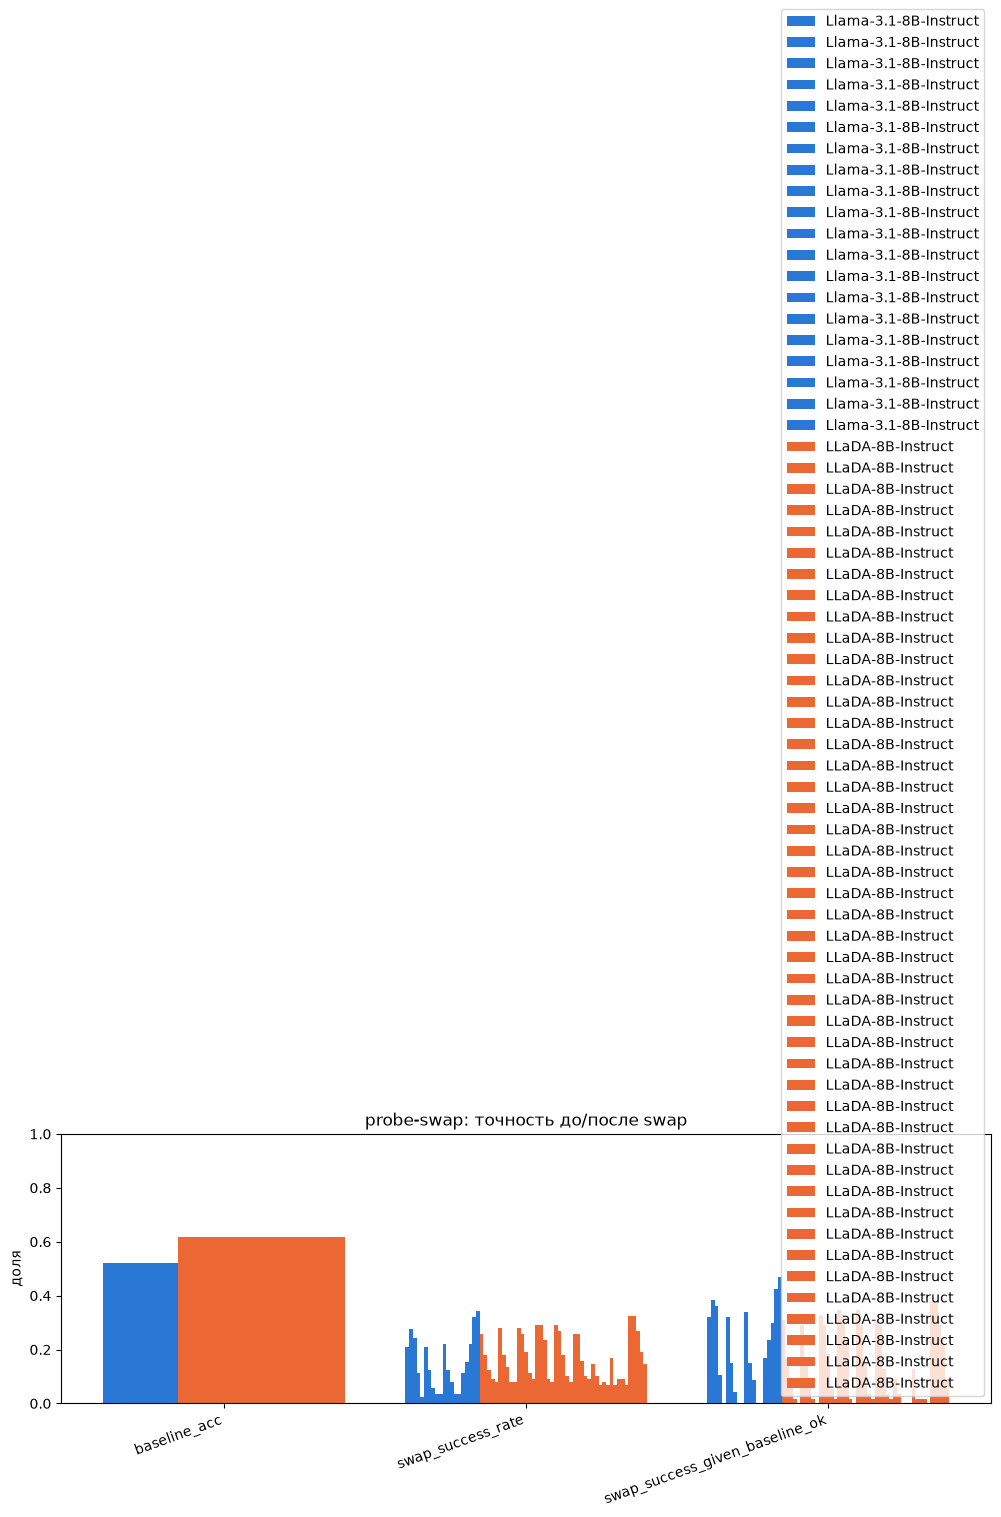

lens_variant                             0    1    2    3  logit-lens  merged  \
model                 category                                                  
LLaDA-8B-Instruct     animal-cover     0.0  0.0  0.0  0.0         0.0     0.0   
                      animal-legs      0.0  0.0  0.0  0.0         0.0     0.0   
                      animal-nose      0.0  1.0  1.0  1.0         0.0     1.0   
                      beverage-source  0.0  0.0  0.0  0.0         0.0     0.0   
                      bird-color       0.0  0.0  0.0  0.0         0.0     0.0   
...                                    ...  ...  ...  ...         ...     ...   
Llama-3.1-8B-Instruct river-capital    NaN  NaN  NaN  NaN         0.0     NaN   
                      season-next      NaN  NaN  NaN  NaN         0.0     NaN   
                      sport-equip      NaN  NaN  NaN  NaN         0.0     NaN   
                      tree-product     NaN  NaN  NaN  NaN         0.0     NaN   
                      vehicle-power    NaN  NaN  NaN  NaN         0.0     NaN   

lens_variant                           single  single_mask  transfer:merged  \
model                 category                                                
LLaDA-8B-Instruct     animal-cover        NaN          0.0              0.0   
                      animal-legs         NaN          0.0              0.0   
                      animal-nose         NaN          1.0              1.0   
                      beverage-source     NaN          0.0              0.0   
                      bird-color          NaN          0.0              0.0   
...                                       ...          ...              ...   
Llama-3.1-8B-Instruct river-capital       1.0          NaN              NaN   
                      season-next         0.0          NaN              NaN   
                      sport-equip         0.0          NaN              NaN   
                      tree-product        0.0          NaN              NaN   
                      vehicle-power       0.0          NaN              NaN   

lens_variant                           transfer:single  tuned-lens  
model                 category                                      
LLaDA-8B-Instruct     animal-cover                 NaN         0.0  
                      animal-legs                  NaN         0.0  
                      animal-nose                  NaN         0.0  
                      beverage-source              NaN         0.0  
                      bird-color                   NaN         0.0  
...                                                ...         ...  
Llama-3.1-8B-Instruct river-capital                0.0         0.0  
                      season-next                  0.0         0.0  
                      sport-equip                  0.0         0.0  
                      tree-product                 0.0         0.0  
                      vehicle-power                0.0         0.0  

[72 rows x 11 columns]

,model,variant,n_items,n_strict,n_partial,strict_baseline_acc,strict_swap_success_rate,strict_swap_success_given_baseline_ok,partial_baseline_acc,partial_swap_success_rate,baseline_acc_lenient,swap_success_rate_lenient,n_baseline_ok_lenient,swap_success_lenient_given_baseline_ok
1,Llama-3.1-8B-Instruct,single@alpha=1.0,90,68,22,0.559,0.324,0.447,0.409,0.136,0.611,0.356,55,0.400
6,Llama-3.1-8B-Instruct,logit-lens@alpha=1.0,90,68,22,0.559,0.118,0.158,0.409,0.136,0.611,0.200,55,0.182
11,Llama-3.1-8B-Instruct,tuned-lens@alpha=1.0,90,68,22,0.559,0.118,0.158,0.409,0.136,0.611,0.189,55,0.164
16,Llama-3.1-8B-Instruct,transfer:single@alpha=1.0,90,68,22,0.559,0.162,0.237,0.409,0.136,0.611,0.233,55,0.291
21,LLaDA-8B-Instruct,0@alpha=1.0,89,68,21,0.676,0.221,0.196,0.429,0.048,0.618,0.202,55,0.236
26,LLaDA-8B-Instruct,1@alpha=1.0,89,68,21,0.676,0.206,0.196,0.429,0.095,0.618,0.213,55,0.218
31,LLaDA-8B-Instruct,2@alpha=1.0,89,68,21,0.676,0.309,0.348,0.429,0.095,0.618,0.292,55,0.364
36,LLaDA-8B-Instruct,3@alpha=1.0,89,68,21,0.676,0.353,0.391,0.429,0.095,0.618,0.315,55,0.400
41,LLaDA-8B-Instruct,merged@alpha=1.0,89,68,21,0.676,0.324,0.348,0.429,0.095,0.618,0.292,55,0.345
46,LLaDA-8B-Instruct,single_mask@alpha=1.0,89,68,21,0.676,0.309,0.348,0.429,0.095,0.618,0.225,55,0.291


mean_swap_lp_delta           \
swap_mode                            lens_clamp transfer   
model                 lens                                 
LLaDA-8B-Instruct     merged              4.216    4.564   
Llama-3.1-8B-Instruct single              5.392    3.974   

                             swap_success_given_baseline_ok           \
swap_mode                                        lens_clamp transfer   
model                 lens                                             
LLaDA-8B-Instruct     merged                          0.291    0.382   
Llama-3.1-8B-Instruct single                          0.383    0.234   

                             swap_success_rate           \
swap_mode                           lens_clamp transfer   
model                 lens                                
LLaDA-8B-Instruct     merged             0.270    0.326   
Llama-3.1-8B-Instruct single             0.278    0.156   

                             swap_success_rate_lenient           \
swap_mode                                   lens_clamp transfer   
model                 lens                                        
LLaDA-8B-Instruct     merged                     0.292    0.427   
Llama-3.1-8B-Instruct single                     0.356    0.233   

                             swap_top5_given_baseline_ok           
swap_mode                                     lens_clamp transfer  
model                 lens                                         
LLaDA-8B-Instruct     merged                       0.727    0.782  
Llama-3.1-8B-Instruct single                       0.745    0.574

mean_swap_lp_delta           \
swap_mode                            lens_clamp transfer   
model                 lens                                 
LLaDA-8B-Instruct     merged              4.216    4.564   
Llama-3.1-8B-Instruct single              5.392    3.974   

                             swap_success_given_baseline_ok           \
swap_mode                                        lens_clamp transfer   
model                 lens                                             
LLaDA-8B-Instruct     merged                          0.291    0.382   
Llama-3.1-8B-Instruct single                          0.383    0.234   

                             swap_success_rate           \
swap_mode                           lens_clamp transfer   
model                 lens                                
LLaDA-8B-Instruct     merged             0.270    0.326   
Llama-3.1-8B-Instruct single             0.278    0.156   

                             swap_success_rate_lenient           \
swap_mode                                   lens_clamp transfer   
model                 lens                                        
LLaDA-8B-Instruct     merged                     0.292    0.427   
Llama-3.1-8B-Instruct single                     0.356    0.233   

                             swap_top5_given_baseline_ok           
swap_mode                                     lens_clamp transfer  
model                 lens                                         
LLaDA-8B-Instruct     merged                       0.727    0.782  
Llama-3.1-8B-Instruct single                       0.745    0.574

In [15]:
rows_probe_swap = []
token_dfs_probe_swap = []
for entry in MODELS:
    out_rows, token_df = run_probe_swap(entry)
    rows_probe_swap.extend(out_rows)
    token_dfs_probe_swap.append(token_df)
token_table_probe_swap = pd.concat(token_dfs_probe_swap, ignore_index=True)

record_and_show(rows_probe_swap)
plot_bars(rows_probe_swap, ["baseline_acc", "swap_success_rate", "swap_success_given_baseline_ok"],
          "probe-swap: точность до/после swap", figsize=(12, 3.5))

pd.set_option("display.max_colwidth", None)
token_table_probe_swap

token_table_probe_swap.to_csv("probe_swap_token_table.csv", index=False)
_t = token_table_probe_swap[token_table_probe_swap["alpha"] == 1.0].copy()
_t["baseline_ok_strict"] = _t["baseline_ok_strict"].astype(bool)
_cat = (_t.groupby(["model", "category", "lens_variant"])
          .agg(n=("name", "nunique"), baseline=("baseline_ok_strict", "mean"), swap=("swap_ok_strict", "mean"))
          .reset_index())
display(_cat.pivot(index=["model", "category"], columns="lens_variant", values="swap").round(2))

_ps = pd.DataFrame(rows_probe_swap)
_ps = _ps[_ps["variant"].astype(str).str.endswith("alpha=1.0")]
display(_ps[["model", "variant", "n_items", "n_strict", "n_partial", "strict_baseline_acc", "strict_swap_success_rate",
             "strict_swap_success_given_baseline_ok", "partial_baseline_acc", "partial_swap_success_rate",
             "baseline_acc_lenient", "swap_success_rate_lenient", "n_baseline_ok_lenient",
             "swap_success_lenient_given_baseline_ok"]].round(3))

show_swap_mode_ablation(rows_probe_swap, ["swap_success_rate", "swap_success_given_baseline_ok",
                                          "swap_top5_given_baseline_ok", "mean_swap_lp_delta",
                                          "swap_success_rate_lenient"])

## Эксперимент 2 -- verbal-report

**Идея (§3.1 статьи).** Модель просят подумать о предмете категории и назвать его одним словом.
Если J-пространство действительно определяет вербальный отчёт, то подмена линзовой координаты
«выбранный ответ» -> «другой кандидат» (на всех позициях и во всём band) должна заставить модель
назвать кандидата. Это и есть причинная проверка того, что сказанное вслух читается из той же
рабочей области, что видит линза.

**Протокол (README).** `candidates` -- 14 категорий по 14 слов. Промпт -- «Think of a {category}.
Answer in one word.», линза читается на финальном `:`. Жадный next-token -- «выбранный» ответ.
Для каждого из первых 10 кандидатов (кроме самого ответа) координата ответа обменивается на
координату кандидата. Оценка -- **ранг кандидата в выходном распределении** на той же позиции,
успех = ранг 1. В статье (Fig. 6) показан ранг до/после swap для кандидатов вне топ-10 выхода.

**Что считается.** `swap_success_rate` -- доля успехов (среднее по категориям);
`swap_success_rank_ge11` -- то же, но только для кандидатов, стартовавших с ранга >= 11 (как на
Fig. 6); `top5_rate`; медианные ранги до/после; `frac_top1_unchanged` -- доля случаев, где swap вообще
не изменил top-1; `spearman_lens_vs_output_L*` -- корреляция порядка 10 кандидатов в линзе и в
выходных логитах на трёх слоях (первая половина §3.1: растёт к концу band).

**Что изменено по итогам разбора.**

* **Clamp вместо повторного обмена** (`lens_clamp`, см. эксперимент 1): прежний `lens_swap`
  откатывал сам себя на чётном числе слоёв band. В старой таблице токенов это видно: у LLaDA
  top-1 не менялся ни для одного кандидата (все 10 кандидатов -> одно и то же слово), у Llama
  выход не зависел от кандидата (одно и то же «второе по вероятности» слово).
* **Per-layer направления** $J_\ell^{\top}W_U[v]$ вместо одного вектора со среднего слоя.
* **Метрика одним forward pass:** ранг кандидата на позиции чтения (README), а не первый токен
  многотокенной генерации. Для LLaDA генерация с $n$ масками меняла постановку: первая маска
  видела вторую, а раскрытие шло по уверенности -- поэтому `n_gen=2` «работало лучше» `n_gen=1`.
  Одна маска и ранг на ней -- ровно режим, в котором обучена `single_mask`-линза.
* **Промпт как на Fig. 6:** `Human: ... \n\nAssistant:`. Прежний `...word.:` (двоеточие сразу
  после точки) для Llama продолжался как `\nThink of a ...`. Старый вариант остался как
  `prompt_style="raw"`.
* **Дедупликация кандидатов** по первому токену (раньше два кандидата с общим первым токеном
  считались дважды, а кандидат, совпадающий с ответом по токену, давал ложный «успех»).
* **$\alpha=2$** добавлено (в статье удвоенная сила нужна там, где $\alpha=1$ сдвигает не до конца).
* `patch_read=True` (только LLaDA) -- диагностика: патчить ещё и саму `[MASK]`. У Llama аналог --
  финальный `:`, который патчится всегда; у LLaDA позиция, где формируется ответ -- `[MASK]`, а
  её по умолчанию не трогаем. Если с `patch_read=True` результат резко растёт, значит, проблема в
  том, что патч на контексте не доходит до маски.

**Обновление после проверки.** `patch_read=True` (по умолчанию) поднимает успех LLaDA, линза 3:
0.38 -> 0.51 при alpha=1, 0.71 -> 0.76 при alpha=2; у Llama без изменений -- там и так патчится `:`.
`swap_success_valid_answers` считается только по категориям, где исходный ответ -- слово категории (у
LLaDA `river` -> `Sere`, `tree` -> `Tower` -- мусор, успех там 0): линза 3, alpha=2 -- 0.87, больше, чем
у Llama (0.68). `word_dirs="all_tokens"` (сумма направлений всех токенов кандидата) не помогла и у
Llama ухудшила 0.67 -> 0.61, поэтому по умолчанию `first_token`.

**Baseline'ы.** Колонка `lens_variant` теперь включает `logit-lens` и `tuned-lens`: clamp-swap и readout считаются теми же функциями, направление токена строится из `J_l` соответствующей линзы.


In [16]:
VERBAL_PROMPTS = {
    "paper": "Human: Think of a {c}. Answer in one word.\n\nAssistant:",
    "raw":   "Think of a {c}. Answer in one word.:",
}

def _rank_of(logits, t):
    return int((logits > logits[t]).sum().item()) + 1

def _spearman(a, b):
    ra, rb = np.argsort(np.argsort(a)), np.argsort(np.argsort(b))
    return float(np.corrcoef(ra, rb)[0, 1])

def run_verbal_report(entry, limit=N_ITEMS_LIMIT, alphas=(1.0, 2.0), prompt_style="paper",
                      patch_read=True, n_gen=0, word_dirs="first_token"):
    """patch_read: LLaDA -- патчить ли и саму добавленную [MASK] (позицию чтения). По умолчанию ДА:
    проверка показала успех 0.38 -> 0.52 (alpha=1) и 0.71 -> 0.78 (alpha=2) для линзы 3 -- ответ
    формируется именно на маске. Для Llama параметр ничего не меняет: последняя позиция ':'
    патчится всегда, как и в статье. word_dirs="first_token" (по умолчанию): направление
    кандидата -- вектор его первого токена; "all_tokens" -- сумма по всем токенам слова (на проверке
    ухудшила результат: Llama 0.67 -> 0.61, LLaDA линза 3: 0.52 -> 0.51 при alpha=1). n_gen>0 добавляет мягкую генерацию (для таблицы токенов)."""
    model, tok, band = entry["model"], entry["tokenizer"], entry["band"]
    lenses = all_llada_lenses(entry)
    candidates = json.load(open(EXPERIMENTS_DIR / "verbal-report.json"))["candidates"]
    categories = list(candidates.keys())
    if limit:
        categories = categories[:limit]
    corr_layers = [band[len(band) // 2], band[(3 * len(band)) // 4], band[-1]]

    cand_rows, corr = [], {v: {l: [] for l in corr_layers} for v in lenses}
    word_dirs = _PerDev(word_dirs)
    def _pjob(_job):
        category = _job
        model, tok, band = entry["model"], entry["tokenizer"], entry["band"]
        prompt = VERBAL_PROMPTS[prompt_style].format(c=category)
        ids = text_ids(tok, prompt)
        base_acts, final_layer, read_pos = record_residuals_masked(entry, ids, band)
        base_logits = final_logits_at(model, base_acts, final_layer, read_pos).float()
        answer_id = base_logits.argmax().item()
        answer_tok = tok.decode([answer_id])

        cids, cwords, cdirs = [], [], []
        for w in candidates[category][:10]:
            cid = single_token_id(tok, " " + w) or first_token_id(tok, " " + w)
            if cid is None or cid == answer_id or cid in cids:
                continue
            cids.append(cid); cwords.append(w)
            cdirs.append((word_token_ids(tok, w) or [cid]) if word_dirs == "all_tokens" else cid)
        if not cids:
            return
        rank_before = [_rank_of(base_logits, c) for c in cids]
        _a = answer_tok.strip().lower()
        answer_valid = len(_a) >= 2 and any(w.lower().startswith(_a) or _a.startswith(w.lower())
                                            for w in candidates[category])

        positions = patchable_positions(entry, ids)
        if patch_read and entry.get("mask_id") is not None:
            positions = list(range(ids.shape[1] + 1))

        for variant, lens in lenses.items():
            out_l = base_logits[cids].cpu().numpy()
            for l in corr_layers:
                lg = model.unembed(lens.transport(base_acts[l][read_pos].unsqueeze(0), l))[0].float()
                corr[variant][l].append(_spearman(lg[cids].cpu().numpy(), out_l))

            D = token_directions_batch(model, lens, band, [answer_id] + cdirs)
            for j, cid in enumerate(cids):
                for alpha in alphas:
                    make = lambda clean, pos, j=j, alpha=alpha: [
                        {"layer": l, "positions": pos, "direction_s": D[l][0], "direction_t": D[l][1 + j],
                         "alpha": alpha, "mode": "lens_clamp", "clean_h": clean[l]} for l in band]
                    with ResidualPatcher(model.layers, make(base_acts, positions)):
                        acts, fl, rp = record_residuals_masked(entry, ids, band)
                    lg = final_logits_at(model, acts, fl, rp).float()
                    top1 = lg.argmax().item()
                    row = {"category": category, "variant": f"{variant}@alpha={alpha}", "lens_variant": variant,
                           "alpha": alpha, "answer": answer_tok.strip(), "candidate": cwords[j],
                           "rank_before": rank_before[j], "rank_after": _rank_of(lg, cid),
                           "answer_valid": answer_valid,
                           "swap_top1": tok.decode([top1]).strip(), "swap_ok": top1 == cid,
                           "unchanged": top1 == answer_id}
                    if n_gen:
                        row["swap_generated"] = tok.decode(_generate_tokens_clamped(entry, ids, band, n_gen, make, patch_read=patch_read))
                    cand_rows.append(row)
    pmap(_pjob, list(categories), desc=f"verbal-report [{entry['name']}]")

    token_df = pd.DataFrame(cand_rows)
    out_rows = []
    for variant_alpha in token_df["variant"].unique():
        sub = token_df[token_df["variant"] == variant_alpha]
        far = sub[sub["rank_before"] >= 11]
        lv = sub["lens_variant"].iloc[0]
        row = {
            "experiment": "verbal-report", "model": entry["name"], "variant": variant_alpha,
            "n_items": sub["category"].nunique(), "n_candidates": len(sub),
            "swap_success_rate": sub.groupby("category")["swap_ok"].mean().mean(),
            "swap_success_rank_ge11": far["swap_ok"].mean() if len(far) else None,
            "swap_success_valid_answers": sub[sub["answer_valid"]].groupby("category")["swap_ok"].mean().mean(),
            "n_valid_categories": int(sub[sub["answer_valid"]]["category"].nunique()),
            "top5_rate": (sub["rank_after"] <= 5).mean(),
            "median_rank_before": float(sub["rank_before"].median()),
            "median_rank_after": float(sub["rank_after"].median()),
            "frac_top1_unchanged": sub["unchanged"].mean(),
        }
        for l in corr_layers:
            row[f"spearman_lens_vs_output_L{l}"] = float(np.mean(corr[lv][l])) if corr[lv][l] else None
        out_rows.append(row)
    return out_rows, token_df

verbal-report [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 14/14 [01:17<00:00,  5.54s/it]


,experiment,model,variant,n_items,n_candidates,swap_success_rate,swap_success_rank_ge11,swap_success_valid_answers,n_valid_categories,top5_rate,median_rank_before,median_rank_after,frac_top1_unchanged,spearman_lens_vs_output_L18,spearman_lens_vs_output_L23,spearman_lens_vs_output_L27
0,verbal-report,Llama-3.1-8B-Instruct,single@alpha=1.0,14,127,0.654762,0.760000,0.666667,13,0.929134,8.0,1.0,0.165354,0.525649,0.550433,0.724567
1,verbal-report,Llama-3.1-8B-Instruct,single@alpha=2.0,14,127,0.755556,0.880000,0.752137,13,0.929134,8.0,1.0,0.094488,0.525649,0.550433,0.724567
2,verbal-report,Llama-3.1-8B-Instruct,logit-lens@alpha=1.0,14,127,0.341270,0.180000,0.367521,13,0.818898,8.0,3.0,0.251969,0.335714,0.530736,0.651623
3,verbal-report,Llama-3.1-8B-Instruct,logit-lens@alpha=2.0,14,127,0.686508,0.740000,0.700855,13,0.913386,8.0,1.0,0.133858,0.335714,0.530736,0.651623
4,verbal-report,Llama-3.1-8B-Instruct,tuned-lens@alpha=1.0,14,127,0.387302,0.260000,0.401709,13,0.842520,8.0,2.0,0.236220,0.299567,0.525000,0.647835
5,verbal-report,Llama-3.1-8B-Instruct,tuned-lens@alpha=2.0,14,127,0.723810,0.780000,0.717949,13,0.897638,8.0,1.0,0.165354,0.299567,0.525000,0.647835
6,verbal-report,LLaDA-8B-Instruct,0@alpha=1.0,14,128,0.412698,0.183333,0.481481,12,0.718750,10.0,2.0,0.203125,-0.076190,-0.066558,0.321753
7,verbal-report,LLaDA-8B-Instruct,0@alpha=2.0,14,128,0.650000,0.550000,0.750000,12,0.828125,10.0,1.0,0.101562,-0.076190,-0.066558,0.321753
8,verbal-report,LLaDA-8B-Instruct,1@alpha=1.0,14,128,0.444444,0.283333,0.518519,12,0.726562,10.0,2.0,0.195312,-0.008225,-0.023485,0.390260
9,verbal-report,LLaDA-8B-Instruct,1@alpha=2.0,14,128,0.665873,0.533333,0.768519,12,0.843750,10.0,1.0,0.085938,-0.008225,-0.023485,0.390260


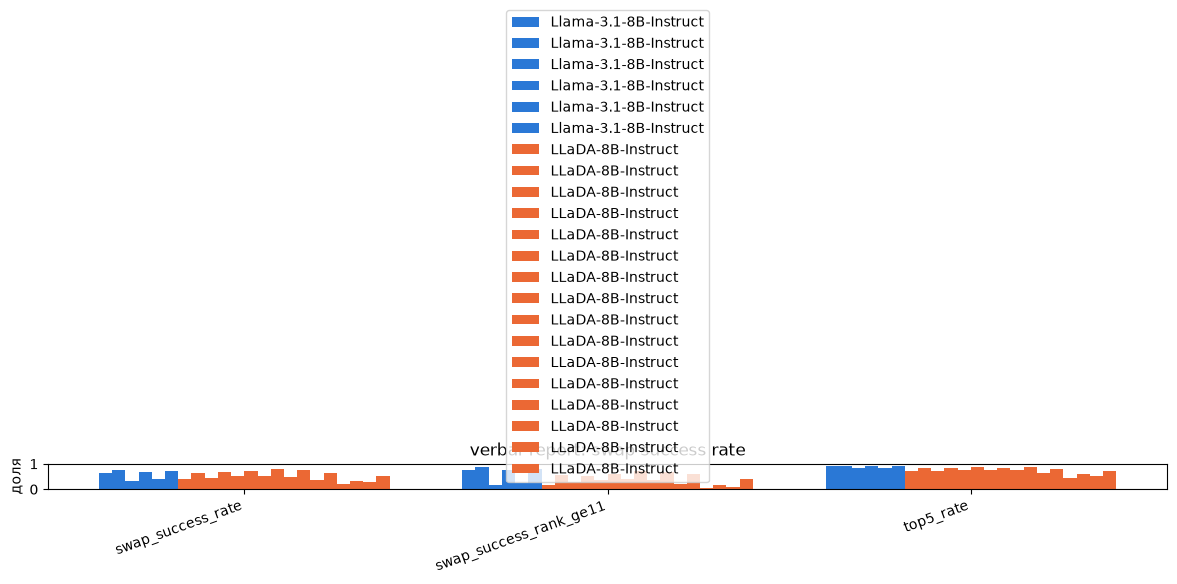

swap_ok по категориям, alpha=1.0


lens_variant,0,1,2,3,logit-lens,merged,single,single_mask,tuned-lens
category,,,,,,,,,
beverage,0.44,0.56,0.78,0.78,0.39,0.67,0.89,0.44,0.33
bird,0.33,0.11,0.22,0.22,0.44,0.22,0.44,0.22,0.50
city,0.22,0.33,0.44,0.56,0.22,0.56,0.56,0.22,0.28
color,0.78,0.89,0.89,0.89,0.50,0.89,0.78,0.89,0.50
country,0.89,0.89,0.89,0.89,0.11,0.89,0.67,0.78,0.33
fruit,0.67,0.67,0.67,0.67,0.61,0.67,0.56,0.00,0.83
instrument,0.44,0.67,0.78,0.78,0.06,0.78,0.78,0.33,0.06
language,0.33,0.33,0.44,0.44,0.11,0.44,0.89,0.33,0.17
organ,0.22,0.22,0.22,0.22,0.06,0.22,1.00,0.11,0.11


swap_ok по категориям, alpha=2.0


lens_variant,0,1,2,3,logit-lens,merged,single,single_mask,tuned-lens
category,,,,,,,,,
beverage,0.56,0.78,1.00,1.00,0.50,1.00,0.89,0.89,0.61
bird,0.67,0.56,0.78,1.00,0.56,0.89,0.67,0.78,0.72
city,0.78,0.89,1.00,1.00,0.56,1.00,0.78,0.78,0.67
color,1.00,1.00,1.00,1.00,0.72,1.00,0.78,1.00,0.89
country,1.00,1.00,0.78,1.00,0.61,1.00,0.78,1.00,0.56
fruit,1.00,1.00,1.00,1.00,0.94,1.00,0.67,0.44,1.00
instrument,0.78,0.89,0.89,0.89,0.28,0.89,0.89,0.78,0.17
language,0.67,0.67,0.67,0.78,0.44,0.67,1.00,0.56,0.61
organ,0.33,0.22,0.22,0.67,0.28,0.67,0.89,0.56,0.56


исходный ответ модели (top-1 на позиции чтения) по категориям -- проверка, что это слово категории


lens_variant,0,1,2,3,logit-lens,merged,single,single_mask,tuned-lens
category,,,,,,,,,
beverage,Coffee,Coffee,Coffee,Coffee,Coffee,Coffee,Coffee,Coffee,Coffee
bird,Eagle,Eagle,Eagle,Eagle,Spar,Eagle,Spar,Eagle,Spar
city,Paris,Paris,Paris,Paris,Paris,Paris,Paris,Paris,Paris
color,Blue,Blue,Blue,Blue,Blue,Blue,Blue,Blue,Blue
country,France,France,France,France,France,France,France,France,France
fruit,Apple,Apple,Apple,Apple,Apple,Apple,Apple,Apple,Apple
instrument,Piano,Piano,Piano,Piano,Guitar,Piano,Guitar,Piano,Guitar
language,French,French,French,French,English,French,English,French,English
organ,Heart,Heart,Heart,Heart,Liver,Heart,Liver,Heart,Liver


In [17]:
rows_verbal_report = []
token_dfs_verbal_report = []
for entry in MODELS:
    out_rows, token_df = run_verbal_report(entry)
    rows_verbal_report.extend(out_rows)
    token_dfs_verbal_report.append(token_df)
token_table_verbal_report = pd.concat(token_dfs_verbal_report, ignore_index=True)

record_and_show(rows_verbal_report)
plot_bars(rows_verbal_report, ["swap_success_rate", "swap_success_rank_ge11", "top5_rate"],
          "verbal-report: swap success rate", figsize=(12, 3.5))

pd.set_option("display.max_colwidth", None)

token_table_verbal_report.to_csv("verbal_report_token_table.csv", index=False)

_t = token_table_verbal_report
for a in (1.0, 2.0):
    print(f"swap_ok по категориям, alpha={a}")
    display(_t[_t["alpha"] == a].groupby(["category", "lens_variant"])["swap_ok"].mean()
            .unstack().round(2))
print("исходный ответ модели (top-1 на позиции чтения) по категориям -- проверка, что это слово категории")
display(_t.drop_duplicates(["category", "lens_variant"]).pivot(index="category", columns="lens_variant", values="answer"))

RUN_ABLATION_NO_PATCH_READ = False
if RUN_ABLATION_NO_PATCH_READ:
    _rows_np = []
    for entry in MODELS:
        if entry.get("mask_id") is None:
            continue
        r, _ = run_verbal_report(entry, patch_read=False, alphas=(1.0, 2.0))
        _rows_np.extend(r)
    display(pd.DataFrame(_rows_np)[["variant", "swap_success_rate", "swap_success_rank_ge11", "top5_rate",
                                    "median_rank_before", "median_rank_after", "frac_top1_unchanged"]].round(3))

## Эксперимент 3 -- verbal-introspection

**Идея (§3.2 статьи).** Модели говорят, что в её активации могла быть «внедрена мысль» (слово), и
просят опознать, была ли она и о чём. Ответ teacher-forced префиллом, заканчивающимся открывающей
кавычкой (`... The thought is about the word "`), так что следующий токен и есть то, что модель
«обнаружила». Если вектор J-линзы концепта добавить на токены пользовательской реплики, модель
должна назвать именно этот концепт -- но только в момент, когда её просят отчитаться, а не в любом
месте ответа (в статье это проверяется отдельным контролем по позициям).

**Протокол (README).** Для каждого из ~100 `concepts[*].surface` берётся единичный вектор
транспонированной строки (`J_l^T W_U[token]`), масштабируется на среднюю норму резидуала слоя
$	imes$ `strength` и **добавляется** на каждом слое band на каждом токене пользовательской реплики с
вопросом; `strength=0` -- контроль. Оценка -- ранг токена `surface` в распределении следующего токена
в конце префилла. По оси -- медианный reciprocal rank vs `strength` (Fig. 7 статьи, n=100).

**Что исправлено по итогам разбора.**

* **Промпт целиком.** Раньше использовалась только первая реплика (`intro_prompt[0]`), без
  «Understood.» и без вопроса «Trial 1: Do you detect an injected thought?». Теперь собирается весь
  диалог из JSON (`user / assistant / user`), а инъекция идёт на токены **последней** user-реплики --
  «user's question turn» из README. Промпт больше не пересчитывается для каждого концепта.
* **Цель -- токен без пробела.** После открывающей кавычки слово идёт без ведущего пробела (в статье
  на Fig. 7: `elephant`, `umbre`, `g`). Раньше сначала искался `" " + surface`, то есть токен,
  которого модель в этой позиции не выдаёт; контрольный ранг при `strength=0` был некорректным.
* **Per-layer направление и масштаб.** Раньше на все слои band применялись направление и норма
  среднего слоя. Теперь на каждом слое свои $J_l^{\top}W_U[v]$ и своя норма (README: «the layer's
  mean residual norm»). Норма считается без массивных активаций первого токена.
* **Контроли.** (a) `control:logit_dir` -- направление unembedding `W_U[v]` (логит-линза вместо
  J-линзы) той же нормы; (b) `control:random` -- случайное направление; (c) `off_rr` -- ранг «чужого»
  концепта: инъекция слова A не должна поднимать слово B. Без них $rr=1$ при большой силе тавтологичен:
  вектор $J^{\top}W_U[v]$ по построению максимально повышает логит $v$.
* **Метрики.** Помимо медианного 1/rank (насыщается к 1.0) добавлены средний 1/rank, доля top-1 и
  скаляры «минимальная сила, при которой медиана >= 0.5 / top-1 >= 0.5» для сравнения линз.
* **Сетка силы** расширена вниз (LLaDA насыщалась уже к 0.1) и вверх (до 1.0; масштаб теперь
  меньше, поэтому Llama нужна большая номинальная сила).

**LLaDA-специфика.** Читается одна добавленная `[MASK]` после кавычки (маска на позиции $n$
предсказывает токен $n$); инъекция идёт только на токены пользовательской реплики, позицию
чтения (маску) не патчим, как и в статье.

**Результаты первого прогона после исправлений.** Прежний вывод «LLaDA насыщается при 0.1, Llama при
0.35» был артефактом: цель была токеном с пробелом (который модель после кавычки не выдаёт), а
направление поднимало именно его логит. С корректной целью LLaDA (линза 3) достигает top-1 72% и
медианного 1/rank = 1.0 при силе 0.15--0.2, а Llama при 1.0 всё ещё растёт (top-1 24%), поэтому сетка
продолжена до 4.0. Логит-направление `W_U[v]` заметно слабее J-вектора (Llama 13% против 24%).


**Формат промпта.** Переменная `PROMPT_FORMAT` в ячейке конфигурации: `"chat"` -- chat-шаблон токенизатора, `"plain"` -- простой текст `Human: ...\n\nAssistant: ...` без спецтокенов (линза обучалась на претрейн-подобном тексте). Прогоните оба варианта и сравните CSV с суффиксами `_chat` / `_plain`.

**Baseline'ы.** К линзам добавлены `logit-lens` и `tuned-lens` (в `variant`). Контроль `control:logit_dir` -- это другая вещь: прямое направление `W_U[v]` в обычной J-схеме, а `logit-lens` -- полноценная линза-baseline со своим readout.


In [18]:
VI_STRENGTHS = (0.0, 0.05, 0.075, 0.1, 0.15, 0.2, 0.25, 0.35, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0)

def chat_ids_multi(tok, messages, assistant_prefill):
    """Многоходовой chat-промпт с teacher-forced ответом ассистента (continue_final_message).
    Возвращает (ids, (start, end)) -- токены последней user-реплики (то, что инжектируется)."""
    if PROMPT_FORMAT == "plain":
        turns = [("Human" if m["role"] == "user" else "Assistant") + ": " + m["content"].strip() for m in messages]
        text = "\n\n".join(turns) + "\n\nAssistant:" + (assistant_prefill if assistant_prefill.startswith(" ")
                                                        else " " + assistant_prefill)
    else:
        msgs = list(messages) + [{"role": "assistant", "content": assistant_prefill}]
        text = tok.apply_chat_template(msgs, tokenize=False, continue_final_message=True)
    ids = tok(text, return_tensors="pt").input_ids.to(device)
    last_user = [m for m in messages if m["role"] == "user"][-1]["content"]
    s = text.rfind(last_user.strip())
    if s < 0:
        s = text.rfind(last_user)
        e = s + len(last_user) if s >= 0 else -1
    else:
        e = s + len(last_user.strip())
    if s < 0:
        raise ValueError("не нашёл последнюю user-реплику в тексте шаблона")
    return ids, (len(tok(text[:s]).input_ids), len(tok(text[:e]).input_ids))

def run_verbal_introspection(entry, limit=N_ITEMS_LIMIT, strengths=VI_STRENGTHS, controls=True, seed=0):
    model, tok, band = entry["model"], entry["tokenizer"], entry["band"]
    lenses = all_llada_lenses(entry)
    data = json.load(open(EXPERIMENTS_DIR / "verbal-introspection.json"))
    messages = list(data["intro_prompt"])
    if messages and messages[-1]["role"] == "assistant" and not messages[-1]["content"].strip():
        messages = messages[:-1]
    prefill = data["prefills"]["word"]
    concepts = data["concepts"][:limit] if limit else data["concepts"]

    ids, span = chat_ids_multi(tok, messages, prefill)
    positions = list(range(*span))
    print(f"[verbal-introspection {entry['name']}, формат={PROMPT_FORMAT}] токенов в промпте: {ids.shape[1]}, "
          f"инъекция на токенах {span[0]}..{span[1] - 1} ({len(positions)}): "
          f"{tok.decode(ids[0, span[0]:span[1]].tolist())[:70]!r}...")

    acts0, final_layer0, read_pos0 = record_residuals_masked(entry, ids, band)
    logits0 = final_logits_at(model, acts0, final_layer0, read_pos0).float()
    L = ids.shape[1]
    norms = {}
    for l in band:
        n_l = acts0[l][:L].norm(dim=-1)
        norms[l] = n_l[n_l <= 5 * n_l.median()].mean().item()

    targets, single = [], []
    for c in concepts:
        t = tok(c["surface"], add_special_tokens=False)["input_ids"]
        targets.append(t[0]); single.append(len(t) == 1)
    N = len(targets)
    rank_of = lambda lg, t: int((lg > lg[t]).sum().item()) + 1
    rank0 = [rank_of(logits0, t) for t in targets]

    dirs = {v: token_directions_batch(model, lens, band, targets) for v, lens in lenses.items()}
    W_U = model._lm_head.weight
    Dlogit = W_U[torch.tensor(targets, device=W_U.device)].float().to(device)
    Dlogit = Dlogit / Dlogit.norm(dim=1, keepdim=True)
    g = torch.Generator(device="cpu").manual_seed(seed)
    Drand = torch.randn(N, Dlogit.shape[1], generator=g).to(device)
    Drand = Drand / Drand.norm(dim=1, keepdim=True)

    def run_patch(dir_for_layer, s):
        patches = [{"layer": l, "positions": positions, "direction": dir_for_layer(l),
                    "alpha": norms[l] * s, "mode": "add"} for l in band]
        _m = entry["model"]
        with ResidualPatcher(_m.layers, patches):
            acts, fl, rp = record_residuals_masked(entry, ids, band)
        return final_logits_at(_m, acts, fl, rp).float()

    variants = list(lenses) + (["control:logit_dir", "control:random"] if controls else [])
    rows = []
    dirs = _PerDev(dirs)
    def _pjob(_job):
        i = _job
        model, tok, band = entry["model"], entry["tokenizer"], entry["band"]
        off = targets[(i - 1) % N]
        for s in strengths:
            for v in variants:
                if s == 0.0:
                    lg = logits0
                elif v == "control:logit_dir":
                    lg = run_patch(lambda l: Dlogit[i], s)
                elif v == "control:random":
                    lg = run_patch(lambda l: Drand[i], s)
                else:
                    lg = run_patch(lambda l, v=v: dirs[v][l][i], s)
                r = rank_of(lg, targets[i])
                rows.append({"variant": str(v), "concept": concepts[i]["name"], "single_token": single[i],
                             "strength": s, "rank": r, "rr": 1.0 / r, "off_rr": 1.0 / rank_of(lg, off)})
    pmap(_pjob, list(range(N)), desc=f"verbal-introspection [{entry['name']}]")
    df = pd.DataFrame(rows)
    df["format"] = PROMPT_FORMAT

    out_rows = []
    for v in df["variant"].unique():
        sub = df[df["variant"] == v]
        out = {"experiment": "verbal-introspection", "model": entry["name"], "variant": v, "format": PROMPT_FORMAT,
               "n_items": sub["concept"].nunique(), "n_single_token": int(sum(single))}
        med, top1 = {}, {}
        for s in strengths:
            ss = sub[sub["strength"] == s]
            out[f"median_rr@strength={s}"] = ss["rr"].median()
            out[f"mean_rr@strength={s}"] = ss["rr"].mean()
            out[f"top1@strength={s}"] = (ss["rank"] == 1).mean()
            med[s], top1[s] = ss["rr"].median(), (ss["rank"] == 1).mean()
        out["strength_median_rr>=0.5"] = next((s for s in strengths if med[s] >= 0.5), None)
        out["strength_top1>=0.5"] = next((s for s in strengths if top1[s] >= 0.5), None)
        out_rows.append(out)
    return out_rows, df

[verbal-introspection Llama-3.1-8B-Instruct, формат=plain] токенов в промпте: 126, инъекция на токенах 90..108 (19): ' 1: Do you detect an injected thought? If so, what is the thought abou'...


verbal-introspection [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 101/101 [04:26<00:00,  2.64s/it]


[verbal-introspection LLaDA-8B-Instruct, формат=plain] токенов в промпте: 134, инъекция на токенах 96..114 (19): ' 1: Do you detect an injected thought? If so, what is the thought abou'...


verbal-introspection [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 101/101 [06:28<00:00,  3.85s/it]


,experiment,model,variant,format,n_items,n_single_token,median_rr@strength=0.0,mean_rr@strength=0.0,top1@strength=0.0,median_rr@strength=0.05,...,mean_rr@strength=2.0,top1@strength=2.0,median_rr@strength=3.0,mean_rr@strength=3.0,top1@strength=3.0,median_rr@strength=4.0,mean_rr@strength=4.0,top1@strength=4.0,strength_median_rr>=0.5,strength_top1>=0.5
0,verbal-introspection,Llama-3.1-8B-Instruct,single,plain,101,74,0.001119,0.009512,0.0,0.001109,...,0.593161,0.524752,1.000000,0.649474,0.603960,1.000000,0.670517,0.623762,1.50,1.50
1,verbal-introspection,Llama-3.1-8B-Instruct,logit-lens,plain,101,74,0.001119,0.009512,0.0,0.000921,...,0.435640,0.366337,0.333333,0.479495,0.415842,0.333333,0.498496,0.445545,NaN,NaN
2,verbal-introspection,Llama-3.1-8B-Instruct,tuned-lens,plain,101,74,0.001119,0.009512,0.0,0.000884,...,0.510243,0.475248,0.500000,0.516001,0.465347,0.500000,0.515485,0.455446,3.00,NaN
3,verbal-introspection,Llama-3.1-8B-Instruct,control:logit_dir,plain,101,74,0.001119,0.009512,0.0,0.000921,...,0.435640,0.366337,0.333333,0.479495,0.415842,0.333333,0.498496,0.445545,NaN,NaN
4,verbal-introspection,Llama-3.1-8B-Instruct,control:random,plain,101,74,0.001119,0.009512,0.0,0.001159,...,0.004124,0.000000,0.000562,0.003770,0.000000,0.000497,0.003581,0.000000,NaN,NaN
5,verbal-introspection,LLaDA-8B-Instruct,0,plain,101,69,0.000324,0.005289,0.0,0.001089,...,0.498505,0.405941,0.500000,0.560033,0.475248,1.000000,0.587426,0.514851,3.00,4.00
6,verbal-introspection,LLaDA-8B-Instruct,1,plain,101,69,0.000324,0.005289,0.0,0.001115,...,0.677998,0.584158,1.000000,0.697097,0.584158,1.000000,0.703354,0.584158,1.00,2.00
7,verbal-introspection,LLaDA-8B-Instruct,2,plain,101,69,0.000324,0.005289,0.0,0.001059,...,0.722230,0.633663,1.000000,0.739908,0.653465,1.000000,0.746994,0.663366,0.75,0.75
8,verbal-introspection,LLaDA-8B-Instruct,3,plain,101,69,0.000324,0.005289,0.0,0.001976,...,0.828030,0.762376,1.000000,0.839151,0.772277,1.000000,0.849518,0.801980,0.15,0.20
9,verbal-introspection,LLaDA-8B-Instruct,merged,plain,101,69,0.000324,0.005289,0.0,0.001333,...,0.760526,0.683168,1.000000,0.766107,0.702970,1.000000,0.767146,0.702970,0.75,1.00


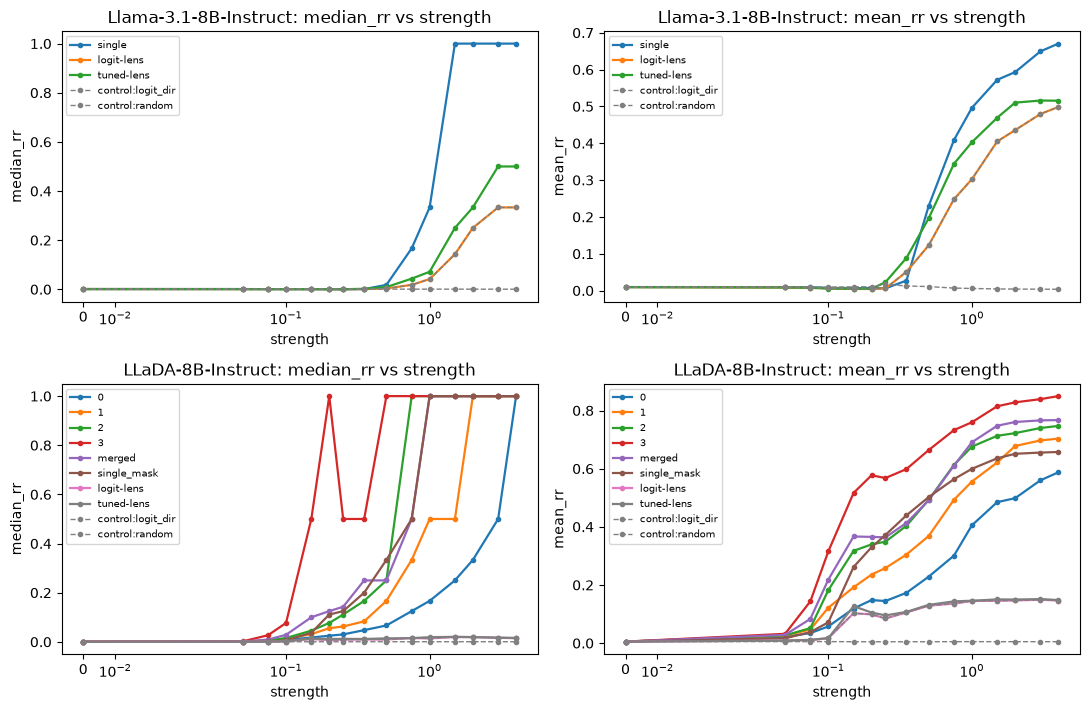

strength                                  0.00   0.10   0.35   1.00
model                 variant                                      
LLaDA-8B-Instruct     0                  0.000  0.000  0.000  0.000
                      1                  0.000  0.000  0.000  0.001
                      2                  0.000  0.000  0.000  0.000
                      3                  0.000  0.000  0.001  0.000
                      control:logit_dir  0.000  0.000  0.000  0.000
                      control:random     0.000  0.000  0.000  0.000
                      logit-lens         0.000  0.000  0.000  0.000
                      merged             0.000  0.000  0.001  0.000
                      single_mask        0.000  0.000  0.000  0.000
                      tuned-lens         0.000  0.000  0.000  0.000
Llama-3.1-8B-Instruct control:logit_dir  0.001  0.001  0.001  0.000
                      control:random     0.001  0.001  0.001  0.001
                      logit-lens         0.001  0.001  0.001  0.000
                      single             0.001  0.001  0.001  0.001
                      tuned-lens         0.001  0.001  0.001  0.000

strength                           0.000  0.050  0.075  0.100  0.150  0.200  \
model                 variant                                                 
LLaDA-8B-Instruct     0              0.0   0.72   0.87   0.83   0.56   0.59   
                      1              0.0   0.72   0.80   0.82   0.68   0.71   
                      2              0.0   0.76   0.80   0.82   0.70   0.74   
                      3              0.0   0.96   0.92   0.92   0.81   0.81   
                      logit-lens     0.0   0.00   0.00   0.00   0.00   0.00   
                      merged         0.0   0.82   0.83   0.85   0.73   0.79   
                      single_mask    0.0   0.80   0.78   0.81   0.62   0.73   
                      tuned-lens     0.0   0.65   0.70   0.78   0.74   0.63   
Llama-3.1-8B-Instruct logit-lens     0.0   0.00   0.00   0.00   0.00   0.00   
                      single         0.0   0.57   0.48   0.45   0.48   0.51   
                      tuned-lens     0.0   0.26   0.30   0.28   0.37   0.40   

strength                           0.250  0.350  0.500  0.750  1.000  1.500  \
model                 variant                                                 
LLaDA-8B-Instruct     0             0.65   0.70   0.76   0.79   0.85   0.88   
                      1             0.82   0.78   0.79   0.83   0.83   0.88   
                      2             0.82   0.84   0.83   0.83   0.83   0.84   
                      3             0.90   0.88   0.88   0.87   0.86   0.88   
                      logit-lens    0.00   0.00   0.00   0.00   0.00   0.00   
                      merged        0.82   0.84   0.82   0.83   0.88   0.84   
                      single_mask   0.78   0.80   0.82   0.83   0.84   0.83   
                      tuned-lens    0.65   0.68   0.68   0.71   0.65   0.59   
Llama-3.1-8B-Instruct logit-lens    0.00   0.00   0.00   0.00   0.00   0.00   
                      single        0.50   0.48   0.61   0.67   0.66   0.61   
                      tuned-lens    0.58   0.74   0.69   0.49   0.47   0.37   

strength                           2.000  3.000  4.000  
model                 variant                           
LLaDA-8B-Instruct     0             0.88   0.87   0.87  
                      1             0.87   0.87   0.88  
                      2             0.84   0.83   0.84  
                      3             0.88   0.86   0.88  
                      logit-lens    0.00   0.00   0.00  
                      merged        0.83   0.83   0.84  
                      single_mask   0.84   0.85   0.85  
                      tuned-lens    0.64   0.55   0.52  
Llama-3.1-8B-Instruct logit-lens    0.00   0.00   0.00  
                      single        0.57   0.52   0.50  
                      tuned-lens    0.37   0.32   0.30

strength                                 0.000  0.050  0.075  0.100  0.150  \
model                 variant                                                
LLaDA-8B-Instruct     0                    0.0   0.01   0.03   0.03   0.10   
                      1                    0.0   0.03   0.04   0.12   0.19   
                      2                    0.0   0.03   0.04   0.19   0.32   
                      3                    0.0   0.01   0.10   0.29   0.51   
                      control:logit_dir    0.0   0.00   0.00   0.00   0.06   
                      control:random       0.0   0.00   0.00   0.00   0.00   
                      logit-lens           0.0   0.00   0.00   0.00   0.06   
                      merged               0.0   0.03   0.07   0.23   0.35   
                      single_mask          0.0   0.00   0.03   0.04   0.25   
                      tuned-lens           0.0   0.00   0.00   0.00   0.09   
Llama-3.1-8B-Instruct control:logit_dir    0.0   0.00   0.00   0.00   0.00   
                      control:random       0.0   0.00   0.00   0.00   0.00   
                      logit-lens           0.0   0.00   0.00   0.00   0.00   
                      single               0.0   0.00   0.00   0.00   0.00   
                      tuned-lens           0.0   0.00   0.00   0.00   0.00   

strength                                 0.200  0.250  0.350  0.500  0.750  \
model                 variant                                                
LLaDA-8B-Instruct     0                   0.12   0.12   0.16   0.19   0.22   
                      1                   0.20   0.23   0.29   0.33   0.45   
                      2                   0.35   0.35   0.41   0.48   0.64   
                      3                   0.55   0.49   0.57   0.71   0.78   
                      control:logit_dir   0.07   0.06   0.07   0.10   0.12   
                      control:random      0.00   0.00   0.00   0.00   0.00   
                      logit-lens          0.07   0.06   0.07   0.10   0.12   
                      merged              0.35   0.33   0.36   0.46   0.55   
                      single_mask         0.30   0.30   0.38   0.43   0.49   
                      tuned-lens          0.07   0.07   0.07   0.10   0.12   
Llama-3.1-8B-Instruct control:logit_dir   0.00   0.00   0.05   0.12   0.26   
                      control:random      0.00   0.01   0.00   0.00   0.00   
                      logit-lens          0.00   0.00   0.05   0.12   0.26   
                      single              0.00   0.00   0.01   0.26   0.42   
                      tuned-lens          0.00   0.01   0.09   0.22   0.38   

strength                                 1.000  1.500  2.000  3.000  4.000  
model                 variant                                               
LLaDA-8B-Instruct     0                   0.30   0.36   0.36   0.41   0.45  
                      1                   0.49   0.54   0.67   0.67   0.67  
                      2                   0.68   0.75   0.75   0.75   0.77  
                      3                   0.80   0.83   0.86   0.87   0.86  
                      control:logit_dir   0.13   0.13   0.13   0.13   0.13  
                      control:random      0.00   0.00   0.00   0.00   0.00  
                      logit-lens          0.13   0.13   0.13   0.13   0.13  
                      merged              0.70   0.78   0.78   0.80   0.80  
                      single_mask         0.52   0.57   0.59   0.61   0.59  
                      tuned-lens          0.12   0.13   0.13   0.13   0.13  
Llama-3.1-8B-Instruct control:logit_dir   0.31   0.41   0.43   0.50   0.54  
                      control:random      0.00   0.00   0.00   0.00   0.00  
                      logit-lens          0.31   0.41   0.43   0.50   0.54  
                      single              0.53   0.64   0.66   0.76   0.78  
                      tuned-lens          0.45   0.53   0.58   0.57   0.55

In [19]:
rows_verbal_introspection, dfs_vi = [], []
for entry in MODELS:
    r, d = run_verbal_introspection(entry, strengths=VI_STRENGTHS)
    rows_verbal_introspection.extend(r)
    d["model"] = entry["name"]
    dfs_vi.append(d)
df_vi = pd.concat(dfs_vi, ignore_index=True)
df_vi.to_csv(f"verbal_introspection_concepts_{PROMPT_FORMAT}.csv", index=False)
record_and_show(rows_verbal_introspection)

fig, axes = plt.subplots(len(MODELS), 2, figsize=(11, 3.6 * len(MODELS)), squeeze=False)
for mi, entry in enumerate(MODELS):
    for ci, key in enumerate(("median_rr", "mean_rr")):
        ax = axes[mi][ci]
        for row in [r for r in rows_verbal_introspection if r["model"] == entry["name"]]:
            ctrl = row["variant"].startswith("control:")
            ax.plot(VI_STRENGTHS, [row[f"{key}@strength={s}"] for s in VI_STRENGTHS],
                    marker="o", ms=3, ls="--" if ctrl else "-", lw=1 if ctrl else 1.6,
                    color="gray" if ctrl else None, label=row["variant"])
        ax.set_xscale("symlog", linthresh=0.05); ax.set_title(f"{entry['name']}: {key} vs strength")
        ax.set_xlabel("strength"); ax.set_ylabel(key)
        ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

_big = df_vi[df_vi["strength"].isin([0.0, 0.1, 0.35, 1.0])]
display(_big.groupby(["model", "variant", "strength"])["off_rr"].median().unstack().round(3))

_w = []
for m, g in df_vi.groupby("model"):
    pv = g.pivot_table(index=["concept", "strength"], columns="variant", values="rank")
    for v in [c for c in pv.columns if not str(c).startswith("control:")]:
        for s_, h in pv.groupby(level="strength"):
            _w.append({"model": m, "variant": v, "strength": s_, "win_vs_logit": (h[v] < h["control:logit_dir"]).mean()})
display(pd.DataFrame(_w).pivot_table(index=["model", "variant"], columns="strength", values="win_vs_logit").round(2))

display(df_vi[df_vi["single_token"]].groupby(["model", "variant", "strength"])["rank"]
        .apply(lambda r: (r == 1).mean()).unstack().round(2))

## Эксперимент 4 -- directed-modulation

**Идея (статья §3.2, Fig. 9-10, §A.10).** Модель получает инструкцию про понятие X ("думай о X, пока пишешь",
"X для задачи не важен") и teacher-forced пишет несвязанное предложение-carrier. Патчей нет -- чистый readout:
мы смотрим, появляется ли X в J-lens на позициях carrier'а, хотя в тексте его нет.

**Что именно считается.** Trial положителен, если цель достигает **lens top-1 в каком-либо (слое band, позиции спана)**
(определение из подписи к Fig. 10 и README). Для math цель -- токен ответа; для topic -- **все `members`** категории
(`hit1_any` -- хоть один member, `hit1_frac` -- доля members). Кандидатные токены цели: первый токен слова с пробелом
и без, плюс капитализированные формы; токены, уже стоящие в carrier или в записи X в инструкции, исключаются
(иначе попадание могло бы быть простым копированием). Мягкая метрика rank<=k (`hitk_*`, k=25) и медианный лучший ранг
(`median_best_rank_*`) -- вторичные: они показывают сдвиг даже тогда, когда до top-1 не доходит.

**Дизайн (изменён).** Раньше: 60 случайных проб, ~15 на группу, а все topic-цели отбрасывались (имя категории вроде
"citrus fruits" -- не один токен, а README требует отслеживать `members`). Теперь -- факториальный дизайн: для каждой
пары (цель, carrier) прогоняются **все 24 формулировки** и условие **baseline** (тот же промпт без инструкции и без
упоминания цели). Режим задаётся переменной `DEBUG_MODE` (ячейка конфигурации): `True` -- 8 math + 8 topic целей x 1 carrier x 25 условий = 400 trial'ов на модель (LLaDA ~40 мин); `False` -- все цели (24 math + 22 topic) x 2 carrier'а x 25 условий = 2300 trial'ов.
Группы выводятся и в схлопнутом виде (`focus/control/suppress`, как в README), и по сырым группам
(`focus / mention / dismissal / negated-think`) -- статья показывает, что `dismissal` ("ignore") и `negated-think`
("don't think about") ведут себя по-разному, и схлопывание их скрывает.

**Ожидания по статье.**
1. `baseline` ~ 0 (контекст сам по себе цель в линзу не выводит);
2. `focus` заметно выше baseline и растёт с размером модели;
3. `mention` (просто назвать цель) почти не уступает `focus` -- это прайминг, а не "намерением";
4. `dismissal` ("ignore") существенно ниже `mention`, но > baseline;
5. `negated-think` ("don't think") ~ `mention` -- эффект "белого медведя".
Содержательная проверка "произвольного контроля" -- именно разности focus-mention и mention-dismissal, а не
сам focus; бутстрэп-интервалы разностей печатаются в конце ячейки.

**LLaDA-специфика.** Линзы обучены читать позицию `[MASK]`, поэтому используется `probe_mask`: по одной позиции спана
маскируется (остальной текст виден), и там читаются все 6 линз; `probe_step=2` читает каждую вторую позицию
(быстрее; для финального прогона можно поставить 1). У Llama позиция p предсказывает токен p+1, как в статье.
Результат для LLaDA -- по строке на каждую линзу (`variant`), для Llama -- одна (`single`).

**Файлы для проверки:** `directed_modulation_trials.csv` (по строке на trial x линзу) и HTML-экспорт ноутбука.

**Формат промпта.** Переменная `PROMPT_FORMAT` в ячейке конфигурации: `"chat"` -- chat-шаблон токенизатора, `"plain"` -- простой текст `Human: ...\n\nAssistant: ...` без спецтокенов (линза обучалась на претрейн-подобном тексте). Прогоните оба варианта и сравните CSV с суффиксами `_chat` / `_plain`.

**Baseline'ы.** Строки `variant = logit-lens / tuned-lens` -- baseline-линзы на тех же пробах (readout и направления из их `J_l`).


In [20]:
def _dm_candidate_ids(tok, text):
    """Токены, в которых цель может появиться на выходе линзы: первый токен text, " "+text и (для слов)
    капитализированные варианты. Чисто пробельные токены выбрасываем (у Llama-3 " 8" -> " " + "8")."""
    forms = [text, " " + text]
    if text.isalpha():
        forms += [text.capitalize(), " " + text.capitalize()]
    ids = []
    for f in forms:
        t = tok(f, add_special_tokens=False)["input_ids"]
        if not t:
            continue
        if not tok.decode([t[0]]).strip():
            continue
        if t[0] not in ids:
            ids.append(t[0])
    return ids

@follow_gpu
def _dm_span_ranks(entry, prompt_ids, target_ids, band, cand_ids, step=1):
    """{variant: {token_id: min rank по band x позициям спана}}. Llama -- реальные позиции;
    LLaDA -- probe_mask (по одной маскированной пробной позиции, как в остальных span-экспериментах)."""
    model = entry["model"]
    full_ids = torch.cat([prompt_ids, target_ids], dim=1)
    positions = list(range(prompt_ids.shape[1], full_ids.shape[1]))
    if entry.get("mask_id") is None:
        acts, _ = record_residuals(model, full_ids, band)
        return {name: ranks_over_band(model, ln, acts, band, positions, list(cand_ids))
                for name, ln in all_llada_lenses(entry).items()}
    return _probe_mask_ranks(entry, full_ids, positions, band, list(cand_ids), step=step)

def _dm_prompt(tok, user_text, carrier):
    """(prompt_ids, target_ids): промпт и teacher-forced ответ ассистента (= carrier) в формате PROMPT_FORMAT."""
    if PROMPT_FORMAT == "plain":
        prefix = "Human: " + user_text + "\n\nAssistant:"
        ids = text_ids(tok, prefix + " " + carrier)
        pl = common_prefix_len(tok, ids, prefix)
    else:
        ids = chat_ids(tok, user_text, assistant_prefill=carrier)
        pl = common_chat_prefix_len(tok, ids, user_text)
    return ids[:, :pl], ids[:, pl:]

def run_directed_modulation(entry, limit=N_ITEMS_LIMIT, k=25, n_math=12, n_topic=12, n_carriers=2,
                            probe_step=2, seed=0, include_baseline=True):
    """Directed modulation (paper §3.2, Fig. 10, §A.10).

    Дизайн: ФАКТОРИАЛЬНЫЙ, а не 60 случайных проб. Для каждой пары (цель, carrier) прогоняются ВСЕ 24
    формулировок + условие baseline (тот же промпт без инструкции и без упоминания цели). Так
    разница между группами не смешана с выбором цели/carrier'а.
    Цели: math -- answer (tier-стратифицированно), topic -- ВСЕ members категории (README).
    Метрика (как в статье): trial positive, если цель достигает lens top-1 (rank==1) в каком-либо
    (слой band, позиция спана). hit1_any -- хоть один member; hit1_frac -- доля members.
    Мягкая версия rank<=k (hitk_*) сохраняется как вторичная.
    """
    tok = entry["tokenizer"]
    data = json.load(open(EXPERIMENTS_DIR / "directed-modulation.json"))
    phrasings, group_kind, carriers = data["phrasings"], data["group_kind"], data["carrier_sentences"]
    rng = random.Random(seed)

    math = data["math_problems"]
    by_tier = {}
    for m in math:
        by_tier.setdefault(m["tier"], []).append(m)
    math_pick = []
    tiers = sorted(by_tier)
    i = 0
    while len(math_pick) < min(n_math, len(math)):
        pool = by_tier[tiers[i % len(tiers)]]
        cand = [m for m in pool if m not in math_pick]
        if cand:
            math_pick.append(rng.choice(cand))
        i += 1
    topics = rng.sample(data["topic_categories"], min(n_topic, len(data["topic_categories"])))

    targets = [dict(kind="math", x=m["expr"], name=m["expr"], members=[str(m["answer"])]) for m in math_pick]
    targets += [dict(kind="topic", x=t["name"], name=t["name"], members=list(t["members"])) for t in topics]

    conditions = [dict(name=p["name"], group=p["group"], kind=group_kind.get(p["group"], p["group"]), text=p["text"])
                  for p in phrasings]
    if include_baseline:
        conditions.append(dict(name="baseline", group="baseline", kind="baseline", text=None))

    jobs = []
    for t in targets:
        for c in rng.sample(carriers, min(n_carriers, len(carriers))):
            for cond in conditions:
                jobs.append((t, c, cond))
    if limit:
        jobs = jobs[:limit]

    rows = []
    cache = {}
    def _pjob(_job):
        (t, carrier, cond) = _job
        tok = entry["tokenizer"]
        key = (t["name"], carrier)
        if key not in cache:
            members = {m: _dm_candidate_ids(tok, m) for m in t["members"]}
            banned = set(tok(carrier, add_special_tokens=False)["input_ids"])
            if PROMPT_FORMAT == "plain":
                banned |= set(tok(" " + carrier, add_special_tokens=False)["input_ids"])
            for f in (t["x"], " " + t["x"]):
                banned |= set(tok(f, add_special_tokens=False)["input_ids"])
            members = {m: [i for i in ids if i not in banned] for m, ids in members.items()}
            members = {m: ids for m, ids in members.items() if ids}
            cache[key] = members
        members = cache[key]
        if not members:
            return
        all_ids = sorted({i for ids in members.values() for i in ids})

        if cond["text"] is None:
            user_text = 'Write "' + carrier + '" Don\'t write anything else.'
        else:
            user_text = 'Write "' + carrier + '" ' + cond["text"].format(x=t["x"]) + " Don't write anything else."
        prompt_ids, target_ids = _dm_prompt(tok, user_text, carrier)
        if target_ids.shape[1] == 0:
            return

        per_variant = _dm_span_ranks(entry, prompt_ids, target_ids, entry["band"], all_ids, step=probe_step)
        for variant, ranks in per_variant.items():
            m_best = {m: min([ranks.get(i) or 10_000 for i in ids_]) for m, ids_ in members.items()}
            rows.append({
                "model": entry["name"], "format": PROMPT_FORMAT, "variant": str(variant), "target": t["name"], "target_kind": t["kind"],
                "carrier": carrier, "phrasing": cond["name"], "group": cond["group"], "group_kind": cond["kind"],
                "n_members": len(m_best),
                "best_rank": min(m_best.values()),
                "hit1_any": float(any(r <= 1 for r in m_best.values())),
                "hit1_frac": sum(r <= 1 for r in m_best.values()) / len(m_best),
                "hitk_any": float(any(r <= k for r in m_best.values())),
                "hitk_frac": sum(r <= k for r in m_best.values()) / len(m_best),
            })
    pmap(_pjob, list(jobs), desc=f"directed-modulation [{entry['name']}]")

    df = pd.DataFrame(rows)
    out_rows = []
    for variant in df["variant"].unique():
        sv = df[df["variant"] == variant]
        row = {"experiment": "directed-modulation", "model": entry["name"], "variant": str(variant), "n_items": len(sv)}
        for gk in ["baseline", "focus", "control", "suppress"]:
            s = sv[sv["group_kind"] == gk]
            row[f"hit_rate_{gk}"] = s["hit1_any"].mean() if len(s) else None
            row[f"hit_frac_{gk}"] = s["hit1_frac"].mean() if len(s) else None
            row[f"hitk_rate_{gk}"] = s["hitk_any"].mean() if len(s) else None
            row[f"median_best_rank_{gk}"] = s["best_rank"].median() if len(s) else None
        for g in ["mention", "dismissal", "negated-think"]:
            s = sv[sv["group"] == g]
            row[f"hit_rate_raw_{g}"] = s["hit1_any"].mean() if len(s) else None
        for kind in ["math", "topic"]:
            for gk in ["baseline", "focus", "control", "suppress"]:
                s = sv[(sv["target_kind"] == kind) & (sv["group_kind"] == gk)]
                row[f"hit_rate_{gk}_{kind}"] = s["hit1_any"].mean() if len(s) else None
        out_rows.append(row)
    return out_rows, df

directed-modulation [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 2300/2300 [02:46<00:00, 13.82it/s]
directed-modulation [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 2300/2300 [30:23<00:00,  1.26it/s]


,experiment,model,variant,n_items,hit_rate_baseline,hit_rate_focus,hit_rate_control,hit_rate_suppress,hit_rate_raw_mention,hit_rate_raw_dismissal,hit_rate_raw_negated-think
0,directed-modulation,Llama-3.1-8B-Instruct,single,2300,0.054348,0.417391,0.387681,0.127926,0.387681,0.157609,0.102484
1,directed-modulation,Llama-3.1-8B-Instruct,logit-lens,2300,0.000000,0.380435,0.376812,0.064381,0.376812,0.090580,0.041925
2,directed-modulation,Llama-3.1-8B-Instruct,tuned-lens,2300,0.076087,0.471739,0.445652,0.132943,0.445652,0.143116,0.124224
3,directed-modulation,LLaDA-8B-Instruct,0,2300,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,directed-modulation,LLaDA-8B-Instruct,1,2300,0.000000,0.006522,0.000000,0.000000,0.000000,0.000000,0.000000
5,directed-modulation,LLaDA-8B-Instruct,2,2300,0.000000,0.013043,0.000000,0.000000,0.000000,0.000000,0.000000
6,directed-modulation,LLaDA-8B-Instruct,3,2300,0.010870,0.063043,0.027174,0.013378,0.027174,0.010870,0.015528
7,directed-modulation,LLaDA-8B-Instruct,merged,2300,0.000000,0.008696,0.000000,0.000836,0.000000,0.000000,0.001553
8,directed-modulation,LLaDA-8B-Instruct,single_mask,2300,0.000000,0.034783,0.010870,0.000000,0.010870,0.000000,0.000000
9,directed-modulation,LLaDA-8B-Instruct,logit-lens,2300,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


hit rate (top-1 в любом слое/позиции), по сырым группам:


group                              baseline  focus  mention  dismissal  \
model                 variant                                            
LLaDA-8B-Instruct     0               0.000  0.000    0.000      0.000   
                      1               0.000  0.007    0.000      0.000   
                      2               0.000  0.013    0.000      0.000   
                      3               0.011  0.063    0.027      0.011   
                      logit-lens      0.000  0.000    0.000      0.000   
                      merged          0.000  0.009    0.000      0.000   
                      single_mask     0.000  0.035    0.011      0.000   
                      tuned-lens      0.011  0.002    0.007      0.007   
Llama-3.1-8B-Instruct logit-lens      0.000  0.380    0.377      0.091   
                      single          0.054  0.417    0.388      0.158   
                      tuned-lens      0.076  0.472    0.446      0.143   

group                              negated-think  
model                 variant                     
LLaDA-8B-Instruct     0                    0.000  
                      1                    0.000  
                      2                    0.000  
                      3                    0.016  
                      logit-lens           0.000  
                      merged               0.002  
                      single_mask          0.000  
                      tuned-lens           0.011  
Llama-3.1-8B-Instruct logit-lens           0.042  
                      single               0.102  
                      tuned-lens           0.124


hit rate по семействам целей (math / topic):


group                                          baseline  focus  mention  \
model                 variant     target_kind                             
LLaDA-8B-Instruct     0           math            0.000  0.000    0.000   
                                  topic           0.000  0.000    0.000   
                      1           math            0.000  0.000    0.000   
                                  topic           0.000  0.014    0.000   
                      2           math            0.000  0.000    0.000   
                                  topic           0.000  0.027    0.000   
                      3           math            0.000  0.000    0.000   
                                  topic           0.023  0.132    0.057   
                      logit-lens  math            0.000  0.000    0.000   
                                  topic           0.000  0.000    0.000   
                      merged      math            0.000  0.000    0.000   
                                  topic           0.000  0.018    0.000   
                      single_mask math            0.000  0.000    0.000   
                                  topic           0.000  0.073    0.023   
                      tuned-lens  math            0.021  0.004    0.014   
                                  topic           0.000  0.000    0.000   
Llama-3.1-8B-Instruct logit-lens  math            0.000  0.096    0.128   
                                  topic           0.000  0.691    0.648   
                      single      math            0.000  0.104    0.111   
                                  topic           0.114  0.759    0.689   
                      tuned-lens  math            0.042  0.212    0.243   
                                  topic           0.114  0.755    0.667   

group                                          dismissal  negated-think  
model                 variant     target_kind                            
LLaDA-8B-Instruct     0           math             0.000          0.000  
                                  topic            0.000          0.000  
                      1           math             0.000          0.000  
                                  topic            0.000          0.000  
                      2           math             0.000          0.000  
                                  topic            0.000          0.000  
                      3           math             0.000          0.000  
                                  topic            0.023          0.032  
                      logit-lens  math             0.000          0.000  
                                  topic            0.000          0.000  
                      merged      math             0.000          0.000  
                                  topic            0.000          0.003  
                      single_mask math             0.000          0.000  
                                  topic            0.000          0.000  
                      tuned-lens  math             0.014          0.021  
                                  topic            0.000          0.000  
Llama-3.1-8B-Instruct logit-lens  math             0.000          0.018  
                                  topic            0.189          0.068  
                      single      math             0.000          0.021  
                                  topic            0.330          0.192  
                      tuned-lens  math             0.038          0.083  
                                  topic            0.258          0.169

... (6 outputs left out)


По формулировкам: Llama-3.1-8B-Instruct, variant=tuned-lens


mean  count
group         phrasing                      
baseline      baseline          0.076     92
dismissal     dis_distraction   0.239     92
              dis_ignore        0.087     92
              dis_irrelevant    0.087     92
              dis_irrelevant_t  0.228     92
              dis_paren         0.076     92
              dis_unrelated     0.141     92
focus         foc_concentrate   0.413     92
              foc_focus         0.402     92
              foc_hold          0.543     92
              foc_keep          0.522     92
              foc_think         0.478     92
mention       men_bare          0.565     92
              men_final         0.337     92
              men_initial       0.402     92
              men_medial        0.391     92
              men_natural       0.391     92
              men_paren         0.587     92
negated-think neg_avoid         0.087     92
              neg_clear         0.185     92
              neg_dont          0.065     92
              neg_dontworry     0.076     92
              neg_forbidden     0.120     92
              neg_tryhard       0.163     92
              neg_whatever      0.174     92


Разности hit rate [оценка, 95% bootstrap CI]:


,model,variant,focus-baseline,focus-mention,mention-dismissal,dismissal-baseline (white bear)
0,LLaDA-8B-Instruct,0,"(0.0, 0.0, 0.0)","(0.0, 0.0, 0.0)","(0.0, 0.0, 0.0)","(0.0, 0.0, 0.0)"
1,LLaDA-8B-Instruct,1,"(0.007, 0.0, 0.015)","(0.007, 0.0, 0.013)","(0.0, 0.0, 0.0)","(0.0, 0.0, 0.0)"
2,LLaDA-8B-Instruct,2,"(0.013, 0.004, 0.024)","(0.013, 0.004, 0.024)","(0.0, 0.0, 0.0)","(0.0, 0.0, 0.0)"
3,LLaDA-8B-Instruct,3,"(0.052, 0.02, 0.08)","(0.036, 0.011, 0.062)","(0.016, 0.0, 0.033)","(0.0, -0.027, 0.018)"
4,LLaDA-8B-Instruct,logit-lens,"(0.0, 0.0, 0.0)","(0.0, 0.0, 0.0)","(0.0, 0.0, 0.0)","(0.0, 0.0, 0.0)"
5,LLaDA-8B-Instruct,merged,"(0.009, 0.002, 0.017)","(0.009, 0.002, 0.017)","(0.0, 0.0, 0.0)","(0.0, 0.0, 0.0)"
6,LLaDA-8B-Instruct,single_mask,"(0.035, 0.02, 0.052)","(0.024, 0.006, 0.043)","(0.011, 0.004, 0.02)","(0.0, 0.0, 0.0)"
7,LLaDA-8B-Instruct,tuned-lens,"(-0.009, -0.033, 0.007)","(-0.005, -0.013, 0.003)","(0.0, -0.011, 0.011)","(-0.004, -0.029, 0.013)"
8,Llama-3.1-8B-Instruct,logit-lens,"(0.38, 0.335, 0.426)","(0.004, -0.054, 0.06)","(0.286, 0.239, 0.333)","(0.091, 0.067, 0.116)"
9,Llama-3.1-8B-Instruct,single,"(0.363, 0.3, 0.43)","(0.03, -0.031, 0.092)","(0.23, 0.183, 0.283)","(0.103, 0.042, 0.154)"


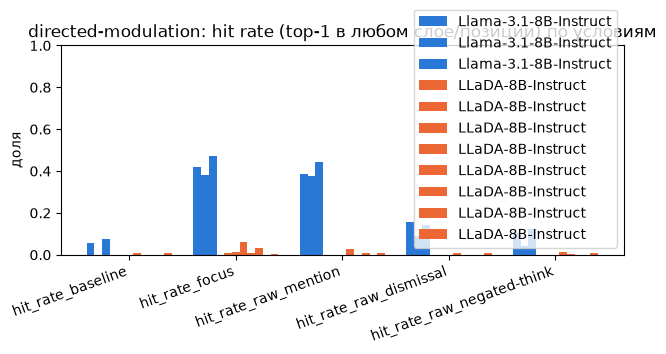

In [21]:
rows_directed_modulation, dm_trials = [], []
for entry in MODELS:
    if DEBUG_MODE:
        _r, _d = run_directed_modulation(entry, n_math=8, n_topic=8, n_carriers=1, probe_step=2)
    else:
        _r, _d = run_directed_modulation(entry, n_math=10_000, n_topic=10_000, n_carriers=2, probe_step=2)
    rows_directed_modulation += _r
    dm_trials.append(_d)
dm_trials = pd.concat(dm_trials, ignore_index=True)
dm_trials.to_csv(f"directed_modulation_trials_{PROMPT_FORMAT}.csv", index=False)
record_and_show([{k: v for k, v in r.items()
                  if not k.startswith(("hit_frac_", "hitk_rate_", "median_best_rank_")) and not k.endswith(("_math", "_topic"))}
                 for r in rows_directed_modulation])

GROUP_ORDER = ["baseline", "focus", "mention", "dismissal", "negated-think"]
t1 = (dm_trials.groupby(["model", "variant", "group"])["hit1_any"].mean().unstack("group")
      .reindex(columns=[g for g in GROUP_ORDER if g in dm_trials["group"].unique()]))
print("hit rate (top-1 в любом слое/позиции), по сырым группам:")
display(t1.round(3))

t2 = (dm_trials.groupby(["model", "variant", "target_kind", "group"])["hit1_any"].mean().unstack("group")
      .reindex(columns=[g for g in GROUP_ORDER if g in dm_trials["group"].unique()]))
print("\nhit rate по семействам целей (math / topic):")
display(t2.round(3))

t3 = (dm_trials.groupby(["model", "variant", "group"])[["hitk_any", "hit1_frac"]].mean().unstack("group").round(3))
print("\nrank<=k (hitk_any) и доля members на top-1 (hit1_frac):")
display(t3)

t4 = (dm_trials.groupby(["model", "variant", "group"])["best_rank"].median().unstack("group")
      .reindex(columns=[g for g in GROUP_ORDER if g in dm_trials["group"].unique()]))
print("\nмедианный лучший ранг цели по band x спану:")
display(t4)

best_variant = dm_trials[dm_trials["group"] == "focus"].groupby(["model", "variant"])["hit1_any"].mean() \
    .groupby("model").idxmax()
for m, (mm, v) in best_variant.items():
    sub = dm_trials[(dm_trials["model"] == m) & (dm_trials["variant"] == v)]
    print(f"\nПо формулировкам: {m}, variant={v}")
    display(sub.groupby(["group", "phrasing"])["hit1_any"].agg(["mean", "count"]).round(3))

def _boot_diff(sub, ga, gb, n=1000, seed=0):
    a = sub[sub["group"] == ga]["hit1_any"].to_numpy(); b = sub[sub["group"] == gb]["hit1_any"].to_numpy()
    if len(a) == 0 or len(b) == 0:
        return None
    r = np.random.RandomState(seed)
    d = [r.choice(a, len(a)).mean() - r.choice(b, len(b)).mean() for _ in range(n)]
    return round(a.mean() - b.mean(), 3), round(np.percentile(d, 2.5), 3), round(np.percentile(d, 97.5), 3)
bt = []
for (m, v), sub in dm_trials.groupby(["model", "variant"]):
    bt.append({"model": m, "variant": v,
               "focus-baseline": _boot_diff(sub, "focus", "baseline"),
               "focus-mention": _boot_diff(sub, "focus", "mention"),
               "mention-dismissal": _boot_diff(sub, "mention", "dismissal"),
               "dismissal-baseline (white bear)": _boot_diff(sub, "dismissal", "baseline")})
print("\nРазности hit rate [оценка, 95% bootstrap CI]:")
display(pd.DataFrame(bt))

plot_bars(
    [r for r in rows_directed_modulation],
    ["hit_rate_baseline", "hit_rate_focus", "hit_rate_raw_mention", "hit_rate_raw_dismissal", "hit_rate_raw_negated-think"],
    "directed-modulation: hit rate (top-1 в любом слое/позиции) по условиям",
)

## Эксперимент 5 -- flexible-generalization

**Идея (статья §3.4, Fig. 18-19, A.13).** Если J-lens-вектор -- это "общая шина" (broadcast), то один и тот же вектор аргумента
должен читаться разными операциями. Берём одну категорию (страны, месяцы, животные, числа), четыре функции-шаблона
("The capital of {arg} is the city of", "Most people in {arg} speak", ...) и подменяем в скрытом состоянии вектор
одного аргумента на вектор другого (France -> China) **на каждой позиции промпта по всему band**, одинаково для любой функции.
Если вектор действительно общий, модель вернёт столицу/язык/континент/валюту *нового* аргумента, хотя в тексте всё ещё France.

**Дизайн как в статье.** 4 категории x 4 функции x 4 аргумента; на каждую функцию 12 упорядоченных пар (источник -> цель);
всего **192 испытания** на линзу и alpha. Успех -- ответ нового аргумента на **top-1** на позиции чтения (формы с пробелом/без и
с разным регистром считаются одним ответом: "formatting tokens for capitalization are ignored"). Для отладки
`DEBUG_MODE=True` берёт одну цель на аргумент (64 испытания) и не строит многотокенное продолжение (оно нужно только для просмотра текста; сами метрики считаются по одному предсказанию на `[MASK]` / последней позиции и от режима не зависят).

**Ориентиры из статьи (Sonnet 4.5):** 76/192 (40%) при alpha=1 и 101/192 (53%) при alpha=2. Страны почти идеально (42/48 пар
вне диагонали на top-1), месяцы частично, животные редко, числа ни разу при alpha=1; при неудаче top-1 обычно ещё прежний
ответ, а ответ нового аргумента стоит ниже -- alpha=2 это часто исправляет. Для 8B-моделей разумно ожидать меньше, но с той же
иерархией категорий (страны > месяцы > животные > числа).

**Что исправлено по сравнению с прошлой версией (0/64 у LLaDA, 2-3/64 у Llama; swap не менял вывод в 98% / 80% случаев).**
1. **Самоотменяющийся swap.** Прежний режим `lens_swap` применялся на каждом слое band заново; чётное число обменов возвращает
   исходные координаты -- ровно та же причина, из-за которой probe-swap давал 1-5%. Теперь `lens_clamp`: координаты в span{v_s, v_t}
   выставляются по ЧИСТОМУ проходу, `c_clean + alpha*(swap(c_clean) - c_clean)`, идемпотентно (как в Fig. 18: "The swap is clamped").
2. **Направления per-layer.** Раньше вектор брался один раз со среднего слоя band и применялся ко всем слоям; теперь на каждом слое --
   направление J_l^T W_U[v] этого слоя (как в probe-swap).
3. **Токен аргумента как в промпте.** `" France"` после пробела, но `"France"` в начале строки и `three` после кавычки
   ("The word 'three'..."); прежний код всегда брал вариант с пробелом. Если токен не найден в токенизации промпта, промпт пропускается и
   это печатается.
4. **Все пары, а не одна.** Прежний `random.Random(seed).choice` с фиксированным seed выбирал каждый раз одну и ту же позицию
   (один сдвиг) -- 64 испытания вместо 192 и перекос в выборе целей.
5. **Метрика.** top-1 по множеству форм ответа (с пробелом/без, регистр), плюс top-5, медианный ранг ответа до/после, доля
   неизменившегося top-1 и разрез по категориям/функциям. Пересечение форм старого и нового ответов исключается (иначе "успех" тривиален).
   `swap_success_given_both_ok` -- среди испытаний, где модель знает ответ и для источника, и для цели.
6. **Пробельный токен перед ответом и цифры (по итогам первого прогона).** Llama-3 режет " 6" на " " + "6", и на "Two times three
   equals" модель сначала хочет пробел -- `baseline_ok` для чисел был 0 просто из-за токенизации. Теперь, если чистый top-1
   промпта -- чисто пробельный токен, он дописывается к промпту (как `_answer_continuation` в probe-swap) и читается следующий.
   Числительные принимаются и словом, и цифрой ("six"/"6"), т.к. 8B-модели отвечают цифрами. Принимаются и синонимы
   (Chinese/Mandarin, Yuan/Renminbi).
7. **Шаблон "A group of {arg}s"** раньше выпадал целиком: токен "lion" не стоит в промпте дословно ("lions"). Проверка наличия токена
   в промпте убрана: clamp работает с координатами вдоль направления понятия на всех позициях, самого токена в тексте не требует.
8. **Alpha = (1, 2)** вместо (1, 0.75, 0.5): в статье сравниваются именно alpha=1 и alpha=2.

**LLaDA-специфика.** Читается ОДНА позиция -- дописанный `[MASK]` после контекста (маска на позиции n предсказывает токен n);
линзы те же шесть. `patch_read=True` патчит и эту маску (как в probe-swap и verbal-report). Для Llama читается последняя позиция.

**Известное ограничение.** Для `first_letter` ("The word 'three' begins with the letter") обе модели следом ставят кавычку, а не букву; такие испытания остаются с `baseline_ok=False` и в `swap_success_given_both_ok` не попадают.

**Как читать:** `n_success` -- число успехов из N (сравнивать со 76/192 и 101/192); `swap_success_<категория>`; `median_rank_before ->
median_rank_after` показывает движение даже при промахе top-1. Файл для присылки: `flexible_generalization_token_table.csv`.

**Baseline'ы.** Строки `lens_variant = logit-lens / tuned-lens` дают тот же swap-тест с baseline-направлениями; ожидается, что у них ранг/успех заметно хуже в середине стека.

---

**Абляция режима swap `transfer` .** Основной режим -- `lens_clamp` (статья). Дополнительно для линз из `SWAP_ABLATION_LENSES`
те же испытания прогоняются режимом `transfer`: `h' = h + alpha * (h·dA) * (dB − dA)` (координата вдоль направления аргумента-источника переносится
на направление аргумента-цели; без обмена и без фиксации на чистом проходе). Строки: `variant = "transfer:<линза>@alpha=.."`, колонка `swap_mode`;
в сравнение с baseline'ами и в сводную карту они не входят, сравнение выводит `show_swap_mode_ablation`. Выключить: `SWAP_ABLATION_MODES = ()`.


In [22]:
_FG_NUM = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "seven": 7, "eight": 8, "nine": 9, "ten": 10,
           "twelve": 12, "fourteen": 14, "eighteen": 18, "twenty": 20, "forty": 40, "eighty": 80}
_FG_ALIAS = {"Chinese": ["Mandarin"], "Yuan": ["Renminbi"]}

def _fg_first_visible(tok, text):
    """Первый НЕпробельный токен естественной токенизации text (Llama-3 режет ' 6' на ' ' + '6')."""
    for t in tok(text, add_special_tokens=False)["input_ids"]:
        if tok.decode([t]).strip():
            return t
    return None

def _fg_answer_ids(tok, word):
    """Токены, которыми может начаться ответ `word`: с пробелом/без, нижний регистр и капитализация
    (статья: 'formatting tokens for capitalization are ignored'), синонимы и цифровая запись числительных
    (8B-модели на 'Two times three equals' отвечают '6', а не 'six'). Берётся ПЕРВЫЙ видимый токен формы."""
    words = [word] + _FG_ALIAS.get(word, [])
    if word.lower() in _FG_NUM:
        words.append(str(_FG_NUM[word.lower()]))
    ids = []
    for w in words:
        for f in (" " + w, w, " " + w.lower(), w.lower(), " " + w.capitalize(), w.capitalize()):
            t = _fg_first_visible(tok, f)
            if t is not None and t not in ids:
                ids.append(t)
    return ids

def _fg_arg_id(tok, template, arg):
    """Токен аргумента ТАК, как он стоит в промпте: после пробела -- ' France', в начале строки или
    после кавычки ("{arg} is a country...", "The word '{arg}'...") -- без ведущего пробела."""
    prefix = template.split("{arg}")[0]
    form = (" " + arg) if prefix.endswith(" ") else arg
    t = tok(form, add_special_tokens=False)["input_ids"]
    return t[0] if t else None

def run_flexible_generalization(entry, limit=N_ITEMS_LIMIT, n_gen=2, alphas=(1.0, 2.0), gen_alphas=(1.0,),
                                pairs_per_arg=None, patch_read=True, ablation_modes=None, ablation_lenses=None):
    """Статья §3.4 / Fig. 19: swap лиц J-lens-вектора аргумента на вектор другого аргумента той же
    категории на КАЖДОЙ позиции промпта, по band, clamp-версией (идемпотентной -- см. probe-swap).
    Успех = top-1 на позиции чтения принадлежит формам ответа для НОВОГО аргумента.
    Статья (Sonnet 4.5): 76/192 при alpha=1 и 101/192 при alpha=2; страны ~ почти идеально, месяцы
    частично, животные редко, числа ~ никогда при alpha=1.
    pairs_per_arg=None -- все 3 цели на аргумент (192 испытания); int -- первые N (циклический сдвиг),
    для отладки. limit -- ограничение числа категорий.
    ablation_modes / ablation_lenses -- абляция режима swap (по умолчанию SWAP_ABLATION_MODES / SWAP_ABLATION_LENSES): те же
    испытания с режимом "transfer"; строки с variant "transfer:<линза>@alpha=..."."""
    model, tok, band = entry["model"], entry["tokenizer"], entry["band"]
    lenses = all_llada_lenses(entry)
    categories = json.load(open(EXPERIMENTS_DIR / "flexible-generalization.json"))["categories"]
    if limit:
        categories = categories[:limit]
    mask_id = entry.get("mask_id")

    prompts = {}
    uniq_ids = []
    for cat in categories:
        for func in cat["funcs"]:
            for arg in cat["args"]:
                text = func["template"].format(arg=arg)
                ids = text_ids(tok, text)
                aid = _fg_arg_id(tok, func["template"], arg)
                if aid is None:
                    continue
                prompts[(cat["name"], func["name"], arg)] = {"text": text, "ids": ids, "arg_id": aid,
                                                              "ans": set(_fg_answer_ids(tok, func["answers"][arg]))}
                if aid not in uniq_ids:
                    uniq_ids.append(aid)
    def _fg_prep(item):
        key, p = item
        model = entry["model"]
        ext = 0
        acts, fl, rp = record_residuals_masked(entry, p["ids"], band)
        top1 = final_logits_at(model, acts, fl, rp).argmax().item()
        if not tok.decode([top1]).strip():
            p["ids"] = torch.cat([p["ids"], torch.tensor([[top1]], device=p["ids"].device, dtype=torch.long)], dim=1)
            acts, fl, rp = record_residuals_masked(entry, p["ids"], band)
            top1 = final_logits_at(model, acts, fl, rp).argmax().item()
            ext = 1
        p["top1"] = top1
        return ext
    n_ext = sum(pmap(_fg_prep, list(prompts.items()), desc=f"flexible-generalization/top1 [{entry['name']}]"))
    print(f"[flexible-generalization {entry['name']}] промптов: {len(prompts)}, с дописанным пробельным токеном: {n_ext}")
    uidx = {t: i for i, t in enumerate(uniq_ids)}
    dirs = {v: token_directions_batch(model, lens, band, uniq_ids) for v, lens in lenses.items()}
    plan = swap_mode_plan(lenses, ablation_modes, ablation_lenses)

    def maker(alpha, Ds, Dt, mode="lens_clamp"):
        def make(clean, positions):
            return [{"layer": l, "positions": positions, "direction_s": Ds[l], "direction_t": Dt[l],
                     "alpha": alpha, "mode": mode, "clean_h": clean[l]} for l in band]
        return make

    rows, skipped_box = [], []

    def _fg_job(_job):
        cat, func, ai, arg = _job
        args = cat["args"]
        model = entry["model"]
        src = prompts.get((cat["name"], func["name"], arg))
        if src is None:
            skipped_box.append(1)
            return
        ids = src["ids"]
        others = [(ai + k) % len(args) for k in range(1, len(args))]
        if pairs_per_arg:
            others = others[:pairs_per_arg]
        base_acts, bfl, brp = record_residuals_masked(entry, ids, band)
        base_logits = final_logits_at(model, base_acts, bfl, brp).float()
        base_top1 = base_logits.argmax().item()
        patch_positions = patchable_positions(entry, ids)
        if patch_read and mask_id is not None:
            patch_positions = list(range(ids.shape[1] + 1))
        baseline_text = tok.decode(generate_tokens(entry, ids, band, n=n_gen)[0]) if gen_alphas else None

        for oi in others:
            new_arg = args[oi]
            tgt = prompts.get((cat["name"], func["name"], new_arg))
            if tgt is None or tgt["arg_id"] == src["arg_id"]:
                skipped_box.append(1)
                continue
            new_set = set(_fg_answer_ids(tok, func["answers"][new_arg])) - src["ans"]
            if not new_set:
                skipped_box.append(1)
                continue
            rank_before = min(_rank_tok(base_logits, t) for t in new_set)
            for variant, mode, tag in plan:
                Ds = {l: dirs[variant][l][uidx[src["arg_id"]]] for l in band}
                Dt = {l: dirs[variant][l][uidx[tgt["arg_id"]]] for l in band}
                for alpha in alphas:
                    make = maker(alpha, Ds, Dt, mode)
                    with ResidualPatcher(model.layers, make(base_acts, patch_positions)):
                        acts2, fl2, rp2 = record_residuals_masked(entry, ids, band)
                    lg = final_logits_at(model, acts2, fl2, rp2).float()
                    top1 = lg.argmax().item()
                    swap_text = None
                    if alpha in gen_alphas:
                        swap_text = tok.decode(_generate_tokens_clamped(entry, ids, band, n_gen, make,
                                                                        patch_read=patch_read))
                    rows.append({
                        "model": entry["name"], "variant": f"{tag}{variant}@alpha={alpha}",
                        "lens_variant": f"{tag}{variant}", "alpha": alpha, "swap_mode": mode,
                        "category": cat["name"], "func": func["name"], "prompt": src["text"],
                        "arg": arg, "new_arg": new_arg,
                        "expected_answer": func["answers"][arg], "expected_new_answer": func["answers"][new_arg],
                        "baseline_top1": tok.decode([base_top1]), "swap_top1": tok.decode([top1]),
                        "baseline_ok": base_top1 in src["ans"],
                        "target_baseline_ok": tgt["top1"] in tgt["ans"],
                        "swap_ok": top1 in new_set,
                        "unchanged": top1 == base_top1,
                        "rank_before": rank_before,
                        "rank_after": min(_rank_tok(lg, t) for t in new_set),
                        "baseline_generated": baseline_text, "swap_generated": swap_text,
                        "identical_to_baseline": (swap_text == baseline_text) if swap_text is not None else None,
                    })

    _fg_jobs = [(cat, func, ai, arg) for cat in categories for func in cat["funcs"] for ai, arg in enumerate(cat["args"])]
    pmap(_fg_job, _fg_jobs, desc=f"flexible-generalization [{entry['name']}]")
    skipped = len(skipped_box)
    if skipped:
        print(f"[flexible-generalization {entry['name']}] пропущено испытаний/промптов: {skipped}")
    token_df = pd.DataFrame(rows)

    out_rows = []
    for variant in token_df["variant"].unique():
        sub = token_df[token_df["variant"] == variant]
        both = sub[sub["baseline_ok"] & sub["target_baseline_ok"]]
        row = {
            "experiment": "flexible-generalization", "model": entry["name"], "variant": variant,
            "swap_mode": sub["swap_mode"].iloc[0],
            "n_items": len(sub),
            "n_success": f"{int(sub['swap_ok'].sum())}/{len(sub)}",
            "baseline_acc": sub["baseline_ok"].mean(),
            "swap_success_rate": sub["swap_ok"].mean(),
            "swap_success_given_both_ok": both["swap_ok"].mean() if len(both) else None,
            "n_both_ok": len(both),
            "swap_top5_rate": (sub["rank_after"] <= 5).mean(),
            "median_rank_before": sub["rank_before"].median(),
            "median_rank_after": sub["rank_after"].median(),
            "frac_top1_unchanged": sub["unchanged"].mean(),
        }
        for c in sub["category"].unique():
            row[f"swap_success_{c}"] = sub[sub["category"] == c]["swap_ok"].mean()
        out_rows.append(row)
    return out_rows, token_df

flexible-generalization/top1 [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 64/64 [00:02<00:00, 23.58it/s]


[flexible-generalization Llama-3.1-8B-Instruct] промптов: 64, с дописанным пробельным токеном: 12


flexible-generalization [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 64/64 [03:57<00:00,  3.71s/it]
flexible-generalization/top1 [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 64/64 [00:02<00:00, 30.48it/s]


[flexible-generalization LLaDA-8B-Instruct] промптов: 64, с дописанным пробельным токеном: 6


flexible-generalization [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 64/64 [07:27<00:00,  7.00s/it]


,experiment,model,variant,swap_mode,n_items,n_success,baseline_acc,swap_success_rate,swap_success_given_both_ok,n_both_ok,swap_top5_rate,median_rank_before,median_rank_after,frac_top1_unchanged,swap_success_countries,swap_success_months,swap_success_animals,swap_success_numbers
0,flexible-generalization,Llama-3.1-8B-Instruct,single@alpha=1.0,lens_clamp,192,76/192,0.7500,0.395833,0.537879,132,0.583333,63.5,4.0,0.416667,0.854167,0.562500,0.166667,0.000000
1,flexible-generalization,Llama-3.1-8B-Instruct,single@alpha=2.0,lens_clamp,192,50/192,0.7500,0.260417,0.356061,132,0.536458,63.5,5.0,0.140625,0.520833,0.375000,0.145833,0.000000
2,flexible-generalization,Llama-3.1-8B-Instruct,logit-lens@alpha=1.0,lens_clamp,192,31/192,0.7500,0.161458,0.212121,132,0.338542,63.5,17.0,0.739583,0.083333,0.520833,0.020833,0.020833
3,flexible-generalization,Llama-3.1-8B-Instruct,logit-lens@alpha=2.0,lens_clamp,192,49/192,0.7500,0.255208,0.348485,132,0.427083,63.5,9.5,0.479167,0.416667,0.562500,0.020833,0.020833
4,flexible-generalization,Llama-3.1-8B-Instruct,tuned-lens@alpha=1.0,lens_clamp,192,27/192,0.7500,0.140625,0.181818,132,0.343750,63.5,17.5,0.765625,0.041667,0.479167,0.020833,0.020833
5,flexible-generalization,Llama-3.1-8B-Instruct,tuned-lens@alpha=2.0,lens_clamp,192,47/192,0.7500,0.244792,0.333333,132,0.437500,63.5,10.0,0.479167,0.395833,0.541667,0.020833,0.020833
6,flexible-generalization,Llama-3.1-8B-Instruct,transfer:single@alpha=1.0,transfer,192,43/192,0.7500,0.223958,0.287879,132,0.479167,63.5,6.0,0.171875,0.416667,0.208333,0.208333,0.062500
7,flexible-generalization,Llama-3.1-8B-Instruct,transfer:single@alpha=2.0,transfer,192,32/192,0.7500,0.166667,0.212121,132,0.359375,63.5,14.0,0.145833,0.291667,0.145833,0.166667,0.062500
8,flexible-generalization,LLaDA-8B-Instruct,0@alpha=1.0,lens_clamp,192,15/192,0.6875,0.078125,0.090000,100,0.291667,56.0,21.5,0.697917,0.166667,0.083333,0.041667,0.020833
9,flexible-generalization,LLaDA-8B-Instruct,0@alpha=2.0,lens_clamp,192,30/192,0.6875,0.156250,0.240000,100,0.395833,56.0,9.0,0.343750,0.458333,0.125000,0.041667,0.000000


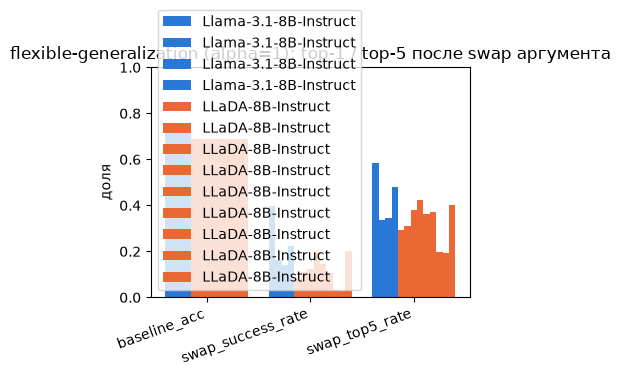

Статья (Sonnet 4.5): 76/192 = 0.40 при alpha=1, 101/192 = 0.53 при alpha=2; страны ~0.88, месяцы частично, животные редко, числа ~0 при alpha=1.

Успех top-1 по категориям:


category                                     countries  months  animals  \
model                 lens_variant    alpha                               
LLaDA-8B-Instruct     0               1.0         0.17    0.08     0.04   
                                      2.0         0.46    0.12     0.04   
                      1               1.0         0.27    0.10     0.04   
                                      2.0         0.50    0.19     0.04   
                      2               1.0         0.31    0.15     0.04   
                                      2.0         0.52    0.42     0.08   
                      3               1.0         0.48    0.19     0.10   
                                      2.0         0.75    0.54     0.31   
                      logit-lens      1.0         0.04    0.02     0.04   
                                      2.0         0.04    0.10     0.04   
                      merged          1.0         0.38    0.15     0.04   
                                      2.0         0.56    0.44     0.12   
                      single_mask     1.0         0.31    0.02     0.06   
                                      2.0         0.65    0.19     0.15   
                      transfer:merged 1.0         0.46    0.27     0.06   
                                      2.0         0.52    0.31     0.12   
                      tuned-lens      1.0         0.06    0.02     0.00   
                                      2.0         0.06    0.10     0.06   
Llama-3.1-8B-Instruct logit-lens      1.0         0.08    0.52     0.02   
                                      2.0         0.42    0.56     0.02   
                      single          1.0         0.85    0.56     0.17   
                                      2.0         0.52    0.38     0.15   
                      transfer:single 1.0         0.42    0.21     0.21   
                                      2.0         0.29    0.15     0.17   
                      tuned-lens      1.0         0.04    0.48     0.02   
                                      2.0         0.40    0.54     0.02   

category                                     numbers  
model                 lens_variant    alpha           
LLaDA-8B-Instruct     0               1.0       0.02  
                                      2.0       0.00  
                      1               1.0       0.02  
                                      2.0       0.02  
                      2               1.0       0.00  
                                      2.0       0.02  
                      3               1.0       0.02  
                                      2.0       0.02  
                      logit-lens      1.0       0.02  
                                      2.0       0.02  
                      merged          1.0       0.02  
                                      2.0       0.04  
                      single_mask     1.0       0.02  
                                      2.0       0.02  
                      transfer:merged 1.0       0.02  
                                      2.0       0.02  
                      tuned-lens      1.0       0.02  
                                      2.0       0.02  
Llama-3.1-8B-Instruct logit-lens      1.0       0.02  
                                      2.0       0.02  
                      single          1.0       0.00  
                                      2.0       0.00  
                      transfer:single 1.0       0.06  
                                      2.0       0.06  
                      tuned-lens      1.0       0.02  
                                      2.0       0.02


Успех top-1 по функциям (alpha=1; для LLaDA -- линза 3 и merged; плюс baseline logit-lens / tuned-lens):


category                           animals                     countries  \
func                                 class group habitat  legs   capital   
model                 lens_variant                                         
LLaDA-8B-Instruct     3               0.00  0.08    0.17  0.17      0.75   
                      logit-lens      0.00  0.08    0.00  0.08      0.00   
                      merged          0.00  0.08    0.00  0.08      0.75   
                      tuned-lens      0.00  0.00    0.00  0.00      0.00   
Llama-3.1-8B-Instruct logit-lens      0.00  0.00    0.00  0.08      0.08   
                      single          0.25  0.00    0.33  0.08      1.00   
                      tuned-lens      0.00  0.00    0.00  0.08      0.00   

category                                                        months  \
func                               continent currency language holiday   
model                 lens_variant                                       
LLaDA-8B-Instruct     3                 0.42     0.25     0.50    0.00   
                      logit-lens        0.00     0.00     0.17    0.00   
                      merged            0.17     0.08     0.50    0.00   
                      tuned-lens        0.00     0.00     0.25    0.00   
Llama-3.1-8B-Instruct logit-lens        0.08     0.08     0.08    0.67   
                      single            0.83     0.67     0.92    0.58   
                      tuned-lens        0.00     0.08     0.08    0.58   

category                                                    numbers  \
func                               next_month number season  double   
model                 lens_variant                                    
LLaDA-8B-Instruct     3                  0.08   0.00   0.67     0.0   
                      logit-lens         0.00   0.00   0.08     0.0   
                      merged             0.08   0.00   0.50     0.0   
                      tuned-lens         0.00   0.00   0.08     0.0   
Llama-3.1-8B-Instruct logit-lens         0.00   0.75   0.67     0.0   
                      single             0.00   0.75   0.92     0.0   
                      tuned-lens         0.00   0.67   0.67     0.0   

category                                                          
func                               first_letter square successor  
model                 lens_variant                                
LLaDA-8B-Instruct     3                     0.0   0.08       0.0  
                      logit-lens            0.0   0.08       0.0  
                      merged                0.0   0.08       0.0  
                      tuned-lens            0.0   0.08       0.0  
Llama-3.1-8B-Instruct logit-lens            0.0   0.08       0.0  
                      single                0.0   0.00       0.0  
                      tuned-lens            0.0   0.08       0.0


Медианный ранг ответа для нового аргумента (до -> после), alpha=1:


rank_before  rank_after
model                 lens_variant                            
LLaDA-8B-Instruct     0                       56.0        21.5
                      1                       56.0        19.0
                      2                       56.0        12.0
                      3                       56.0         9.0
                      logit-lens              56.0        35.5
                      merged                  56.0        13.5
                      single_mask             56.0        14.0
                      transfer:merged         56.0        11.0
                      tuned-lens              56.0        33.0
Llama-3.1-8B-Instruct logit-lens              63.5        17.0
                      single                  63.5         4.0
                      transfer:single         63.5         6.0
                      tuned-lens              63.5        17.5


Доля swap_generated == baseline_generated:


model                  variant                  
LLaDA-8B-Instruct      0@alpha=1.0                  0.817708
                       1@alpha=1.0                  0.713542
                       2@alpha=1.0                     0.625
                       3@alpha=1.0                  0.583333
                       logit-lens@alpha=1.0         0.953125
                       merged@alpha=1.0             0.640625
                       single_mask@alpha=1.0          0.6875
                       transfer:merged@alpha=1.0    0.567708
                       tuned-lens@alpha=1.0         0.885417
Llama-3.1-8B-Instruct  logit-lens@alpha=1.0           0.6875
                       single@alpha=1.0             0.302083
                       transfer:single@alpha=1.0    0.104167
                       tuned-lens@alpha=1.0         0.703125
Name: identical_to_baseline, dtype: object


Абляция режима swap (alpha=1): lens_clamp (статья) против transfer, по тем линзам, где она запускалась:


frac_top1_unchanged           \
swap_mode                             lens_clamp transfer   
model                 lens                                  
LLaDA-8B-Instruct     merged               0.630    0.542   
Llama-3.1-8B-Instruct single               0.417    0.172   

                             swap_success_given_both_ok           \
swap_mode                                    lens_clamp transfer   
model                 lens                                         
LLaDA-8B-Instruct     merged                      0.230    0.280   
Llama-3.1-8B-Instruct single                      0.538    0.288   

                             swap_success_rate          swap_top5_rate  \
swap_mode                           lens_clamp transfer     lens_clamp   
model                 lens                                               
LLaDA-8B-Instruct     merged             0.146    0.203          0.365   
Llama-3.1-8B-Instruct single             0.396    0.224          0.583   

                                       
swap_mode                    transfer  
model                 lens             
LLaDA-8B-Instruct     merged    0.401  
Llama-3.1-8B-Instruct single    0.479

,model,variant,lens_variant,alpha,swap_mode,category,func,prompt,arg,new_arg,...,swap_top1,baseline_ok,target_baseline_ok,swap_ok,unchanged,rank_before,rank_after,baseline_generated,swap_generated,identical_to_baseline
0,Llama-3.1-8B-Instruct,single@alpha=1.0,single,1.0,lens_clamp,countries,capital,The capital of China is the city of,China,Egypt,...,Cairo,True,True,True,False,1737,1,Beijing.,"Cairo,",False
1,Llama-3.1-8B-Instruct,single@alpha=1.0,single,1.0,lens_clamp,countries,capital,The capital of Canada is the city of,Canada,China,...,Beijing,True,True,True,False,288,1,"Ottawa,","Beijing,",False
2,Llama-3.1-8B-Instruct,single@alpha=2.0,single,2.0,lens_clamp,countries,capital,The capital of China is the city of,China,Egypt,...,Cairo,True,True,True,False,1737,1,Beijing.,NaN,None
3,Llama-3.1-8B-Instruct,single@alpha=2.0,single,2.0,lens_clamp,countries,capital,The capital of Canada is the city of,Canada,China,...,Beijing,True,True,True,False,288,1,"Ottawa,",NaN,None
4,Llama-3.1-8B-Instruct,single@alpha=1.0,single,1.0,lens_clamp,countries,capital,The capital of France is the city of,France,Canada,...,Ottawa,True,True,True,False,713,1,"Paris,","Ottawa,",False
5,Llama-3.1-8B-Instruct,single@alpha=2.0,single,2.0,lens_clamp,countries,capital,The capital of France is the city of,France,Canada,...,Canada,True,True,False,False,713,2,"Paris,",NaN,None
6,Llama-3.1-8B-Instruct,logit-lens@alpha=1.0,logit-lens,1.0,lens_clamp,countries,capital,The capital of China is the city of,China,Egypt,...,Beijing,True,True,False,True,1737,17,Beijing.,Beijing.,True
7,Llama-3.1-8B-Instruct,logit-lens@alpha=1.0,logit-lens,1.0,lens_clamp,countries,capital,The capital of Canada is the city of,Canada,China,...,Beijing,True,True,True,False,288,1,"Ottawa,","Beijing,",False
8,Llama-3.1-8B-Instruct,logit-lens@alpha=2.0,logit-lens,2.0,lens_clamp,countries,capital,The capital of China is the city of,China,Egypt,...,Cairo,True,True,True,False,1737,1,Beijing.,NaN,None
9,Llama-3.1-8B-Instruct,logit-lens@alpha=2.0,logit-lens,2.0,lens_clamp,countries,capital,The capital of Canada is the city of,Canada,China,...,Beijing,True,True,True,False,288,1,"Ottawa,",NaN,None


In [23]:
rows_flexible_generalization, token_dfs_flexgen = [], []
for entry in MODELS:
    if DEBUG_MODE:
        out_rows, token_df = run_flexible_generalization(entry, pairs_per_arg=1, gen_alphas=())
    else:
        out_rows, token_df = run_flexible_generalization(entry)
    rows_flexible_generalization.extend(out_rows)
    token_dfs_flexgen.append(token_df)
token_table_flexible_generalization = pd.concat(token_dfs_flexgen, ignore_index=True)
token_table_flexible_generalization.to_csv("flexible_generalization_token_table.csv", index=False)

record_and_show(rows_flexible_generalization)
plot_bars([r for r in rows_flexible_generalization if r["variant"].endswith("alpha=1.0")],
          ["baseline_acc", "swap_success_rate", "swap_top5_rate"],
          "flexible-generalization (alpha=1): top-1 / top-5 после swap аргумента")

T = token_table_flexible_generalization
print("Статья (Sonnet 4.5): 76/192 = 0.40 при alpha=1, 101/192 = 0.53 при alpha=2; "
      "страны ~0.88, месяцы частично, животные редко, числа ~0 при alpha=1.\n")
cats = [c for c in ["countries", "months", "animals", "numbers"] if c in set(T["category"])]
print("Успех top-1 по категориям:")
display(T.groupby(["model", "lens_variant", "alpha", "category"])["swap_ok"].mean().unstack("category")[cats].round(2))
print("\nУспех top-1 по функциям (alpha=1; для LLaDA -- линза 3 и merged; плюс baseline logit-lens / tuned-lens):")
_sel = T[(T["alpha"] == 1.0) & (T["lens_variant"].isin(["single", "3", "merged", "logit-lens", "tuned-lens"]))]
display(_sel.groupby(["model", "lens_variant", "category", "func"])["swap_ok"].mean().unstack(["category", "func"]).round(2))
print("\nМедианный ранг ответа для нового аргумента (до -> после), alpha=1:")
display(T[T["alpha"] == 1.0].groupby(["model", "lens_variant"])[["rank_before", "rank_after"]].median())
if T["identical_to_baseline"].notna().any():
    print("\nДоля swap_generated == baseline_generated:")
    display(T.dropna(subset=["identical_to_baseline"]).groupby(["model", "variant"])["identical_to_baseline"].mean())
print("\nАбляция режима swap (alpha=1): lens_clamp (статья) против transfer, по тем линзам, где она запускалась:")
show_swap_mode_ablation(rows_flexible_generalization, ["swap_success_rate", "swap_success_given_both_ok", "swap_top5_rate",
                                                       "frac_top1_unchanged"])
pd.set_option("display.max_colwidth", None)
T.head(50)

## Эксперимент 6 -- selectivity-language

**Идея.** Модель «в фоне» понимает, о чём текст, даже если её об этом прямо не спрашивают. Проверяется селективность: виден ли в линзе
язык (fr/de/es/it) пассажа сильнее, когда задан ЯВНЫЙ вопрос про язык, чем когда модель просто продолжает нейтрально.

**Протокол чтения** (она давала содержательные числа у LLaDA, а прежняя версия -- нули).
`passages[*]` -- 8 пассажей (по 2 на язык). `task.explicit_q` -- явный вопрос, `task.automatic_q` -- нейтральный контроль; пассаж подставляется
вместо `{text}`. Метки языка (`intermediates[category]`, только однотокенные формы) отслеживаются **над токенами вопроса ПОСЛЕ пассажа**
(README), а не над самим пассажем; граница пассажа -- `common_prefix_len`. Метрика: `hit_rate` = доля меток, чей лучший ранг по
(слои band) x (позиции вопроса) <= 25; `selectivity = explicit − automatic`.

**Что отличается от прежней версии.**
1. Промпт -- шаблон датасета без `Human:/Assistant:`.
2. LLaDA читается через `probe_mask` на **каждой** позиции вопроса (`probe_step=1`; прежде каждая 2-я/3-я).
3. Слои: `SELECTIVITY_LANGUAGE_BAND = range(31)` (0..30), а не band записи модели (8..27). Это единственное место, где band отличается
   от остальных экспериментов; сменить можно в ячейке конфигурации.
4. Метки: только однотокенные формы (` слово`, затем `слово`); прежде брался первый видимый токен и исключались общие для категорий.
5. Перед подсчётом печатается и сохраняется (`readout_alignment_rows`) **диагностика выравнивания** `diagnose_readout_alignment`:
   читает ли линза текущий токен позиции (`self`) или следующий (`next`). Если у Llama преобладает `next`, а у LLaDA `self`, сравнения
   условий сдвинуты на токен (та же ошибка, что находилась в linecount/capacity). Эти числа -- инструмент интерпретации, а не результат.

**Как читать метрику.** Положительная `selectivity` -- язык сильнее виден под явным вопросом. Нуль/минус -- автоматическое кодирование не
отделяется от задачного. Контроля `off` (чужие языки) в этом протоколе нет: рост `explicit_hit_rate` может быть и праймингом слова «language».

**Прежняя версия сохранена** как `run_selectivity_language_causal` (readout `Human:/Assistant:` с контролем на чужие языки `on/off` + каузальный
swap языка, Fig. 20c). Включается `SELECTIVITY_LANGUAGE_CAUSAL = True`; её строки пишутся под именем `selectivity-language-causal`, файлы
`selectivity_language_readout.csv` / `selectivity_language_swap.csv`. Описание ниже относится к ней.

---

### Описание прежней версии (справка)

**Идея (статья §3.5.1, Fig. 20).** Одна и та же скрытая переменная -- язык пассажа -- нужна и "автоматическим" задачам
(продолжить текст, обнаружить вставку на другом языке), и "осознанным" (назвать язык, назвать автора, перевести "hello").
Статья делает два наблюдения: (b) название языка присутствует в J-lens **сопоставимо часто во всех условиях**; (c) но его
**каузальная роль различается**: если подменить в линзе язык пассажа на другой (Spanish -> French) на токенах вопроса, то
ответ в explicit report и flexible computation переключается ("Hugo" вместо "García Márquez", "Bonjour" вместо "Hola"), а
продолжение остаётся беглым испанским. То есть избирательность -- в том, ЧТО на что влияет, а не в том, где содержимое видно.

**Что измеряется теперь (две части).**
* **A. Readout** (README: "label tokens tracked over the question tokens following the passage"). Доля позиций вопроса (включая "Assistant:"), где
  хоть один токен истинной категории (French/France/français/Paris) попадает в lens top-k (любой слой band). Условия:
  `explicit` (автор из `authors`), `report` (формулировка из статьи: "What language is this passage written in?") и
  `automatic` (продолжение). **Контроль `off`**: то же для токенов трёх ДРУГИХ языков. Если вопрос про язык просто
  праймит названия языков (в explicit-вопросе слово "language" есть, в automatic -- нет), `on` и `off` растут вместе;
  след именно языка пассажа -- разность `on - off`. k=3 как в подписи к Fig. 20 (Spanish "among the top 3"), k=25 -- мягкая
  версия. `selectivity` оставлена как в README (explicit - automatic по доле достигнутых токенов), `selectivity_net_k3` --
  то же по `on - off`.
* **B. Каузальный swap** (Fig. 20c). Язык пассажа заменяется на следующий по кругу (French->German->Spanish->Italian->French)
  clamp-swap'ом (`lens_clamp`, per-layer направления токена названия языка) на всех токенах после пассажа, включая
  позиции ассистента (и `[MASK]` у LLaDA). Оценка по сгенерированному тексту: `explicit` -- фамилия автора из `authors`
  исходного (true) или нового (alt) языка; `report` -- название языка; `automatic` -- язык продолжения по служебным словам
  (грубый классификатор). `flip_<условие>@alpha` -- доля ответов, ушедших на alt (среди пассажей с верным baseline),
  `stay_...` -- остались на true. **Ожидание по статье:** flip высок в explicit/report, ~0 в automatic.

**Что было не так в прежней версии.**
1. Промпт был голым текстом без формата диалога: вопрос не задавался как вопрос, а позиции ответа ассистента (где обычно и
   читается "то, что модель собирается сказать") не входили в спан. Теперь формат из статьи -- простой текст
   "Human: ...\n\nAssistant:" (как в verbal-report); спецтокены chat-шаблона НЕ используются, потому что линза обучалась на
   претрейн-подобном тексте, и шаблон Llama (`<|start_header_id|>`, системный блок) был бы лишним сдвигом распределения.
2. Метрика "достиг ли токен top-25 хоть где-то на спане" насыщается (у LLaDA `explicit_hit_rate=1.000` несколько итераций
   подряд), а контроля на чужие языки не было. Положительная `selectivity` могла означать лишь то, что в explicit-вопросе
   есть слово "language", а не знание языка пассажа. В статье же сопоставимые уровни во всех условиях -- ожидаемая картина.
3. Каузальной части (главного результата Fig. 20) не было вовсе.

**Прежний результат (для справки):** selectivity у LLaDA 0.198 / 0.302 / 0.510 / 0.552 (bin0..3), у Llama 0.688. Его
нельзя читать как "осознанные вопросы включают знание языка": это сравнение двух разных вопросов без `off`-контроля.

**LLaDA-специфика.** Каждая позиция спана читается через `probe_mask` (маскируется только она, остальной текст виден),
линзы -- все шесть; `probe_step` прореживает позиции. Генерация -- n масок сразу, раскрывается самая уверенная; swap
патчит и позиции масок (`patch_read=True`).

**Режимы.** `DEBUG_MODE=True` -- `probe_step=3` и только alpha=1; `False` -- `probe_step=2`, alpha in (1, 2).
Файлы для присылки: `selectivity_language_readout.csv`, `selectivity_language_swap.csv`.

**Оговорки.** n=8 пассажей -- мало; классификатор языка продолжения грубый (служебные слова и характерные символы; первая версия
не знала испанских "la"/"de" и итальянского "del", из-за чего часть baseline попадала в `other`); для LLaDA фамилия автора
часто обрезана ("quez"), поэтому засчитывается слово >= 4 символов, являющееся подстрокой фамилии; anomaly detection и
перевод "hello" / валюты из Fig. 20 не включены (в датасете нет их промптов).

**Baseline'ы.** Baseline'ы читают те же позиции вопроса (`variant = logit-lens / tuned-lens`), swap -- с их направлениями.


In [24]:
import unicodedata as _ud
import re as _re

_SL_STOP = {
    "French": set("le la les des et est un une du que qui dans pour sur au aux avec il elle ils elles en ne pas se ce sa son ses de l d c qu".split()),
    "German": set("der die das und ist ein eine nicht mit von zu den dem des auf sich er sie es im auch war hatte wie noch aber".split()),
    "Spanish": set("el la los las y es un una que por con para su sus del al como más pero se de en lo le era sin".split()),
    "Italian": set("il lo la gli le i è e che di del della dei delle per con si non sul nel era ma un una verso in al alla".split()),
}
_SL_CHARS = {"French": "çèêœ", "German": "ßäöü", "Spanish": "ñ¿¡áíóú", "Italian": "ìòù"}
_SL_REPORT_Q = "Here is a passage of text:\n\n{text}\n\nWhat language is this passage written in? Answer in one word."

def _sl_norm(s):
    return "".join(c for c in _ud.normalize("NFKD", s.lower()) if not _ud.combining(c))

def _sl_lang_of_text(text):
    """Грубая классификация языка продолжения по служебным словам и характерным символам (fr/de/es/it);
    слова, общие для нескольких языков (la, de, un, en...), засчитываются каждому и взаимно сокращаются;
    None при ничьей/нуле."""
    t = text.lower()
    words = _re.findall(r"[a-zà-ÿß]+", t)
    sc = {k: sum(w in v for w in words) + 2 * sum(c in t for c in _SL_CHARS[k]) for k, v in _SL_STOP.items()}
    best = max(sc.values()) if sc else 0
    top = [k for k, v in sc.items() if v == best]
    return top[0] if best > 0 and len(top) == 1 else None

def _sl_has_author(text, names):
    """Фамилия автора из списка есть в ответе. LLaDA нередко выдаёт обрезанное слово ("quez" вместо
    "Márquez"), поэтому засчитывается и слово длиной >= 4 символов, являющееся подстрокой фамилии."""
    t = _sl_norm(text)
    ns = [_sl_norm(n) for n in names]
    if any(n in t for n in ns):
        return True
    return any(len(w) >= 4 and any(w in n for n in ns) for w in _re.findall(r"[a-z]+", t))

def _sl_chat(tok, user_text, passage):
    """Промпт в стиле статьи -- простой текст "Human: ...\n\nAssistant:" (без спецтокенов chat-шаблона: линза
    обучалась на претрейн-подобном тексте) + позиция конца пассажа в токенах. Вопрос = всё после пассажа,
    включая "\n\nAssistant:" (README: 'tracked over the question tokens following the passage')."""
    text = "Human: " + user_text + "\n\nAssistant:"
    ids = text_ids(tok, text)
    cut = text.index(passage) + len(passage)
    return ids, common_prefix_len(tok, ids, text[:cut])

@follow_gpu
def _sl_rank_tables(entry, full_ids, positions, band, token_ids, step=1):
    """{variant: ndarray [n_pos, n_tok]}: минимальный по band ранг каждого токена НА КАЖДОЙ позиции.
    Llama -- реальные позиции; LLaDA -- probe_mask (по одной маскированной позиции за раз)."""
    model, mask_id = entry["model"], entry.get("mask_id")
    lenses = all_llada_lenses(entry)
    pos = list(positions)[::step] if step > 1 else list(positions)
    tabs = {v: np.zeros((len(pos), len(token_ids))) for v in lenses}
    if mask_id is None:
        acts, _ = record_residuals(model, full_ids, band)
        for i, p in enumerate(pos):
            for v, lens in lenses.items():
                r = ranks_over_band(model, lens, acts, band, [p], list(token_ids))
                tabs[v][i] = [r[t] for t in token_ids]
        return tabs
    for i, p in enumerate(pos):
        x = full_ids.clone()
        x[0, p] = mask_id
        acts, _ = record_residuals(model, x, band)
        for v, lens in lenses.items():
            r = ranks_over_band(model, lens, acts, band, [p], list(token_ids))
            tabs[v][i] = [r[t] for t in token_ids]
    return tabs

def run_selectivity_language_causal(entry, limit=N_ITEMS_LIMIT, ks=(3, 25), probe_step=2, alphas=(1.0, 2.0),
                             do_swap=True, n_gen=None, patch_read=True):
    """Часть A (readout, как README/Fig. 20b): доля позиций вопроса, где хоть один токен истинной категории
    (French/France/français/Paris) в lens top-k (любой слой band), для условий explicit (автор), report
    (назови язык) и automatic (продолжение). КОНТРОЛЬ: то же для токенов трёх ДРУГИХ языков -- если вопрос про
    язык просто праймит названия языков, on и off растут вместе; различие on-off -- след именно языка пассажа.
    Часть B (каузально, Fig. 20c): swap языка пассажа на соседний (clamp, на токенах вопроса): ответ должен
    следовать swap в explicit/report, но не в automatic."""
    tok, band, model = entry["tokenizer"], entry["band"], entry["model"]
    lenses = all_llada_lenses(entry)
    data = json.load(open(EXPERIMENTS_DIR / "selectivity-language.json"))
    task, passages, inter, authors = data["task"], data["passages"], data["intermediates"], data["authors"]
    if limit:
        passages = passages[:limit]
    cats = list(inter)
    conds = {"explicit": task["explicit_q"], "report": _SL_REPORT_Q, "automatic": task["automatic_q"]}
    n_gen = n_gen or {"explicit": 6, "report": 3, "automatic": 12}

    cat_ids = {}
    for c in cats:
        ids = []
        for w in inter[c]:
            for f in (" " + w, w):
                t = _fg_first_visible(tok, f) if "_fg_first_visible" in globals() else first_token_id(tok, f)
                if t is not None and t not in ids:
                    ids.append(t)
        cat_ids[c] = ids
    shared = {t for c in cats for t in cat_ids[c] if sum(t in cat_ids[d] for d in cats) > 1}
    cat_ids = {c: [t for t in v if t not in shared] for c, v in cat_ids.items()}
    all_ids = sorted({t for v in cat_ids.values() for t in v})
    col = {t: i for i, t in enumerate(all_ids)}
    label_id = {c: first_token_id(tok, " " + inter[c][0]) for c in cats}
    dirs = {v: token_directions_batch(model, lens, band, [label_id[c] for c in cats]) for v, lens in lenses.items()}
    cidx = {c: i for i, c in enumerate(cats)}

    read_rows, swap_rows = [], []
    dirs = _PerDev(dirs)
    def _pjob(_job):
        p = _job
        tok, band, model = entry["tokenizer"], entry["band"], entry["model"]
        true, alt = p["category"], cats[(cats.index(p["category"]) + 1) % len(cats)]
        for cname, q in conds.items():
            ids, pend = _sl_chat(tok, q.replace("{text}", p["text"]) if "{text}" in q else q + "\n\n" + p["text"], p["text"])
            positions = list(range(pend, ids.shape[1]))
            pos_used = positions[::probe_step] if probe_step > 1 else positions
            tabs = _sl_rank_tables(entry, ids, positions, band, all_ids, step=probe_step)
            for v, tab in tabs.items():
                row = {"passage": p["key"], "category": true, "condition": cname, "variant": v, "n_pos": tab.shape[0]}
                for k in ks:
                    on = (tab[:, [col[t] for t in cat_ids[true]]] <= k).any(axis=1).mean()
                    off = np.mean([(tab[:, [col[t] for t in cat_ids[c]]] <= k).any(axis=1).mean() for c in cats if c != true])
                    row[f"on_k{k}"], row[f"off_k{k}"] = on, off
                mins = tab.min(axis=0)
                row["hit_rate"] = float(np.mean([mins[col[t]] <= max(ks) for t in cat_ids[true]]))
                on_cols = [col[t] for t in cat_ids[true]]
                hit_i = np.where((tab[:, on_cols] <= max(ks)).any(axis=1))[0]
                row["hit_tokens"] = "|".join(repr(tok.decode([int(ids[0, pos_used[i]])])) for i in hit_i)
                read_rows.append(row)

            if not do_swap:
                continue
            base_text = tok.decode(generate_tokens(entry, ids, band, n=n_gen[cname])[0])

            def classify(text):
                t = _sl_norm(text)
                if cname == "explicit":
                    has = lambda c: _sl_has_author(text, authors[c])
                    return "true" if has(true) and not has(alt) else "alt" if has(alt) and not has(true) else "other"
                if cname == "report":
                    has = lambda c: _sl_norm(inter[c][0]) in t or any(_sl_norm(w) in t for w in inter[c][2:3])
                    return "true" if has(true) and not has(alt) else "alt" if has(alt) and not has(true) else "other"
                lang = _sl_lang_of_text(text)
                return "true" if lang == true else "alt" if lang == alt else "other"

            base_cls = classify(base_text)
            for v in lenses:
                Ds = {l: dirs[v][l][cidx[true]] for l in band}
                Dt = {l: dirs[v][l][cidx[alt]] for l in band}
                for a in alphas:
                    def make(clean, positions_arg, Ds=Ds, Dt=Dt, a=a):
                        n_tot = clean[band[0]].shape[0]
                        pos = list(range(pend, n_tot))
                        return [{"layer": l, "positions": pos, "direction_s": Ds[l], "direction_t": Dt[l],
                                 "alpha": a, "mode": "lens_clamp", "clean_h": clean[l]} for l in band]
                    swap_text = tok.decode(_generate_tokens_clamped(entry, ids, band, n_gen[cname], make, patch_read=patch_read))
                    sc = classify(swap_text)
                    swap_rows.append({"passage": p["key"], "category": true, "alt": alt, "condition": cname,
                                      "variant": v, "alpha": a, "base_cls": base_cls, "swap_cls": sc,
                                      "baseline_text": base_text, "swap_text": swap_text})
    pmap(_pjob, list(passages), desc=f"selectivity-language [{entry['name']}]")

    rdf, sdf = pd.DataFrame(read_rows), pd.DataFrame(swap_rows)
    out_rows = []
    for v in rdf["variant"].unique():
        sub = rdf[rdf["variant"] == v]
        row = {"experiment": "selectivity-language", "model": entry["name"], "variant": v, "n_items": sub["passage"].nunique()}
        piv = {m: sub.pivot_table(index="passage", columns="condition", values=m) for m in ["hit_rate"] + [f"{s}_k{k}" for k in ks for s in ("on", "off")]}
        for cn in conds:
            row[f"{cn}_hit_rate"] = piv["hit_rate"][cn].mean()
            for k in ks:
                row[f"{cn}_on_k{k}"], row[f"{cn}_off_k{k}"] = piv[f"on_k{k}"][cn].mean(), piv[f"off_k{k}"][cn].mean()
        row["selectivity"] = (piv["hit_rate"]["explicit"] - piv["hit_rate"]["automatic"]).mean()
        k0 = ks[0]
        net = lambda cn: piv[f"on_k{k0}"][cn] - piv[f"off_k{k0}"][cn]
        row[f"selectivity_net_k{k0}"] = (net("explicit") - net("automatic")).mean()
        if len(sdf):
            s2 = sdf[sdf["variant"] == v]
            for cn in conds:
                for a in alphas:
                    s3 = s2[(s2["condition"] == cn) & (s2["alpha"] == a)]
                    ok = s3[s3["base_cls"] == "true"]
                    row[f"base_true_{cn}"] = (s2[s2["condition"] == cn].drop_duplicates("passage")["base_cls"] == "true").mean()
                    row[f"flip_{cn}@{a}"] = (ok["swap_cls"] == "alt").mean() if len(ok) else None
                    row[f"stay_{cn}@{a}"] = (ok["swap_cls"] == "true").mean() if len(ok) else None
        out_rows.append(row)
    return out_rows, rdf, sdf

_SL_RANK_MISS = 10 ** 9
readout_alignment_rows = []

@follow_gpu
def _sl_span_best(entry, full_ids, positions, band, token_ids, probe_step=1):
    """{линза: {token_id: минимальный ранг по (слои band) x (позиции)}}.
    Llama (mask_id=None) -- реальный текст, одна запись активаций. LLaDA -- probe_mask: на каждой позиции маскируется
    только она, остальной текст остаётся, линза читается на этой маске (иначе у LLaDA читалось бы эхо входа)."""
    model, mask_id = entry["model"], entry.get("mask_id")
    lenses = all_llada_lenses(entry)
    token_ids = list(token_ids)
    if mask_id is None:
        acts, _ = record_residuals(model, full_ids, band)
        return {n: ranks_over_band(model, l, acts, band, list(positions), token_ids) for n, l in lenses.items()}
    best = {n: {t: None for t in token_ids} for n in lenses}
    pos = list(positions)[::probe_step] if probe_step > 1 else list(positions)
    for p in pos:
        x = full_ids.clone()
        x[0, p] = mask_id
        acts, _ = record_residuals(model, x, band)
        for n, l in lenses.items():
            r = ranks_over_band(model, l, acts, band, [p], token_ids)
            for t in token_ids:
                rt = r.get(t)
                if rt is not None and (best[n][t] is None or rt < best[n][t]):
                    best[n][t] = rt
    return best

def run_selectivity_language(entry, limit=N_ITEMS_LIMIT, k=25, probe_step=1, band=None):
    """selectivity-language: explicit-вопрос про язык против automatic-контроля, метки языка
    отслеживаются над токенами вопроса после пассажа. Возвращает список строк (по линзе)."""
    band = list(band) if band else list(entry["band"])
    data = json.load(open(EXPERIMENTS_DIR / "selectivity-language.json"))
    task, passages, inter = data["task"], data["passages"], data["intermediates"]
    if limit:
        passages = passages[:limit]

    _al = diagnose_readout_alignment(entry, band=band)
    print(f"[revealed-alignment/{entry['name']}] лучшая доля top-1 == текущий / следующий токен:")
    for _n, _v in (_al or {}).items():
        print(f"    {str(_n):12s} self={_v['self']:.3f} (слой {_v['self_layer']})   next={_v['next']:.3f} (слой {_v['next_layer']})")
        readout_alignment_rows.append({"model": entry["name"], "lens": str(_n), "self": _v["self"], "self_layer": _v["self_layer"],
                                       "next": _v["next"], "next_layer": _v["next_layer"]})

    def _job(p):
        tok = entry["tokenizer"]
        tids = []
        for w in inter.get(p["category"], []):
            t = single_token_id(tok, " " + w)
            if t is None:
                t = single_token_id(tok, w)
            if t is not None:
                tids.append(t)
        if not tids:
            return []
        out = []
        for cond, qkey in (("explicit", "explicit_q"), ("automatic", "automatic_q")):
            template = task.get(qkey, "")
            prefix_text, sep, suffix_text = template.partition("{text}")
            if not sep:
                prefix_text, suffix_text = "", " " + template
            ids = text_ids(tok, prefix_text + p["text"] + suffix_text)
            pend = common_prefix_len(tok, ids, prefix_text + p["text"])
            positions = list(range(pend, ids.shape[1]))
            if not positions:
                continue
            ranks = _sl_span_best(entry, ids, positions, band, tids, probe_step)
            for name, rr in ranks.items():
                hit = sum(1 for t in tids if (rr.get(t) or _SL_RANK_MISS) <= k) / len(tids)
                out.append({"passage": p["key"], "condition": cond, "variant": str(name), "hit_rate": hit})
        return out

    rows = [r for part in pmap(_job, list(passages), desc=f"selectivity-language [{entry['name']}]") for r in part]
    df = pd.DataFrame(rows)
    out_rows = []
    for variant in df["variant"].unique():
        pivot = df[df["variant"] == variant].pivot_table(index="passage", columns="condition", values="hit_rate")
        both = {"explicit", "automatic"} <= set(pivot.columns)
        out_rows.append({
            "experiment": "selectivity-language", "model": entry["name"], "variant": variant,
            "n_items": len(passages),
            "explicit_hit_rate": pivot["explicit"].mean() if "explicit" in pivot else None,
            "automatic_hit_rate": pivot["automatic"].mean() if "automatic" in pivot else None,
            "selectivity": (pivot["explicit"] - pivot["automatic"]).mean() if both else None,
        })
    return out_rows

[revealed-alignment/Llama-3.1-8B-Instruct] лучшая доля top-1 == текущий / следующий токен:
    single       self=0.296 (слой 7)   next=0.815 (слой 30)
    logit-lens   self=0.074 (слой 20)   next=0.704 (слой 30)
    tuned-lens   self=0.037 (слой 20)   next=0.778 (слой 27)


selectivity-language [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 8/8 [00:01<00:00,  6.07it/s]


[revealed-alignment/LLaDA-8B-Instruct] лучшая доля top-1 == текущий / следующий токен:
    0            self=0.654 (слой 27)   next=0.038 (слой 29)
    1            self=0.654 (слой 29)   next=0.038 (слой 27)
    2            self=0.577 (слой 28)   next=0.038 (слой 26)
    3            self=0.462 (слой 25)   next=0.038 (слой 26)
    merged       self=0.538 (слой 25)   next=0.077 (слой 30)
    single_mask  self=0.462 (слой 25)   next=0.192 (слой 29)
    logit-lens   self=0.923 (слой 30)   next=0.000 (слой None)
    tuned-lens   self=0.923 (слой 30)   next=0.000 (слой None)


selectivity-language [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 8/8 [00:39<00:00,  4.98s/it]

Выравнивание readout (лучшая доля top-1 == текущий / следующий токен), по моделям и линзам:


,model,lens,self,self_layer,next,next_layer
0,Llama-3.1-8B-Instruct,single,0.296,7,0.815,30.0
1,Llama-3.1-8B-Instruct,logit-lens,0.074,20,0.704,30.0
2,Llama-3.1-8B-Instruct,tuned-lens,0.037,20,0.778,27.0
3,LLaDA-8B-Instruct,0,0.654,27,0.038,29.0
4,LLaDA-8B-Instruct,1,0.654,29,0.038,27.0
5,LLaDA-8B-Instruct,2,0.577,28,0.038,26.0
6,LLaDA-8B-Instruct,3,0.462,25,0.038,26.0
7,LLaDA-8B-Instruct,merged,0.538,25,0.077,30.0
8,LLaDA-8B-Instruct,single_mask,0.462,25,0.192,29.0
9,LLaDA-8B-Instruct,logit-lens,0.923,30,0.000,NaN


,experiment,model,variant,n_items,explicit_hit_rate,automatic_hit_rate,selectivity
0,selectivity-language,Llama-3.1-8B-Instruct,single,8,0.937500,0.312500,0.625000
1,selectivity-language,Llama-3.1-8B-Instruct,logit-lens,8,0.687500,0.062500,0.625000
2,selectivity-language,Llama-3.1-8B-Instruct,tuned-lens,8,0.750000,0.156250,0.593750
3,selectivity-language,LLaDA-8B-Instruct,0,8,0.229167,0.000000,0.229167
4,selectivity-language,LLaDA-8B-Instruct,1,8,0.375000,0.000000,0.375000
5,selectivity-language,LLaDA-8B-Instruct,2,8,0.614583,0.041667,0.572917
6,selectivity-language,LLaDA-8B-Instruct,3,8,0.916667,0.604167,0.312500
7,selectivity-language,LLaDA-8B-Instruct,merged,8,0.572917,0.041667,0.531250
8,selectivity-language,LLaDA-8B-Instruct,single_mask,8,0.718750,0.239583,0.479167
9,selectivity-language,LLaDA-8B-Instruct,logit-lens,8,0.427083,0.312500,0.114583


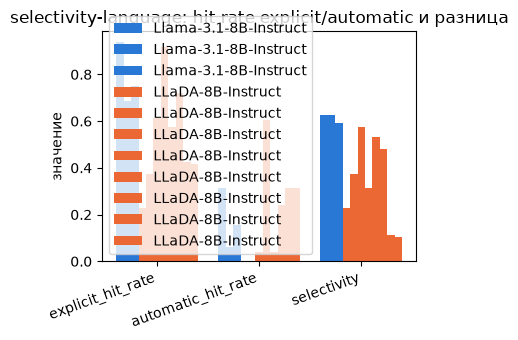

In [25]:
rows_selectivity_language = []
for entry in MODELS:
    rows_selectivity_language += run_selectivity_language(entry, probe_step=1, band=SELECTIVITY_LANGUAGE_BAND)

print("Выравнивание readout (лучшая доля top-1 == текущий / следующий токен), по моделям и линзам:")
display(pd.DataFrame(readout_alignment_rows).round(3))
record_and_show(rows_selectivity_language)
plot_bars(rows_selectivity_language, ["explicit_hit_rate", "automatic_hit_rate", "selectivity"],
          "selectivity-language: hit rate explicit/automatic и разница", ylabel="значение", ylim=None)

if SELECTIVITY_LANGUAGE_CAUSAL:
    rows_selectivity_language_causal, rdfs, sdfs = [], [], []
    for entry in MODELS:
        if DEBUG_MODE:
            _r, _rd, _sd = run_selectivity_language_causal(entry, probe_step=3, alphas=(1.0,))
        else:
            _r, _rd, _sd = run_selectivity_language_causal(entry, probe_step=2, alphas=(1.0, 2.0))
        for _x in _r:
            _x["experiment"] = "selectivity-language-causal"
        rows_selectivity_language_causal += _r
        _rd["model"] = entry["name"]; _sd["model"] = entry["name"]
        rdfs.append(_rd); sdfs.append(_sd)
    sl_read, sl_swap = pd.concat(rdfs, ignore_index=True), pd.concat(sdfs, ignore_index=True)
    for _d in (sl_read, sl_swap):
        _d["variant"] = _d["variant"].astype(str)
    sl_read.to_csv("selectivity_language_readout.csv", index=False)
    sl_swap.to_csv("selectivity_language_swap.csv", index=False)

    record_and_show(rows_selectivity_language_causal)

    print("A. Readout: доля позиций вопроса, где токены языка пассажа (on) / трёх чужих языков (off) в lens top-3:")
    display(sl_read.groupby(["model", "variant", "condition"])[["on_k3", "off_k3", "on_k25", "off_k25", "hit_rate"]].mean().round(3))
    print("\nКакие токены вопроса читаются как токены языка (top-25), по условиям (LLaDA, линза 3 / Llama):")
    _h = sl_read[sl_read["variant"].isin(["3", "single", "logit-lens", "tuned-lens"]) & (sl_read["hit_tokens"].fillna("") != "")]
    display(_h.groupby(["model", "condition"])["hit_tokens"].apply(lambda s: " ; ".join(s)).to_frame())
    print("\nB. Каузальный swap языка (на токенах вопроса): flip = ответ перешёл на соседний язык, stay = остался прежним")
    if len(sl_swap):
        _ok = sl_swap[sl_swap["base_cls"] == "true"]
        display(_ok.groupby(["model", "variant", "condition", "alpha"])["swap_cls"]
                .value_counts(normalize=True).unstack("swap_cls").fillna(0).round(2))
        print("\nbaseline верный (доля пассажей, где ответ на языке пассажа):")
        display(sl_swap.drop_duplicates(["model", "passage", "condition"]).groupby(["model", "condition"])["base_cls"]
                .apply(lambda s: (s == "true").mean()).round(2))
    plot_bars([r for r in rows_selectivity_language_causal],
              ["explicit_on_k3", "explicit_off_k3", "automatic_on_k3", "automatic_off_k3"],
              "selectivity-language: языковые токены в lens (top-3), on vs off", ylabel="доля позиций", ylim=None)
    pd.set_option("display.max_colwidth", None)
    sl_swap.head(40)

## Эксперимент 7 -- selectivity-linecount

**Идея (§3.5.1, Fig. 21 статьи).** Родственник эксперимента 6, но с "механической" скрытой величиной: длина первой строки
пассажа в символах. Тот же пассаж, разные задания: **automatic linewrap** (продолжить пассаж, сохранив перенос строк --
нужен бегущий счёт символов), **explicit report** (сколько символов в первой строке?) и **flexible computation** (какая
первая буква этого числа, записанного словом? -- счёт остаётся невысказанным промежуточным результатом). Статья: число
почти не появляется в lens при linewrap, умеренно при прямом вопросе и больше всего при вопросе про букву; ответ следует
за swap счёта в обоих вопросах, а точка переноса при продолжении -- нет.

**Промпт.** Формат задаётся `PROMPT_FORMAT` (ячейка конфигурации): `"plain"` -- как на Fig. 21, простым текстом без спецтокенов (линза обучалась на таком тексте; как в экспериментах 2 и 6), `"chat"` -- то же содержание репликой пользователя плюс teacher-forced ответ ассистента через chat-шаблон. Первый DEBUG-прогон (plain) показал, что Llama отвечает на "сколько символов" словами "7 words", поэтому ячейка прогоняет ОБА формата подряд (`LC_FORMATS`) и пишет отдельные файлы с суффиксом формата. Plain:
`Human: Below is a prompt snippet. <вопрос>\n<prompt>\n<пассаж, textwrap.fill по width>\n</prompt>\n\nAssistant:<prefill>`.
Условия из JSON: `none` (вопроса нет, контроль), `direct`, `letter` (у каждого свой teacher-forced prefill) и
`continue` (инструкция `explicit_q`, без prefill) -- это automatic linewrap. Ответ -- число символов первой строки.

**Часть A -- readout (панель b).** Цели -- числительные словом (ten ... ninety; для обеих моделей одинаковый набор). У Llama
дополнительно считаются двузначные токены 10..99 (набор "all"): у LLaDA однотокенных двузначных чисел нет, поэтому
основное сравнение моделей -- по числительным. Читаются позиции промпта от конца ПЕРВОЙ строки до места ответа (раньше длина
строки структурно неизвестна: перенос решается только после следующего слова); в статье считается число таких позиций по
всему промпту, у нас доля позиций (`posfrac_*`) и доля пассажей, где число есть хоть на одной позиции (`any_*`), top-3 как на
Fig. 21 и top-25 как в README. `correct_rank` -- лучший ранг числительного правильной декады (34 -> thirty).
LLaDA: скользящее окно -- модель видит ровно n реальных токенов и один [MASK], читается он (так сохраняется причинная
видимость, как у Llama).

**Часть B -- каузально (панели a и c).** Clamp-swap счёта на **+20** на всех позициях (декада d -> d+2, как 40-е -> 60-е в
статье): числительное десятка словом (forty -> sixty) и, где они есть токены, двузначные числа (Llama: 40..49 -> 60..69;
LLaDA: цифра десятков "4" -> "6"). Ожидание: `direct` и `letter` -- ответ следует за swap (`follow`; для буквы F -> S),
`continue` -- перенос строки не меняется.
* **Контроль (`swap_kind="control"`).** Тот же swap с тем же числом патчей, но на парах несвязанных слов (river -> table, ...). В DEBUG-прогоне
  swap переписывал продолжение целиком, поэтому изменения в `continue` и `other` в `direct` нужно сравнивать с вмешательством, не
  связанным с числами: нужен `count` заметно сильнее `control`.
* **Панель a и два способа считать follow.** Верный baseline: `direct` -- число в пределах ±3 символа от истины, `letter` -- верная
  первая буква, `continue` -- строка дошла до переноса. Модели 8B считают символы плохо (в DEBUG-прогоне baseline верен почти
  нигде), поэтому исходы swap считаются по всем пассажам (названное число сдвинулось на +20) и отдельно только по пассажам с верным baseline.
* **Перенос строки при продолжении.** Сравнение сгенерированных текстов ненадёжно (при swap они расходятся целиком), поэтому
  дополнительно смотрим само решение о переносе: берём базовое продолжение, находим токен, которым оно ставит первый перенос,
  teacher-force'им всё до него и сравниваем суммарную вероятность токенов с переносом при чистом проходе и при swap
  (`nl_p_clean`, `nl_p_swap`, `nl_kept` -- решение P>0.5 не изменилось, `d_break_logp`). Длина первой строки (`stay`/`shift`, допуск 2 символа) остаётся как грубая вторая метрика.

**Скорость.** Линза и забор рангов теперь пакетные; в DEBUG_MODE 4 пассажа, step=8, α=1. Полный прогон: 11 пассажей,
step=4, α=(1, 2); основная нагрузка -- генерация LLaDA с swap (6 линз x условия x α).
**Файлы:** `selectivity_linecount_readout_{plain|chat}.csv` и `selectivity_linecount_swap_{plain|chat}.csv` -- присылайте оба.

**Baseline'ы.** Baseline'ы (`logit-lens`, `tuned-lens`) считаются на тех же скользящих окнах и в swap, что и J-линзы.


In [26]:
import re
import textwrap

NUMBER_WORDS = [
    "ten", "eleven", "twelve", "thirteen", "fourteen", "fifteen", "sixteen",
    "seventeen", "eighteen", "nineteen", "twenty", "thirty", "forty", "fifty",
    "sixty", "seventy", "eighty", "ninety",
] + [str(n) for n in range(10, 100)]

_LC_TENS = {1: "ten", 2: "twenty", 3: "thirty", 4: "forty", 5: "fifty", 6: "sixty", 7: "seventy", 8: "eighty", 9: "ninety"}
_LC_UNITS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "seven": 7, "eight": 8, "nine": 9}
_LC_TEENS = {"ten": 10, "eleven": 11, "twelve": 12, "thirteen": 13, "fourteen": 14, "fifteen": 15, "sixteen": 16,
             "seventeen": 17, "eighteen": 18, "nineteen": 19}

def _lc_parse_count(text):
    """Первое число в тексте ответа (цифрами или словом: 46, forty-six, forty) -> int или None."""
    t = text.lower()
    cands = []
    m = re.search(r"\d+", t)
    if m:
        cands.append((m.start(), int(m.group())))
    for w, d in list(_LC_TEENS.items()) + [(w, 10 * d) for d, w in _LC_TENS.items() if d > 1]:
        mm = re.search(r"\b" + w + r"\b(?:[\s-]+(one|two|three|four|five|six|seven|eight|nine)\b)?", t)
        if mm:
            cands.append((mm.start(), d + (_LC_UNITS[mm.group(1)] if mm.group(1) and d >= 20 else 0)))
    return min(cands)[1] if cands else None

def _lc_first_letter(text):
    m = re.search(r"[A-Za-z]", text)
    return m.group().lower() if m else None

def _lc_first_line_len(text):
    """Длина первой СТРОКИ продолжения (до первого переноса); None, если перенос не успел появиться."""
    s = text.lstrip("\n ")
    return len(s.split("\n")[0].rstrip()) if "\n" in s else None

def _lc_prompt(tok, wrapped, first_line, question, prefill):
    """Промпт эксперимента 7 в формате PROMPT_FORMAT. plain (Fig. 21 статьи): простой текст
    "Human: Below is a prompt snippet. <вопрос>\n<prompt>\n<пассаж>\n</prompt>\n\nAssistant:<prefill>" без спецтокенов;
    chat: то же содержание пользовательской репликой + teacher-forced ответ ассистента через chat-шаблон.
    Возвращает (ids, start_n): start_n -- число токенов до конца ПЕРВОЙ строки пассажа (раньше этой точки длина первой
    строки структурно неизвестна: перенос решается только после следующего слова)."""
    user_head = "Below is a prompt snippet." + (" " + question if question else "")
    if PROMPT_FORMAT == "chat":
        user = user_head + "\n<prompt>\n" + wrapped + "\n</prompt>"
        msgs = [{"role": "user", "content": user}]
        if prefill:
            text = tok.apply_chat_template(msgs + [{"role": "assistant", "content": prefill.strip()}],
                                           tokenize=False, continue_final_message=True)
        else:
            text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        cut = text.find(wrapped) + len(first_line)
        return text_ids(tok, text), text_ids(tok, text[:cut]).shape[1]
    head = "Human: " + user_head + "\n<prompt>\n"
    ids = text_ids(tok, head + wrapped + "\n</prompt>\n\nAssistant:" + prefill)
    return ids, common_prefix_len(tok, ids, head + first_line)

@follow_gpu
def _lc_rank_tables(entry, ids, start_n, token_ids, step=1):
    """{variant: ndarray [n_pos, n_tok]}: минимальный по band ранг каждого токена НА КАЖДОЙ прочитанной позиции.
    Llama -- реальные позиции start_n.., последняя позиция (место ответа) всегда включена.
    LLaDA -- скользящее окно: модель видит ровно n реальных токенов + один [MASK], читается он (как у Llama позиция
    n-1 предсказывает токен n): так сохраняется причинная видимость, а "позиции" различаются объёмом контекста."""
    model, band, mask_id = entry["model"], entry["band"], entry.get("mask_id")
    lenses = all_llada_lenses(entry)
    L = ids.shape[1]
    if mask_id is None:
        positions = sorted(set(range(start_n, L, step)) | {L - 1})
        acts, _ = record_residuals(model, ids, band)
        tabs = {v: np.zeros((len(positions), len(token_ids))) for v in lenses}
        for i, p in enumerate(positions):
            for v, lens in lenses.items():
                r = ranks_over_band(model, lens, acts, band, [p], list(token_ids))
                tabs[v][i] = [r[t] for t in token_ids]
        return tabs
    ns = sorted(set(range(start_n + 1, L + 1, step)) | {L})
    tabs = {v: np.zeros((len(ns), len(token_ids))) for v in lenses}
    for i, n in enumerate(ns):
        mask_col = torch.full((1, 1), mask_id, dtype=torch.long, device=ids.device)
        augmented = torch.cat([ids[:, :n], mask_col], dim=1)
        acts, _ = record_residuals(model, augmented, band)
        for v, lens in lenses.items():
            r = ranks_over_band(model, lens, acts, band, [augmented.shape[1] - 1], list(token_ids))
            tabs[v][i] = [r[t] for t in token_ids]
    return tabs

def _lc_pairs(tok, dec):
    """[(src_id, tgt_id)] для сдвига счёта из декады dec в декаду dec+2 (n -> n+20, как 40-е -> 60-е в статье):
    числительное-десяток словом (forty -> sixty), двузначные числа как отдельные токены (Llama: 40..49 -> 60..69);
    у токенизатора без двузначных токенов (LLaDA) -- цифра десятков ("4" -> "6")."""
    tid = lambda s: single_token_id(tok, " " + s) or single_token_id(tok, s)
    pairs = []
    if dec in _LC_TENS and dec + 2 in _LC_TENS:
        pairs.append((tid(_LC_TENS[dec]), tid(_LC_TENS[dec + 2])))
    two = [(single_token_id(tok, str(10 * dec + j)), single_token_id(tok, str(10 * (dec + 2) + j))) for j in range(10)]
    two = [(a, b) for a, b in two if a is not None and b is not None]
    pairs += two if two else [(single_token_id(tok, str(dec)), single_token_id(tok, str(dec + 2)))]
    return [(a, b) for a, b in pairs if a is not None and b is not None and a != b]

_LC_CTRL_POOL = ["river", "table", "window", "paper", "green", "music", "chair", "bread", "cloud", "stone", "light", "garden",
                 "horse", "house", "sugar", "glass", "water", "metal", "apple", "train", "island", "forest", "candle", "mirror"]

def _lc_control_pairs(tok, n, offset):
    """n пар несвязанных слов (контроль: тот же swap по числу патчей, но не про числа)."""
    ids = [t for t in (single_token_id(tok, " " + w) or single_token_id(tok, w) for w in _LC_CTRL_POOL) if t is not None]
    ids = ids[offset % len(ids):] + ids[:offset % len(ids)]
    return [(ids[2 * i], ids[2 * i + 1]) for i in range(min(n, len(ids) // 2))]

def _lc_newline_ids(entry):
    if "_nl_ids" not in entry:
        tok = entry["tokenizer"]
        entry["_nl_ids"] = torch.tensor([i for i in range(len(tok)) if "\n" in tok.decode([i])], dtype=torch.long)
    return entry["_nl_ids"]

@torch.no_grad()
@follow_gpu
def _lc_break_probe(entry, ids, gen_ids, make):
    """Решение о переносе строки при продолжении без сравнения текстов (сами тексты при swap расходятся целиком).
    Берём базовое продолжение, находим токен, которым оно ставит ПЕРВЫЙ перенос после начала текста, teacher-force'им всё
    до него и сравниваем на этой позиции чистый проход и проход со swap: суммарную вероятность токенов с переносом
    (nl_p_*), решение "переносить" (P > 0.5) и лог-вероятность именно базового токена переноса."""
    tok, band, model = entry["tokenizer"], entry["band"], entry["model"]
    seen, j = False, None
    for i, g in enumerate(gen_ids):
        piece = tok.decode([g])
        seen = seen or bool(piece.strip())
        if seen and "\n" in piece:
            j = i
            break
    if j is None:
        return None
    seq = torch.cat([ids, torch.tensor(gen_ids[:j], device=ids.device, dtype=torch.long).reshape(1, -1)], dim=1)
    nl = _lc_newline_ids(entry).to(ids.device)

    def stats(acts, fl, rp):
        lp = torch.log_softmax(final_logits_at(model, acts, fl, rp).float(), dim=-1)
        return torch.logsumexp(lp[nl[nl < lp.shape[-1]]], dim=0).exp().item(), lp[gen_ids[j]].item()

    acts, fl, rp = record_residuals_masked(entry, seq, band)
    p0, t0 = stats(acts, fl, rp)
    with ResidualPatcher(model.layers, make(acts, None)):
        acts_p, fl_p, rp_p = record_residuals_masked(entry, seq, band)
    p1, t1 = stats(acts_p, fl_p, rp_p)
    return {"nl_p_clean": p0, "nl_p_swap": p1, "nl_kept": bool((p0 > 0.5) == (p1 > 0.5)), "d_break_logp": t1 - t0}

def run_selectivity_linecount(entry, limit=N_ITEMS_LIMIT, ks=(3, 25), step=4, alphas=(1.0, 2.0), do_swap=True,
                              do_control=True, patch_read=True):
    """Fig. 21 статьи. Часть A (readout, панель b): на скольких позициях промпта (после конца первой строки) хоть один
    токен-число (числительное словом; для Llama также двузначные токены) в lens top-k. Ожидание: ~0 при продолжении
    (automatic linewrap), умеренно при прямом вопросе, больше всего при вопросе про первую букву (flexible).
    Часть B (каузально, панели a и c): swap счёта на +20 (декада d -> d+2) на ВСЕХ позициях (clamp): ответ на прямой
    вопрос и на вопрос про букву должен следовать swap, а точка переноса в продолжении -- нет. КОНТРОЛЬ (do_control): тот же
    swap на парах несвязанных слов с тем же числом патчей -- показывает, сколько изменений даёт сама интервенция."""
    tok, band, model = entry["tokenizer"], entry["band"], entry["model"]
    lenses = all_llada_lenses(entry)
    data = json.load(open(EXPERIMENTS_DIR / "selectivity-linecount.json"))
    passages = data["passages"][:limit] if limit else data["passages"]
    conds = {n: (c["question"], c["prefill"]) for n, c in data["conditions"].items()}
    conds["continue"] = (data["explicit_q"], "")
    n_gen = {"direct": 6, "letter": 3, "continue": 28}

    tid = lambda s: single_token_id(tok, " " + s) or single_token_id(tok, s)
    word_ids = sorted({tid(w) for w in NUMBER_WORDS if not w.isdigit()} - {None})
    digit_ids = sorted({tid(w) for w in NUMBER_WORDS if w.isdigit()} - {None} - set(word_ids))
    all_ids = word_ids + digit_ids
    col = {t: i for i, t in enumerate(all_ids)}
    w_cols = [col[t] for t in word_ids]
    print(f"[selectivity-linecount/{entry['name']}] цели: числительных словом {len(word_ids)}, "
          f"двузначных токенов {len(digit_ids)}")

    decs = sorted({len(textwrap.fill(p["text"], width=p["width"]).split("\n")[0]) // 10 for p in passages})
    if do_swap:
        pairs = {d: _lc_pairs(tok, d) for d in decs}
        ctrl = {d: _lc_control_pairs(tok, len(pairs[d]), 2 * i) for i, d in enumerate(decs)} if do_control else {}
        print(f"  пар для swap по декадам: { {d: len(v) for d, v in pairs.items()} }, контрольных: { {d: len(v) for d, v in ctrl.items()} }")
        pair_ids = sorted({t for pr in list(pairs.values()) + list(ctrl.values()) for a, b in pr for t in (a, b)})
        pid = {t: i for i, t in enumerate(pair_ids)}
        dirs = {v: token_directions_batch(model, lens, band, pair_ids) for v, lens in lenses.items()}

    read_rows, swap_rows = [], []
    dirs = _PerDev(dirs)
    def _pjob(_job):
        p = _job
        tok, band, model = entry["tokenizer"], entry["band"], entry["model"]
        wrapped = textwrap.fill(p["text"], width=p["width"])
        first_line = wrapped.split("\n")[0]
        L1, dec = len(first_line), len(first_line) // 10
        cw = tid(_LC_TENS[dec]) if dec in _LC_TENS else None
        ex = single_token_id(tok, str(L1))

        for cname, (q, pre) in conds.items():
            ids, start_n = _lc_prompt(tok, wrapped, first_line, q, pre)
            tabs = _lc_rank_tables(entry, ids, start_n, all_ids, step=step)
            for v, tab in tabs.items():
                row = {"passage": p["tag"], "len_first_line": L1, "condition": cname, "variant": v, "n_pos": tab.shape[0]}
                for sname, cols in (("words", w_cols), ("all", list(range(len(all_ids))))):
                    if sname == "all" and not digit_ids:
                        continue
                    sub = tab[:, cols]
                    for k in ks:
                        hit = (sub <= k).any(axis=1)
                        row[f"posfrac_{sname}_k{k}"] = float(hit.mean())
                        row[f"npos_{sname}_k{k}"] = int(hit.sum())
                        row[f"any_{sname}_k{k}"] = float(hit.any())
                    row[f"hit_rate_{sname}"] = float(np.mean(sub.min(axis=0) <= max(ks)))
                mins = tab.min(axis=0)
                row["best_rank_words"] = float(tab[:, w_cols].min())
                row["correct_rank"] = float(mins[col[cw]]) if cw in col else None
                row["exact_rank"] = float(mins[col[ex]]) if ex in col else None
                read_rows.append(row)

            if not do_swap or cname == "none":
                continue
            base_ids = generate_tokens(entry, ids, band, n=n_gen[cname])[0]
            base_text = tok.decode(base_ids)
            kinds = [("count", pairs[dec])] + ([("control", ctrl[dec])] if do_control else [])
            for kind, prs in kinds:
                for v in lenses:
                    for a in alphas:
                        def make(clean, positions_arg, v=v, a=a, prs=prs):
                            n_tot = clean[band[0]].shape[0]
                            pos = list(range(1, n_tot))
                            return [{"layer": l, "positions": pos, "direction_s": dirs[v][l][pid[s]],
                                     "direction_t": dirs[v][l][pid[t]], "alpha": a, "mode": "lens_clamp", "clean_h": clean[l]}
                                    for l in band for s, t in prs]
                        swap_text = tok.decode(_generate_tokens_clamped(entry, ids, band, n_gen[cname], make, patch_read=patch_read))
                        extra = {}
                        if cname == "direct":
                            nb_, ns_ = _lc_parse_count(base_text), _lc_parse_count(swap_text)
                            base_ok = nb_ is not None and abs(nb_ - L1) <= 3
                            bv, sv = (None if nb_ is None else nb_ // 10), (None if ns_ is None else ns_ // 10)
                            cls = "n/a" if bv is None else ("follow" if sv == bv + 2 else "stay" if sv == bv else "other")
                            base_val, swap_val = nb_, ns_
                        elif cname == "letter":
                            lb, ls = _lc_first_letter(base_text), _lc_first_letter(swap_text)
                            exp_b, exp_s = _LC_TENS[dec][0], _LC_TENS.get(dec + 2, "?")[0]
                            base_ok = lb == exp_b
                            cls = "n/a" if lb is None else ("stay" if ls == lb else "follow" if ls == exp_s else "other")
                            base_val, swap_val = lb, ls
                        else:
                            lb, ls = _lc_first_line_len(base_text), _lc_first_line_len(swap_text)
                            base_ok = lb is not None
                            cls = "n/a" if lb is None or ls is None else ("stay" if abs(ls - lb) <= 2 else "shift")
                            base_val, swap_val = lb, ls
                            extra = _lc_break_probe(entry, ids, base_ids, make) or {}
                        swap_rows.append({"passage": p["tag"], "len_first_line": L1, "condition": cname, "variant": v,
                                          "swap_kind": kind, "alpha": a, "base_val": base_val, "swap_val": swap_val,
                                          "base_ok": bool(base_ok), "cls": cls, **extra,
                                          "baseline_text": base_text, "swap_text": swap_text})
    pmap(_pjob, list(passages), desc=f"selectivity-linecount [{entry['name']}]")

    rdf, sdf = pd.DataFrame(read_rows), pd.DataFrame(swap_rows)
    out_rows = []
    for v in rdf["variant"].unique():
        sub = rdf[rdf["variant"] == v]
        row = {"experiment": "selectivity-linecount", "model": entry["name"], "variant": str(v), "n_items": sub["passage"].nunique()}
        for cn in conds:
            s = sub[sub["condition"] == cn]
            for m in ("posfrac_words_k3", "any_words_k3", "posfrac_words_k25", "hit_rate_words"):
                row[f"{cn}_{m}"] = s[m].mean()
            row[f"{cn}_correct_median_rank"] = s["correct_rank"].median()
        row["selectivity_posfrac_k3"] = row["direct_posfrac_words_k3"] - row["continue_posfrac_words_k3"]
        if len(sdf):
            s1 = sdf[sdf["variant"] == v]
            for kind in s1["swap_kind"].unique():
                for cn in ("direct", "letter", "continue"):
                    for a in alphas:
                        s3 = s1[(s1["swap_kind"] == kind) & (s1["condition"] == cn) & (s1["alpha"] == a) & (s1["cls"] != "n/a")]
                        key = "stay" if cn == "continue" else "follow"
                        ok = s3[s3["base_ok"]]
                        row[f"{key}_{cn}_{kind}@{a}"] = (ok["cls"] == key).mean() if len(ok) else None
                        row[f"{key}_all_{cn}_{kind}@{a}"] = (s3["cls"] == key).mean() if len(s3) else None
                        if cn == "continue" and "nl_kept" in s3 and s3["nl_kept"].notna().any():
                            row[f"nl_kept_{kind}@{a}"] = s3["nl_kept"].dropna().astype(float).mean()
        out_rows.append(row)
    return out_rows, rdf, sdf

===== формат промпта: plain =====
[selectivity-linecount/Llama-3.1-8B-Instruct] цели: числительных словом 18, двузначных токенов 90
  пар для swap по декадам: {2: 11, 3: 11, 4: 11, 5: 11, 6: 11}, контрольных: {2: 11, 3: 11, 4: 11, 5: 11, 6: 11}


selectivity-linecount [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 11/11 [16:54<00:00, 92.19s/it]


[selectivity-linecount/LLaDA-8B-Instruct] цели: числительных словом 18, двузначных токенов 0
  пар для swap по декадам: {2: 2, 3: 2, 4: 2, 5: 2, 6: 2}, контрольных: {2: 2, 3: 2, 4: 2, 5: 2, 6: 2}


selectivity-linecount [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 11/11 [16:14<00:00, 88.60s/it]


===== формат промпта: chat =====
[selectivity-linecount/Llama-3.1-8B-Instruct] цели: числительных словом 18, двузначных токенов 90
  пар для swap по декадам: {2: 11, 3: 11, 4: 11, 5: 11, 6: 11}, контрольных: {2: 11, 3: 11, 4: 11, 5: 11, 6: 11}


selectivity-linecount [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 11/11 [17:17<00:00, 94.32s/it]


... (17 outputs left out)


-- только пассажи с верным baseline:


cls                                                                follow  \
format model                 variant    condition swap_kind alpha           
chat   LLaDA-8B-Instruct     0          continue  control   1.0       0.0   
                                                            2.0       0.0   
                                                  count     1.0       0.0   
                                                            2.0       0.0   
                                        direct    control   1.0       0.0   
...                                                                   ...   
plain  Llama-3.1-8B-Instruct tuned-lens continue  count     2.0       0.0   
                                        letter    control   1.0       0.0   
                                                            2.0       0.0   
                                                  count     1.0       0.0   
                                                            2.0       0.0   

cls                                                                other  \
format model                 variant    condition swap_kind alpha          
chat   LLaDA-8B-Instruct     0          continue  control   1.0      0.0   
                                                            2.0      0.0   
                                                  count     1.0      0.0   
                                                            2.0      0.0   
                                        direct    control   1.0      0.0   
...                                                                  ...   
plain  Llama-3.1-8B-Instruct tuned-lens continue  count     2.0      0.0   
                                        letter    control   1.0      0.0   
                                                            2.0      0.0   
                                                  count     1.0      0.0   
                                                            2.0      0.0   

cls                                                                shift  stay  
format model                 variant    condition swap_kind alpha               
chat   LLaDA-8B-Instruct     0          continue  control   1.0     0.45  0.55  
                                                            2.0     0.67  0.33  
                                                  count     1.0     0.18  0.82  
                                                            2.0     0.56  0.44  
                                        direct    control   1.0     0.00  1.00  
...                                                                  ...   ...  
plain  Llama-3.1-8B-Instruct tuned-lens continue  count     2.0     0.70  0.30  
                                        letter    control   1.0     0.00  1.00  
                                                            2.0     0.00  1.00  
                                                  count     1.0     0.00  1.00  
                                                            2.0     0.00  1.00  

[240 rows x 4 columns]


Перенос строки при продолжении (teacher-forced на токене базового переноса): суммарная вероятность токенов с переносом, чистый проход / со swap, доля случаев, где решение 'переносить' (P>0.5) не изменилось, и медианное изменение лог-вероятности базового токена переноса. Если swap счёта не влияет на перенос, count ~ control ~ 0:


p_clean  p_swap  \
format model                 variant    swap_kind alpha                    
chat   LLaDA-8B-Instruct     0          control   1.0      0.102   0.096   
                                                  2.0      0.102   0.138   
                                        count     1.0      0.102   0.136   
                                                  2.0      0.102   0.175   
                             1          control   1.0      0.102   0.117   
...                                                          ...     ...   
plain  Llama-3.1-8B-Instruct single     count     2.0      0.650   0.380   
                             tuned-lens control   1.0      0.650   0.657   
                                                  2.0      0.650   0.611   
                                        count     1.0      0.650   0.655   
                                                  2.0      0.650   0.608   

                                                             kept  \
format model                 variant    swap_kind alpha             
chat   LLaDA-8B-Instruct     0          control   1.0    0.909091   
                                                  2.0    0.727273   
                                        count     1.0         1.0   
                                                  2.0         1.0   
                             1          control   1.0    0.909091   
...                                                           ...   
plain  Llama-3.1-8B-Instruct single     count     2.0    0.545455   
                             tuned-lens control   1.0    0.909091   
                                                  2.0    0.818182   
                                        count     1.0    0.818182   
                                                  2.0    0.727273   

                                                         d_break_logp   n  
format model                 variant    swap_kind alpha                    
chat   LLaDA-8B-Instruct     0          control   1.0          -0.188  11  
                                                  2.0          -0.260  11  
                                        count     1.0           0.937  11  
                                                  2.0           1.062  11  
                             1          control   1.0          -0.000  11  
...                                                               ...  ..  
plain  Llama-3.1-8B-Instruct single     count     2.0          -0.796  11  
                             tuned-lens control   1.0          -0.018  11  
                                                  2.0          -0.125  11  
                                        count     1.0          -0.098  11  
                                                  2.0          -0.360  11  

[88 rows x 5 columns]

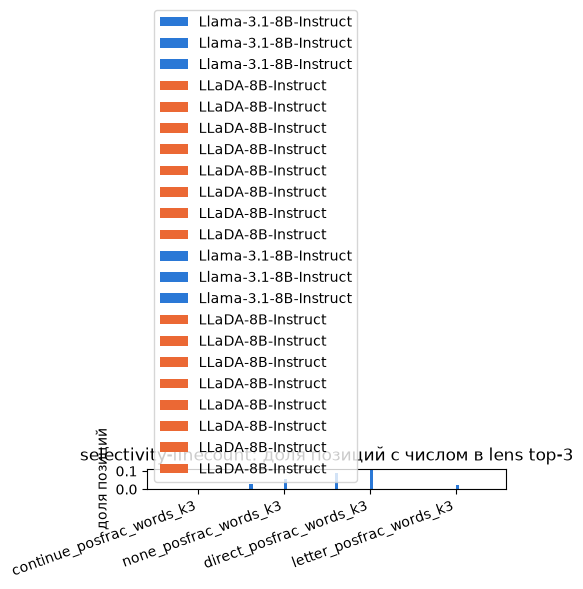

,format,model,variant,passage,condition,base_val,swap_val,cls,baseline_text,swap_text
0,plain,Llama-3.1-8B-Instruct,single,garden,direct,7,7,stay,7 words:\n1.,"7 words: ""Behind"
1,plain,Llama-3.1-8B-Instruct,single,bridge,direct,4,4,stay,"4 words: ""The","4 words: ""The"
4,plain,Llama-3.1-8B-Instruct,logit-lens,garden,direct,7,7,stay,7 words:\n1.,7 words:\n1.
5,plain,Llama-3.1-8B-Instruct,logit-lens,bridge,direct,4,4,stay,"4 words: ""The","4 words: ""The"
8,plain,Llama-3.1-8B-Instruct,tuned-lens,garden,direct,7,7,stay,7 words:\n1.,7 words:\n1.
9,plain,Llama-3.1-8B-Instruct,tuned-lens,bridge,direct,4,5,stay,"4 words: ""The","5 words: ""The"
24,plain,Llama-3.1-8B-Instruct,single,garden,letter,s,s,stay,"""S"".","""S""."
26,plain,Llama-3.1-8B-Instruct,logit-lens,garden,letter,s,s,stay,"""S"".","""S""."
27,plain,Llama-3.1-8B-Instruct,single,bridge,letter,o,t,other,"""O"".","""T""."
30,plain,Llama-3.1-8B-Instruct,tuned-lens,garden,letter,s,f,follow,"""S"".","""F""."


In [27]:
LC_FORMATS = ("plain", "chat")
_saved_format = PROMPT_FORMAT
rows_selectivity_linecount, lc_rdfs, lc_sdfs = [], [], []
for _fmt in LC_FORMATS:
    PROMPT_FORMAT = _fmt
    print(f"===== формат промпта: {_fmt} =====")
    _fmt_rd, _fmt_sd = [], []
    for entry in MODELS:
        if DEBUG_MODE:
            _r, _rd, _sd = run_selectivity_linecount(entry, limit=4, step=8, alphas=(1.0,))
        else:
            _r, _rd, _sd = run_selectivity_linecount(entry, step=4, alphas=(1.0, 2.0))
        for _x in _r:
            _x["format"] = _fmt
        rows_selectivity_linecount += _r
        _rd["model"] = entry["name"]; _sd["model"] = entry["name"]
        _fmt_rd.append(_rd); _fmt_sd.append(_sd)
    for _d in (_fmt_rd, _fmt_sd):
        for _x in _d:
            _x["variant"] = _x["variant"].astype(str); _x["format"] = _fmt
    pd.concat(_fmt_rd, ignore_index=True).to_csv(f"selectivity_linecount_readout_{_fmt}.csv", index=False)
    pd.concat(_fmt_sd, ignore_index=True).to_csv(f"selectivity_linecount_swap_{_fmt}.csv", index=False)
    lc_rdfs += _fmt_rd; lc_sdfs += _fmt_sd
PROMPT_FORMAT = _saved_format
lc_read, lc_swap = pd.concat(lc_rdfs, ignore_index=True), pd.concat(lc_sdfs, ignore_index=True)

record_and_show([{k: v for k, v in r.items()
                  if k.split("_")[0] in ("continue", "none", "direct", "letter", "selectivity") and k.endswith(("_posfrac_words_k3", "_any_words_k3", "selectivity_posfrac_k3"))
                  or k in ("experiment", "model", "variant", "format", "n_items")} for r in rows_selectivity_linecount])

COND_ORDER = ["continue", "none", "direct", "letter"]
def _pv(df, col):
    return df.groupby(["format", "model", "variant", "condition"])[col].mean().unstack("condition").reindex(columns=COND_ORDER).round(3)

print("A. Readout. Доля позиций (после конца первой строки), где хоть одно числительное словом в lens top-3 "
      "(ожидание: continue ~ 0 < direct < letter):")
display(_pv(lc_read, "posfrac_words_k3"))
print("\nДоля пассажей, где такое числительное есть хотя бы на одной позиции (top-3):")
display(_pv(lc_read, "any_words_k3"))
print("\nТо же для top-25:")
display(_pv(lc_read, "posfrac_words_k25"))
if "posfrac_all_k3" in lc_read:
    print("\nLlama, расширенный набор целей (числительные + двузначные токены 10..99), top-3 / top-25:")
    display(pd.concat({"k3": _pv(lc_read.dropna(subset=["posfrac_all_k3"]), "posfrac_all_k3"),
                       "k25": _pv(lc_read.dropna(subset=["posfrac_all_k25"]), "posfrac_all_k25")}, axis=1))
print("\nМедиана ранга ПРАВИЛЬНОГО числительного (десяток первой строки; меньше = лучше) -- не упирается в порог top-k:")
display(lc_read.groupby(["format", "model", "variant", "condition"])["correct_rank"].median().unstack("condition").reindex(columns=COND_ORDER))

print("\nB. Каузальный swap счёта (+20 на всех позициях). Панель a: доля пассажей, где baseline правильный "
      "(direct: число в пределах ±3 символа от истины; letter: верная буква; continue: строка дошла до переноса):")
display(lc_swap.drop_duplicates(["format", "model", "variant", "passage", "condition"])
        .groupby(["format", "model", "variant", "condition"])["base_ok"].mean().unstack("condition").reindex(columns=["direct", "letter", "continue"]).round(2))
print("\nПанель c. Доли исходов swap: count = swap счёта, control = swap несвязанных слов (калибровка вмешательства). "
      "direct/letter: follow = ответ последовал за swap; continue: stay = длина первой строки не изменилась.")
print("-- по ВСЕМ пассажам (названное число сдвинулось, даже если исходный ответ был неверным):")
_a = lc_swap[lc_swap["cls"] != "n/a"]
display(_a.groupby(["format", "model", "variant", "condition", "swap_kind", "alpha"])["cls"]
        .value_counts(normalize=True).unstack("cls").fillna(0).round(2))
print("\n-- только пассажи с верным baseline:")
_ok = _a[_a["base_ok"]]
if len(_ok):
    display(_ok.groupby(["format", "model", "variant", "condition", "swap_kind", "alpha"])["cls"]
            .value_counts(normalize=True).unstack("cls").fillna(0).round(2))
else:
    print("(верных baseline нет ни в одном условии)")

_c = lc_swap[(lc_swap["condition"] == "continue") & lc_swap["nl_p_clean"].notna()] if "nl_p_clean" in lc_swap else lc_swap.iloc[:0]
if len(_c):
    print("\nПеренос строки при продолжении (teacher-forced на токене базового переноса): суммарная вероятность токенов с "
          "переносом, чистый проход / со swap, доля случаев, где решение 'переносить' (P>0.5) не изменилось, и медианное "
          "изменение лог-вероятности базового токена переноса. Если swap счёта не влияет на перенос, count ~ control ~ 0:")
    display(_c.groupby(["format", "model", "variant", "swap_kind", "alpha"]).agg(
        p_clean=("nl_p_clean", "mean"), p_swap=("nl_p_swap", "mean"), kept=("nl_kept", "mean"),
        d_break_logp=("d_break_logp", "median"), n=("passage", "count")).round(3))

plot_bars(rows_selectivity_linecount,
          [f"{c}_posfrac_words_k3" for c in COND_ORDER],
          "selectivity-linecount: доля позиций с числом в lens top-3", ylabel="доля позиций", ylim=None)
pd.set_option("display.max_colwidth", None)
lc_swap[(lc_swap["alpha"] == lc_swap["alpha"].min()) & (lc_swap["swap_kind"] == "count")][
    ["format", "model", "variant", "passage", "condition", "base_val", "swap_val", "cls", "baseline_text", "swap_text"]].head(30)

## Эксперимент 8 -- ignition

**Идея.** Если постепенно "перетекать" от одного понятия к другому (не в тексте, а прямо во
входном эмбеддинге токена), в какой момент внутреннее представление модели резко
"переключается" с одного понятия на другое? Плавный ли это переход, или скорее резкий скачок
(как фазовый переход/"воспламенение" -- отсюда и название ignition)? Это про то, дискретны ли
внутренние представления понятий или непрерывны.

**Протокол (из README).** Берём carrier-предложение с плейсхолдером `{W}` (`ctx_templates` --
40 штук, `noun_ctx_templates` -- ещё 20) и пару понятий A/B (например две страны из
`countries_12` -- все 66 неупорядоченных пар, либо `alt_words`, либо контрольные
`idiom_pairs`/`scrambled_pairs`). Для каждой тройки (carrier, пара A/B, alpha) заменяем
эмбеддинг токена `{W}` на линейную смесь `alpha * emb(A) + (1 - alpha) * emb(B)`, где `alpha`
пробегает сетку от 0 (чистое B) до 1 (чистое A). После этого читаем линзу ровно в позиции `{W}`.

**Как читать метрику:** на каждом alpha считаем "долю reciprocal-rank A" --
`(1/rank(A)) / (1/rank(A) + 1/rank(B))` -- это число от 0 (линза уверенно видит B) до 1
(уверенно видит A). Порог -- значение alpha, где эта доля пересекает 0.5, то есть где A
"перевешивает" B. Если переход резкий (доля быстро прыгает от ~0 к ~1 в узком диапазоне alpha
около 0.5) -- это и есть "ignition": представление ведёт себя как дискретный переключатель, а
не как плавная интерполяция.

**Как это реализовано технически.** Патчим не саму матрицу эмбеддингов (она общая для всех
вхождений токена в последовательности), а output самого embedding-модуля через
`register_forward_hook`, переписывая только один столбец (позицию `{W}`) в его выходном
тензоре -- остальной текст остаётся нетронутым.

**Где раньше был баг.** Позиция `{W}` в полной строке `prefix + a_word + suffix` считалась как
длина ОТДЕЛЬНО токенизированного `prefix` -- а BPE-токенизация не композициональна (последний
токен префикса, обычно кончающийся пробелом, мог слиться с первым символом слова в другой токен
при токенизации полной строки). Именно это уронило первый прогон с `IndexError`. Сейчас позиция
находится через `common_prefix_len` -- по фактической точке расхождения токенов, а не по длине.

**LLaDA-специфика (добавлено при сверке со статьёй).** `w_pos` -- позиция с искусственно
интерполированным эмбеддингом посреди предложения, это не "после контекста" (Type A) и не
"данный заранее текст для восстановления" (Type B) -- содержимое `w_pos` само является
предметом изучения. Заменить его на `[MASK]` нельзя (уничтожит интерполяцию), teacher forcing
тоже неприменим (нет "истинного" содержимого для восстановления). Поэтому для LLaDA здесь
используется НЕ `single_mask_lens`, а `lens_span` (bin3) -- линза, обученная на реальных
диффузионных траекториях, хотя бы видевшая реальный раскрытый контент как source на разных
позициях последовательности, а не только в конце.

---

**Что изменилось по итогам отладки.**

* Добавлены три недостающих семейства пар: `alt_words` и контроли `idiom_pairs` /
  `scrambled_pairs` (раньше брались только `countries_12`, то есть контролей не было вовсе).
* Чтение идёт по ВСЕМ слоям band'а, а не по одному среднему.
* **Главное:** порог и ширина перехода считаются ДЛЯ КАЖДОЙ ПАРЫ отдельно и только потом
  усредняются. README требует именно этого ("A pair's threshold is the alpha where this share
  crosses 0.5... per-layer 10->90% transition width"). Усреднение `share_a` по фиксированному
  $\alpha$ смазывает резкий переход в пологий тем сильнее, чем больше разброс порогов между
  парами: две пары с реальной шириной перехода 0.23 и 0.25, усреднённые по $\alpha$, дают
  видимую ширину 0.92 -- вчетверо шире истинной.

**Почему это важно для интерпретации.** Прежняя "сжатая" кривая LLaDA (0.19 -> 0.81 вместо
0 -> 1) и парадокс "контроль `scrambled` резче, чем `countries`" -- оба могли быть artefact'ом
усреднения, а не свойством моделей. Смотреть теперь следует на `median_width_10_90`
(чем уже, тем резче "воспламенение") и `threshold_spread`.

**Итог по данным последнего прогона и что изменено дальше.**

Выравнивание по парам подтвердило смазывание: межквартильный размах порогов
`threshold_spread` = 0.06--0.24, то есть пары действительно переключаются при разных
$\alpha$ и усреднение по фиксированному $\alpha$ их смешивало.

Но сжатие у LLaDA оказалось **реальным, а не только артефактом усреднения** -- моё прежнее
предположение было верно лишь отчасти. У `bin0`, `bin1`, `single_mask` на семействах
`alt_words` и `idiom` ширина перехода выходила `NaN`: доля `share_a` никогда не пересекает
уровни 0.1 и 0.9, оставаясь примерно в диапазоне 0.19--0.81. Перехода в смысле README там
просто не происходит.

Две правки по итогам:

* **сетка $\alpha$ сгущена с 5 точек до 15**, со сгущением в зоне 0.3--0.7. По шагу 0.25
  ширина 10→90% извлекалась с точностью до четверти диапазона, поэтому разница 0.250 против
  0.346 (контроль `scrambled` против `countries` у Llama) вполне могла быть шумом
  интерполяции, а не свойством данных. Теперь шаг в зоне перехода 0.05. Цена -- втрое больше
  forward pass'ов;
* добавлены `frac_pairs_with_width`, `share_min`, `share_max`. Медиана молча выбрасывает
  `NaN`, из-за чего из таблицы не было видно, что у части пар перехода нет вовсе. Низкая
  `frac_pairs_with_width` важнее маленькой медианы: она означает, что «воспламенение» у этих
  пар не наблюдается, а сжатый `share_min`/`share_max` показывает, что это свойство модели,
  а не шум интерполяции.

**Результат на сгущённой сетке -- парадокс разрешился в ожидаемую сторону, но открыл
более серьёзный вопрос.**

Ширина перехода (`median_width_10_90`, Llama): `countries=0.084 < alt_words=0.127 <
scrambled=0.121 < idiom=0.332` -- на грубой сетке `scrambled` (0.250) казался РЕЗЧЕ
`countries` (0.346); на плотной верное направление восстановилось: осмысленно связанная
пара переключается резче случайного контроля. Прежний парадокс был именно артефактом
грубой интерполяции.

Но `frac_pairs_with_width` вскрыла то, что медиана скрывала: у Llama `idiom` даёт резкий
переход лишь у **42%** пар (`countries`/`alt_words`/`scrambled` -- 92-98%). То есть `idiom` --
не "более пологий контроль", а контроль, где ignition в основном НЕ СЛУЧАЕТСЯ; прежняя
медиана 0.332 считалась только по редким "удавшимся" парам.

У LLaDA то же измерение показывает: резкий переход у ранних бинов почти никогда не
наблюдается (`bin0/countries`: `frac=0.075`), у `bin3` -- чаще, но не всегда
(`bin3/alt_words`: `frac=0.313`). Значит компрессия share_a, которую мы видели на грубой
сетке, -- не искажение усреднения, а тоже реальна: у LLaDA резкое переключение -- более
редкое событие, чем у Llama, и это зависит и от модели, и от семантической связности пары.

**Итог: `ignition` -- не "одна и та же динамика, просто более сжатая у LLaDA".** Правильнее:
резкое переключение -- редкое событие, чья частота систематически зависит от модели и от
типа пары. Стоит смотреть на `frac_pairs_with_width` в первую очередь, `median_width_10_90`
-- только для пар, у которых переход вообще случился.

---

**Добавлено: проекционная мера из статьи (§4.1.1, Fig. 29B-C, §A.15, Fig. 70-71).** Всё выше измеряет воспламенение через
rank-share J-линзы. Основной результат статьи -- другой и **без линзы**: для каждого испытания и слоя берётся активация в
позиции смешанного токена и считается, где она лежит на прямой между активациями чистого B (alpha=0) и чистого A
(alpha=1) в той же позиции и слое: `share = (h-hB)·(hA-hB)/|hA-hB|²`. В ранних слоях share плавно следует за alpha, начиная
примерно с трети глубины (onset workspace) -- резко прыгает у порога. Затем то же для компоненты активации в плоскости
двух J-lens направлений (`J-space/<линза>`, только слои band). Новые величины:

* **ширина перехода 10->90% по слоям** (Fig. 70): ожидание -- большая в ранних слоях, резкое падение до onset, у J-space не шире
  полной активации; `family=scrambled` -- контроль;
* **доля "определившихся" прогонов при максимально неоднозначном alpha** (Fig. 71): для каждой пары и слоя берётся alpha, где
  средний share ближе всего к 0.5, и смотрится на share отдельных прогонов (разные carrier'ы). Если активация просто отражает смесь, все
  ≈0.5; если принимает решение -- кучкуются около 0 и 1 (определился = share<0.2 или >0.8).

Зачем: ответить, сжатие кривой у LLaDA -- свойство самих активаций (нет резкого переключения вообще) или только того, как их читает
линза в позиции без [MASK]. Если полная активация LLaDA переключается резко, а линза нет -- проблема в чтении, а не в модели.
DEBUG_MODE: 6 пар x 2 carrier'а, иначе 16 пар x 4 carrier'а. Файлы: `ignition_projection_widths.csv`,
`ignition_projection_bimodality.csv`.

**Baseline'ы.** Ignition и проекции считаются и для baseline-линз (`variant = logit-lens/<family>`): кривая «порог по alpha» для logit-lens показывает, насколько ignition вообще зависит от якобиана.

**Число пар.** `IGNITION_N_PAIRS` (ячейка конфигурации): итоговый прогон (`DEBUG_MODE=False`) берёт все 66 неупорядоченных пар стран из README (`countries_12`), отладка -- 20.


In [28]:
def _embedding_module(entry):
    if entry["name"].startswith("LLaDA"):
        return entry["hf"].model.transformer.wte
    return entry["hf"].model.embed_tokens

def run_ignition(entry, limit=N_ITEMS_LIMIT,
                 alphas=(0.0, 0.1, 0.2, 0.3, 0.35, 0.4, 0.45, 0.5,
                         0.55, 0.6, 0.65, 0.7, 0.8, 0.9, 1.0),
                 n_trials=40):
    model, tok, band = entry["model"], entry["tokenizer"], entry["band"]
    lenses = all_llada_lenses(entry)
    data = json.load(open(EXPERIMENTS_DIR / "ignition.json"))
    ctx_templates = data["ctx_templates"] + data["noun_ctx_templates"]
    embed = _embedding_module(entry)

    countries = data["countries_12"]
    pair_families = {
        "countries": [(a, b) for i, a in enumerate(countries) for b in countries[i + 1:]],
        "alt_words": [(w, "France") for w in data["alt_words"]],
        "idiom": [tuple(p) for p in data["idiom_pairs"]],
        "scrambled": [tuple(p) for p in data["scrambled_pairs"]],
    }

    rng = random.Random(seed)
    rows = []
    for fam, fam_pairs in pair_families.items():
        n = n_trials if not limit else limit
        trials = rng.sample(fam_pairs, min(n, len(fam_pairs)))
        def _pjob(_job):
            (a_word, b_word, carrier) = _job
            model, tok, band = entry["model"], entry["tokenizer"], entry["band"]
            embed = _embedding_module(entry)
            a_id = single_token_id(tok, " " + a_word)
            b_id = single_token_id(tok, " " + b_word)
            if a_id is None or b_id is None:
                return
            prefix, _, suffix = carrier.partition("{W}")
            text = prefix + a_word + suffix
            ids = text_ids(tok, text)
            w_pos = common_prefix_len(tok, ids, prefix)
            if w_pos >= ids.shape[1]:
                return

            emb_a = embed.weight[a_id].float()
            emb_b = embed.weight[b_id].float()

            for alpha in alphas:
                mix = (alpha * emb_a + (1 - alpha) * emb_b).to(embed.weight.dtype)

                def hook(module, inputs, output, mix=mix, w_pos=w_pos):
                    output = output.clone()
                    output[:, w_pos, :] = mix
                    return output

                handle = embed.register_forward_hook(hook)
                try:
                    acts, _ = record_residuals(model, ids, band)
                finally:
                    handle.remove()

                for variant, lens in lenses.items():
                    for layer in band:
                        rank_a = lens_rank(model, lens, acts, layer, w_pos, a_id) or 10_000
                        rank_b = lens_rank(model, lens, acts, layer, w_pos, b_id) or 10_000
                        share_a = (1 / rank_a) / (1 / rank_a + 1 / rank_b)
                        rows.append({"family": fam, "pair": f"{a_word}|{b_word}",
                                     "carrier": carrier, "variant": variant, "layer": layer,
                                     "alpha": alpha, "share_a": share_a})
        pmap(_pjob, list([(a, b, rng.choice(ctx_templates)) for a, b in trials]), desc=f"ignition/{fam} [{entry['name']}]")

    df = pd.DataFrame(rows)

    def _cross(alphas_sorted, shares, level):
        """alpha, при котором share пересекает level (линейная интерполяция)."""
        for (a0, s0), (a1, s1) in zip(zip(alphas_sorted, shares), list(zip(alphas_sorted, shares))[1:]):
            if (s0 - level) * (s1 - level) <= 0 and s1 != s0:
                return a0 + (level - s0) * (a1 - a0) / (s1 - s0)
        return None

    per_pair = []
    for (fam, variant, pair, carrier), g in df.groupby(["family", "variant", "pair", "carrier"]):
        g = g.groupby("alpha")["share_a"].mean().sort_index()
        al, sh = list(g.index), list(g.values)
        thr = _cross(al, sh, 0.5)
        a10, a90 = _cross(al, sh, 0.1), _cross(al, sh, 0.9)
        per_pair.append({"family": fam, "variant": variant, "pair": pair,
                         "threshold": thr,
                         "width_10_90": (a90 - a10) if (a10 is not None and a90 is not None) else None})
    per_pair_df = pd.DataFrame(per_pair)

    out_rows = []
    for variant in df["variant"].unique():
        for fam in df["family"].unique():
            sub_vf = df[(df["variant"] == variant) & (df["family"] == fam)]
            if not len(sub_vf):
                continue
            out = {"experiment": "ignition", "model": entry["name"],
                   "variant": f"{variant}/{fam}", "n_items": sub_vf["alpha"].count() // (len(alphas) * len(band))}
            for alpha in alphas:
                out[f"share_a@alpha={alpha}"] = sub_vf[sub_vf["alpha"] == alpha]["share_a"].mean()
            pp = per_pair_df[(per_pair_df["variant"] == variant) & (per_pair_df["family"] == fam)]
            out["median_threshold"] = pp["threshold"].median() if len(pp) else None
            out["threshold_spread"] = (pp["threshold"].quantile(0.75) - pp["threshold"].quantile(0.25)) if len(pp) else None
            out["median_width_10_90"] = pp["width_10_90"].median() if len(pp) else None
            out["n_pairs_with_threshold"] = int(pp["threshold"].notna().sum()) if len(pp) else 0
            out["frac_pairs_with_width"] = (pp["width_10_90"].notna().mean() if len(pp) else None)
            out["share_min"] = sub_vf["share_a"].min() if len(sub_vf) else None
            out["share_max"] = sub_vf["share_a"].max() if len(sub_vf) else None
            out_rows.append(out)
    return out_rows, df

def _ign_cross(xs, ys, level):
    """x, при котором ys первый раз пересекает level (линейная интерполяция); None, если пересечения нет."""
    pts = list(zip(xs, ys))
    for (x0, y0), (x1, y1) in zip(pts, pts[1:]):
        if (y0 - level) * (y1 - level) <= 0 and y1 != y0:
            return x0 + (level - y0) * (x1 - x0) / (y1 - y0)
    return None

def run_ignition_projection(entry, alphas, families=("countries", "scrambled"), n_pairs=16, n_carriers=4, seed=0):
    """Возвращает long-df: family, pair, carrier, alpha, layer, kind, share. kind = "activation" (вся активация) или
    "J-space/<линза>" (компонента в плоскости двух J-lens направлений, только слои band)."""
    model, tok, band = entry["model"], entry["tokenizer"], entry["band"]
    lenses = all_llada_lenses(entry)
    data = json.load(open(EXPERIMENTS_DIR / "ignition.json"))
    carriers = data["ctx_templates"] + data["noun_ctx_templates"]
    countries = data["countries_12"]
    fams = {"countries": [(a, b) for i, a in enumerate(countries) for b in countries[i + 1:]],
            "scrambled": [tuple(p) for p in data["scrambled_pairs"]]}
    embed = _embedding_module(entry)
    layers = list(range(model.n_layers))
    rng = random.Random(seed)
    rows = []
    for fam in families:
        def _pjob(_job):
            (a_word, b_word, carriers_pick) = _job
            model, tok, band = entry["model"], entry["tokenizer"], entry["band"]
            embed = _embedding_module(entry)
            a_id, b_id = single_token_id(tok, " " + a_word), single_token_id(tok, " " + b_word)
            if a_id is None or b_id is None:
                return
            pair = f"{a_word}|{b_word}"
            emb_a, emb_b = embed.weight[a_id].float(), embed.weight[b_id].float()
            pinv = {}
            for v, lens in lenses.items():
                d = token_directions_batch(model, lens, band, [a_id, b_id])
                for l in band:
                    M = np.stack([d[l][0].float().cpu().numpy(), d[l][1].float().cpu().numpy()], axis=1)
                    pinv[(v, l)] = np.linalg.pinv(M)
            for ci, carrier in enumerate(carriers_pick):
                prefix, _, suffix = carrier.partition("{W}")
                ids = text_ids(tok, prefix + a_word + suffix)
                w_pos = common_prefix_len(tok, ids, prefix)
                if w_pos >= ids.shape[1]:
                    continue
                H = []
                for alpha in alphas:
                    mix = (alpha * emb_a + (1 - alpha) * emb_b).to(embed.weight.dtype)

                    def hook(module, inputs, output, mix=mix, w_pos=w_pos):
                        output = output.clone()
                        output[:, w_pos, :] = mix
                        return output

                    handle = embed.register_forward_hook(hook)
                    try:
                        acts, _ = record_residuals(model, ids, layers)
                    finally:
                        handle.remove()
                    H.append(np.stack([acts[l][w_pos].float().cpu().numpy() for l in layers]))
                H = np.stack(H)
                hB, dv = H[0], H[-1] - H[0]
                full = ((H - hB) * dv).sum(-1) / np.maximum((dv ** 2).sum(-1), 1e-12)
                for ai, alpha in enumerate(alphas):
                    for l in layers:
                        rows.append((fam, pair, ci, alpha, l, "activation", float(full[ai, l])))
                for v in lenses:
                    for l in band:
                        C = H[:, l, :] @ pinv[(v, l)].T
                        dc = C[-1] - C[0]
                        sh = ((C - C[0]) @ dc) / max(float((dc ** 2).sum()), 1e-12)
                        for ai, alpha in enumerate(alphas):
                            rows.append((fam, pair, ci, alpha, l, f"J-space/{v}", float(sh[ai])))
        pmap(_pjob, list([(a, b, rng.sample(carriers, min(n_carriers, len(carriers))))
                 for a, b in rng.sample(fams[fam], min(n_pairs, len(fams[fam])))]), desc=f"ignition-projection/{fam} [{entry['name']}]")
    return pd.DataFrame(rows, columns=["family", "pair", "carrier", "alpha", "layer", "kind", "share"])

def summarize_ignition_projection(proj, commit=0.2):
    """Ширина перехода 10->90% по слоям (Fig. 70) и доля 'определившихся' прогонов при максимально неоднозначном alpha
    (Fig. 71: для каждой пары и слоя берём alpha, где средний по carrier'ам share ближе всего к 0.5, и смотрим на share
    отдельных прогонов; определился = share < commit или > 1 - commit; при идеальном отражении смеси все были бы ~0.5)."""
    wid = []
    for (kind, fam, pair, ci, layer), g in proj.groupby(["kind", "family", "pair", "carrier", "layer"]):
        g = g.sort_values("alpha")
        a10, a90 = _ign_cross(g["alpha"].values, g["share"].values, 0.1), _ign_cross(g["alpha"].values, g["share"].values, 0.9)
        wid.append({"kind": kind, "family": fam, "pair": pair, "carrier": ci, "layer": layer,
                    "threshold": _ign_cross(g["alpha"].values, g["share"].values, 0.5),
                    "width": (a90 - a10) if (a10 is not None and a90 is not None) else np.nan})
    wid = pd.DataFrame(wid)
    m = proj.groupby(["kind", "family", "pair", "layer", "alpha"])["share"].mean().reset_index()
    m["gap"] = (m["share"] - 0.5).abs()
    amb = m.loc[m.groupby(["kind", "family", "pair", "layer"])["gap"].idxmin(), ["kind", "family", "pair", "layer", "alpha"]]
    at = proj.merge(amb, on=["kind", "family", "pair", "layer", "alpha"])
    at["committed"] = ((at["share"] < commit) | (at["share"] > 1 - commit)).astype(float)
    bim = at.groupby(["kind", "family", "layer"])["committed"].mean().reset_index()
    return wid, bim

ignition/countries [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 66/66 [01:01<00:00,  1.07it/s]
ignition/alt_words [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 16/16 [00:15<00:00,  1.06it/s]
ignition/idiom [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 12/12 [00:11<00:00,  1.08it/s]
ignition/scrambled [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 12/12 [00:10<00:00,  1.10it/s]
ignition/scrambled [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 12/12 [00:20<00:00,  1.68s/it]


,experiment,model,variant,n_items,share_a@alpha=0.0,share_a@alpha=0.1,share_a@alpha=0.2,share_a@alpha=0.3,share_a@alpha=0.35,share_a@alpha=0.4,...,share_a@alpha=0.8,share_a@alpha=0.9,share_a@alpha=1.0,median_threshold,threshold_spread,median_width_10_90,n_pairs_with_threshold,frac_pairs_with_width,share_min,share_max
0,ignition,Llama-3.1-8B-Instruct,single/countries,66,0.014172,0.015362,0.017435,0.022375,0.028533,0.045937,...,0.985671,0.987456,0.988584,0.505387,0.043345,0.086245,66,0.954545,0.000043,0.999975
1,ignition,Llama-3.1-8B-Instruct,single/alt_words,16,0.009961,0.010493,0.011509,0.013941,0.016363,0.022375,...,0.925156,0.934649,0.938394,0.530212,0.075778,0.108574,16,0.812500,0.000013,0.999982
2,ignition,Llama-3.1-8B-Instruct,single/idiom,12,0.172369,0.181986,0.203769,0.236790,0.279122,0.364075,...,0.911648,0.922811,0.929042,0.434895,0.129042,0.366444,12,0.333333,0.000278,0.999883
3,ignition,Llama-3.1-8B-Instruct,single/scrambled,12,0.049201,0.053848,0.059546,0.071392,0.088859,0.136650,...,0.986240,0.987019,0.987351,0.469353,0.036934,0.117266,12,0.833333,0.000010,0.999991
4,ignition,Llama-3.1-8B-Instruct,logit-lens/countries,66,0.145984,0.145918,0.145582,0.146874,0.149818,0.160846,...,0.845407,0.846802,0.847651,0.515237,0.053335,0.195833,62,0.136364,0.000008,0.999992
5,ignition,Llama-3.1-8B-Instruct,logit-lens/alt_words,16,0.080278,0.080009,0.079582,0.079943,0.082046,0.088509,...,0.856245,0.860508,0.862888,0.530827,0.061537,0.319689,16,0.125000,0.000011,0.999968
6,ignition,Llama-3.1-8B-Instruct,logit-lens/idiom,12,0.231498,0.238824,0.254216,0.284810,0.311717,0.360076,...,0.738080,0.740946,0.740504,0.440649,0.106598,0.103705,11,0.083333,0.000016,0.999974
7,ignition,Llama-3.1-8B-Instruct,logit-lens/scrambled,12,0.111899,0.115014,0.121209,0.131603,0.142736,0.165816,...,0.857240,0.860006,0.861322,0.470874,0.035378,0.136536,12,0.333333,0.000009,0.999991
8,ignition,Llama-3.1-8B-Instruct,tuned-lens/countries,66,0.141289,0.141595,0.141745,0.144053,0.148271,0.161847,...,0.848613,0.850248,0.851392,0.504983,0.044458,0.207382,62,0.212121,0.000014,0.999951
9,ignition,Llama-3.1-8B-Instruct,tuned-lens/alt_words,16,0.137666,0.136236,0.134858,0.133072,0.133878,0.138761,...,0.891816,0.896374,0.899033,0.533039,0.054463,0.188481,16,0.250000,0.000262,0.999947


/tmp/ipykernel_83128/1845304935.py:52: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


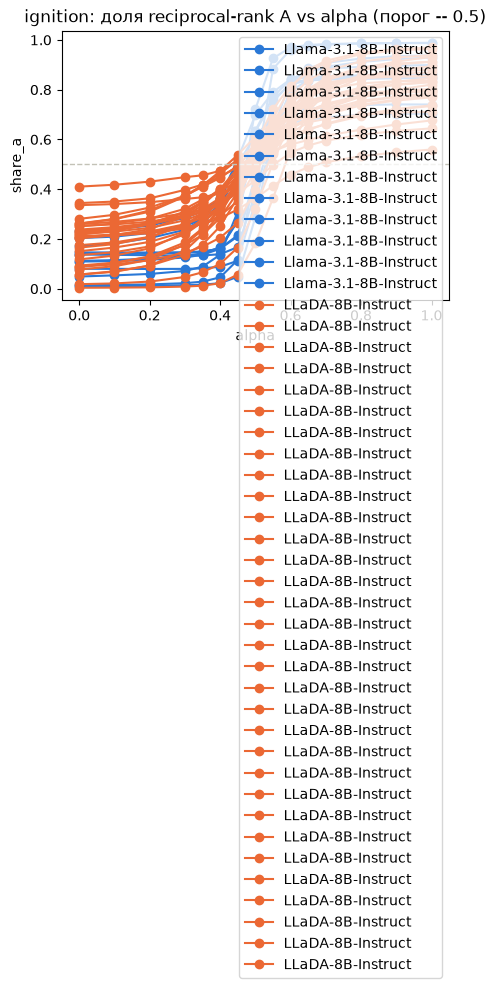

                model               variant  median_threshold  threshold_spread  median_width_10_90  frac_pairs_with_width  share_min  share_max
Llama-3.1-8B-Instruct      single/countries          0.505387          0.043345            0.086245               0.954545   0.000043   0.999975
Llama-3.1-8B-Instruct      single/alt_words          0.530212          0.075778            0.108574               0.812500   0.000013   0.999982
Llama-3.1-8B-Instruct          single/idiom          0.434895          0.129042            0.366444               0.333333   0.000278   0.999883
Llama-3.1-8B-Instruct      single/scrambled          0.469353          0.036934            0.117266               0.833333   0.000010   0.999991
Llama-3.1-8B-Instruct  logit-lens/countries          0.515237          0.053335            0.195833               0.136364   0.000008   0.999992
Llama-3.1-8B-Instruct  logit-lens/alt_words          0.530827          0.061537            0.319689               0.125000   0.000

ignition-projection/countries [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 16/16 [00:35<00:00,  2.21s/it]
ignition-projection/scrambled [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 12/12 [00:27<00:00,  2.26s/it]
ignition-projection/countries [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 16/16 [00:30<00:00,  1.91s/it]
ignition-projection/scrambled [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 12/12 [00:23<00:00,  1.94s/it]


Ширина перехода 10->90% (медиана по прогонам, family=countries) на выбранных слоях; меньше = резче. Ожидание (статья): широкая в ранних слоях, резкое падение до onset workspace, J-space не шире полной активации:

LLaDA-8B-Instruct: band = слои 8..27 из 32


layer,0,4,8,12,16,19,23,27,31
kind,,,,,,,,,
J-space/0,NaN,NaN,0.593,0.578,0.497,0.460,0.358,0.206,NaN
J-space/1,NaN,NaN,0.609,0.588,0.528,0.485,0.348,0.202,NaN
J-space/2,NaN,NaN,0.618,0.587,0.537,0.515,0.354,0.204,NaN
J-space/3,NaN,NaN,0.619,0.583,0.523,0.496,0.394,0.213,NaN
J-space/logit-lens,NaN,NaN,0.649,0.601,0.553,0.603,0.469,0.266,NaN
J-space/merged,NaN,NaN,0.617,0.586,0.526,0.500,0.383,0.207,NaN
J-space/single_mask,NaN,NaN,0.513,0.516,0.416,0.373,0.312,0.180,NaN
J-space/tuned-lens,NaN,NaN,0.644,0.598,0.533,0.588,0.474,0.263,NaN
activation,0.744,0.729,0.673,0.654,0.602,0.582,0.537,0.312,0.266


доля прогонов, где переход вообще наблюдается (share доходит и до 0.1, и до 0.9):


layer,0,4,8,12,16,19,23,27,31
kind,,,,,,,,,
J-space/0,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,NaN
J-space/1,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,NaN
J-space/2,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,NaN
J-space/3,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,NaN
J-space/logit-lens,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,NaN
J-space/merged,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,NaN
J-space/single_mask,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,NaN
J-space/tuned-lens,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,NaN
activation,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0



Llama-3.1-8B-Instruct: band = слои 8..27 из 32


layer,0,4,8,12,16,19,23,27,31
kind,,,,,,,,,
J-space/logit-lens,NaN,NaN,0.321,0.258,0.166,0.111,0.091,0.081,NaN
J-space/single,NaN,NaN,0.348,0.297,0.197,0.134,0.105,0.088,NaN
J-space/tuned-lens,NaN,NaN,0.324,0.257,0.165,0.112,0.091,0.082,NaN
activation,0.783,0.637,0.461,0.438,0.323,0.273,0.211,0.202,0.205


доля прогонов, где переход вообще наблюдается (share доходит и до 0.1, и до 0.9):


layer,0,4,8,12,16,19,23,27,31
kind,,,,,,,,,
J-space/logit-lens,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,NaN
J-space/single,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,NaN
J-space/tuned-lens,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,NaN
activation,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


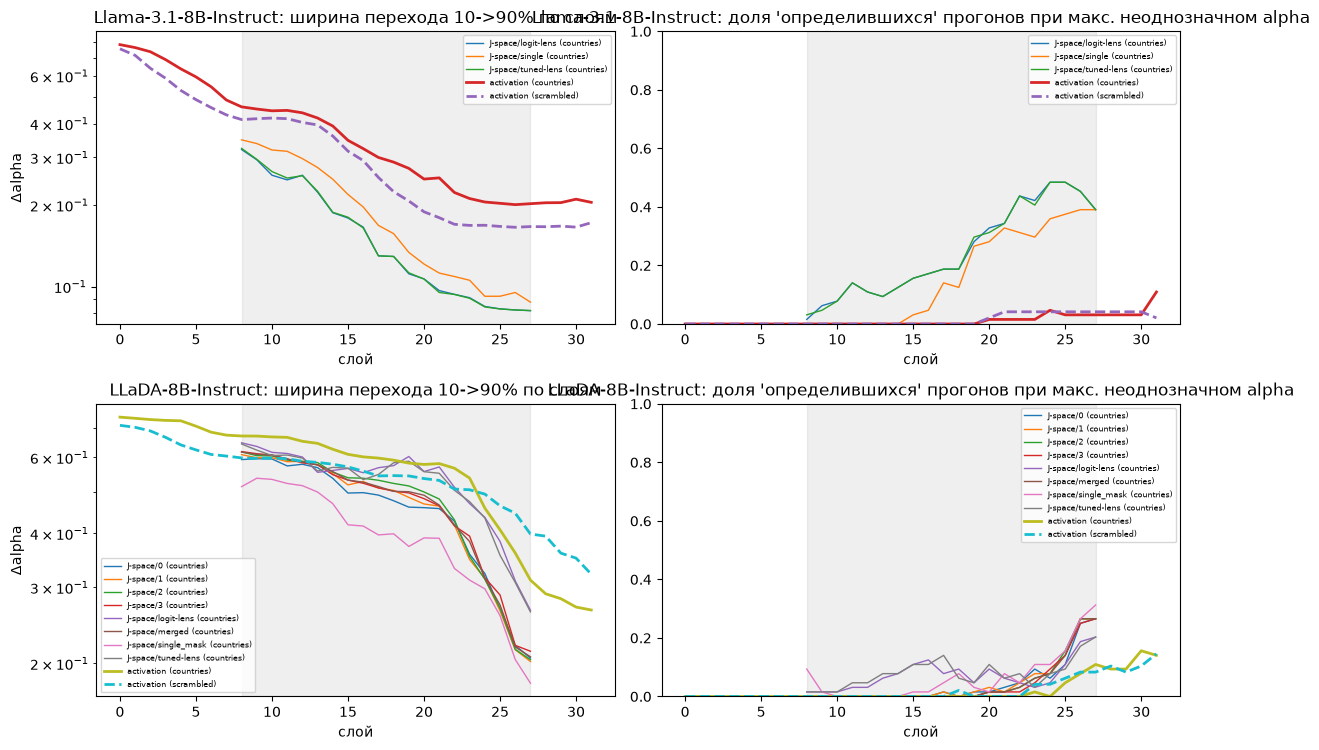

In [29]:
alphas_ign = (0.0, 0.1, 0.2, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.8, 0.9, 1.0)
rows_ignition = []
layer_dfs_ignition = []
for entry in MODELS:
    out_rows, layer_df = run_ignition(entry, alphas=alphas_ign, n_trials=IGNITION_N_PAIRS)
    rows_ignition.extend(out_rows)
    layer_df = layer_df.copy()
    layer_df["model"] = entry["name"]
    layer_dfs_ignition.append(layer_df)
ignition_layer_table = pd.concat(layer_dfs_ignition, ignore_index=True)

record_and_show(rows_ignition)
plot_lines(
    rows_ignition, alphas_ign, lambda a: f"share_a@alpha={a}",
    "ignition: доля reciprocal-rank A vs alpha (порог -- 0.5)",
    xlabel="alpha", ylabel="share_a", hline=0.5,
)

print(pd.DataFrame(rows_ignition)[
    ["model", "variant", "median_threshold", "threshold_spread",
     "median_width_10_90", "frac_pairs_with_width", "share_min", "share_max"]
].to_string(index=False))

ign_proj = []
for entry in MODELS:
    _n_pairs, _n_car = (6, 2) if DEBUG_MODE else (16, 4)
    _p = run_ignition_projection(entry, alphas_ign, n_pairs=_n_pairs, n_carriers=_n_car)
    _p["model"] = entry["name"]
    ign_proj.append(_p)
ign_proj = pd.concat(ign_proj, ignore_index=True)

ign_w, ign_b = [], []
for _m, _g in ign_proj.groupby("model"):
    _w, _b = summarize_ignition_projection(_g)
    _w["model"] = _m; _b["model"] = _m
    ign_w.append(_w); ign_b.append(_b)
ign_w, ign_b = pd.concat(ign_w, ignore_index=True), pd.concat(ign_b, ignore_index=True)
ign_w.to_csv("ignition_projection_widths.csv", index=False)
ign_b.to_csv("ignition_projection_bimodality.csv", index=False)

_bands = {e["name"]: (min(e["band"]), max(e["band"])) for e in MODELS}
_nl = {e["name"]: e["model"].n_layers for e in MODELS}
print("Ширина перехода 10->90% (медиана по прогонам, family=countries) на выбранных слоях; меньше = резче. "
      "Ожидание (статья): широкая в ранних слоях, резкое падение до onset workspace, J-space не шире полной активации:")
for _m in ign_w["model"].unique():
    _sel = sorted(set(np.linspace(0, _nl[_m] - 1, 9).round().astype(int)) | set(_bands[_m]))
    _t = (ign_w[(ign_w["model"] == _m) & (ign_w["family"] == "countries") & ign_w["layer"].isin(_sel)]
          .groupby(["kind", "layer"])["width"].median().unstack("layer").round(3))
    print(f"\n{_m}: band = слои {_bands[_m][0]}..{_bands[_m][1]} из {_nl[_m]}")
    display(_t)
    _f = (ign_w[(ign_w["model"] == _m) & (ign_w["family"] == "countries") & ign_w["layer"].isin(_sel)]
          .groupby(["kind", "layer"])["width"].apply(lambda s: s.notna().mean()).unstack("layer").round(2))
    print("доля прогонов, где переход вообще наблюдается (share доходит и до 0.1, и до 0.9):")
    display(_f)

fig, axes = plt.subplots(len(MODELS), 2, figsize=(12, 3.8 * len(MODELS)), squeeze=False)
for mi, entry in enumerate(MODELS):
    _m = entry["name"]
    ax = axes[mi][0]
    for (_k, _fam), _g in ign_w[ign_w["model"] == _m].groupby(["kind", "family"]):
        if _fam == "scrambled" and _k != "activation":
            continue
        _c = _g.groupby("layer")["width"].median()
        ax.plot(_c.index, _c.values, lw=2 if _k == "activation" else 1, ls="--" if _fam == "scrambled" else "-",
                label=f"{_k} ({_fam})")
    ax.axvspan(*_bands[_m], color="gray", alpha=0.12); ax.set_yscale("log")
    ax.set_title(f"{_m}: ширина перехода 10->90% по слоям"); ax.set_xlabel("слой"); ax.set_ylabel("Δalpha"); ax.legend(fontsize=6)
    ax = axes[mi][1]
    for (_k, _fam), _g in ign_b[ign_b["model"] == _m].groupby(["kind", "family"]):
        if _fam == "scrambled" and _k != "activation":
            continue
        ax.plot(_g["layer"], _g["committed"], lw=2 if _k == "activation" else 1, ls="--" if _fam == "scrambled" else "-",
                label=f"{_k} ({_fam})")
    ax.axvspan(*_bands[_m], color="gray", alpha=0.12)
    ax.set_title(f"{_m}: доля 'определившихся' прогонов при макс. неоднозначном alpha"); ax.set_xlabel("слой"); ax.set_ylim(0, 1); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

## Эксперимент 9 -- capacity

**Идея.** У "рабочей памяти" человека есть известный предел (около 7±2 элементов). Есть ли похожий предел у
того, что J-lens одновременно видит в скрытом состоянии модели? Модели последовательно показывают список из 80 слов
через запятую; после каждой запятой читаем линзу и считаем, сколько слов имеют лучший ранг по band не хуже K=25.

**Что сравнивается (как в статье, Fig 31).** Три условия на одних и тех же материалах:
- `blocked` -- 4 блока по 20 слов (имена, фамилии, страны, города), порядок блоков случаен (Fig 31E,F);
- `random` -- *те же* 80 слов, но перемешанные (контроль на порядок слов; НЕ несвязанный список: в нём одновременно живут четыре
  категории, и в первом прогоне он оказался выше `blocked`);
- `unrelated` -- 80 слов из ~50 разных категорий, не более 2 на категорию (Fig 31B, синий, настоящие "несвязанные" слова);
- `family` -- 80 слов ОДНОЙ семьи (по испытаниям вращаем семью; Fig 31B, оранжевый).
`unrelated` строится из категорий directed-modulation, dual-task, контрольных слов и ещё ~24 мелких категорий (мебель, инструменты, транспорт, ...); категории всё же не бесконечно разные, но
по 2 слова на категорию -- это ближе к "произвольным" спискам статьи, чем смесь четырёх семей.

**Метрики** (K=25, band-min): `mean_present_read` -- прочитанные слова, усреднённо по запятым; `present_read_last` -- то
же на последней запятой (плато = "объём"); `present_read_n11` / `present_all_n11` -- на 11-й запятой: прочитанные слова и ВСЕ 80 слов списка, включая ещё не
прочитанные (пунктир на Fig 31B: у связанных списков в readout попадает вся семья, ещё не будучи прочитанной -- модель держит
*категорию*, а не слова; на последней запятой прочитано всё, поэтому там эти две величины совпадают по построению); `ctrl_present_last` -- контрольные слова, которых нет в промпте и чья категория (цвета, животные,
части тела, одежда) в списках не встречается (серые на Fig 31C -- шкала "случайного" попадания в top-25 по band);
`frac_read_last` -- доля прочитанных слов в readout.

**Ожидание (статья).** `random`: около 6 слов из прочитанных (по всему band), плато, дальние слова выпадают;
`family`/`blocked` внутри блока: практически вся семья присутствует уже после нескольких слов, включая непрочитанные
(`present_all_n11` >> `present_read_n11`); при смене категории предыдущий блок вытесняется за несколько слов
(график "смена категории": доля слов прежнего блока падает с ростом `j`, доля текущего растёт). Результат не должен
сильно зависеть от K (график "порог K").

**Файлы.** `capacity_trials.csv` -- подробная таблица (по запятым: `pr_K` -- прочитанные, `pa_K` -- все 80, `pc_K` --
контроль, для K в 5/10/25/50/100/250; `block`, `j`, `cur_read_k`, `prev_k` -- для вытеснения). Присылайте её.

**Исправления относительно прошлой версии.** (1) Список строго 80 слов (раньше из JSON читалось 100 слов на семью и
получалось до 400). (2) Слова блока сэмплируются из канона заново на каждом испытании. (3) Канон -- только слова, у которых
`" "+слово` ровно один токен (раньше был запасной вариант без пробела, а в тексте слово всегда идёт после ", ", так что id
не совпадал с токеном в промпте); перед первым словом добавлен пробел. (4) Список с несовпавшим числом запятых и слов
пропускается, а не читается со сдвигом. (5) Добавлены условия `random`/`family`, контрольные слова, "все 80", вытеснение и
свёртка по K -- без них статья не воспроизводилась: прежняя версия мерила только `blocked` и не имела базовой линии.

**LLaDA.** Чтение через усечение списка до прочитанной части + одна `[MASK]` после запятой (маска стоит на позиции
следующего слова -- тот же токен предсказывает Llama на запятой); одна линза -- одна строка в таблице, как и раньше все
шесть. Это даёт один forward на запятую на условие, поэтому эксперимент остаётся одним из самых медленных:
~9 запятых (step=10) + 12 в `blocked` (первые слова после смены блока) ≈ 4 условия x 10-21 forward на испытание.
Для быстрой проверки снижайте `n_trials`.

**Baseline'ы.** Baseline'ы добавлены в графики пунктиром (`-.` logit-lens, точечный -- tuned-lens) и в `cap_summary`.

**Шаг по запятым.** `CAPACITY_STEP` (ячейка конфигурации): итоговый прогон (`DEBUG_MODE=False`) читает КАЖДУЮ запятую (`step=1`, все 80), отладка -- каждую 10-ю.


In [30]:
_CAP_CTRL = {
    "colors":  ["red", "blue", "green", "yellow", "black", "white", "orange", "purple", "pink", "brown", "gray", "gold"],
    "animals": ["dog", "cat", "horse", "cow", "pig", "sheep", "lion", "tiger", "bear", "wolf", "fox", "rabbit"],
    "body":    ["hand", "foot", "head", "arm", "leg", "eye", "ear", "nose", "mouth", "finger", "knee", "heart"],
    "clothes": ["shirt", "shoe", "hat", "coat", "dress", "sock", "belt", "glove", "scarf", "jacket", "boot", "skirt"],
}
_CAP_EXTRA_CATS = {
    "furniture": ["chair", "table", "bed", "desk", "sofa", "shelf"], "tools": ["hammer", "saw", "drill", "wrench", "axe", "pliers"],
    "vehicles": ["car", "bus", "train", "truck", "plane", "bike"], "professions": ["doctor", "teacher", "lawyer", "farmer", "pilot", "nurse"],
    "sports": ["soccer", "tennis", "golf", "hockey", "rugby", "boxing"], "rooms": ["kitchen", "garage", "attic", "hallway", "bedroom", "basement"],
    "fruits": ["apple", "banana", "grape", "cherry", "peach", "plum"], "drinks": ["coffee", "tea", "milk", "juice", "wine", "beer"],
    "buildings": ["church", "school", "hospital", "castle", "museum", "library"], "landforms": ["river", "mountain", "valley", "desert", "island", "forest"],
    "materials": ["wood", "steel", "glass", "plastic", "leather", "cotton"], "food": ["bread", "cheese", "rice", "pasta", "butter", "sugar"],
    "birds": ["eagle", "owl", "sparrow", "crow", "falcon", "swan"], "fish": ["salmon", "tuna", "trout", "cod", "shark", "eel"],
    "flowers": ["rose", "tulip", "daisy", "lily", "orchid", "violet"], "family": ["mother", "father", "sister", "brother", "uncle", "cousin"],
    "times of day": ["morning", "evening", "midnight", "noon", "dawn", "dusk"], "money": ["dollar", "euro", "coin", "penny", "cash", "wallet"],
    "school subjects": ["math", "history", "physics", "biology", "chemistry", "geography"], "electronics": ["phone", "laptop", "camera", "radio", "screen", "keyboard"],
    "stationery": ["pencil", "paper", "eraser", "ruler", "notebook", "marker"], "jewelry": ["ring", "necklace", "bracelet", "earring", "crown", "pendant"],
    "music genres": ["jazz", "rock", "blues", "opera", "country", "reggae"],
}
_CAP_KS = (5, 10, 25, 50, 100, 250)

def _cap_counts(ranks, ids, ks=_CAP_KS):
    """{k: сколько из ids имеют ранг <= k}; ранг None (слово не нашлось) считается как 'не виден'."""
    rs = [ranks.get(t) or 10**9 for t in ids]
    return {k: sum(1 for r in rs if r <= k) for k in ks}

def _cap_canons(tok, data, per_block):
    """Канон семьи = первые targets_per_family[fam] слов пула, у которых " "+слово -- ровно ОДИН токен.
    FIXED: раньше был запасной вариант single_token_id(w) без пробела, но в тексте списка слово всегда стоит после
    ", " (токен с ведущим пробелом) -- id слова без пробела не совпадал с тем, что реально лежит в тексте."""
    pools = {p["name"]: p["pool"] for p in data["candidate_pools"]}
    tpf = data["targets_per_family"]
    canons = {}
    for fam in data["block_families"]:
        canon = []
        for w in pools.get(fam, []):
            tid = single_token_id(tok, " " + w)
            if tid is not None and tid not in {t for _, t in canon}:
                canon.append((w, tid))
            if len(canon) >= tpf.get(fam, per_block):
                break
        canons[fam] = canon
    return canons

def _cap_unrelated_pool(tok, data_dir=None):
    """Слова из МНОГИХ разных категорий для условия `unrelated` (аналог 'несвязанных' списков статьи, Fig 31B, синий).
    Условие `random` (те же слова четырёх семей, перемешанные) НЕ годится как несвязанный список: в нём одновременно
    активны четыре сильные категории (имена, фамилии, страны, города), и модель держит все четыре -- у Llama `random` оказался
    ВЫШЕ `blocked` (11.7 против 9.2), чего у по-настоящему несвязанного списка быть не должно. Здесь: категории из
    directed-modulation (topic_categories), dual-task (concept_words), _CAP_CTRL и _CAP_EXTRA_CATS (~50 категорий), не более 2 слов на категорию."""
    cats = {}
    dm = json.load(open(EXPERIMENTS_DIR / "directed-modulation.json"))
    for t in dm["topic_categories"]:
        cats.setdefault(t["name"], []).extend(t["members"])
    dt = json.load(open(EXPERIMENTS_DIR / "dual-task.json"))
    for p in dt["pairs"]:
        cats.setdefault(p["concept"], []).extend(p["concept_words"])
    for name, ws in {**_CAP_CTRL, **_CAP_EXTRA_CATS}.items():
        cats.setdefault(name, []).extend(ws)
    pool = {}
    for name, ws in cats.items():
        items = []
        for w in dict.fromkeys(ws):
            tid = single_token_id(tok, " " + w)
            if tid is not None:
                items.append((w, tid))
        if items:
            pool[name] = items
    return pool

def _cap_make_lists(canons, order, rng, per_block, cond, trial, unrelated=None, per_cat=2):
    """Три условия на ОДНИХ И ТЕХ ЖЕ словах (кроме family):
      blocked -- 4 блока по per_block слов, по блоку на семью, порядок блоков случаен (Fig 31E,F);
      random  -- те же слова, перемешанные (Fig 31B, синие 'несвязанные'): категория постоянно меняется;
      family  -- ОДНА семья, 4*per_block слов (Fig 31B, оранжевые; по испытаниям вращаем семью). Нужен канон >= 80 слов,
                 иначе список короче (длина фиксируется в n_words)."""
    if cond == "family":
        fam = order[trial % len(order)]
        canon = canons[fam]
        block = rng.sample(canon, min(per_block * len(order), len(canon)))
        return [w for w, _ in block], [t for _, t in block]
    if cond == "unrelated":
        cand = []
        for name in sorted(unrelated):
            items = unrelated[name]
            cand += rng.sample(items, min(per_cat, len(items)))
        rng.shuffle(cand)
        seen, words, ids = set(), [], []
        for w, t in cand:
            if t not in seen:
                seen.add(t); words.append(w); ids.append(t)
            if len(words) >= per_block * len(order):
                break
        return words, ids
    words, ids = [], []
    for fam in order:
        block = rng.sample(canons[fam], min(per_block, len(canons[fam])))
        words += [w for w, _ in block]
        ids += [t for _, t in block]
    if cond == "random":
        perm = list(range(len(words)))
        rng.shuffle(perm)
        words, ids = [words[i] for i in perm], [ids[i] for i in perm]
    return words, ids

def run_capacity(entry, limit=N_ITEMS_LIMIT, k=25, n_trials=10, per_block=20, step=10,
                 conds=("blocked", "random", "unrelated", "family"), extra_after_switch=(1, 2, 4, 7)):
    """Эксперимент 9 (Fig 31): 80-словные списки, на каждой запятой -- сколько слов (прочитанных / всех 80 / контрольных)
    имеют лучший ранг по band <= K.
    Возвращает (out_rows, df): out_rows -- сводка по (модель, линза, условие); df -- подробная таблица
    (trial, cond, variant, n_read, pr_K / pa_K / pc_K для K in _CAP_KS + статистика по блокам)."""
    tok, band = entry["tokenizer"], entry["band"]
    data = json.load(open(EXPERIMENTS_DIR / "capacity.json"))
    canons = _cap_canons(tok, data, per_block)
    unrelated = _cap_unrelated_pool(tok)
    order = list(data["block_families"])
    mask_id = entry.get("mask_id")
    ctrl_words = []
    for fam_words in _CAP_CTRL.values():
        for w in fam_words:
            tid = single_token_id(tok, " " + w)
            if tid is not None:
                ctrl_words.append((w, tid))
    ctrl_ids = list(dict.fromkeys(t for _, t in ctrl_words))
    lenses = all_llada_lenses(entry)

    rows = []
    n_trials = n_trials if not limit else limit
    def _pjob(_job):
        trial = _job
        tok, band = entry["tokenizer"], entry["band"]
        rng = random.Random(seed * 100003 + trial)
        t_order = list(order)
        rng.shuffle(t_order)
        base_state = rng.getstate()
        for cond in conds:
            if cond in ("blocked", "random"):
                rng.setstate(base_state)
            words, word_ids = _cap_make_lists(canons, t_order, rng, per_block, cond, trial, unrelated)
            n_words = len(words)
            if n_words < 2 * per_block:
                print(f"[capacity] cond {cond}: только {n_words} слов, пропуск")
                continue
            list_text = " " + ", ".join(words) + ","
            list_ids = tok(list_text, return_tensors="pt", add_special_tokens=False).input_ids.to(device)
            comma_positions = [i for i in range(list_ids.shape[1])
                               if tok.decode([list_ids[0, i].item()]).strip() == ","]
            if len(comma_positions) != n_words:
                print(f"[capacity] trial {trial} cond {cond}: запятых {len(comma_positions)} != слов {n_words}, пропуск")
                continue
            keep = set(range(0, n_words, step)) | {n_words - 1}
            if cond == "blocked":
                for b in range(1, n_words // per_block):
                    keep |= {b * per_block + d - 1 for d in extra_after_switch if b * per_block + d - 1 < n_words}
            all_ids = list(dict.fromkeys(word_ids + [t for t in ctrl_ids if t not in set(word_ids)]))
            ctrl_here = [t for t in ctrl_ids if t not in set(word_ids)]

            def _record(ci, acts, pos, variant, lens_here):
                n_read = ci + 1
                r = ranks_over_band(entry["model"], lens_here, acts, band, [pos], all_ids)
                row = {"trial": trial, "cond": cond, "variant": variant, "n_read": n_read, "n_words": n_words,
                       "n_ctrl": len(ctrl_here)}
                for kk, v in _cap_counts(r, word_ids[:n_read]).items():
                    row[f"pr_{kk}"] = v
                for kk, v in _cap_counts(r, word_ids).items():
                    row[f"pa_{kk}"] = v
                for kk, v in _cap_counts(r, ctrl_here).items():
                    row[f"pc_{kk}"] = v
                b = (n_read - 1) // per_block
                j = (n_read - 1) % per_block + 1
                cur_read = word_ids[b * per_block: b * per_block + j]
                prev = word_ids[(b - 1) * per_block: b * per_block] if b >= 1 else []
                row.update({"block": b, "j": j,
                            "cur_read_k": _cap_counts(r, cur_read)[k], "n_cur_read": len(cur_read),
                            "prev_k": _cap_counts(r, prev)[k] if prev else None, "n_prev": len(prev)})
                rows.append(row)

            if mask_id is None:
                acts, _ = record_residuals(entry["model"], list_ids, band)
                for ci, pos in enumerate(comma_positions):
                    if ci in keep:
                        for variant, lens_here in lenses.items():
                            _record(ci, acts, pos, variant, lens_here)
                continue
            for ci, pos in enumerate(comma_positions):
                if ci not in keep:
                    continue
                prefix_ids = list_ids[:, :pos + 1]
                mask_col = torch.full((1, 1), mask_id, dtype=torch.long, device=list_ids.device)
                augmented = torch.cat([prefix_ids, mask_col], dim=1)
                acts, _ = record_residuals(entry["model"], augmented, band)
                for variant, lens_here in lenses.items():
                    _record(ci, acts, augmented.shape[1] - 1, variant, lens_here)
    pmap(_pjob, list(range(n_trials)), desc=f"capacity [{entry['name']}]")

    df = pd.DataFrame(rows)
    df["model"] = entry["name"]
    return _capacity_summary(df, entry["name"], k), df

def _capacity_summary(df, model_name, k=25):
    out = []
    for (variant, cond), sub in df.groupby(["variant", "cond"]):
        last = sub[sub["n_read"] == sub.groupby("trial")["n_read"].transform("max")]
        row = {"experiment": "capacity", "model": model_name, "variant": f"{variant}/{cond}",
               "n_items": sub["trial"].nunique(),
               "mean_present_read": sub[f"pr_{k}"].mean(),
               "present_read_last": last[f"pr_{k}"].mean(),
               "present_read_n11": sub[sub["n_read"] == 11][f"pr_{k}"].mean(),
               "present_all_n11": sub[sub["n_read"] == 11][f"pa_{k}"].mean(),
               "ctrl_present_last": last[f"pc_{k}"].mean(),
               "frac_read_last": (last[f"pr_{k}"] / last["n_read"]).mean()}
        if cond == "blocked":
            sw = sub[(sub["block"] >= 1) & sub["prev_k"].notna()]
            if len(sw):
                row["prev_block_frac_j1"] = (sw[sw["j"] == 1]["prev_k"] / sw[sw["j"] == 1]["n_prev"]).mean()
                row["prev_block_frac_j11"] = (sw[sw["j"] == 11]["prev_k"] / sw[sw["j"] == 11]["n_prev"]).mean()
        out.append(row)
    return out

capacity [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 10/10 [52:55<00:00, 317.58s/it] 


,experiment,model,variant,n_items,mean_present_read,present_read_last,present_read_n11,present_all_n11,ctrl_present_last,frac_read_last,prev_block_frac_j1,prev_block_frac_j11
0,capacity,Llama-3.1-8B-Instruct,logit-lens/blocked,10,1.45625,1.6,1.8,2.8,0.1,0.02000,0.043333,0.015000
1,capacity,Llama-3.1-8B-Instruct,logit-lens/family,10,2.77875,5.5,0.9,9.2,0.0,0.06875,NaN,NaN
2,capacity,Llama-3.1-8B-Instruct,logit-lens/random,10,0.82375,1.3,0.9,1.8,0.0,0.01625,NaN,NaN
3,capacity,Llama-3.1-8B-Instruct,logit-lens/unrelated,10,0.63375,0.6,0.4,1.0,0.0,0.00750,NaN,NaN
4,capacity,Llama-3.1-8B-Instruct,single/blocked,10,6.06125,9.0,5.8,9.4,0.0,0.11250,0.266667,0.038333
5,capacity,Llama-3.1-8B-Instruct,single/family,10,17.11500,33.1,5.5,35.6,0.0,0.41375,NaN,NaN
6,capacity,Llama-3.1-8B-Instruct,single/random,10,6.58750,11.7,3.7,9.8,0.0,0.14625,NaN,NaN
7,capacity,Llama-3.1-8B-Instruct,single/unrelated,10,5.67625,10.3,2.6,9.6,5.2,0.12875,NaN,NaN
8,capacity,Llama-3.1-8B-Instruct,tuned-lens/blocked,10,1.52000,2.5,1.0,1.8,0.5,0.03125,0.055000,0.020000
9,capacity,Llama-3.1-8B-Instruct,tuned-lens/family,10,2.83875,5.4,0.6,7.5,0.1,0.06750,NaN,NaN


,model,variant,mean_present_read,present_read_last,present_read_n11,present_all_n11,ctrl_present_last,frac_read_last
0,Llama-3.1-8B-Instruct,logit-lens/blocked,1.46,1.6,1.8,2.8,0.1,0.02
1,Llama-3.1-8B-Instruct,logit-lens/family,2.78,5.5,0.9,9.2,0.0,0.07
2,Llama-3.1-8B-Instruct,logit-lens/random,0.82,1.3,0.9,1.8,0.0,0.02
3,Llama-3.1-8B-Instruct,logit-lens/unrelated,0.63,0.6,0.4,1.0,0.0,0.01
4,Llama-3.1-8B-Instruct,single/blocked,6.06,9.0,5.8,9.4,0.0,0.11
5,Llama-3.1-8B-Instruct,single/family,17.11,33.1,5.5,35.6,0.0,0.41
6,Llama-3.1-8B-Instruct,single/random,6.59,11.7,3.7,9.8,0.0,0.15
7,Llama-3.1-8B-Instruct,single/unrelated,5.68,10.3,2.6,9.6,5.2,0.13
8,Llama-3.1-8B-Instruct,tuned-lens/blocked,1.52,2.5,1.0,1.8,0.5,0.03
9,Llama-3.1-8B-Instruct,tuned-lens/family,2.84,5.4,0.6,7.5,0.1,0.07


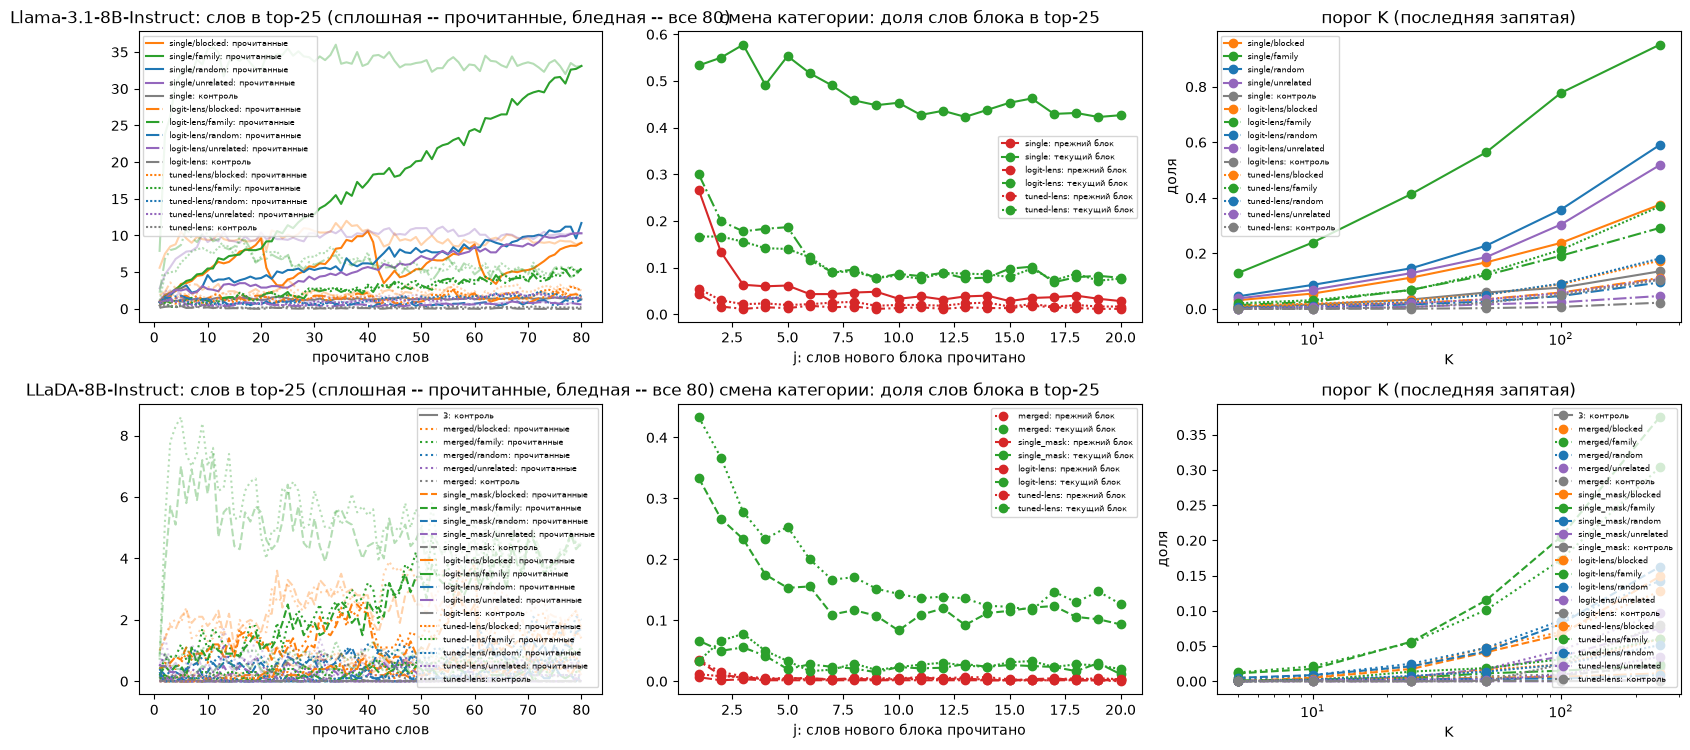

In [31]:
rows_capacity, dfs_capacity = [], []
for entry in MODELS:
    _r, _d = run_capacity(entry, step=CAPACITY_STEP)
    rows_capacity.extend(_r); dfs_capacity.append(_d)
cap_df = pd.concat(dfs_capacity, ignore_index=True)
cap_df.to_csv("capacity_trials.csv", index=False)
cap_summary = record_and_show(rows_capacity)

_show = ["model", "variant", "mean_present_read", "present_read_last", "present_read_n11", "present_all_n11", "ctrl_present_last", "frac_read_last"]
display(cap_summary[_show].round(2))

_lens_pick = lambda m: (["single"] if m.startswith("Llama") else ["3", "merged", "single_mask"]) + list(BASELINE_LENSES)
_LS = {"single": "-", "3": "-", "merged": ":", "single_mask": "--", "logit-lens": "-.", "tuned-lens": (0, (1, 1))}
_cc = {"blocked": "C1", "random": "C0", "unrelated": "C4", "family": "C2"}
fig, axes = plt.subplots(len(MODELS), 3, figsize=(16, 3.8 * len(MODELS)), squeeze=False)
for mi, entry in enumerate(MODELS):
    _m = entry["name"]; _d = cap_df[cap_df["model"] == _m]
    for lv in _lens_pick(_m):
        _ls = _LS.get(lv, "-")
        _l = _d[_d["variant"] == lv]
        ax = axes[mi][0]
        for cond, g in _l.groupby("cond"):
            c = g.groupby("n_read")[["pr_25", "pa_25"]].mean()
            ax.plot(c.index, c["pr_25"], ls=_ls, color=_cc[cond], label=f"{lv}/{cond}: прочитанные")
            if cond != "random":
                ax.plot(c.index, c["pa_25"], ls=_ls, color=_cc[cond], alpha=0.35)
        _c = _l.groupby("n_read")["pc_25"].mean(); ax.plot(_c.index, _c.values, ls=_ls, color="gray", label=f"{lv}: контроль")
        _b = _l[(_l["cond"] == "blocked") & _l["prev_k"].notna()].copy()
        if len(_b):
            _b["pf"] = _b["prev_k"] / _b["n_prev"]; _b["cf"] = _b["cur_read_k"] / _b["n_cur_read"]
            ax = axes[mi][1]
            g = _b.groupby("j")[["pf", "cf"]].mean()
            ax.plot(g.index, g["pf"], ls=_ls, color="C3", marker="o", label=f"{lv}: прежний блок")
            ax.plot(g.index, g["cf"], ls=_ls, color="C2", marker="o", label=f"{lv}: текущий блок")
        ax = axes[mi][2]
        _last = _l[_l["n_read"] == _l.groupby(["trial", "cond"])["n_read"].transform("max")]
        for cond, g in _last.groupby("cond"):
            ax.plot(_CAP_KS, [(g[f"pr_{kk}"] / g["n_read"]).mean() for kk in _CAP_KS], ls=_ls, marker="o", color=_cc[cond],
                    label=f"{lv}/{cond}")
        ax.plot(_CAP_KS, [(_last[f"pc_{kk}"] / _last["n_ctrl"]).mean() for kk in _CAP_KS], ls=_ls, marker="o", color="gray",
                label=f"{lv}: контроль")
    axes[mi][0].set_title(f"{_m}: слов в top-25 (сплошная -- прочитанные, бледная -- все 80)"); axes[mi][0].set_xlabel("прочитано слов")
    axes[mi][1].set_title("смена категории: доля слов блока в top-25"); axes[mi][1].set_xlabel("j: слов нового блока прочитано")
    axes[mi][2].set_title("порог K (последняя запятая)"); axes[mi][2].set_xscale("log"); axes[mi][2].set_xlabel("K"); axes[mi][2].set_ylabel("доля")
    for a in axes[mi]: a.legend(fontsize=6)
plt.tight_layout(); plt.show()

## Эксперимент 10 -- dual-task (конкуренция заданий за рабочее пространство)

**Идея (статья, A.17, Fig 73).** Модель переписывает фиксированное предложение (`carrier_sentence`), а в промпте ей сказано
сосредоточиться на двух вещах сразу: на двух несвязанных концептах ("citrus fruits and farm animals") либо на концепте и
арифметической задаче ("citrus fruits and evaluating 3^2 - 2"). J-lens применяется на токенах переписываемого предложения.
Вопрос: делят ли два задания рабочее пространство и мешают ли друг другу.

**Что утверждает статья.** Оба задания попадают в рабочее пространство, но делят его по-разному:
- *Co-occupancy* (Fig 73B): на токенах, где одно задание в lens top-10, вероятность, что там же и другое, сравнивается с
  контролем, где другое задание измеряется в ДРУГОМ промпте (когда оно было единственной инструкцией). Два концепта делят токены
  на уровне контроля (0.46 против 0.53) -- "статистически не замечают друг друга"; концепт и вычисленный ответ почти не делят
  токены (0.09 против 0.29): концепт занимает одни токены, ответ -- другие.
- *Reach* (Fig 73C): доля испытаний, где содержимое задания достигает ранга <= 5 где-либо в ответе, при двух заданиях почти не
  падает по сравнению с одним; сильнее всего падает вычисленный ответ (95% -> 72%). Два концепта удерживаются почти бесплатно,
  а цену за совместное использование несёт вычисление.

**Что считает ячейка.** `run_dual_task` возвращает длинную таблицу по позициям: `best_rank` -- лучший ранг (по band) среди
целевых токенов задания на данной позиции carrier'а, для каждой инструкции, линзы и задания (A/B). `summarize_dual_task`
считает по ней reach и co-occupancy, поэтому пороги (`k=5`, `k_occ=10`) меняются без перепрогона. Файл
`dual_task_positions.csv` присылайте. Колонки сводки: `cm_*` -- арм концепт+арифметика, `cc_*` -- два концепта;
`*_single` / `*_dual` -- reach в одиночном / двойном условии; `*_interference = single - dual`; `*_offtarget` -- reach
задания, которое в инструкции НЕ просили (базовая линия: без неё "reach = 1.0" неотличим от насыщения);
`*_cooc_dual` / `*_cooc_control` -- co-occupancy и контроль, `*_cooc_n` -- число токенов-знаменателей.

**Исправления относительно прошлой версии.**
1. *Цель арифметики у Llama была бессмысленной.* Для ответа бралось `first_token_id(" 7")`, а Llama-3 токенизирует " 7" как
   " " + "7" -- "первым токеном" оказывался пробел. Теперь только строго однотокенные формы: цифра без пробела и число-слово
   (со/без пробела, с заглавной).
2. *Цифра, входящая в выражение.* У 8 из 21 задач цифра ответа входит в само выражение (2^3 - 6 = 2 и т.п.) -- её присутствие
   в lens ничего не говорит о вычислении. Для таких задач цифровая форма не используется, остаётся число-слово.
3. *Лимит в DEBUG.* `pairs` и `concept_pairs` обрезались независимо, и при `limit=3` ни одна пара концепт+концепт не находилась
   -- весь второй арм молча пропускался. Теперь ключи пар берутся из выбранных `concept_pairs`.
4. *Нет co-occupancy и базовой линии.* Прошлая версия считала только разность reach. Добавлены позиционная co-occupancy с
   контролем из другого промпта и off-target reach.
5. *Скорость.* Один промпт читается один раз для всех целей сразу (раньше -- дважды, по разу на каждое задание), одиночные
   промпты кэшируются между армами. Позиции прореживаются (`probe_step=3`).
6. *Формат.* Промпт собирается через `_dm_prompt`, то есть в формате `PROMPT_FORMAT` (по умолчанию plain), как в
   эксперименте 4. Инструкция для арифметики -- "evaluating 3^2 - 2" (как в статье) вместо прежнего "solving".

**Чтение.** Llama читает позицию p и предсказывает токен p+1; LLaDA маскирует именно позицию p и читает на ней (probe_mask).
Поэтому "один и тот же токен" у двух моделей сдвинут на единицу -- на сравнение co-occupancy внутри модели это не влияет.

**Baseline'ы.** Reach и co-occupancy считаются и для `logit-lens` / `tuned-lens`; для них ожидается меньшая достижимость вычисленного ответа.


In [32]:
NUMBER_WORDS_1_9 = {1: "one", 2: "two", 3: "three", 4: "four", 5: "five", 6: "six", 7: "seven", 8: "eight", 9: "nine"}

def _dt_concept_ids(tok, words):
    ids = []
    for w in words:
        for form in (" " + w, w):
            tid = single_token_id(tok, form)
            if tid is not None:
                ids.append(tid)
                break
    return list(dict.fromkeys(ids))

def _dt_answer_ids(tok, ans, expr_digits):
    """Токены ответа арифметики. FIXED: раньше брался first_token_id(" "+форма) -- у Llama-3 " 7" токенизируется как " " + "7",
    то есть "первый токен" оказывался ПРОБЕЛОМ (токен, который почти всегда где-то в топе) и reach был бессмыслен.
    Теперь только строго однотокенные формы: цифра без пробела, число-слово со/без пробела и с заглавной.
    Цифровая форма выкидывается, если цифра ответа входит в само выражение (3^2-2=7: нет; 2^3-6=2: есть -- тогда цифра
    есть в промпте, и её присутствие в lens не доказывает вычисление)."""
    forms = []
    if str(ans) not in expr_digits:
        forms += [str(ans)]
    w = NUMBER_WORDS_1_9[ans]
    forms += [w, " " + w, w.capitalize(), " " + w.capitalize()]
    ids = [single_token_id(tok, f) for f in forms]
    return list(dict.fromkeys(t for t in ids if t is not None))

@follow_gpu
def _dt_position_ranks(entry, prompt_ids, target_ids, token_ids, step=1):
    """{variant: {pos_in_span: {token_id: минимальный ранг по band}}} на каждой step-й позиции спана (carrier).
    Позиционная версия нужна для co-occupancy: статья смотрит, появляются ли два задания НА ОДНИХ И ТЕХ ЖЕ токенах.
    Llama: один forward, читаем позицию p. LLaDA: маскируем ТОЛЬКО позицию p (probe_mask) и читаем на ней."""
    mask_id, model, band = entry.get("mask_id"), entry["model"], entry["band"]
    full_ids = torch.cat([prompt_ids, target_ids], dim=1)
    n0, n = prompt_ids.shape[1], target_ids.shape[1]
    rel = list(range(0, n, step))
    lenses = all_llada_lenses(entry)
    out = {v: {} for v in lenses}
    if mask_id is None:
        acts, _ = record_residuals(model, full_ids, band)
        for r in rel:
            for v, lens in lenses.items():
                out[v][r] = ranks_over_band(model, lens, acts, band, [n0 + r], token_ids)
        return out
    for r in rel:
        x = full_ids.clone()
        x[0, n0 + r] = mask_id
        acts, _ = record_residuals(model, x, band)
        for v, lens in lenses.items():
            out[v][r] = ranks_over_band(model, lens, acts, band, [n0 + r], token_ids)
    return out

def run_dual_task(entry, limit=N_ITEMS_LIMIT, probe_step=3):
    """Dual-task (README §app-competition, статья A.17, Fig 73). Возвращает ДЛИННУЮ таблицу по позициям:
    (arm, key, condition, task, variant, pos, best_rank) -- лучший ранг по band среди целевых токенов задания на позиции pos
    carrier'а. Всё остальное (reach, co-occupancy) считает summarize_dual_task: пороги можно менять без перепрогона.
    Один промпт (инструкция) считается ОДИН раз для всех целей сразу (раньше -- по разу на каждую цель, т.е. дважды)."""
    tok = entry["tokenizer"]
    data = json.load(open(EXPERIMENTS_DIR / "dual-task.json"))
    carrier = data["carrier_sentence"]
    pairs = {p["key"]: p for p in data["pairs"]}
    concept_pairs = [tuple(c) for c in data["concept_pairs"]]
    if limit:
        concept_pairs = concept_pairs[:limit]
        keep = list(pairs)[:limit] + [kk for c in concept_pairs for kk in c]
        pairs = {kk: pairs[kk] for kk in dict.fromkeys(keep)}

    def instr(parts):
        return f"Concentrate on {' and '.join(parts)} while you write the sentence."

    c_ids = {kk: _dt_concept_ids(tok, p["concept_words"]) for kk, p in pairs.items()}
    m_text, m_ids = {}, {}
    for kk, p in pairs.items():
        ans = p["base"] ** p["exp"] - p["sub"]
        m_text[kk] = f"evaluating {p['base']}^{p['exp']} - {p['sub']}"
        m_ids[kk] = _dt_answer_ids(tok, ans, {str(p["base"]), str(p["exp"]), str(p["sub"])})
    union = sorted({t for v in c_ids.values() for t in v} | {t for v in m_ids.values() for t in v})

    cache = {}

    def ranks(instruction):
        if instruction not in cache:
            user_text = f'{instruction} Write "{carrier}"'
            prompt_ids, target_ids = _dm_prompt(entry["tokenizer"], user_text, carrier)
            cache[instruction] = _dt_position_ranks(entry, prompt_ids, target_ids, union, step=probe_step)
        return cache[instruction]

    jobs = []
    for kk, p in pairs.items():
        if not c_ids[kk] or not m_ids[kk]:
            continue
        for cond in data["concept_math_conditions"]:
            parts = {"concept": [p["concept"]], "math": [m_text[kk]], "concept_first": [p["concept"], m_text[kk]],
                     "math_first": [m_text[kk], p["concept"]]}[cond]
            jobs.append(("concept_math", kk, cond, instr(parts), c_ids[kk], m_ids[kk]))
    for ka, kb in concept_pairs:
        if ka not in pairs or kb not in pairs or not c_ids[ka] or not c_ids[kb]:
            continue
        for cond in data["concept_concept_conditions"]:
            ca, cb = pairs[ka]["concept"], pairs[kb]["concept"]
            parts = {"a_only": [ca], "b_only": [cb], "a_first": [ca, cb], "b_first": [cb, ca]}[cond]
            jobs.append(("concept_concept", f"{ka}+{kb}", cond, instr(parts), c_ids[ka], c_ids[kb]))

    rows = []
    def _pjob(_job):
        (arm, key, cond, instruction, ids_a, ids_b) = _job
        tok = entry["tokenizer"]
        for variant, by_pos in ranks(instruction).items():
            for pos, rk in by_pos.items():
                for task, ids in (("A", ids_a), ("B", ids_b)):
                    rows.append({"model": entry["name"], "arm": arm, "key": key, "condition": cond, "task": task,
                                 "variant": variant, "pos": pos, "n_ids": len(ids),
                                 "best_rank": min((rk.get(t) or 10**9) for t in ids)})
    pmap(_pjob, list(jobs), desc=f"dual-task [{entry['name']}]")
    return pd.DataFrame(rows)

_DT_DUAL = {"concept_math": ("concept_first", "math_first"), "concept_concept": ("a_first", "b_first")}
_DT_SINGLE = {"concept_math": {"A": "concept", "B": "math"}, "concept_concept": {"A": "a_only", "B": "b_only"}}

def summarize_dual_task(pos_df, k=5, k_occ=10):
    """Две меры из статьи (A.17, Fig 73):
    (C) reach: доля испытаний, где содержимое задания достигает ранга <= k ГДЕ-ЛИБО в ответе, в одиночном vs двойном условии;
        interference = single - dual. Плюс off-target: reach задания, которое в инструкции НЕ просили (базовая линия случайного
        попадания -- без неё "reach=1.0" неотличим от насыщения).
    (B) co-occupancy: на токенах, где задание X в top-k_occ, вероятность, что в top-k_occ и задание Y -- против контроля, где Y
        измеряется в ДРУГОМ промпте (тот же позиционный индекс, но Y было единственной инструкцией). Статья: два концепта
        0.46 vs 0.53 (как контроль), концепт+вычисление 0.09 vs 0.29 (почти не делят токены)."""
    out, cooc = [], []
    for (model, variant), g in pos_df.groupby(["model", "variant"]):
        reach = (g.assign(hit=g["best_rank"] <= k).groupby(["arm", "key", "condition", "task"])["hit"].max().reset_index())
        row = {"experiment": "dual-task", "model": model, "variant": variant, "n_items": reach["key"].nunique()}

        def mean_of(arm, conds, task):
            s = reach[(reach["arm"] == arm) & reach["condition"].isin(conds) & (reach["task"] == task)]["hit"]
            return float(s.mean()) if len(s) else None

        for arm, tag, (ta, tb) in (("concept_math", "cm", ("concept", "math")), ("concept_concept", "cc", ("a", "b"))):
            dual = _DT_DUAL[arm]
            for task, name in (("A", ta), ("B", tb)):
                single = mean_of(arm, [_DT_SINGLE[arm][task]], task)
                dualv = mean_of(arm, list(dual), task)
                other = "B" if task == "A" else "A"
                off = mean_of(arm, [_DT_SINGLE[arm][other]], task)
                row[f"{tag}_{name}_single"] = single
                row[f"{tag}_{name}_dual"] = dualv
                row[f"{tag}_{name}_offtarget"] = off
                row[f"{tag}_{name}_interference"] = (single - dualv) if single is not None and dualv is not None else None
        for arm, tag in (("concept_math", "cm"), ("concept_concept", "cc")):
            num_d = num_c = den = 0
            sub = g[g["arm"] == arm]
            for key, gk in sub.groupby("key"):
                piv = gk.pivot_table(index=["condition", "pos"], columns="task", values="best_rank", aggfunc="min")
                for dc in _DT_DUAL[arm]:
                    if dc not in piv.index.get_level_values(0):
                        continue
                    d = piv.loc[dc] <= k_occ
                    for X, Y in (("A", "B"), ("B", "A")):
                        sc = _DT_SINGLE[arm][Y]
                        if sc not in piv.index.get_level_values(0):
                            continue
                        ys = (piv.loc[sc][Y] <= k_occ).reindex(d.index).fillna(False)
                        x = d[X]
                        den += int(x.sum())
                        num_d += int((x & d[Y]).sum())
                        num_c += int((x & ys).sum())
            row[f"{tag}_cooc_dual"] = num_d / den if den else None
            row[f"{tag}_cooc_control"] = num_c / den if den else None
            row[f"{tag}_cooc_n"] = den
        out.append(row)
    return pd.DataFrame(out)

dual-task [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 124/124 [08:22<00:00,  4.06s/it]


,0,1,2,3,4,5,6,7,8,9,10
experiment,dual-task,dual-task,dual-task,dual-task,dual-task,dual-task,dual-task,dual-task,dual-task,dual-task,dual-task
model,LLaDA-8B-Instruct,LLaDA-8B-Instruct,LLaDA-8B-Instruct,LLaDA-8B-Instruct,LLaDA-8B-Instruct,LLaDA-8B-Instruct,LLaDA-8B-Instruct,LLaDA-8B-Instruct,Llama-3.1-8B-Instruct,Llama-3.1-8B-Instruct,Llama-3.1-8B-Instruct
variant,0,1,2,3,logit-lens,merged,single_mask,tuned-lens,logit-lens,single,tuned-lens
n_items,31,31,31,31,31,31,31,31,31,31,31
cm_concept_single,0.0,0.05,0.1,0.19,0.0,0.05,0.43,0.05,0.57,0.62,0.38
cm_concept_dual,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05,0.12,0.07
cm_concept_offtarget,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1
cm_concept_interference,0.0,0.05,0.1,0.19,0.0,0.05,0.43,0.05,0.52,0.5,0.31
cm_math_single,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.33
cm_math_dual,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.21


,k,model,variant,cm_concept_single,cm_concept_dual,cm_concept_offtarget,cm_math_single,cm_math_dual,cm_math_offtarget,cc_a_single,cc_a_dual,cc_b_single,cc_b_dual
0,1,LLaDA-8B-Instruct,0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.0,0.00
1,1,LLaDA-8B-Instruct,1,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.0,0.00
2,1,LLaDA-8B-Instruct,2,0.05,0.00,0.00,0.00,0.00,0.00,0.1,0.00,0.0,0.00
3,1,LLaDA-8B-Instruct,3,0.10,0.00,0.00,0.00,0.00,0.00,0.2,0.00,0.0,0.00
4,1,LLaDA-8B-Instruct,logit-lens,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.0,0.00
5,1,LLaDA-8B-Instruct,merged,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.0,0.00
6,1,LLaDA-8B-Instruct,single_mask,0.14,0.00,0.00,0.00,0.00,0.00,0.2,0.10,0.1,0.00
7,1,LLaDA-8B-Instruct,tuned-lens,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.0,0.00
8,1,Llama-3.1-8B-Instruct,logit-lens,0.14,0.00,0.00,0.00,0.00,0.00,0.3,0.05,0.0,0.00
9,1,Llama-3.1-8B-Instruct,single,0.38,0.05,0.00,0.00,0.00,0.00,0.3,0.10,0.5,0.10


Медиана (по задачам) лучшего ранга ответа арифметики в условии 'только math' -- чем меньше, тем ближе к видимости:


model                  variant    
LLaDA-8B-Instruct      0               367.0
                       1               607.0
                       2                68.0
                       3               133.0
                       logit-lens     2536.0
                       merged          101.0
                       single_mask    1827.0
                       tuned-lens       20.0
Llama-3.1-8B-Instruct  logit-lens      273.0
                       single           34.0
                       tuned-lens       18.0
Name: best_rank, dtype: float64

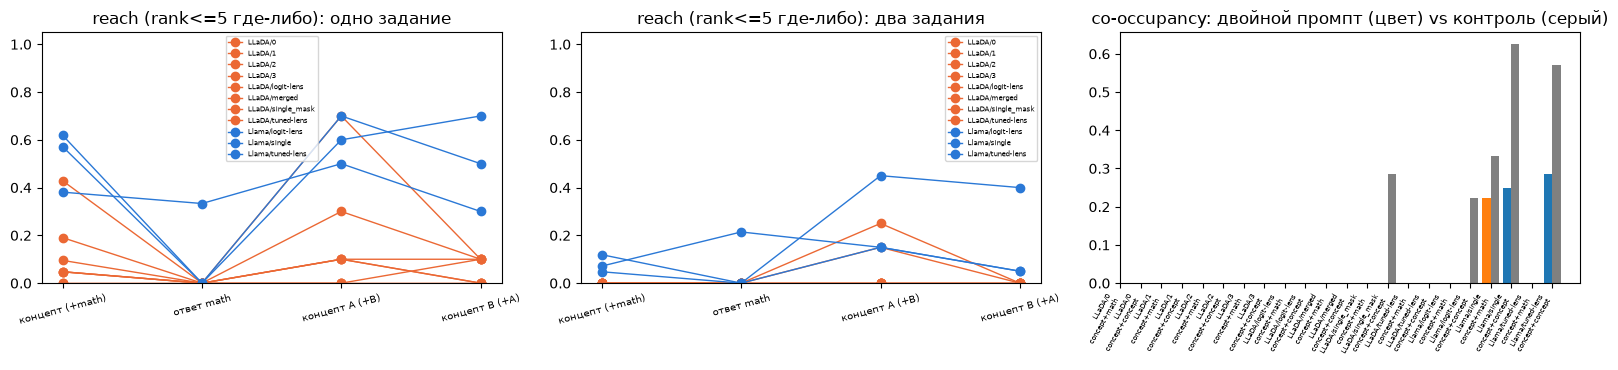

In [33]:
dt_pos = pd.concat([run_dual_task(entry, probe_step=3) for entry in MODELS], ignore_index=True)
dt_pos.to_csv("dual_task_positions.csv", index=False)
dt_sum = summarize_dual_task(dt_pos, k=5, k_occ=10)
results.extend(dt_sum.to_dict("records"))
display(dt_sum.round(2).T)

_diag = []
for _kk in (1, 5, 25, 100, 1000):
    _s = summarize_dual_task(dt_pos, k=_kk, k_occ=10)
    _s.insert(0, "k", _kk)
    _diag.append(_s[["k", "model", "variant", "cm_concept_single", "cm_concept_dual", "cm_concept_offtarget",
                     "cm_math_single", "cm_math_dual", "cm_math_offtarget", "cc_a_single", "cc_a_dual", "cc_b_single", "cc_b_dual"]])
display(pd.concat(_diag, ignore_index=True).round(2))
_best = (dt_pos[(dt_pos["arm"] == "concept_math") & (dt_pos["task"] == "B") & (dt_pos["condition"] == "math")]
         .groupby(["model", "variant", "key"])["best_rank"].min())
print("Медиана (по задачам) лучшего ранга ответа арифметики в условии 'только math' -- чем меньше, тем ближе к видимости:")
display(_best.groupby(["model", "variant"]).median())

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
_cols = [("cm_concept", "концепт (+math)"), ("cm_math", "ответ math"), ("cc_a", "концепт A (+B)"), ("cc_b", "концепт B (+A)")]
for ax, (suffix, ttl) in zip(axes[:2], [("single", "одно задание"), ("dual", "два задания")]):
    for i, row in dt_sum.reset_index(drop=True).iterrows():
        vals = [row[f"{c}_{suffix}"] for c, _ in _cols]
        ax.plot(range(len(_cols)), [v if v is not None else np.nan for v in vals], "o-", lw=1,
                label=f"{row['model'][:5]}/{row['variant']}", color=MODEL_COLORS.get(row["model"], f"C{i}"))
    ax.set_xticks(range(len(_cols))); ax.set_xticklabels([t for _, t in _cols], rotation=15, fontsize=7)
    ax.set_ylim(0, 1.05); ax.set_title(f"reach (rank<=5 где-либо): {ttl}"); ax.legend(fontsize=5)
ax = axes[2]
_lab, _x = [], 0
for i, row in dt_sum.reset_index(drop=True).iterrows():
    for tag, c in (("cm", "C1"), ("cc", "C0")):
        ax.bar(_x, row[f"{tag}_cooc_dual"] or 0, 0.4, color=c)
        ax.bar(_x + 0.4, row[f"{tag}_cooc_control"] or 0, 0.4, color="gray")
        _lab.append(f"{row['model'][:5]}/{row['variant']}\n{'concept+math' if tag == 'cm' else 'concept+concept'}"); _x += 1
ax.set_xticks(np.arange(_x) + 0.2); ax.set_xticklabels(_lab, rotation=60, fontsize=5, ha="right")
ax.set_title("co-occupancy: двойной промпт (цвет) vs контроль (серый)")
plt.tight_layout(); plt.show()

## Эксперимент 11 -- top-down-summoning (вопрос определяет, что попадёт в J-space при чтении)

**Идея (статья §3.2, Fig 11, A.11 / Fig 66).** Модели дают один и тот же короткий пассаж, перед которым стоит один из двух вопросов:
- `q1` -- "какое слово будет следующим?" (нужно *использовать* свойство текста -- диалект, регистр, время, часть речи, число,
  тон, -- но не называть его);
- `q2` -- "назови свойство" (где автор? какой стиль? когда происходят события? какая часть речи будет следующей?).
Токены пассажа в обоих случаях одни и те же, поэтому любая разница в lens на этих позициях объясняется только вопросом. Статья:
под `q1` ярлык свойства (`british`, `past`, `adjective`, ...) в lens почти не появляется (0 -- 1 позиция), под `q2` появляется на
нескольких позициях пассажа; при этом ответы на `q1` свойство учитывают ("colour", "abstained"), то есть оно представлено и
используется в обоих случаях, а вопрос меняет лишь то, попадает ли его *название* в J-space.

**Читаемость.** Для каждой позиции пассажа берём лучший (по band) ранг ярлыков `expected`; метрика README -- доля позиций с
рангом <= k, `q2 - q1` (в статье k=10, здесь есть и 1/5/10/25). Для интерпретации добавлено три контроля: `foil` (противоположные
ярлыки -- растёт ли только нужное свойство), ярлыки ДРУГИХ примеров (`q2_other`: уровень случайного попадания; токены, общие с
этим примером, исключаются) и `q1_expect` (слова, которыми модель продолжает пассаж). `npos_q1/npos_q2` -- число позиций с
`expected` в top-10 (как "in lens on N tokens" в подписях рисунков).

**Причинность.** Ярлык и антиярлык (`swaps`) меняются местами по ВСЕМ позициям пассажа в координатах lens (`lens_clamp`, как в
exp 6/7, per-layer направления), ответ читается на позиции после `Assistant:`. Метрики: `flipped` -- сменился ли top-1,
`dmargin` -- сдвиг margin = log P(foil) - log P(label) (непрерывно, без потолка), `swap_in_foil` -- стал ли ответ антиярлыком,
`dlogp_base_top1` -- падение логвероятности исходного ответа. Контроль: тот же swap с парой слов из СОСЕДНЕГО примера (неспецифическое
разрушение, а не замена свойства). Сравнение `swap` vs `control` по `q1` и `q2` показывает, на какой вопрос повлияла замена.
`alpha` -- доля обмена (1.0 -- полный).

**Файлы.** `top_down_summoning_readout.csv` (позиции: `r_exp`, `r_foil`, `r_other`, `r_q1exp` -- лучшие ранги) и
`top_down_summoning_causal.csv` (по одной строке на пару/линзу/alpha/вопрос). Присылайте оба.

**Исправления относительно прошлой версии.**
1. *Причинный тест ничего не измерял.* Использовался `lens_swap` на каждом слое band; как описано в `ResidualPatcher`, повторный
   обмен на следующем слое возвращает координаты обратно (операция самоотменяется), и к тому же направление бралось с ОДНОГО
   (среднего) слоя. Теперь `lens_clamp` с per-layer направлениями (`token_directions_batch`), как в probe-swap и exp 6/7.
2. *Метрика причинности была слишком грубой.* Раньше -- только "поменялся ли top-1" (любая смена), теперь ещё и margin
   foil/label, ответ=foil, и контрольная пара, без которой нельзя отличить замену свойства от общего разрушения промпта.
3. *Промпт.* Раньше `"<q> <stimulus>"` без `Human:/Assistant:` и без кавычек, позиция ответа добавлялась отдельным "\nAnswer:".
   Теперь как в статье: вопрос, затем пассаж в кавычках, затем ход ассистента (формат `PROMPT_FORMAT`, plain по умолчанию);
   позиции пассажа находятся по offset'ам токенов, а не по префиксу.
4. *Ярлыки.* Раньше искался один токен слова в нижнем регистре (`" "+w` или `w`); линза чаще показывает "British"/" Britain".
   Теперь все однотокенные формы: с пробелом и без, строчные и с заглавной.
5. *Порог.* Раньше k=25; теперь k=10 (как в подписи Fig 11) плюс 1/5/25, и контроль по ярлыкам других примеров.
6. *Проверка ответов.* `base_answer_is_label_q2` (называет ли модель свойство под `q2`) и `base_answer_in_q1exp_q1`
   (продолжает ли пассаж ожидаемым словом под `q1`) -- иначе причинный тест не интерпретировать.
7. *LLaDA.* Раньше причинная часть для LLaDA считалась только по `single_mask` и копировалась на все строки; теперь все шесть
   линз считаются отдельно. Чтение каждой позиции пассажа -- маскирование ТОЛЬКО этой позиции (probe_mask), весь промпт целиком
   (включая `Assistant:` справа) остаётся контекстом -- у двунаправленной модели он виден; для Llama он каузально недоступен.

**Оговорка.** Llama читает позицию p и предсказывает токен p+1, LLaDA маскирует именно позицию p; поэтому "один и тот же токен"
у двух моделей сдвинут на единицу -- на сравнение `q2 - q1` внутри модели это не влияет.

**Набор элементов.** Вместо 7 элементов (по одному на свойство, 1 пассаж) теперь 28: по 4 пассажа на каждое из 6 прежних свойств
(`spelling`, `register`, `tense`, `number`, `pos`, `tone`) плюс новое свойство `person` (от какого лица ведётся рассказ; ярлык
`first`, антиярлык `third`). Дополнительные пассажи заданы прямо в ячейке (`_TDS_EXTRA_ITEMS`), JSON не нужно менять; `extra=False`
вернёт прежние 7. Для контроля специфичности пара swap берётся из ближайшего элемента ДРУГОГО свойства без общих слов
(`_tds_control_pair`). Результаты агрегируются и по свойствам (`top_down_summoning_by_prop.csv`): 4 пассажа на свойство делают
оценку `q2 - q1` устойчивее, чем прежние 7 единичных наблюдений.

**Скорость.** Читаемость: ~25 позиций на промпт (step=2) x 56 промптов (28 элементов x 2 вопроса); для LLaDA -- по forward на позицию. Причинность: пар
(2 swap + 1 control) x 2 вопроса x 2 alpha x 6 линз ≈ 72 forward на пример у LLaDA (с baseline'ами 8 линз вместо 6 -- примерно на треть больше), у Llama меньше; весь набор из 28 элементов у LLaDA займёт порядка получаса.

**Baseline'ы.** Readout и каузальная часть повторены для `logit-lens` / `tuned-lens` (`variant`).


In [34]:
_TDS_PROP_OF = {"pos_tense": "tense"}
_TDS_EXTRA_ITEMS = [
 {
  "key": "spelling_2",
  "prop": "spelling",
  "stimulus": "We spent the whole afternoon at the harbour, watching the grey clouds roll in over the sea. Later, back at the flat, we decided to",
  "q2": "Where do you think the author of this passage is from? Answer in one word.",
  "expected": [
   "british",
   "britain",
   "uk",
   "england"
  ],
  "foil": [
   "american",
   "america",
   "us"
  ],
  "q1_expect": [
   "stay",
   "go",
   "make",
   "have",
   "cook"
  ],
  "swaps": [
   [
    "British",
    "American"
   ],
   [
    "Britain",
    "America"
   ]
  ]
 },
 {
  "key": "register_2",
  "prop": "register",
  "stimulus": "Okay so honestly I have no clue what happened, like one minute we were all just vibing at the party and the next minute everybody was",
  "q2": "How would you describe the style of this passage? Answer in one word.",
  "expected": [
   "informal",
   "casual",
   "colloquial",
   "conversational"
  ],
  "foil": [
   "formal",
   "academic"
  ],
  "q1_expect": [
   "gone",
   "leaving",
   "running",
   "yelling",
   "shouting"
  ],
  "swaps": [
   [
    "informal",
    "formal"
   ],
   [
    "casual",
    "academic"
   ]
  ]
 },
 {
  "key": "tense_2",
  "prop": "tense",
  "stimulus": "The detective closed the file and looked out at the rain. For a long moment he said nothing, and then he slowly",
  "q2": "When are the events in this passage set relative to the moment of telling? Answer in one word.",
  "expected": [
   "past"
  ],
  "foil": [
   "present",
   "future"
  ],
  "q1_expect": [
   "turned",
   "stood",
   "reached",
   "nodded",
   "picked"
  ],
  "swaps": [
   [
    "past",
    "future"
   ],
   [
    "before",
    "after"
   ]
  ]
 },
 {
  "key": "number_2",
  "prop": "number",
  "stimulus": "The children had been waiting by the gate since sunrise, and when the bus finally appeared they all",
  "q2": "Is the upcoming clause about one entity or more than one? Answer in one word.",
  "expected": [
   "plural",
   "several",
   "multiple"
  ],
  "foil": [
   "singular",
   "one",
   "single"
  ],
  "q1_expect": [
   "ran",
   "rushed",
   "cheered",
   "started",
   "shouted"
  ],
  "swaps": [
   [
    "plural",
    "singular"
   ],
   [
    "multiple",
    "single"
   ]
  ]
 },
 {
  "key": "pos_2",
  "prop": "pos",
  "stimulus": "After weeks of preparation, the climbers finally reached the summit and stood in front of a view so incredibly",
  "q2": "What part of speech do you think the next word will be? Answer in one word.",
  "expected": [
   "adjective",
   "adj"
  ],
  "foil": [
   "noun",
   "verb"
  ],
  "q1_expect": [
   "beautiful",
   "stunning",
   "breathtaking",
   "vast",
   "wide"
  ],
  "swaps": [
   [
    "adj",
    "prep"
   ],
   [
    "noun",
    "verb"
   ]
  ]
 },
 {
  "key": "tone_2",
  "prop": "tone",
  "stimulus": "The funeral was held on a quiet Tuesday, and nobody spoke much as the car pulled away. She watched the empty road until the light",
  "q2": "What mood does this passage convey? Answer in one word.",
  "expected": [
   "sad",
   "somber",
   "melancholy",
   "melanch",
   "grief"
  ],
  "foil": [
   "happy",
   "joyful",
   "cheerful"
  ],
  "q1_expect": [
   "faded",
   "died",
   "went",
   "turned",
   "dimmed"
  ],
  "swaps": [
   [
    "sad",
    "happy"
   ],
   [
    "mal",
    "joy"
   ]
  ]
 },
 {
  "key": "person_2",
  "prop": "person",
  "stimulus": "I had never been to the coast before, so when the train rounded the last bend and the sea appeared, I",
  "q2": "From whose point of view is this passage told? Answer in one word.",
  "expected": [
   "first"
  ],
  "foil": [
   "third",
   "second"
  ],
  "q1_expect": [
   "gasped",
   "stared",
   "stopped",
   "felt",
   "pressed"
  ],
  "swaps": [
   [
    "first",
    "third"
   ],
   [
    "I",
    "he"
   ]
  ]
 },
 {
  "key": "spelling_3",
  "prop": "spelling",
  "stimulus": "The programme was meant to realise a simple goal: to bring the whole neighbourhood together for a single evening. By the end of the night, the organisers",
  "q2": "Where do you think the author of this passage is from? Answer in one word.",
  "expected": [
   "british",
   "britain",
   "uk",
   "england"
  ],
  "foil": [
   "american",
   "america",
   "us"
  ],
  "q1_expect": [
   "had",
   "were",
   "felt",
   "could",
   "looked"
  ],
  "swaps": [
   [
    "British",
    "American"
   ],
   [
    "Britain",
    "America"
   ]
  ]
 },
 {
  "key": "register_3",
  "prop": "register",
  "stimulus": "lol that movie was sooo bad, I mean the plot made zero sense and the ending was kinda",
  "q2": "How would you describe the style of this passage? Answer in one word.",
  "expected": [
   "informal",
   "casual",
   "colloquial",
   "conversational"
  ],
  "foil": [
   "formal",
   "academic"
  ],
  "q1_expect": [
   "lame",
   "dumb",
   "weak",
   "boring",
   "meh"
  ],
  "swaps": [
   [
    "informal",
    "formal"
   ],
   [
    "casual",
    "academic"
   ]
  ]
 },
 {
  "key": "tense_3",
  "prop": "tense",
  "stimulus": "Last winter my grandfather walked to the old market every morning, carrying a small basket, and every vendor knew him by name. One day he",
  "q2": "When are the events in this passage set relative to the moment of telling? Answer in one word.",
  "expected": [
   "past"
  ],
  "foil": [
   "present",
   "future"
  ],
  "q1_expect": [
   "stopped",
   "did",
   "didn",
   "walked",
   "came"
  ],
  "swaps": [
   [
    "past",
    "future"
   ],
   [
    "before",
    "after"
   ]
  ]
 },
 {
  "key": "number_3",
  "prop": "number",
  "stimulus": "After the storm, the villagers gathered in the square to see what remained of their homes. The houses",
  "q2": "Is the upcoming clause about one entity or more than one? Answer in one word.",
  "expected": [
   "plural",
   "several",
   "multiple"
  ],
  "foil": [
   "singular",
   "one",
   "single"
  ],
  "q1_expect": [
   "were",
   "had",
   "looked",
   "stood",
   "lay"
  ],
  "swaps": [
   [
    "plural",
    "singular"
   ],
   [
    "multiple",
    "single"
   ]
  ]
 },
 {
  "key": "pos_3",
  "prop": "pos",
  "stimulus": "The restaurant was small, but the owner greeted every guest with a warm smile, and the food was absolutely",
  "q2": "What part of speech do you think the next word will be? Answer in one word.",
  "expected": [
   "adjective",
   "adj"
  ],
  "foil": [
   "noun",
   "verb"
  ],
  "q1_expect": [
   "delicious",
   "wonderful",
   "perfect",
   "amazing",
   "superb"
  ],
  "swaps": [
   [
    "adj",
    "prep"
   ],
   [
    "noun",
    "verb"
   ]
  ]
 },
 {
  "key": "tone_3",
  "prop": "tone",
  "stimulus": "He kept the old photograph on his desk, though looking at it only made the silence in the apartment feel",
  "q2": "What mood does this passage convey? Answer in one word.",
  "expected": [
   "sad",
   "somber",
   "melancholy",
   "melanch",
   "grief"
  ],
  "foil": [
   "happy",
   "joyful",
   "cheerful"
  ],
  "q1_expect": [
   "heavier",
   "louder",
   "deeper",
   "worse",
   "longer"
  ],
  "swaps": [
   [
    "sad",
    "happy"
   ],
   [
    "mal",
    "joy"
   ]
  ]
 },
 {
  "key": "person_3",
  "prop": "person",
  "stimulus": "We packed the car before dawn, and by the time the sun came up my brother and I",
  "q2": "From whose point of view is this passage told? Answer in one word.",
  "expected": [
   "first"
  ],
  "foil": [
   "third",
   "second"
  ],
  "q1_expect": [
   "were",
   "had",
   "could",
   "finally",
   "barely"
  ],
  "swaps": [
   [
    "first",
    "third"
   ],
   [
    "I",
    "he"
   ]
  ]
 },
 {
  "key": "spelling_4",
  "prop": "spelling",
  "stimulus": "He polished his favourite cricket bat, checked the colour of the sky, and wondered whether the match would",
  "q2": "Where do you think the author of this passage is from? Answer in one word.",
  "expected": [
   "british",
   "britain",
   "uk",
   "england"
  ],
  "foil": [
   "american",
   "america",
   "us"
  ],
  "q1_expect": [
   "be",
   "start",
   "go",
   "begin",
   "even"
  ],
  "swaps": [
   [
    "British",
    "American"
   ],
   [
    "Britain",
    "America"
   ]
  ]
 },
 {
  "key": "register_4",
  "prop": "register",
  "stimulus": "Hey dude, gonna be late tonight cuz my car's acting up again, so just start without me and I'll",
  "q2": "How would you describe the style of this passage? Answer in one word.",
  "expected": [
   "informal",
   "casual",
   "colloquial",
   "conversational"
  ],
  "foil": [
   "formal",
   "academic"
  ],
  "q1_expect": [
   "be",
   "catch",
   "meet",
   "get",
   "join"
  ],
  "swaps": [
   [
    "informal",
    "formal"
   ],
   [
    "casual",
    "academic"
   ]
  ]
 },
 {
  "key": "tense_4",
  "prop": "tense",
  "stimulus": "By the time the guests arrived, the cook had already prepared the soup and set the table. When the first knock came, she",
  "q2": "When are the events in this passage set relative to the moment of telling? Answer in one word.",
  "expected": [
   "past"
  ],
  "foil": [
   "present",
   "future"
  ],
  "q1_expect": [
   "opened",
   "wiped",
   "smiled",
   "hurried",
   "turned"
  ],
  "swaps": [
   [
    "past",
    "future"
   ],
   [
    "before",
    "after"
   ]
  ]
 },
 {
  "key": "number_4",
  "prop": "number",
  "stimulus": "Three old friends met at the cafe every Friday to argue about politics. Lately, though, they",
  "q2": "Is the upcoming clause about one entity or more than one? Answer in one word.",
  "expected": [
   "plural",
   "several",
   "multiple"
  ],
  "foil": [
   "singular",
   "one",
   "single"
  ],
  "q1_expect": [
   "had",
   "were",
   "barely",
   "rarely",
   "seemed"
  ],
  "swaps": [
   [
    "plural",
    "singular"
   ],
   [
    "multiple",
    "single"
   ]
  ]
 },
 {
  "key": "pos_4",
  "prop": "pos",
  "stimulus": "It was a long, cold winter, and the old house felt unusually",
  "q2": "What part of speech do you think the next word will be? Answer in one word.",
  "expected": [
   "adjective",
   "adj"
  ],
  "foil": [
   "noun",
   "verb"
  ],
  "q1_expect": [
   "quiet",
   "empty",
   "cold",
   "silent",
   "big"
  ],
  "swaps": [
   [
    "adj",
    "prep"
   ],
   [
    "noun",
    "verb"
   ]
  ]
 },
 {
  "key": "tone_4",
  "prop": "tone",
  "stimulus": "Every evening she set two plates on the table out of habit, and every evening she remembered that he",
  "q2": "What mood does this passage convey? Answer in one word.",
  "expected": [
   "sad",
   "somber",
   "melancholy",
   "melanch",
   "grief"
  ],
  "foil": [
   "happy",
   "joyful",
   "cheerful"
  ],
  "q1_expect": [
   "was",
   "would",
   "wasn",
   "wouldn",
   "had"
  ],
  "swaps": [
   [
    "sad",
    "happy"
   ],
   [
    "mal",
    "joy"
   ]
  ]
 },
 {
  "key": "person_4",
  "prop": "person",
  "stimulus": "Honestly, I still don't know why I agreed to go along with it, but looking back I suppose I",
  "q2": "From whose point of view is this passage told? Answer in one word.",
  "expected": [
   "first"
  ],
  "foil": [
   "third",
   "second"
  ],
  "q1_expect": [
   "wanted",
   "needed",
   "thought",
   "just",
   "was"
  ],
  "swaps": [
   [
    "first",
    "third"
   ],
   [
    "I",
    "he"
   ]
  ]
 }
]

def _tds_control_pair(items, ii):
    """Контрольная пара swap: ближайший элемент ДРУГОГО свойства без общих слов с парами этого элемента."""
    me = items[ii]
    mine = {w.lower() for pr in me["swaps"] for w in pr}
    for off in range(1, len(items)):
        c = items[(ii + off) % len(items)]
        if c["prop"] == me["prop"]:
            continue
        for pr in c["swaps"]:
            if not ({w.lower() for w in pr} & mine):
                return tuple(pr)
    return tuple(items[(ii + 1) % len(items)]["swaps"][0])

def _tds_forms(w):
    return (" " + w, w, " " + w.capitalize(), w.capitalize())

def _tds_ids(tok, words, first_token=False):
    """Токены слов во всех регистрах и с/без пробела. first_token=False -- только строго однотокенные формы (для чтения линзой),
    True -- ещё и первый токен многотокенных форм (для проверки ответа модели: 'Britain' может быть '"Brit" + "ain"').
    FIXED: раньше брался ОДИН вариант (" "+w или w, нижний регистр), а линза чаще показывает 'British'/'Britain' с заглавной."""
    out = []
    for w in words:
        for f in _tds_forms(w):
            t = first_token_id(tok, f) if first_token else single_token_id(tok, f)
            if t is not None:
                out.append(t)
    return list(dict.fromkeys(out))

def _tds_prompt(tok, q, stim):
    """(ids, stim_positions): промпт как в статье (Fig 11, 66): вопрос ПЕРЕД пассажем, пассаж в кавычках, затем ход ассистента.
    plain: 'Human: <q> "<stimulus>"\\n\\nAssistant:'; chat -- через шаблон. Позиции пассажа ищутся по offset'ам токенов
    (токен с открывающей кавычкой, например '"She', тоже считается пассажем). Запасной путь -- по общему префиксу токенизации.
    FIXED: прежний промпт 'q + " " + stimulus' не имел ни 'Human:/Assistant:', ни кавычек."""
    user = f'{q} "{stim}"'
    if PROMPT_FORMAT == "plain":
        text = "Human: " + user + "\n\nAssistant:"
    else:
        text = tok.apply_chat_template([{"role": "user", "content": user}], tokenize=False, add_generation_prompt=True)
    s0 = text.index('"' + stim) + 1
    s1 = s0 + len(stim)
    ids = text_ids(tok, text)
    try:
        enc = tok(text, return_offsets_mapping=True)
        assert len(enc["input_ids"]) == ids.shape[1]
        pos = [i for i, (a, b) in enumerate(enc["offset_mapping"]) if b > a and b > s0 and a < s1]
    except Exception:
        a = common_prefix_len(tok, ids, text[:s0])
        b = common_prefix_len(tok, ids, text[:s1])
        pos = list(range(a, b))
    return ids, pos

@follow_gpu
def _tds_position_ranks(entry, ids, positions, token_ids, step=1):
    """{variant: {pos: {token_id: минимальный ранг по band}}} на каждой step-й позиции из positions.
    Llama: один forward, читаем позицию p. LLaDA: маскируем ТОЛЬКО позицию p и читаем на ней (probe_mask)."""
    mask_id, model, band = entry.get("mask_id"), entry["model"], entry["band"]
    lenses = all_llada_lenses(entry)
    sel = list(positions)[::step] if step > 1 else list(positions)
    out = {v: {} for v in lenses}
    if mask_id is None:
        acts, _ = record_residuals(model, ids, band)
        for p in sel:
            for v, lens in lenses.items():
                out[v][p] = ranks_over_band(model, lens, acts, band, [p], token_ids)
        return out
    for p in sel:
        x = ids.clone()
        x[0, p] = mask_id
        acts, _ = record_residuals(model, x, band)
        for v, lens in lenses.items():
            out[v][p] = ranks_over_band(model, lens, acts, band, [p], token_ids)
    return out

def run_top_down_summoning(entry, limit=N_ITEMS_LIMIT, step=2, alphas=(0.5, 1.0), do_causal=True, extra=True):
    """Top-down summoning (статья §3.2, Fig 11, 66; README). Возвращает (readout_df, causal_df).
    readout_df: по позициям пассажа -- лучший ранг (по band) для expected / foil / ярлыков ДРУГИХ задач (контроль) / q1_expect.
    causal_df: clamp-swap label<->foil по всем позициям пассажа, ответ читается на позиции после 'Assistant:'; для каждой пары
    swap и для контрольной пары (из соседнего примера) -- смена top-1, сдвиг margin и логвероятности исходного ответа."""
    tok, band, model = entry["tokenizer"], entry["band"], entry["model"]
    data = json.load(open(EXPERIMENTS_DIR / "top-down-summoning.json"))
    q1, items = data["q1"], list(data["items"])
    if extra:
        have = {it["key"] for it in items}
        items += [dict(it) for it in _TDS_EXTRA_ITEMS if it["key"] not in have]
    for it in items:
        it.setdefault("prop", _TDS_PROP_OF.get(it["key"], it["key"]))
    _bad = [it["key"] for it in items if not _tds_ids(tok, it["expected"]) or not _tds_ids(tok, it["foil"])]
    if _bad:
        print(f"[top-down-summoning] {entry['name']}: нет однотокенных ярлыков, пропуск: {_bad}")
        items = [it for it in items if it["key"] not in _bad]
    if limit:
        items = items[:limit]
    lenses = all_llada_lenses(entry)

    ids_of = {it["key"]: {"exp": _tds_ids(tok, it["expected"]), "foil": _tds_ids(tok, it["foil"]),
                          "q1": _tds_ids(tok, it["q1_expect"]),
                          "exp_ft": _tds_ids(tok, it["expected"], True), "foil_ft": _tds_ids(tok, it["foil"], True),
                          "q1_ft": _tds_ids(tok, it["q1_expect"], True)} for it in items}
    union = sorted({t for d in ids_of.values() for key in ("exp", "foil", "q1") for t in d[key]})

    ro_rows, ca_rows = [], []
    def _pjob(_job):
        (ii, item) = _job
        tok, band, model = entry["tokenizer"], entry["band"], entry["model"]
        key = item["key"]
        mine = ids_of[key]
        mine_all = set(mine["exp"]) | set(mine["foil"])
        other_ids = sorted({t for k2, d in ids_of.items() if k2 != key for t in d["exp"]} - mine_all)
        ctrl_pair = _tds_control_pair(items, ii)
        for qname, qtext in (("q1", q1), ("q2", item["q2"])):
            ids, stim_pos = _tds_prompt(tok, qtext, item["stimulus"])
            rk = _tds_position_ranks(entry, ids, stim_pos, union, step=step)
            big = 10 ** 9
            for v, by_pos in rk.items():
                for p, r in by_pos.items():
                    ro_rows.append({"model": entry["name"], "variant": v, "item": key, "prop": item["prop"], "question": qname, "pos": p,
                                    "r_exp": min([r.get(t) or big for t in mine["exp"]] or [big]),
                                    "r_foil": min([r.get(t) or big for t in mine["foil"]] or [big]),
                                    "r_other": min([r.get(t) or big for t in other_ids] or [big]),
                                    "r_q1exp": min([r.get(t) or big for t in mine["q1"]] or [big])})
            if not do_causal:
                continue
            acts_c, fl, rp = record_residuals_masked(entry, ids, band)
            logp_base = torch.log_softmax(final_logits_at(model, acts_c, fl, rp).float(), dim=-1)
            base_top1 = int(logp_base.argmax().item())
            lse = lambda lp, idl: float(torch.logsumexp(lp[idl], dim=0).item()) if idl else float("nan")
            m_base = lse(logp_base, mine["foil_ft"]) - lse(logp_base, mine["exp_ft"])
            pairs = [("swap", tuple(pr)) for pr in item["swaps"]] + [("control", ctrl_pair)]
            groups = []
            for _, (ws, wt) in pairs:
                for w in (ws, wt):
                    g = word_token_ids(tok, w)
                    groups.append(g if len(g) > 1 else (g[0] if g else None))
            if any(g is None for g in groups):
                continue
            for v, lens in lenses.items():
                dirs = token_directions_batch(model, lens, band, groups)
                for pi, (kind, (ws, wt)) in enumerate(pairs):
                    for a in alphas:
                        patches = [{"layer": l, "positions": stim_pos, "direction_s": dirs[l][2 * pi],
                                    "direction_t": dirs[l][2 * pi + 1], "alpha": a, "mode": "lens_clamp", "clean_h": acts_c[l]}
                                   for l in band]
                        with ResidualPatcher(model.layers, patches):
                            acts2, fl2, rp2 = record_residuals_masked(entry, ids, band)
                        logp_sw = torch.log_softmax(final_logits_at(model, acts2, fl2, rp2).float(), dim=-1)
                        sw_top1 = int(logp_sw.argmax().item())
                        ca_rows.append({
                            "model": entry["name"], "variant": v, "item": key, "prop": item["prop"], "question": qname, "kind": kind,
                            "pair": f"{ws}->{wt}", "alpha": a,
                            "flipped": float(sw_top1 != base_top1),
                            "margin_base": m_base, "margin_swap": lse(logp_sw, mine["foil_ft"]) - lse(logp_sw, mine["exp_ft"]),
                            "dlogp_base_top1": float((logp_sw[base_top1] - logp_base[base_top1]).item()),
                            "base_in_exp": float(base_top1 in mine["exp_ft"]), "base_in_q1exp": float(base_top1 in mine["q1_ft"]),
                            "swap_in_foil": float(sw_top1 in mine["foil_ft"]),
                            "base_top1_text": tok.decode([base_top1]), "swap_top1_text": tok.decode([sw_top1])})
    pmap(_pjob, list(enumerate(items)), desc=f"top-down-summoning [{entry['name']}]")
    return pd.DataFrame(ro_rows), pd.DataFrame(ca_rows)

def summarize_top_down(ro, ca, ks=(1, 5, 10, 25), k_main=10):
    """Читаемость (README: Q2 - Q1 доля позиций пассажа, где expected в top-k) и причинность."""
    out = []
    for (model, v), g in ro.groupby(["model", "variant"]):
        row = {"experiment": "top-down-summoning", "model": model, "variant": v, "n_items": g["item"].nunique()}
        for k in ks:
            per = (g.assign(e=g["r_exp"] <= k, f=g["r_foil"] <= k, o=g["r_other"] <= k, n=g["r_q1exp"] <= k)
                   .groupby(["item", "question"])[["e", "f", "o", "n"]].mean().unstack("question"))
            row[f"q1_frac_k{k}"] = per[("e", "q1")].mean()
            row[f"q2_frac_k{k}"] = per[("e", "q2")].mean()
            row[f"q2_minus_q1_k{k}"] = (per[("e", "q2")] - per[("e", "q1")]).mean()
            row[f"q2_minus_q1_foil_k{k}"] = (per[("f", "q2")] - per[("f", "q1")]).mean()
            row[f"q2_other_k{k}"] = per[("o", "q2")].mean()
            row[f"q2_minus_q1_q1exp_k{k}"] = (per[("n", "q2")] - per[("n", "q1")]).mean()
        npos = g.assign(e=g["r_exp"] <= k_main).groupby(["item", "question"])["e"].sum().unstack("question")
        row["npos_q1"], row["npos_q2"] = npos["q1"].mean(), npos["q2"].mean()
        row["items_q2_gt_q1"] = int((npos["q2"] > npos["q1"]).sum())
        if len(ca):
            c = ca[(ca["model"] == model) & (ca["variant"] == v)]
            for a in sorted(c["alpha"].unique()):
                for kind in ("swap", "control"):
                    for q in ("q1", "q2"):
                        s = c[(c["alpha"] == a) & (c["kind"] == kind) & (c["question"] == q)]
                        if len(s):
                            row[f"{kind}_flip_{q}_a{a}"] = s["flipped"].mean()
                            row[f"{kind}_dmargin_{q}_a{a}"] = (s["margin_swap"] - s["margin_base"]).mean()
                            if q == "q2":
                                row[f"{kind}_follows_foil_q2_a{a}"] = s["swap_in_foil"].mean()
            b = c[(c["kind"] == "swap") & (c["alpha"] == c["alpha"].max())]
            row["base_answer_is_label_q2"] = b[b["question"] == "q2"]["base_in_exp"].mean()
            row["base_answer_in_q1exp_q1"] = b[b["question"] == "q1"]["base_in_q1exp"].mean()
        out.append(row)
    return pd.DataFrame(out)

def summarize_top_down_by_prop(ro, ca, k=10):
    """По свойствам (7 свойств x 4 пассажа): q2-q1 по ярлыку в top-k и причинный сдвиг margin swap-vs-control (q2, макс. alpha)."""
    rows = []
    for (model, v, prop), g in ro.groupby(["model", "variant", "prop"]):
        per = (g.assign(e=g["r_exp"] <= k).groupby(["item", "question"])["e"].mean().unstack("question"))
        row = {"model": model, "variant": v, "prop": prop, "n_items": len(per),
               "q1_frac": per["q1"].mean(), "q2_frac": per["q2"].mean(), "q2_minus_q1": (per["q2"] - per["q1"]).mean()}
        if len(ca):
            c = ca[(ca["model"] == model) & (ca["variant"] == v) & (ca["prop"] == prop) & (ca["question"] == "q2")]
            c = c[c["alpha"] == ca["alpha"].max()]
            for kind in ("swap", "control"):
                s_ = c[c["kind"] == kind]
                if len(s_):
                    row[f"{kind}_dmargin"] = (s_["margin_swap"] - s_["margin_base"]).mean()
                    row[f"{kind}_flip"] = s_["flipped"].mean()
        rows.append(row)
    return pd.DataFrame(rows)

top-down-summoning [Llama-3.1-8B-Instruct] [x3 GPU]: 100%|██████████| 28/28 [09:50<00:00, 21.09s/it]
top-down-summoning [LLaDA-8B-Instruct] [x3 GPU]: 100%|██████████| 28/28 [26:21<00:00, 56.50s/it] 


,model,variant,q1_frac_k10,q2_frac_k10,q2_minus_q1_k10,q2_minus_q1_foil_k10,q2_other_k10,q2_minus_q1_k25,q2_minus_q1_k5,npos_q1,npos_q2,items_q2_gt_q1
0,LLaDA-8B-Instruct,0,0.002,0.002,0.000,0.000,0.007,0.004,0.000,0.036,0.036,0
1,LLaDA-8B-Instruct,1,0.002,0.002,0.000,0.004,0.006,0.007,0.002,0.036,0.036,0
2,LLaDA-8B-Instruct,2,0.002,0.002,0.000,0.000,0.000,0.003,0.002,0.036,0.036,0
3,LLaDA-8B-Instruct,3,0.004,0.007,0.003,0.007,0.011,0.009,0.002,0.071,0.107,1
4,LLaDA-8B-Instruct,logit-lens,0.000,0.004,0.004,-0.002,0.006,0.004,0.000,0.000,0.036,1
5,LLaDA-8B-Instruct,merged,0.002,0.002,0.000,0.000,0.003,0.000,0.002,0.036,0.036,0
6,LLaDA-8B-Instruct,single_mask,0.009,0.012,0.004,0.004,0.011,0.006,0.000,0.107,0.143,1
7,LLaDA-8B-Instruct,tuned-lens,0.004,0.011,0.007,0.001,0.029,0.014,0.004,0.036,0.107,1
8,Llama-3.1-8B-Instruct,logit-lens,0.010,0.041,0.031,0.021,0.047,0.027,0.023,0.107,0.464,9
9,Llama-3.1-8B-Instruct,single,0.010,0.054,0.044,0.023,0.021,0.060,0.035,0.107,0.643,12


question                              q1                                       \
prop                              number person   pos register spelling tense   
model                 variant                                                   
LLaDA-8B-Instruct     0              0.0   0.00  0.00     0.25     0.00   0.0   
                      1              0.0   0.00  0.00     0.25     0.00   0.0   
                      2              0.0   0.00  0.00     0.25     0.00   0.0   
                      3              0.0   0.00  0.00     0.25     0.25   0.0   
                      logit-lens     0.0   0.00  0.00     0.00     0.00   0.0   
                      merged         0.0   0.00  0.00     0.25     0.00   0.0   
                      single_mask    0.0   0.67  0.00     0.25     0.00   0.0   
                      tuned-lens     0.0   0.33  0.00     0.00     0.00   0.0   
Llama-3.1-8B-Instruct logit-lens     0.5   0.00  0.25     0.00     0.00   0.0   
                      single         0.0   0.00  0.25     0.00     0.25   0.0   
                      tuned-lens     0.0   2.00  0.00     0.00     0.25   0.0   

question                                    q2                                 \
prop                               tone number person   pos register spelling   
model                 variant                                                   
LLaDA-8B-Instruct     0            0.00   0.00   0.00  0.00     0.25     0.00   
                      1            0.00   0.00   0.00  0.00     0.25     0.00   
                      2            0.00   0.00   0.00  0.00     0.25     0.00   
                      3            0.00   0.00   0.00  0.00     0.25     0.00   
                      logit-lens   0.00   0.25   0.00  0.00     0.00     0.00   
                      merged       0.00   0.00   0.00  0.00     0.25     0.00   
                      single_mask  0.00   0.00   0.67  0.25     0.25     0.00   
                      tuned-lens   0.00   0.50   0.33  0.00     0.00     0.00   
Llama-3.1-8B-Instruct logit-lens   0.00   0.75   0.33  0.50     0.25     0.25   
                      single       0.25   0.25   0.00  0.75     0.25     1.50   
                      tuned-lens   0.00   0.75   1.67  0.00     0.25     1.25   

question                                      
prop                              tense tone  
model                 variant                 
LLaDA-8B-Instruct     0             0.0  0.0  
                      1             0.0  0.0  
                      2             0.0  0.0  
                      3             0.0  0.5  
                      logit-lens    0.0  0.0  
                      merged        0.0  0.0  
                      single_mask   0.0  0.0  
                      tuned-lens    0.0  0.0  
Llama-3.1-8B-Instruct logit-lens    1.0  0.0  
                      single        1.0  0.5  
                      tuned-lens    0.8  0.0

По свойствам (k=10): доля позиций с ярлыком q1/q2 и причинный сдвиг margin swap vs control (q2, макс. alpha):


,model,variant,prop,n_items,q1_frac,q2_frac,q2_minus_q1,swap_dmargin,swap_flip,control_dmargin,control_flip
0,LLaDA-8B-Instruct,0,number,4,0.000,0.000,0.000,-0.010,0.000,-0.074,0.0
1,LLaDA-8B-Instruct,0,person,3,0.000,0.000,0.000,0.201,0.500,0.036,0.0
2,LLaDA-8B-Instruct,0,pos,4,0.000,0.000,0.000,-0.016,0.000,-0.012,0.0
3,LLaDA-8B-Instruct,0,register,4,0.014,0.014,0.000,0.643,0.125,-0.023,0.0
4,LLaDA-8B-Instruct,0,spelling,4,0.000,0.000,0.000,2.568,0.000,-0.073,0.0
...,...,...,...,...,...,...,...,...,...,...,...
72,Llama-3.1-8B-Instruct,tuned-lens,pos,4,0.000,0.000,0.000,-0.008,0.000,0.034,0.0
73,Llama-3.1-8B-Instruct,tuned-lens,register,4,0.000,0.018,0.018,0.681,0.000,0.170,0.0
74,Llama-3.1-8B-Instruct,tuned-lens,spelling,4,0.025,0.100,0.075,-0.619,0.750,-0.008,0.5
75,Llama-3.1-8B-Instruct,tuned-lens,tense,5,0.000,0.072,0.072,-0.057,0.100,-0.086,0.0


,model,variant,swap_flip_q1_a0.5,swap_dmargin_q1_a0.5,swap_flip_q2_a0.5,swap_dmargin_q2_a0.5,swap_follows_foil_q2_a0.5,control_flip_q1_a0.5,control_dmargin_q1_a0.5,control_flip_q2_a0.5,...,swap_flip_q2_a1.0,swap_dmargin_q2_a1.0,swap_follows_foil_q2_a1.0,control_flip_q1_a1.0,control_dmargin_q1_a1.0,control_flip_q2_a1.0,control_dmargin_q2_a1.0,control_follows_foil_q2_a1.0,base_answer_is_label_q2,base_answer_in_q1exp_q1
0,LLaDA-8B-Instruct,0,0.143,0.121,0.018,0.255,0.000,0.214,0.006,0.071,...,0.179,0.565,0.018,0.250,0.014,0.036,-0.103,0.000,0.464,0.250
1,LLaDA-8B-Instruct,1,0.125,0.136,0.036,0.291,0.000,0.143,0.009,0.036,...,0.143,0.666,0.018,0.321,0.029,0.036,0.029,0.000,0.464,0.250
2,LLaDA-8B-Instruct,2,0.143,0.132,0.054,0.303,0.000,0.143,0.009,0.036,...,0.107,0.698,0.018,0.250,0.042,0.071,-0.060,0.000,0.464,0.250
3,LLaDA-8B-Instruct,3,0.107,0.136,0.036,0.399,0.000,0.107,0.041,0.000,...,0.125,0.867,0.018,0.250,0.048,0.071,0.038,0.000,0.464,0.250
4,LLaDA-8B-Instruct,logit-lens,0.036,0.027,0.036,0.060,0.000,0.036,0.025,0.036,...,0.036,0.119,0.000,0.143,0.020,0.000,0.014,0.000,0.464,0.250
5,LLaDA-8B-Instruct,merged,0.071,0.132,0.071,0.352,0.000,0.107,0.024,0.071,...,0.125,0.716,0.018,0.286,0.032,0.036,0.029,0.000,0.464,0.250
6,LLaDA-8B-Instruct,single_mask,0.143,0.125,0.071,0.272,0.000,0.107,0.006,0.071,...,0.161,0.654,0.000,0.179,-0.025,0.036,-0.039,0.000,0.464,0.250
7,LLaDA-8B-Instruct,tuned-lens,0.089,0.008,0.018,0.019,0.000,0.107,0.019,0.000,...,0.054,0.046,0.000,0.143,0.013,0.000,-0.034,0.000,0.464,0.250
8,Llama-3.1-8B-Instruct,logit-lens,0.089,0.040,0.107,0.066,0.107,0.143,0.007,0.036,...,0.107,0.153,0.107,0.179,0.009,0.071,0.016,0.107,0.643,0.214
9,Llama-3.1-8B-Instruct,single,0.107,0.195,0.071,0.449,0.179,0.179,0.036,0.071,...,0.125,0.976,0.214,0.214,0.092,0.143,0.001,0.143,0.643,0.214


Примеры ответов (swap, q2, максимальный alpha):


,model,variant,item,pair,base_top1_text,swap_top1_text,flipped
37,Llama-3.1-8B-Instruct,single,tense,past->future,Present,Present,0.0
39,Llama-3.1-8B-Instruct,single,tense,before->after,Present,Present,0.0
43,Llama-3.1-8B-Instruct,logit-lens,tense,past->future,Present,Present,0.0
45,Llama-3.1-8B-Instruct,logit-lens,tense,before->after,Present,Present,0.0
49,Llama-3.1-8B-Instruct,tuned-lens,tense,past->future,Present,Present,0.0
51,Llama-3.1-8B-Instruct,tuned-lens,tense,before->after,Present,Present,0.0
55,Llama-3.1-8B-Instruct,single,register,informal->formal,Inform,Inform,0.0
57,Llama-3.1-8B-Instruct,single,register,casual->academic,Inform,Inform,0.0
61,Llama-3.1-8B-Instruct,logit-lens,register,informal->formal,Inform,Inform,0.0
63,Llama-3.1-8B-Instruct,logit-lens,register,casual->academic,Inform,Inform,0.0


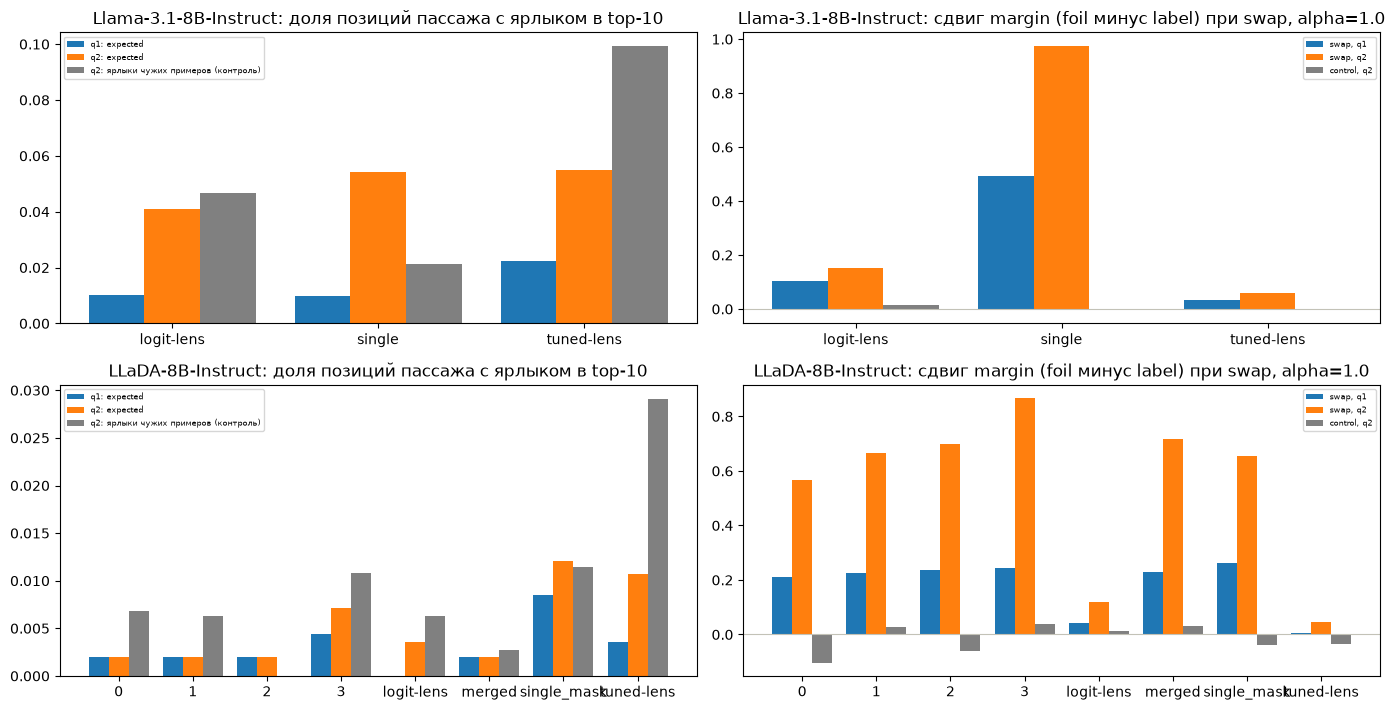

In [35]:
td_ro, td_ca = [], []
for entry in MODELS:
    _r, _c = run_top_down_summoning(entry, step=2)
    td_ro.append(_r); td_ca.append(_c)
td_ro, td_ca = pd.concat(td_ro, ignore_index=True), pd.concat(td_ca, ignore_index=True)
td_ro.to_csv("top_down_summoning_readout.csv", index=False)
td_ca.to_csv("top_down_summoning_causal.csv", index=False)
td_sum = summarize_top_down(td_ro, td_ca)
_keep = ["experiment", "model", "variant", "n_items", "q1_frac_k10", "q2_frac_k10", "q2_minus_q1_k10", "q2_minus_q1_foil_k10", "q2_other_k10"] + \
        [c for c in td_sum.columns if "_flip_" in c or "follows_foil" in c or c.startswith("base_answer")]
results.extend(td_sum[_keep].to_dict("records"))

display(td_sum[["model", "variant", "q1_frac_k10", "q2_frac_k10", "q2_minus_q1_k10", "q2_minus_q1_foil_k10", "q2_other_k10",
                "q2_minus_q1_k25", "q2_minus_q1_k5", "npos_q1", "npos_q2", "items_q2_gt_q1"]].round(3))
_pp = (td_ro.assign(hit=td_ro["r_exp"] <= 10).groupby(["model", "variant", "prop", "item", "question"])["hit"].sum()
       .groupby(["model", "variant", "prop", "question"]).mean().unstack("question").unstack("prop").round(2))
display(_pp)
print("По свойствам (k=10): доля позиций с ярлыком q1/q2 и причинный сдвиг margin swap vs control (q2, макс. alpha):")
td_prop = summarize_top_down_by_prop(td_ro, td_ca)
td_prop.to_csv("top_down_summoning_by_prop.csv", index=False)
display(td_prop.round(3))
_cols = [c for c in td_sum.columns if c.startswith(("swap_", "control_"))] + ["base_answer_is_label_q2", "base_answer_in_q1exp_q1"]
display(td_sum[["model", "variant"] + _cols].round(3).T if len(td_sum) < 3 else td_sum[["model", "variant"] + _cols].round(3))
print("Примеры ответов (swap, q2, максимальный alpha):")
display(td_ca[(td_ca["kind"] == "swap") & (td_ca["question"] == "q2") & (td_ca["alpha"] == td_ca["alpha"].max())]
        [["model", "variant", "item", "pair", "base_top1_text", "swap_top1_text", "flipped"]].head(24))

fig, axes = plt.subplots(len(MODELS), 2, figsize=(14, 3.6 * len(MODELS)), squeeze=False)
for mi, entry in enumerate(MODELS):
    _m = entry["name"]
    s = td_sum[td_sum["model"] == _m].reset_index(drop=True)
    x = np.arange(len(s))
    ax = axes[mi][0]
    for j, (col, lab, c) in enumerate([("q1_frac_k10", "q1: expected", "C0"), ("q2_frac_k10", "q2: expected", "C1"),
                                        ("q2_other_k10", "q2: ярлыки чужих примеров (контроль)", "gray")]):
        ax.bar(x + (j - 1) * 0.27, s[col], 0.27, label=lab, color=c)
    ax.set_xticks(x); ax.set_xticklabels(s["variant"]); ax.set_title(f"{_m}: доля позиций пассажа с ярлыком в top-10"); ax.legend(fontsize=6)
    ax = axes[mi][1]
    a_max = td_ca["alpha"].max()
    for j, (kind, q, c) in enumerate([("swap", "q1", "C0"), ("swap", "q2", "C1"), ("control", "q2", "gray")]):
        col = f"{kind}_dmargin_{q}_a{a_max}"
        if col in s:
            ax.bar(x + (j - 1) * 0.27, s[col], 0.27, label=f"{kind}, {q}", color=c)
    ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(s["variant"]); ax.set_title(f"{_m}: сдвиг margin (foil минус label) при swap, alpha={a_max}"); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

## Сводная таблица

Каждый эксперимент выше уже прогнан и отрисован в своей ячейке (и добавил свои строки в
`results` через `record_and_show`). Если ноутбук выполнялся сверху вниз целиком, здесь просто
собираем всё в одну таблицу и сохраняем на диск -- повторный прогон моделей не нужен.

Если нужно перезапустить *отдельный* эксперимент (например после правки `band` или `k`) --
просто заново выполните соответствующую пару ячеек выше; `record_and_show` допишет новые строки
в `results` (дубликаты по `experiment`+`model` не схлопываются автоматически, так что при
повторных запусках стоит либо перезапускать ноутбук с начала, либо чистить `results` вручную).

In [36]:
results_df = pd.DataFrame(results)
results_df.to_csv("./global_workspace_experiments_llada_vs_llama_new.csv", index=False)
results_df

,experiment,model,variant,swap_mode,n_items,n_strict,n_partial,strict_baseline_acc,strict_swap_success_rate,strict_swap_success_given_baseline_ok,...,control_flip_q2_a0.5,control_follows_foil_q2_a0.5,swap_flip_q1_a1.0,swap_flip_q2_a1.0,swap_follows_foil_q2_a1.0,control_flip_q1_a1.0,control_flip_q2_a1.0,control_follows_foil_q2_a1.0,base_answer_is_label_q2,base_answer_in_q1exp_q1
0,probe-swap,Llama-3.1-8B-Instruct,single@alpha=2.0,lens_clamp,90,68.0,22.0,0.558824,0.250000,0.368421,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,probe-swap,Llama-3.1-8B-Instruct,single@alpha=1.0,lens_clamp,90,68.0,22.0,0.558824,0.323529,0.447368,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,probe-swap,Llama-3.1-8B-Instruct,single@alpha=0.75,lens_clamp,90,68.0,22.0,0.558824,0.264706,0.394737,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,probe-swap,Llama-3.1-8B-Instruct,single@alpha=0.5,lens_clamp,90,68.0,22.0,0.558824,0.088235,0.078947,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,probe-swap,Llama-3.1-8B-Instruct,single@alpha=0.25,lens_clamp,90,68.0,22.0,0.558824,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
277,top-down-summoning,LLaDA-8B-Instruct,single_mask,NaN,28,NaN,NaN,NaN,NaN,NaN,...,0.071429,0.000000,0.196429,0.160714,0.000000,0.178571,0.035714,0.000000,0.464286,0.250000
278,top-down-summoning,LLaDA-8B-Instruct,tuned-lens,NaN,28,NaN,NaN,NaN,NaN,NaN,...,0.000000,0.000000,0.178571,0.053571,0.000000,0.142857,0.000000,0.000000,0.464286,0.250000
279,top-down-summoning,Llama-3.1-8B-Instruct,logit-lens,NaN,28,NaN,NaN,NaN,NaN,NaN,...,0.035714,0.142857,0.089286,0.107143,0.107143,0.178571,0.071429,0.107143,0.642857,0.214286
280,top-down-summoning,Llama-3.1-8B-Instruct,single,NaN,28,NaN,NaN,NaN,NaN,NaN,...,0.071429,0.107143,0.250000,0.125000,0.214286,0.214286,0.142857,0.142857,0.642857,0.214286


### Итоговая тепловая карта: LLaDA vs Llama по всем экспериментам

Общий обзор поверх разнородных метрик: по каждой (experiment, model) паре берём среднее
по всем её числовым метрикам (не совсем справедливое усреднение между экспериментами с разной
шкалой типа rate [0,1] и interference [-1,1], но полезно как быстрый ориентир -- какие
эксперименты вообще дали разницу между моделями).

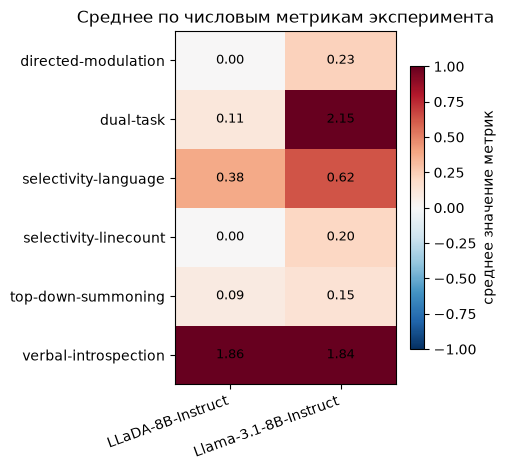

In [37]:
if "variant" in results_df.columns:
    headline_mask = results_df["variant"].isna() | (results_df["variant"] == "merged") | (results_df["variant"] == "single")
    headline_df = results_df[headline_mask]
else:
    headline_df = results_df

summary = (
    headline_df
    .drop(columns=["n_items", "variant"], errors="ignore")
    .set_index(["experiment", "model"])
    .select_dtypes("number")
    .mean(axis=1)
    .groupby(level=["experiment", "model"]).mean()
    .unstack("model")
)

fig, ax = plt.subplots(figsize=(5, 0.55 * len(summary) + 1.5))
im = ax.imshow(summary.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(summary.columns)))
ax.set_xticklabels(summary.columns, rotation=20, ha="right")
ax.set_yticks(range(len(summary.index)))
ax.set_yticklabels(summary.index)
for i in range(summary.shape[0]):
    for j in range(summary.shape[1]):
        v = summary.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Среднее по числовым метрикам эксперимента")
fig.colorbar(im, ax=ax, shrink=0.8, label="среднее значение метрик")
plt.tight_layout()
plt.show()

### Сравнение с baseline'ами

Среднее по метрикам-долям (все значения в [0, 1]) для каждой линзы: J-lens (`single` / `3` / `merged` / `single_mask`) против `logit-lens` и `tuned-lens`. Пустая клетка -- линза в этом эксперименте не считалась. Усреднение по разнородным метрикам грубое; разбивка по метрикам сохраняется в `baseline_comparison.csv`.

Среднее по метрикам-долям: J-lens против baseline'ов (больше -- лучше; детали по метрикам -- baseline_comparison.csv)


lens_group                                     J-lens:single  J-lens:3  \
experiment              model                                            
capacity                LLaDA-8B-Instruct                NaN     0.043   
                        Llama-3.1-8B-Instruct          0.184       NaN   
directed-modulation     LLaDA-8B-Instruct                NaN     0.024   
                        Llama-3.1-8B-Instruct          0.234       NaN   
dual-task               LLaDA-8B-Instruct                NaN     0.066   
                        Llama-3.1-8B-Instruct          0.263       NaN   
flexible-generalization LLaDA-8B-Instruct                NaN     0.391   
                        Llama-3.1-8B-Instruct          0.408       NaN   
ignition                LLaDA-8B-Instruct                NaN     0.472   
                        Llama-3.1-8B-Instruct          0.487       NaN   
probe-swap              LLaDA-8B-Instruct                NaN     0.391   
                        Llama-3.1-8B-Instruct          0.364       NaN   
selectivity-language    LLaDA-8B-Instruct                NaN     0.611   
                        Llama-3.1-8B-Instruct          0.625       NaN   
selectivity-linecount   LLaDA-8B-Instruct                NaN     0.000   
                        Llama-3.1-8B-Instruct          0.205       NaN   
top-down-summoning      LLaDA-8B-Instruct                NaN     0.092   
                        Llama-3.1-8B-Instruct          0.155       NaN   
verbal-introspection    LLaDA-8B-Instruct                NaN     0.556   
                        Llama-3.1-8B-Instruct          0.255       NaN   
verbal-report           LLaDA-8B-Instruct                NaN     0.568   
                        Llama-3.1-8B-Instruct          0.670       NaN   

lens_group                                     J-lens:merged  \
experiment              model                                  
capacity                LLaDA-8B-Instruct              0.025   
                        Llama-3.1-8B-Instruct            NaN   
directed-modulation     LLaDA-8B-Instruct              0.002   
                        Llama-3.1-8B-Instruct            NaN   
dual-task               LLaDA-8B-Instruct              0.016   
                        Llama-3.1-8B-Instruct            NaN   
flexible-generalization LLaDA-8B-Instruct              0.335   
                        Llama-3.1-8B-Instruct            NaN   
ignition                LLaDA-8B-Instruct              0.472   
                        Llama-3.1-8B-Instruct            NaN   
probe-swap              LLaDA-8B-Instruct              0.379   
                        Llama-3.1-8B-Instruct            NaN   
selectivity-language    LLaDA-8B-Instruct              0.382   
                        Llama-3.1-8B-Instruct            NaN   
selectivity-linecount   LLaDA-8B-Instruct              0.000   
                        Llama-3.1-8B-Instruct            NaN   
top-down-summoning      LLaDA-8B-Instruct              0.093   
                        Llama-3.1-8B-Instruct            NaN   
verbal-introspection    LLaDA-8B-Instruct              0.416   
                        Llama-3.1-8B-Instruct            NaN   
verbal-report           LLaDA-8B-Instruct              0.548   
                        Llama-3.1-8B-Instruct            NaN   

lens_group                                     J-lens:single_mask  logit-lens  \
experiment              model                                                   
capacity                LLaDA-8B-Instruct                   0.024       0.003   
                        Llama-3.1-8B-Instruct                 NaN       0.028   
directed-modulation     LLaDA-8B-Instruct                   0.008       0.000   
                        Llama-3.1-8B-Instruct                 NaN       0.190   
dual-task               LLaDA-8B-Instruct                   0.152       0.000   
                        Llama-3.1-8B-Instruct                 NaN       0.188   
flexible-generalization LLaDA-8B-Instr

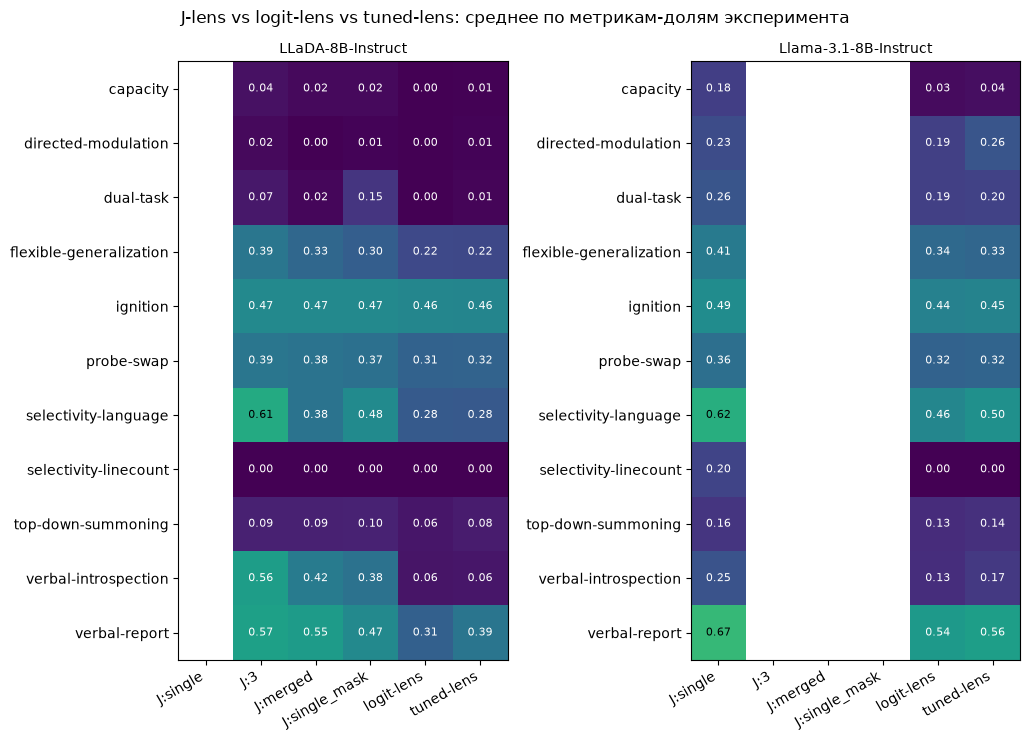

In [38]:
import re as _re
_LENS_RE = _re.compile(r"^(logit-lens|tuned-lens|single_mask|single|merged|[0-3])(?=$|[@/])")
_J_LENSES = ["single", "3", "merged", "single_mask"]
_rows = results_df.copy()
_rows["lens"] = _rows["variant"].astype(str).map(lambda v: (_LENS_RE.match(v).group(1) if _LENS_RE.match(v) else None))
_rows = _rows[_rows["lens"].notna()]
_num = [c for c in _rows.select_dtypes("number").columns if c != "n_items"]
_rate = [c for c in _num if _rows[c].dropna().between(0, 1).all() and _rows[c].notna().any()]
_long = _rows.melt(id_vars=["experiment", "model", "lens", "variant"], value_vars=_rate, var_name="metric", value_name="value").dropna(subset=["value"])
_long["lens_group"] = _long["lens"].map(lambda l: "J-lens:" + l if l in _J_LENSES else l)
_long.to_csv("baseline_comparison.csv", index=False)
_cmp = _long.groupby(["experiment", "model", "lens_group"])["value"].mean().unstack("lens_group")
_order = [c for c in ["J-lens:single", "J-lens:3", "J-lens:merged", "J-lens:single_mask", "logit-lens", "tuned-lens"] if c in _cmp.columns]
_cmp = _cmp[_order]
print("Среднее по метрикам-долям: J-lens против baseline'ов (больше -- лучше; детали по метрикам -- baseline_comparison.csv)")
display(_cmp.round(3))

_models = list(_cmp.index.get_level_values("model").unique())
fig, axes = plt.subplots(1, len(_models), figsize=(5.2 * len(_models), 0.5 * _cmp.index.get_level_values("experiment").nunique() + 2), squeeze=False)
for ax, _m in zip(axes[0], _models):
    _t = _cmp.xs(_m, level="model")
    im = ax.imshow(_t.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(_t.shape[1])); ax.set_xticklabels([c.replace("J-lens:", "J:") for c in _t.columns], rotation=30, ha="right")
    ax.set_yticks(range(_t.shape[0])); ax.set_yticklabels(_t.index); ax.set_title(_m, fontsize=10)
    for i in range(_t.shape[0]):
        for j in range(_t.shape[1]):
            v = _t.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="w" if v < 0.6 else "k")
fig.suptitle("J-lens vs logit-lens vs tuned-lens: среднее по метрикам-долям эксперимента")
plt.tight_layout(); plt.show()

## Оговорки к прочтению результатов

- **`probe-swap`, `verbal-report`, `flexible-generalization`, `top-down-summoning` (causal-часть)**
  используют J-lens направление токена (`token_direction`) вместо направления линейного пробинга,
  которое описано в оригинальном README для `probe-swap` -- это разные объекты (см. пример из
  статьи, где J-space объясняет лишь ~6-7% дисперсии направления концепта), так что цифры здесь
  не обязаны совпасть с оригинальными.
- **`ignition`** патчит выход embedding-слоя напрямую (нет доступа к предобученным per-token
  эмбеддингам где-либо ещё) -- для LLaDA это `model.transformer.wte`, для Llama --
  `model.model.embed_tokens`, оба через private-атрибуты `entry["hf"]`.
- **`workspace_band`** (`range(8, 28)`) -- заглушка, одинаковая для обеих моделей. Прежде чем
  доверять абсолютным числам (а не относительному сравнению LLaDA vs Llama), стоит подобрать band
  эмпирически для каждой модели отдельно (см. §5.2 методологии в статье: кривая top-k accuracy
  предсказания next-token по слоям).
- **`n_trials`/`limit`** параметры везде маленькие для скорости first-pass; для чисел, похожих на
  статью, их нужно поднять (`n_trials` от статьи: probe-swap 90, ignition 66 пар x carriers,
  и т.д. -- см. README каждого experiment.json).